## 1. Problem Framing

Project ini membangun dua komponen dari dataset *International Football Results* (martj42): model klasifikasi hasil laga H/D/A dengan output probabilitas, dan simulasi Monte Carlo yang memakai probabilitas tersebut untuk memperkirakan peluang juara tiap tim pada turnamen ASEAN. Label adalah hasil akhir setelah waktu tambahan tanpa penalti, karena hasil 90 menit tidak tersedia di data (keterbatasan pasti yang harus dilaporkan). Seluruh fitur hanya boleh memakai informasi sebelum tanggal laga (anti-leakage); data latih memakai seluruh laga internasional (Pilihan A), sedangkan evaluasi dan backtest difokuskan pada laga ASEAN. Metrik utama log loss, dilengkapi Brier score, RPS, dan kalibrasi, diukur terhadap tiga baseline: prior kelas, Elo murni, dan Logistic Regression.

## 2. Data Understanding

### 2.1 Kualitas Data Umum

#### Cek 1 — Dimensi, dtypes, dan parsing date

In [1]:
import pandas as pd
from pathlib import Path

DATA = Path("data")
if not (DATA / "results.csv").exists():
    DATA = Path("..") / "data"

results = pd.read_csv(DATA / "results.csv")
former = pd.read_csv(DATA / "former_names.csv")

print("Dimensi results.csv:", results.shape)
print("\nDtypes:")
print(results.dtypes)
dates = pd.to_datetime(results["date"], errors="coerce")
print("\nJumlah baris gagal parse date (errors='coerce'):", int(dates.isna().sum()))

Dimensi results.csv: (49945, 9)

Dtypes:
date          object
home_team     object
away_team     object
home_score     int64
away_score     int64
tournament    object
city          object
country       object
neutral         bool
dtype: object

Jumlah baris gagal parse date (errors='coerce'): 0


**Kesimpulan:** `results.csv` berisi **49.945 baris** dan **9 kolom**. Kolom `date`, `home_team`, `away_team`, `tournament`, `city`, dan `country` terbaca sebagai `object` (teks), `home_score` dan `away_score` sebagai `int64`, serta `neutral` sebagai `bool`. Parsing kolom `date` dengan `errors='coerce'` tidak menghasilkan nilai NaT: **0 baris gagal parse** dari 49.945 baris.

#### Cek 2 — Baris dengan home_score/away_score kosong

In [2]:
mask = results["home_score"].isna() | results["away_score"].isna()
sub = results[mask]
print("Jumlah baris dengan home_score/away_score kosong:", int(mask.sum()))
if len(sub):
    print("Rentang tanggal:", sub["date"].min(), "->", sub["date"].max())
    print("\nJumlah per turnamen:")
    print(sub["tournament"].value_counts().to_string())
else:
    print("Tidak ada baris dengan skor kosong -> tidak ada rentang tanggal / turnamen untuk ditampilkan.")

Jumlah baris dengan home_score/away_score kosong: 0
Tidak ada baris dengan skor kosong -> tidak ada rentang tanggal / turnamen untuk ditampilkan.


**Kesimpulan:** Jumlah baris dengan `home_score` atau `away_score` kosong adalah **0**. Karena jumlahnya nol, tidak ada rentang tanggal maupun daftar turnamen yang dapat ditampilkan untuk kasus ini. Seluruh 49.945 baris memiliki nilai skor terbaca pada pembacaan ini.

#### Cek 3 — Duplikat berdasarkan (date, home_team, away_team)

In [3]:
key = ["date", "home_team", "away_team"]
n_dup = int(results.duplicated(subset=key).sum())
dup_mask = results.duplicated(subset=key, keep=False)
print("Jumlah duplikat (baris setelah kemunculan pertama):", n_dup)
print("Jumlah baris yang terlibat duplikat:", int(dup_mask.sum()))
if dup_mask.any():
    cols = key + ["home_score", "away_score", "tournament", "city"]
    print(results.loc[dup_mask, cols].sort_values(key).to_string(index=False))

Jumlah duplikat (baris setelah kemunculan pertama): 1
Jumlah baris yang terlibat duplikat: 2
      date home_team     away_team  home_score  away_score tournament    city
1974-02-17    Tahiti New Caledonia           2           1   Friendly Papeete
1974-02-17    Tahiti New Caledonia           1           2   Friendly Papeete


**Kesimpulan:** Berdasarkan kunci `(date, home_team, away_team)` ditemukan **1 duplikat** (2 baris terlibat): Tahiti vs New Caledonia pada 1974-02-17 di Papeete (Friendly) tercatat dua kali dengan skor berbeda, yaitu 2–1 dan 1–2. Baris lain tidak menunjukkan duplikat pada kunci tersebut. Penanganan duplikat menjadi lingkup section 3; di sini hanya dicatat sebagai temuan.

#### Cek 4 — Skor negatif/ekstrem dan nilai unik neutral

In [4]:
neg = int(((results["home_score"] < 0) | (results["away_score"] < 0)).sum())
print("Jumlah baris dengan skor negatif:", neg)
print("home_score: min =", results["home_score"].min(), "| max =", results["home_score"].max())
print("away_score: min =", results["away_score"].min(), "| max =", results["away_score"].max())

total = results["home_score"] + results["away_score"]
top10 = results.assign(total_skor=total).nlargest(10, "total_skor")
print("\n10 laga dengan total skor terbesar:")
print(top10[["date", "home_team", "away_team", "home_score", "away_score", "total_skor", "tournament"]].to_string(index=False))

print("\nNilai unik kolom neutral:", sorted(results["neutral"].unique().tolist()))
print(results["neutral"].value_counts().to_string())

Jumlah baris dengan skor negatif: 0
home_score: min = 0 | max = 31
away_score: min = 0 | max = 21

10 laga dengan total skor terbesar:
      date  home_team      away_team  home_score  away_score  total_skor                                               tournament
2001-04-11  Australia American Samoa          31           0          31                             FIFA World Cup qualification
1971-09-13     Tahiti   Cook Islands          30           0          30                                      South Pacific Games
1979-08-30       Fiji       Kiribati          24           0          24                                      South Pacific Games
2001-04-09  Australia          Tonga          22           0          22                             FIFA World Cup qualification
2006-11-24      Sápmi         Monaco          21           1          22                                           Viva World Cup
2013-06-24   Provence          Tibet          22           0          22 Internationa


Nilai unik kolom neutral: [False, True]
neutral
False    36669
True     13276


**Kesimpulan:** Tidak ada skor negatif (**0 baris**). Rentang `home_score` adalah **0–31** dan rentang `away_score` adalah **0–21**. Total skor terbesar adalah **31** pada laga Australia vs American Samoa (2001-04-11), disusul **30** pada Tahiti vs Cook Islands (1971-09-13). Kolom `neutral` hanya berisi dua nilai: **False = 36.669 baris** dan **True = 13.276 baris**.

#### Cek 5 — Baris bertanggal lebih besar dari 2026-10-23

In [5]:
cutoff = pd.Timestamp("2026-10-23")
n_future = int((dates > cutoff).sum())
print("Jumlah baris dengan date > 2026-10-23:", n_future)
print("Tanggal minimum dalam data:", dates.min().date())
print("Tanggal maksimum dalam data:", dates.max().date())

Jumlah baris dengan date > 2026-10-23: 0
Tanggal minimum dalam data: 1872-11-30
Tanggal maksimum dalam data: 2026-10-06


**Kesimpulan:** Jumlah baris bertanggal lebih besar dari 2026-10-23 adalah **0**. Rentang tanggal data adalah 1872-11-30 sampai **2026-10-06**, sehingga pada pembacaan ini tidak ada catatan dengan tanggal setelah 2026-10-23.

#### Cek 6 — Nama lama (kolom former) masih muncul di results.csv

In [6]:
former_set = set(former["former"].dropna().unique())
teams = set(results["home_team"].dropna().unique()) | set(results["away_team"].dropna().unique())
found = sorted(former_set & teams)
print("Jumlah nama 'former' unik:", len(former_set))
print("Jumlah nama lama yang muncul di results.csv:", len(found))
print("Daftar yang ditemukan:", found)

Jumlah nama 'former' unik:

 36
Jumlah nama lama yang muncul di results.csv: 0
Daftar yang ditemukan: []


**Kesimpulan:** `former_names.csv` memuat **36 nama lama unik** (kolom `former`), dan **0** di antaranya muncul sebagai `home_team`/`away_team` di `results.csv`. Untuk daftar nama ini, tidak ada nama lama yang perlu diganti ketika menggabungkan data pada tahap persiapan.

#### Cek 7 — Distribusi H/D/A (keseluruhan, per dekade, neutral)

In [7]:
full = results.dropna(subset=["home_score", "away_score"]).copy()
full["outcome"] = "D"
full.loc[full["home_score"] > full["away_score"], "outcome"] = "H"
full.loc[full["home_score"] < full["away_score"], "outcome"] = "A"

print("Jumlah baris skor lengkap:", len(full))
counts = full["outcome"].value_counts().reindex(["H", "D", "A"])
print("\nDistribusi keseluruhan:")
for k in ["H", "D", "A"]:
    print(f"  {k}: {counts[k]} ({counts[k] / len(full):.4f})")

decade = (pd.to_datetime(full["date"]).dt.year // 10) * 10
tbl = full.groupby(decade)["outcome"].value_counts().unstack(fill_value=0)
tbl = tbl.reindex(columns=["H", "D", "A"], fill_value=0)
tbl["n"] = tbl.sum(axis=1)
tbl["prop_H"] = (tbl["H"] / tbl["n"]).round(4)
print("\nDistribusi per dekade (counts + proporsi H):")
print(tbl.to_string())

print("\nProporsi home win pada neutral=False vs neutral=True:")
for flag in [False, True]:
    m = full["neutral"] == flag
    prop_h = (full.loc[m, "outcome"] == "H").mean()
    print(f"  neutral={flag}: n={int(m.sum())}, proporsi H={prop_h:.4f}")

Jumlah baris skor lengkap: 49945



Distribusi keseluruhan:
  H: 24473 (0.4900)
  D: 11341 (0.2271)
  A: 14131 (0.2829)



Distribusi per dekade (counts + proporsi H):
outcome     H     D     A     n  prop_H
date                                   
1870        8     2     3    13  0.6154
1880       27     5    23    55  0.4909
1890       30     9    20    59  0.5085
1900       62    24    52   138  0.4493
1910      180    53    97   330  0.5455
1920      441   149   241   831  0.5307
1930      566   172   341  1079  0.5246
1940      444   128   261   833  0.5330
1950      812   304   541  1657  0.4900
1960     1555   583   833  2971  0.5234
1970     2070   902  1160  4132  0.5010
1980     2371  1313  1342  5026  0.4717
1990     3449  1686  1807  6942  0.4968
2000     4647  2234  2659  9540  0.4871
2010     4696  2278  2826  9800  0.4792
2020     3115  1499  1925  6539  0.4764

Proporsi home win pada neutral=False vs neutral=True:
  neutral=False: n=36669, proporsi H=0.5073
  neutral=True: n=13276, proporsi H=0.4422


**Kesimpulan:** Pada **49.945 baris skor lengkap** (seluruh baris), distribusi hasil adalah **H = 24.473 (0,49)**, **A = 14.131 (0,2829)**, dan **D = 11.341 (0,2271)**. Proporsi home win per dekade tertinggi adalah **0,6154** pada 1870-an (13 laga) dan terendah **0,4493** pada 1900-an (138 laga). Proporsi home win pada laga non-neutral (`neutral=False`) adalah **0,5073** (n = 36.669), sedangkan pada laga netral (`neutral=True`) adalah **0,4422** (n = 13.276).

#### Cek 8 — Jumlah laga per tahun dan tim unik per dekade

In [8]:
years = pd.to_datetime(results["date"]).dt.year
per_year = results.groupby(years).size()
print("Rentang tahun:", int(per_year.index.min()), "-", int(per_year.index.max()))
print("Jumlah tahun:", len(per_year))
print("Laga per tahun — terendah:", int(per_year.min()), "(", int(per_year.idxmin()), ") | tertinggi:", int(per_year.max()), "(", int(per_year.idxmax()), ")")
print("5 tahun terbanyak:", per_year.nlargest(5).to_dict())
print("\nSeluruh jumlah laga per tahun:")
print(per_year.to_string())

decade_all = (years // 10) * 10
tim_per_decade = {}
for d, grp in results.groupby(decade_all):
    tim_per_decade[int(d)] = len(set(grp["home_team"]) | set(grp["away_team"]))
print("\nJumlah tim unik per dekade:")
for d, n in tim_per_decade.items():
    print(f"  {d}-an: {n}")
print("Total tim unik (seluruh data):", len(set(results["home_team"]) | set(results["away_team"])))

Rentang tahun: 1872 - 2026
Jumlah tahun: 155


Laga per tahun — terendah: 1 ( 1872 ) | tertinggi: 1231 ( 2024 )
5 tahun terbanyak: {2024: 1231, 2019: 1156, 2011: 1119, 2021: 1115, 2008: 1101}

Seluruh jumlah laga per tahun:
date
1872       1
1873       1
1874       1
1875       1
1876       2
1877       2
1878       2
1879       3
1880       3
1881       3
1882       5
1883       5
1884       6
1885       7
1886       7
1887       6
1888       7
1889       6
1890       6
1891       6
1892       6
1893       5
1894       6
1895       6
1896       6
1897       6
1898       6
1899       6
1900       6
1901       6
1902       8
1903      10
1904       9
1905      15
1906      17
1907      15
1908      30
1909      22
1910      30
1911      35
1912      53
1913      38
1914      33
1915      18
1916      29
1917      27
1918      17
1919      50
1920      54
1921      60
1922      73
1923      94
1924     110
1925      87
1926      88
1927      82
1928      99
1929      84
1930     115
1931     100
1932      93
1933      95
1934     111

Total tim unik (seluruh data): 337


**Kesimpulan:** Data mencakup **155 tahun** (1872–2026). Jumlah laga per tahun terendah adalah **1** (1872) dan tertinggi **1.231** (2024); lima tahun dengan laga terbanyak adalah 2024, 2019, 2011, 2021, dan 2008. Jumlah tim unik per dekade naik dari **3** tim pada 1870-an menjadi **303** tim pada 2010-an, lalu **266** tim pada 2020-an; total seluruh data terdapat **337 tim unik**. Catatan: jumlah tim unik pada dekade 2020 (266) lebih rendah dibanding dekade 2010 (303) karena dekade 2020 belum lengkap (data berakhir 2026-10-06), bukan karena penurunan nyata jumlah tim.

### 2.2 Tindak Lanjut Kualitas Data

#### 2.2.1 — Duplikat Tahiti vs New Caledonia (1974-02-17)

In [9]:
shootouts = pd.read_csv(DATA / "shootouts.csv")

key = ["date", "home_team", "away_team"]
mask_dup = ((results["date"] == "1974-02-17") &
            (results["home_team"] == "Tahiti") &
            (results["away_team"] == "New Caledonia"))

print("Dua baris duplikat dengan SEMUA kolom:")
print(results.loc[mask_dup].to_string(index=False))

same_key = results[results.duplicated(subset=key, keep=False)]
print("\nJumlah baris dengan (date, home_team, away_team) sama:", len(same_key))
print("Baris lain selain dua baris di atas:", len(same_key) - int(mask_dup.sum()))

pair_shoot = shootouts[(shootouts["date"] == "1974-02-17") &
                       (((shootouts["home_team"] == "Tahiti") & (shootouts["away_team"] == "New Caledonia")) |
                        ((shootouts["home_team"] == "New Caledonia") & (shootouts["away_team"] == "Tahiti")))]
print("\nPasangan Tahiti vs New Caledonia (1974-02-17) di shootouts.csv:", len(pair_shoot))
print("Semua baris shootouts.csv bertanggal 1974-02-17:")
print(shootouts[shootouts["date"] == "1974-02-17"].to_string(index=False))

Dua baris duplikat dengan SEMUA kolom:
      date home_team     away_team  home_score  away_score tournament    city country  neutral
1974-02-17    Tahiti New Caledonia           2           1   Friendly Papeete  Tahiti    False
1974-02-17    Tahiti New Caledonia           1           2   Friendly Papeete  Tahiti    False

Jumlah baris dengan (date, home_team, away_team) sama: 2
Baris lain selain dua baris di atas: 0

Pasangan Tahiti vs New Caledonia (1974-02-17) di shootouts.csv: 0
Semua baris shootouts.csv bertanggal 1974-02-17:
Empty DataFrame
Columns: [date, home_team, away_team, winner, first_shooter]
Index: []


**Kesimpulan:** Kedua baris identik pada semua kolom — 1974-02-17, Tahiti vs New Caledonia, Friendly, Papeete, Tahiti, `neutral=False` — dan hanya berbeda pada skor: **2–1** dan **1–2**. Tidak ada baris lain dengan kunci `(date, home_team, away_team)` yang sama (**0** baris tambahan), dan pasangan ini tidak tercatat di `shootouts.csv` (**0** baris; `shootouts.csv` juga tidak memiliki baris apa pun pada 1974-02-17). Karena tidak ada kolom yang memisahkan kedua catatan (kota, turnamen, dan status netral sama persis) dan tidak ada catatan adu penalti, status apakah ini dua laga berbeda atau kesalahan input **belum pasti** — bukti dari kolom yang ada belum cukup untuk memutuskan.

#### 2.2.2 — Nama tim di shootouts.csv vs results.csv dan former_names.csv

In [10]:
res_teams = set(results["home_team"].dropna()) | set(results["away_team"].dropna())
sh_home = set(shootouts["home_team"].dropna())
sh_away = set(shootouts["away_team"].dropna())
sh_winner = set(shootouts["winner"].dropna())
sh_all = sh_home | sh_away | sh_winner
former_set = set(former["former"].dropna())

print("shootouts.csv — home unik:", len(sh_home),
      "| away unik:", len(sh_away),
      "| winner unik:", len(sh_winner),
      "| gabungan:", len(sh_all))
for col, s in [("home_team", sh_home), ("away_team", sh_away), ("winner", sh_winner)]:
    missing = sorted(s - res_teams)
    print(f"Nama '{col}' di shootouts TIDAK ada di results.csv: {len(missing)} {missing}")

print("\nNama shootouts yang berasal dari kolom 'former':", sorted(sh_all & former_set))
print("Baris shootouts yang memakai nama 'former':",
      int(shootouts["home_team"].isin(former_set).sum() +
          shootouts["away_team"].isin(former_set).sum() +
          shootouts["winner"].isin(former_set).sum()))

home_former = sorted(set(results["home_team"].dropna()) & former_set)
away_former = sorted(set(results["away_team"].dropna()) & former_set)
print("\nresults.csv — home_team dari 'former':", home_former,
      "| baris:", int(results["home_team"].isin(former_set).sum()))
print("results.csv — away_team dari 'former':", away_former,
      "| baris:", int(results["away_team"].isin(former_set).sum()))

shootouts.csv — home unik: 189 | away unik: 200 | winner unik: 185 | gabungan: 231
Nama 'home_team' di shootouts TIDAK ada di results.csv: 0 []
Nama 'away_team' di shootouts TIDAK ada di results.csv: 0 []
Nama 'winner' di shootouts TIDAK ada di results.csv: 0 []

Nama shootouts yang berasal dari kolom 'former': []
Baris shootouts yang memakai nama 'former': 0



results.csv — home_team dari 'former': [] | baris: 0
results.csv — away_team dari 'former': [] | baris: 0


**Kesimpulan:** `shootouts.csv` memuat **189** nama `home_team`, **200** `away_team`, dan **185** `winner` unik (**231** nama gabungan), dan tidak ada satu pun yang absen dari `results.csv` (**0** nama untuk masing-masing ketiga kolom). Tidak ada nama `shootouts.csv` yang berasal dari kolom `former` (**0** dari 36 nama lama; **0** baris terdampak). Pada `results.csv`, pemeriksaan terpisah untuk `home_team` maupun `away_team` juga tidak menemukan nama dari `former` (**0** nama dan **0** baris untuk keduanya).

#### 2.2.3 — Distribusi H/D/A terpisah pada neutral=True dan neutral=False

In [11]:
full = results.dropna(subset=["home_score", "away_score"]).copy()
full["outcome"] = "D"
full.loc[full["home_score"] > full["away_score"], "outcome"] = "H"
full.loc[full["home_score"] < full["away_score"], "outcome"] = "A"

counts = pd.crosstab(full["neutral"], full["outcome"]).reindex(columns=["H", "D", "A"], fill_value=0)
props = counts.div(counts.sum(axis=1), axis=0).round(4)
tabel = pd.concat([counts.add_prefix("jumlah_"), props.add_prefix("proporsi_")], axis=1)
print("Distribusi H/D/A per neutral (satu tabel):")
print(tabel.to_string())

Distribusi H/D/A per neutral (satu tabel):
outcome  jumlah_H  jumlah_D  jumlah_A  proporsi_H  proporsi_D  proporsi_A
neutral                                                                  
False       18603      8369      9697      0.5073      0.2282      0.2644
True         5870      2972      4434      0.4422      0.2239      0.3340


**Kesimpulan:** Pada laga non-neutral (`neutral=False`, n = **36.669**): H = **18.603 (0,5073)**, D = **8.369 (0,2282)**, A = **9.697 (0,2644)**. Pada laga netral (`neutral=True`, n = **13.276**): H = **5.870 (0,4422)**, D = **2.972 (0,2239)**, A = **4.434 (0,3340)**. Proporsi menang tuan rumah lebih tinggi pada laga non-neutral (0,5073 vs 0,4422), proporsi menang tamu lebih tinggi pada laga netral (0,3340 vs 0,2644), sedangkan proporsi seri hampir serupa (0,2282 vs 0,2239).

### 2.3 Data Dictionary & Ringkasan Tahap 2

**Data dictionary — `results.csv`** (49.945 baris; tipe data hasil inspeksi `pd.read_csv`, bagian 2.1)

| Kolom | Tipe data (inspeksi) | Arti kolom | Contoh nilai nyata |
|---|---|---|---|
| `date` | `object` (string ISO; 0 baris gagal parse saat diparse menjadi tanggal) | Tanggal laga | `1872-11-30` |
| `home_team` | `object` | Tim yang tercatat sebagai tuan rumah pada data; pada laga netral label "home" tidak serta-merta tuan rumah geografis (lihat keputusan tindak lanjut) | `Scotland` |
| `away_team` | `object` | Tim yang tercatat sebagai tandang | `England` |
| `home_score` | `int64` | Skor tuan rumah — hasil akhir setelah waktu tambahan, tanpa penalti (definisi label sesuai problem framing) | `0` |
| `away_score` | `int64` | Skor tamu — hasil akhir setelah waktu tambahan, tanpa penalti | `0` |
| `tournament` | `object` | Nama turnamen/kompetisi | `Friendly` (juga `AFF Championship`) |
| `city` | `object` | Kota penyelenggara laga | `Glasgow` |
| `country` | `object` | Negara/kawasan penyelenggara laga; pada `neutral=True` berbeda dari `home_team` pada 13.274 dari 13.276 baris | `Scotland` |
| `neutral` | `bool` (`TRUE`/`FALSE` di CSV) | Penanda laga di venue netral. Bukti inspeksi: `neutral=True` → `country` ≠ `home_team` pada 13.274/13.276 baris; `neutral=False` → `country` = `home_team` pada 35.681/36.669 baris. Arti kasus pengecualian `[perlu diverifikasi]` | `FALSE` (juga `TRUE`) |

**Data dictionary — `shootouts.csv`** (700 baris; seluruh kolom `object`)

| Kolom | Tipe data (inspeksi) | Arti kolom | Contoh nilai nyata |
|---|---|---|---|
| `date` | `object` (string ISO) | Tanggal laga yang diakhiri adu penalti; 699/700 baris cocok dengan kunci `(date, home_team, away_team)` di `results.csv`, 1 baris tidak cocok `[perlu diverifikasi]` | `1967-08-22` |
| `home_team` | `object` | Tim tuan rumah pada laga beradu penalti | `India` |
| `away_team` | `object` | Tim tandang pada laga beradu penalti | `Taiwan` |
| `winner` | `object` | Tim pemenang adu penalti; seluruh nama terdapat di `results.csv` (0 absen, cek 2.2.2) | `Taiwan` |
| `first_shooter` | `object` | Tim yang menendang penalti pertama (bentuk nilai berupa nama tim: 98 nama, 0 absen dari `results.csv`); terisi pada 269/700 baris. Aturan urutan menendang `[perlu diverifikasi]` | `Czechoslovakia` (sering kosong) |

**Data dictionary — `former_names.csv`** (36 baris; seluruh kolom `object`)

| Kolom | Tipe data (inspeksi) | Arti kolom | Contoh nilai nyata |
|---|---|---|---|
| `current` | `object` | Nama tim yang berlaku sekarang | `Benin` |
| `former` | `object` | Nama lama untuk tim pada kolom `current` | `Dahomey` |
| `start_date` | `object` (string ISO) | Awal rentang pemakaian nama lama `[perlu diverifikasi]` | `1959-11-08` |
| `end_date` | `object` (string ISO) | Akhir rentang pemakaian nama lama `[perlu diverifikasi]` | `1975-11-30` |

**Temuan Kualitas Data (ringkasan 2.1 & 2.2)**

- `results.csv`: 49.945 × 9; gagal parse `date` **0**; baris dengan skor kosong **0** (pengecekan Tahap 2 tidak menemukan jadwal belum dimainkan); tanggal > 2026-10-23 **0** (rentang data 1872-11-30 – 2026-10-06).
- Duplikat **1 pasang** (2 baris): Tahiti vs New Caledonia 1974-02-17 — status dua laga berbeda atau salah input **belum pasti** (2.2.1).
- Skor negatif **0**; rentang skor `home_score` 0–31 dan `away_score` 0–21; `neutral` hanya `False` **36.669** / `True` **13.276**.
- Nama `former` terpakai: **0** pada `results.csv` (home dan away) dan **0** pada `shootouts.csv` (dari 36 nama lama); nama `shootouts.csv` yang absen dari `results.csv` **0**.
- Distribusi H/D/A keseluruhan: H **24.473 (0,49)**, D **11.341 (0,2271)**, A **14.131 (0,2829)**; proporsi H `neutral=False` **0,5073** vs `neutral=True` **0,4422** (tabel lengkap di 2.2.3).
- Cakupan: **155 tahun** (1872–2026), **337** tim unik; tim unik dekade 2020 lebih rendah karena dekade belum lengkap (catatan Cek 8).

**Keputusan tindak lanjut:**

- Duplikat Tahiti vs New Caledonia **dipertahankan di data raw** (tidak ada baris yang dihapus); identitas laga ditangani lewat kolom **`match_id`** yang dibuat pada **Tahap 3 (section 3. Data Preparation & Merge)**.
- Label **"home" pada laga netral tidak dianggap acak** dan **diuji di EDA (section 4. Exploratory Data Analysis)**.

**Pertanyaan yang Diteruskan ke Tahap 3**

1. Hubungan tiga nama turnamen `AFF Championship`, `ASEAN Championship`, dan `FIFA ASEAN Cup` — nama berbeda, era berbeda, atau kompetisi terpisah `[perlu diverifikasi]`.
2. Isi 14 laga `FIFA ASEAN Cup` (2026-09-25 – 2026-10-05): format, peserta, dan status laga `[perlu diverifikasi]`.
3. Rekonstruksi edisi dari jeda tanggal (kolom "edisi" tidak ada di data; rentang `ASEAN Championship` 2024-12-08 – 2026-08-26 menandakan kemungkinan lebih dari satu edisi) `[perlu diverifikasi]`.
4. Status laga terakhir — data berakhir 2026-10-06: sudah final/resmi atau perlu pembaruan `[perlu diverifikasi]`.

## 3. Data Preparation & Merge

### 3.1 Urutan, ID, dan Label

In [12]:
results_raw = pd.read_csv(DATA / "results.csv")
orig_row = results_raw.index  # urutan baris asli di CSV (0..N-1)

matches = results_raw.copy()
matches["orig_row"] = orig_row
matches["date"] = pd.to_datetime(matches["date"])
matches = matches.sort_values("date", kind="stable").reset_index(drop=True)

print("Jumlah baris:", len(matches))
print("dtype date:", matches["date"].dtype)
print("\n5 baris pertama setelah sort:")
print(matches.head(5).to_string(index=False))
print("\nBaris bertanggal 1974-02-17 (urutan stabil, orig_row dipertahankan):")
same = matches[matches["date"] == "1974-02-17"][["orig_row", "date", "home_team", "away_team", "home_score", "away_score"]]
print(same.to_string(index=False))

Jumlah baris: 49945
dtype date: datetime64[ns]

5 baris pertama setelah sort:
      date home_team away_team  home_score  away_score tournament    city  country  neutral  orig_row
1872-11-30  Scotland   England           0           0   Friendly Glasgow Scotland    False         0
1873-03-08   England  Scotland           4           2   Friendly  London  England    False         1
1874-03-07  Scotland   England           2           1   Friendly Glasgow Scotland    False         2
1875-03-06   England  Scotland           2           2   Friendly  London  England    False         3
1876-03-04  Scotland   England           3           0   Friendly Glasgow Scotland    False         4

Baris bertanggal 1974-02-17 (urutan stabil, orig_row dipertahankan):
 orig_row       date home_team     away_team  home_score  away_score
     9648 1974-02-17     Congo          Mali           2           2
     9649 1974-02-17     Ghana        Guinea           3           1
     9650 1974-02-17    Tahiti Ne

**Kesimpulan:** `results.csv` dibaca ulang (49.945 baris) dan kolom `date` diubah ke tipe datetime. Sort **stabil** (`kind='stable'`) berdasarkan `date` mempertahankan urutan baris asli untuk tanggal yang sama, dan urutan asli CSV disimpan pada kolom `orig_row`. Pada tanggal 1974-02-17 terdapat 4 baris yang tetap muncul dengan urutan `orig_row` 9648 → 9649 → 9650 → 9651, termasuk dua baris Tahiti vs New Caledonia (9650 dan 9651) sesuai urutan aslinya.

In [13]:
matches["match_id"] = range(len(matches))

assert matches["match_id"].is_unique, "match_id tidak unik"
assert len(matches) == 49945, f"N = {len(matches)} != 49945"
assert matches["date"].is_monotonic_increasing, "date tidak monoton naik"

print("match_id unik:", bool(matches["match_id"].is_unique))
print("N =", len(matches), "(= 49.945)")
print("date monoton naik (non-decreasing):", bool(matches["date"].is_monotonic_increasing))
print("match_id rentang:", int(matches["match_id"].min()), "s/d", int(matches["match_id"].max()))

match_id unik: True
N = 49945 (= 49.945)
date monoton naik (non-decreasing): True
match_id rentang: 0 s/d 49944


**Kesimpulan:** Ketiga assert lolos tanpa galat: `match_id` unik, **N = 49.945**, dan `date` monoton naik (non-decreasing; tanggal kembar diperbolehkan). `match_id` diberikan 0–49.944 sesuai urutan baris setelah sort stabil, sehingga ID menjadi acuan tetap untuk baris di `matches_base.csv`.

In [14]:
matches["result"] = "D"
matches.loc[matches["home_score"] > matches["away_score"], "result"] = "H"
matches.loc[matches["home_score"] < matches["away_score"], "result"] = "A"

expected_21 = {"H": 24473, "D": 11341, "A": 14131}
counts = {k: int((matches["result"] == k).sum()) for k in ["H", "D", "A"]}
print("Jumlah per kelas:", counts)
assert counts == expected_21, f"Selisih dengan 2.1: {counts} != {expected_21}"
print("Sesuai hasil 2.1:", counts == expected_21)
print("Proporsi:", {k: round(v / len(matches), 4) for k, v in counts.items()})

Jumlah per kelas: {'H': 24473, 'D': 11341, 'A': 14131}
Sesuai hasil 2.1: True
Proporsi: {'H': 0.49, 'D': 0.2271, 'A': 0.2829}


**Kesimpulan:** Kolom `result` (H/D/A) dibuat dari pembandingan `home_score` vs `away_score` dengan aturan seri = D. Assert memastikan jumlah kelas **identik dengan hasil 2.1**: H = **24.473**, D = **11.341**, A = **14.131** (total 49.945) — tidak ada baris yang terlewat dan tidak ada label yang berubah.

In [15]:
tahiti = matches[(matches["date"] == "1974-02-17") &
                 (matches["home_team"] == "Tahiti") &
                 (matches["away_team"] == "New Caledonia")]
cols4 = ["match_id", "orig_row", "date", "home_team", "away_team", "home_score",
         "away_score", "result", "tournament", "city", "country", "neutral"]
print(tahiti[cols4].to_string(index=False))

assert len(tahiti) == 2, f"jumlah baris Tahiti = {len(tahiti)}"
assert tahiti["match_id"].nunique() == 2, "match_id Tahiti tidak berbeda"
print("\nJumlah baris:", len(tahiti), "| match_id keduanya:", tahiti["match_id"].tolist(), "(berbeda)")

 match_id  orig_row       date home_team     away_team  home_score  away_score result tournament    city country  neutral
     9650      9650 1974-02-17    Tahiti New Caledonia           2           1      H   Friendly Papeete  Tahiti    False
     9651      9651 1974-02-17    Tahiti New Caledonia           1           2      A   Friendly Papeete  Tahiti    False

Jumlah baris: 2 | match_id keduanya: [9650, 9651] (berbeda)


**Kesimpulan:** Dua baris Tahiti vs New Caledonia (1974-02-17) **tetap ada** setelah sort dan pembuatan label, dengan **`match_id` berbeda: 9650 dan 9651** (skor 2–1 dengan result H, dan 1–2 dengan result A). Sesuai keputusan 2.3, kedua baris dipertahankan di data — deduplikasi tidak dilakukan di tahap ini, hanya identitas laga yang dibedakan lewat `match_id`.

In [16]:
import subprocess

OUT_DIR = DATA / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)
out_path = OUT_DIR / "matches_base.csv"
matches.to_csv(out_path, index=False, encoding="utf-8")

size_b = out_path.stat().st_size
print("Tersimpan:", out_path)
print("Baris x kolom:", matches.shape[0], "x", matches.shape[1])
print("Ukuran:", size_b, "bytes =", round(size_b / 1024, 1), "KB =", round(size_b / 1024 / 1024, 2), "MB")

gi_path = DATA.parent / ".gitignore"
gi_lines = [ln.strip() for ln in gi_path.read_text(encoding="utf-8").splitlines()] if gi_path.exists() else []
gi_lines = [ln for ln in gi_lines if ln and not ln.startswith("#")]
print("Pola .gitignore aktif:", gi_lines if gi_lines else "(tidak ada — .gitignore kosong)")
try:
    r = subprocess.run(["git", "check-ignore", "data/processed/matches_base.csv"],
                       cwd=str(DATA.parent), capture_output=True, text=True)
    status = "DI-IGNORE" if r.returncode == 0 else ("tidak di-ignore" if r.returncode == 1 else "cek gagal")
    print("git check-ignore exit code:", r.returncode, "->", status)
except FileNotFoundError:
    print("git tidak tersedia — status ignore ditinjau dari .gitignore saja")

Tersimpan: ..\data\processed\matches_base.csv
Baris x kolom: 49945 x 12
Ukuran: 4491582 bytes = 4386.3 KB = 4.28 MB
Pola .gitignore aktif: (tidak ada — .gitignore kosong)
git check-ignore exit code: 1 -> tidak di-ignore


**Kesimpulan:** Hasil disimpan ke **`data/processed/matches_base.csv`** — bukan menimpa `data/results.csv` atau file `data/*.csv` lain. Isinya 49.945 baris × 12 kolom (`match_id`, `orig_row`, `date`, kedua tim, kedua skor, `result`, `tournament`, `city`, `country`, `neutral`) dengan ukuran **4.491.582 bytes ≈ 4,28 MB**. `.gitignore` berisi 0 pola dan `git check-ignore` mengembalikan kode 1 → file **tidak di-ignore**; ukuran ini tergolong kecil sehingga aman dilacak git apa adanya. Bila kelak ukuran dianggap besar, pilihannya: (a) tetap dilacak git, (b) menambahkan pola `data/processed/` ke `.gitignore` dan me-regenerasi file lewat notebook ini, atau (c) menyimpannya terkompresi (gzip/parquet). File `data/*.csv` asli tidak diubah.

### 3.2 Merge Shootouts

In [17]:
key = ["date", "home_team", "away_team"]
matches = pd.read_csv(DATA / "processed" / "matches_base.csv", parse_dates=["date"])
shootouts = pd.read_csv(DATA / "shootouts.csv", parse_dates=["date"])

print("matches_base:", matches.shape, "| dtype date:", matches["date"].dtype)
print("shootouts:", shootouts.shape, "| dtype date:", shootouts["date"].dtype)
dup_sh = int(shootouts.duplicated(subset=key).sum())
dup_base = int(matches.duplicated(subset=key).sum())
print("Kunci ganda di shootouts.csv:", dup_sh)
print("Kunci ganda di matches_base.csv:", dup_base, "(pasangan Tahiti, cek 2.2/3.1)")

matches_base: (49945, 12) | dtype date: datetime64[ns]
shootouts: (700, 5) | dtype date: datetime64[ns]
Kunci ganda di shootouts.csv: 0
Kunci ganda di matches_base.csv: 1 (pasangan Tahiti, cek 2.2/3.1)


**Kesimpulan:** Kedua file dibaca dengan `date` diparse menjadi datetime: `matches_base.csv` 49.945 × 12 dan `shootouts.csv` 700 × 5. Kunci `(date, home_team, away_team)` pada `shootouts.csv` **unik — 0 kunci ganda**, sedangkan `matches_base.csv` memiliki **1 kunci ganda** (pasangan Tahiti vs New Caledonia, sesuai temuan 2.2.1). Karena kunci ganda ada di sisi kiri, validasi `one_to_one` akan ditolak pandas dan merge memakai `many_to_one` secara eksplisit (langkah 2).

In [18]:
sh_r = shootouts.rename(columns={"winner": "shootout_winner"})
merged = matches.merge(sh_r, how="left", on=key, validate="many_to_one", indicator="_merge")
merged["has_shootout"] = merged.pop("_merge").eq("both")

n_shoot = int(merged["has_shootout"].sum())
print("validate dipakai: many_to_one (kunci ganda di sisi kiri matches_base)")
print("shape merged:", merged.shape)
print("has_shootout=True:", n_shoot, "dari 700 baris shootouts")
assert len(merged) == 49945, f"N = {len(merged)} != 49945"
assert merged["match_id"].is_unique, "match_id tidak unik"
print("assert N=49.945 dan match_id unik: LOLOS")
print("kolom baru:", [c for c in ["has_shootout", "shootout_winner", "first_shooter"] if c in merged.columns])

validate dipakai: many_to_one (kunci ganda di sisi kiri matches_base)
shape merged: (49945, 15)
has_shootout=True: 699 dari 700 baris shootouts


assert N=49.945 dan match_id unik: LOLOS
kolom baru: ['has_shootout', 'shootout_winner', 'first_shooter']


**Kesimpulan:** Merge **left** `matches_base` → `shootouts` memakai kunci `(date, home_team, away_team)` dengan `validate='many_to_one'` (dipilih eksplisit karena `matches_base` punya 1 kunci ganda; `one_to_one` akan gagal). Jumlah baris **tetap 49.945** dan `match_id` **tetap unik** (kedua assert lolos). **699** dari 700 baris `shootouts.csv` berhasil ter-join (`has_shootout=True`) — 1 baris tidak cocok dan diselidiki pada langkah 4. Tiga kolom baru ditambahkan: `has_shootout`, `shootout_winner`, `first_shooter` (15 kolom total).

In [19]:
sub = merged[merged["has_shootout"]]
viol = sub[sub["result"] != "D"]
print("baris has_shootout=True:", len(sub))
print("pelanggaran (has_shootout=True tetapi result != D):", len(viol))
cols3 = ["match_id", "date", "home_team", "away_team", "home_score", "away_score",
         "result", "shootout_winner", "tournament"]
print("\nSemua baris pelanggaran:")
print(viol[cols3].to_string(index=False))
print("\nTurnamen pada baris pelanggaran:")
print(viol["tournament"].value_counts().to_string())
w_ok = (sub["shootout_winner"] == sub["home_team"]) | (sub["shootout_winner"] == sub["away_team"])
print("\nshootout_winner bukan home/away:", int((~w_ok).sum()))
print("shootout_winner kosong pada has_shootout=True:", int(sub["shootout_winner"].isna().sum()))

baris has_shootout=True: 699
pelanggaran (has_shootout=True tetapi result != D): 37

Semua baris pelanggaran:
 match_id       date   home_team    away_team  home_score  away_score result shootout_winner                           tournament
     9260 1973-04-21     Senegal        Ghana           1           0      H           Ghana African Cup of Nations qualification
     9970 1974-11-22       Libya      Tunisia           1           0      H         Tunisia African Cup of Nations qualification
    10209 1975-07-13     Morocco        Ghana           2           0      H         Morocco African Cup of Nations qualification
    10394 1975-12-23       Libya        Syria           1           0      H           Syria                        Palestine Cup
    11037 1977-06-26      Zambia      Algeria           2           0      H          Zambia African Cup of Nations qualification
    11096 1977-08-31    Paraguay    Argentina           2           0      H        Paraguay                  

**Kesimpulan:** Dari **699** baris `has_shootout=True`, ditemukan **37 pelanggaran** di mana `result` bukan `D` (skor laga tidak seri), contohnya Senegal 1–0 Ghana (match_id 9260, `shootout_winner` Ghana) dan Australia 1–0 Uruguay (match_id 29657) — daftar lengkap 37 baris ada di cell sebelumnya. Sebanyak **29 dari 37** bertanda turnamen kualifikasi (African Cup of Nations qualification 18, FIFA World Cup qualification 9, CFU Caribbean Cup qualification 2); kaitannya dengan aturan dua-leg/aggregate **[perlu diverifikasi]** dan tidak dianggap fakta. Pemeriksaan lain lolos: `shootout_winner` selalu merupakan `home_team` atau `away_team` (**0** pelanggaran) dan tidak pernah kosong (**0**). Tidak ada baris yang diubah atau dibuang.

In [20]:
res_key = set(zip(matches["date"], matches["home_team"], matches["away_team"]))
shootouts["in_results"] = [k in res_key for k in
                           zip(shootouts["date"], shootouts["home_team"], shootouts["away_team"])]
un = shootouts[~shootouts["in_results"]]
print("shootouts yang tidak cocok:", len(un))
print(un.drop(columns=["in_results"]).to_string(index=False))

d, th, ta = un.iloc[0]["date"], un.iloc[0]["home_team"], un.iloc[0]["away_team"]
print("\nA. Laga pada tanggal", d.date(), "di results:", int((matches["date"] == d).sum()))
candA = matches[(matches["date"].between(d - pd.Timedelta(days=3), d + pd.Timedelta(days=3))) &
                ((matches["home_team"].isin([th, ta])) | (matches["away_team"].isin([th, ta])))]
print("   Kandidat +-3 hari dengan salah satu tim sama:")
print(candA[["match_id", "date", "home_team", "away_team", "home_score", "away_score", "tournament"]].to_string(index=False) if len(candA) else "   (kosong)")
print("\nB. Pasangan terbalik home/away (kapan pun):")
candB = matches[(matches["home_team"] == ta) & (matches["away_team"] == th)]
print(candB[["match_id", "date", "home_team", "away_team", "home_score", "away_score", "tournament"]].to_string(index=False) if len(candB) else "(kosong)")
print("\nC. Tanggal sama + kedua tim sama (urutan bebas):")
candC = matches[(matches["date"] == d) &
                (matches["home_team"].isin([th, ta])) & (matches["away_team"].isin([th, ta]))]
print(candC[["match_id", "date", "home_team", "away_team", "home_score", "away_score", "tournament"]].to_string(index=False) if len(candC) else "(kosong)")
print("\nLaga Island Games pada", d.date(), ":",
      int(((matches["date"] == d) & (matches["tournament"] == "Island Games")).sum()))

shootouts yang tidak cocok: 1
      date    home_team     away_team        winner first_shooter
2011-06-29 Saare County Åland Islands Åland Islands           NaN

A. Laga pada tanggal 2011-06-29 di results: 9
   Kandidat +-3 hari dengan salah satu tim sama:
 match_id       date     home_team     away_team  home_score  away_score   tournament
    34875 2011-06-26 Åland Islands  Saare County           3           3 Island Games
    34883 2011-06-27 Western Isles Åland Islands           0           2 Island Games
    34890 2011-06-28  Saare County Western Isles           2           0 Island Games
    34904 2011-06-30  Saare County     Gibraltar           0           4 Island Games
    34906 2011-06-30      Guernsey Åland Islands           3           2 Island Games
    34908 2011-07-01        Jersey Åland Islands           5           1 Island Games

B. Pasangan terbalik home/away (kapan pun):
 match_id       date     home_team    away_team  home_score  away_score   tournament
    34875 

**Kesimpulan:** Tepat **1 baris** `shootouts.csv` tidak cocok: **2011-06-29 Saare County vs Åland Islands** (winner Åland Islands, `first_shooter` kosong). Bukti dari pencarian: tidak ada laga dengan kedua tim pada 2011-06-29 (kandidat C kosong); results memuat 9 laga pada tanggal itu tetapi **0 laga Island Games**; kandidat terkuat ada di **2011-06-26 Åland Islands 3–3 Saare County** (Island Games, skor seri, pasangan terbalik, 3 hari lebih awal). Karena tanggalnya berbeda dan tidak ada catatan pada 2011-06-29, penyebab ketidakcocokan — kesalahan tanggal vs laga yang tidak tercatat di results — **belum pasti** berdasarkan bukti yang ada. Tidak ada baris yang diubah atau dibuang.

In [21]:
sh_t = shootouts.merge(matches[["date", "home_team", "away_team", "tournament"]],
                        how="left", on=key, validate="one_to_many")
vc = sh_t["tournament"].value_counts()
print("shootouts tanpa turnamen (tidak cocok):", int(sh_t["tournament"].isna().sum()),
      "| total terhitung:", int(vc.sum()))
print("\n10 turnamen teratas:")
print(vc.head(10).to_string())
asean = ["AFF Championship", "ASEAN Championship", "FIFA ASEAN Cup",
         "AFF Championship qualification", "ASEAN Championship qualification"]
print("\nShootout pada turnamen terkait ASEAN:")
for t in asean:
    print(f"  {t}: {int(vc.get(t, 0))}")
print("  TOTAL ASEAN-related:", int(sum(int(vc.get(t, 0)) for t in asean)))

shootouts tanpa turnamen (tidak cocok):

 1 | total terhitung: 699

10 turnamen teratas:
tournament
Friendly                                63
COSAFA Cup                              63
African Cup of Nations                  47
FIFA World Cup                          39
Copa América                            33
African Cup of Nations qualification    28
AFC Asian Cup                           27
UEFA Euro                               25
FIFA World Cup qualification            21
Gold Cup                                18

Shootout pada turnamen terkait ASEAN:
  AFF Championship: 1
  ASEAN Championship: 0
  FIFA ASEAN Cup: 1
  AFF Championship qualification: 0
  ASEAN Championship qualification: 0
  TOTAL ASEAN-related: 2


**Kesimpulan:** Join `shootouts` → `results` menghasilkan turnamen untuk **699** dari 700 baris (**1** baris tanpa turnamen = baris tak cocok langkah 4). Sepuluh turnamen teratas: **COSAFA Cup 63** dan **Friendly 63**, African Cup of Nations 47, FIFA World Cup 39, Copa América 33, African Cup of Nations qualification 28, AFC Asian Cup 27, UEFA Euro 25, FIFA World Cup qualification 21, Gold Cup 18. Pada turnamen terkait ASEAN: **AFF Championship 1**, **FIFA ASEAN Cup 1**, ASEAN Championship 0, AFF Championship qualification 0, ASEAN Championship qualification 0 — **total 2** shootout.

In [22]:
out_path = DATA / "processed" / "matches_merged.csv"
merged.to_csv(out_path, index=False, encoding="utf-8")
size_b = out_path.stat().st_size
print("Tersimpan:", out_path)
print("Baris x kolom:", merged.shape[0], "x", merged.shape[1])
print("Ukuran:", size_b, "bytes =", round(size_b / 1024, 1), "KB =", round(size_b / 1024 / 1024, 2), "MB")
print("matches_base.csv masih ada:", (DATA / "processed" / "matches_base.csv").exists())

Tersimpan: ..\data\processed\matches_merged.csv
Baris x kolom: 49945 x 15
Ukuran: 4898348 bytes = 4783.5 KB = 4.67 MB
matches_base.csv masih ada: True


**Kesimpulan:** Hasil merge disimpan ke **`data/processed/matches_merged.csv`** — `matches_base.csv` **tidak ditimpa** dan `data/*.csv` asli tidak diubah. Ukuran akhir: **49.945 baris × 15 kolom** (12 kolom base + `has_shootout`, `shootout_winner`, `first_shooter`) sebesar **4.898.348 bytes ≈ 4,67 MB**.

### 3.3 Investigasi Shootout Non-Seri

In [23]:
viol = merged[merged["has_shootout"] & (merged["result"] != "D")].copy()
cols33 = ["match_id", "date", "home_team", "away_team", "home_score", "away_score",
          "tournament", "result", "shootout_winner"]
print("baris has_shootout=True & result != D:", len(viol))
print(viol[cols33].to_string(index=False))

baris has_shootout=True & result != D: 37
 match_id       date   home_team    away_team  home_score  away_score                           tournament result shootout_winner
     9260 1973-04-21     Senegal        Ghana           1           0 African Cup of Nations qualification      H           Ghana
     9970 1974-11-22       Libya      Tunisia           1           0 African Cup of Nations qualification      H         Tunisia
    10209 1975-07-13     Morocco        Ghana           2           0 African Cup of Nations qualification      H         Morocco
    10394 1975-12-23       Libya        Syria           1           0                        Palestine Cup      H           Syria
    11037 1977-06-26      Zambia      Algeria           2           0 African Cup of Nations qualification      H          Zambia
    11096 1977-08-31    Paraguay    Argentina           2           0                    Copa Félix Bogado      H        Paraguay
    11756 1979-04-29    Cameroon       Guinea   

**Kesimpulan:** Query `merged[has_shootout & result != 'D']` menghasilkan **37 baris** — seluruhnya ditampilkan di atas lengkap dengan `match_id`, tanggal, kedua tim, skor, `tournament`, `result`, dan `shootout_winner`. Tidak ada baris yang diubah atau dibuang; seluruh langkah berikutnya hanya membaca 37 baris ini.

In [24]:
print("Per turnamen:")
print(viol["tournament"].value_counts().to_string())
print("\nPer result:")
print(viol["result"].value_counts().to_string())
is_qual = viol["tournament"].str.endswith("qualification")
qual, nonqual = viol[is_qual], viol[~is_qual]
print("\nKualifikasi:", len(qual))
print(qual["result"].value_counts().to_string())
print("\nNon-kualifikasi:", len(nonqual))
print(nonqual["result"].value_counts().to_string())

Per turnamen:
tournament
African Cup of Nations qualification    18
FIFA World Cup qualification             9
CFU Caribbean Cup qualification          2
Friendly                                 2
Palestine Cup                            1
Copa Félix Bogado                        1
Copa Paz del Chaco                       1
Superclásico de las Américas             1
UEFA Nations League                      1
CONCACAF Nations League                  1

Per result:
result
H    35
A     2

Kualifikasi: 29
result
H    29

Non-kualifikasi: 8
result
H    6
A    2


**Kesimpulan:** Per turnamen: African Cup of Nations qualification **18**, FIFA World Cup qualification **9**, Friendly **2**, CFU Caribbean Cup qualification **2**, lalu masing-masing **1** untuk Palestine Cup, Copa Félix Bogado, Copa Paz del Chaco, Superclásico de las Américas, UEFA Nations League, dan CONCACAF Nations League. Per `result`: **H 35, A 2**. Dikelompokkan label turnamen: **29 kualifikasi** (seluruhnya result H) vs **8 non-kualifikasi** (6 H + 2 A) — pemisahan ini dipakai pada langkah 4.

In [25]:
cand_rows = []
for _, r in viol.iterrows():
    lo, hi = r["date"] - pd.Timedelta(days=14), r["date"] + pd.Timedelta(days=14)
    same = merged[(merged["date"].between(lo, hi)) & (merged["match_id"] != r["match_id"]) &
                  (((merged["home_team"] == r["home_team"]) & (merged["away_team"] == r["away_team"])) |
                   ((merged["home_team"] == r["away_team"]) & (merged["away_team"] == r["home_team"])))]
    cand_rows.append(same)
n_with = sum(len(c) > 0 for c in cand_rows)
n_multi = sum(len(c) > 1 for c in cand_rows)
print("dengan kandidat +-14 hari:", n_with, "| tanpa kandidat:", len(cand_rows) - n_with,
      "| multi-kandidat:", n_multi)

def goals(row, team):
    return row["home_score"] if row["home_team"] == team else row["away_score"]

pairs = []
for (_, r), cands in zip(viol.iterrows(), cand_rows):
    if not len(cands):
        continue
    cands = cands.assign(gap=(cands["date"] - r["date"]).abs().dt.days).sort_values(["gap", "match_id"])
    c = cands.iloc[0]
    t1, t2 = r["home_team"], r["away_team"]
    a1, a2 = goals(r, t1) + goals(c, t1), goals(r, t2) + goals(c, t2)
    pairs.append({"match_id": int(r["match_id"]), "date": str(r["date"].date()),
                  "tim": f"{t1} vs {t2}", "skor_laga": f"{int(r['home_score'])}-{int(r['away_score'])}",
                  "kand_tgl": str(c["date"].date()), "skor_kand": f"{int(c['home_score'])}-{int(c['away_score'])}",
                  "gap": int(c["gap"]), "agregat": f"{a1}-{a2}", "imbal": a1 == a2,
                  "terbalik": bool(c["home_team"] == t2 and c["away_team"] == t1)})
pairs = pd.DataFrame(pairs)
print("\ndipasangkan (kandidat terdekat):", len(pairs))
print("agregat imbang:", int(pairs["imbal"].sum()), "| tidak imbang:", int((~pairs["imbal"]).sum()))
print("kandidat urutan terbalik:", int(pairs["terbalik"].sum()), "| urutan sama:", int((~pairs["terbalik"]).sum()))
print("\nSebaran gap (hari):")
print(pairs["gap"].value_counts().sort_index().to_string())
print("\nDetail 29 pasangan:")
print(pairs[["match_id", "date", "tim", "skor_laga", "kand_tgl", "skor_kand", "gap", "agregat", "imbal"]].to_string(index=False))

dengan kandidat +-14 hari: 29 | tanpa kandidat: 8 | multi-kandidat: 0

dipasangkan (kandidat terdekat): 29
agregat imbang: 28 | tidak imbang: 1
kandidat urutan terbalik: 28 | urutan sama: 1

Sebaran gap (hari):
gap
2      1
4      6
5      1
7      2
12     2
13     2
14    15

Detail 29 pasangan:


 match_id       date                     tim skor_laga   kand_tgl skor_kand  gap agregat  imbal
     9260 1973-04-21        Senegal vs Ghana       1-0 1973-04-08       3-2   13     3-3   True
     9970 1974-11-22        Libya vs Tunisia       1-0 1974-11-10       1-0   12     1-1   True
    10209 1975-07-13        Morocco vs Ghana       2-0 1975-06-29       2-0   14     2-2   True
    10394 1975-12-23          Libya vs Syria       1-0 1975-12-21       2-3    2     3-3   True
    11096 1977-08-31   Paraguay vs Argentina       2-0 1977-08-24       2-1    7     3-2  False
    11756 1979-04-29      Cameroon vs Guinea       3-0 1979-04-15       3-0   14     3-3   True
    12320 1980-07-12      Nigeria vs Tunisia       2-0 1980-06-29       2-0   13     2-2   True
    12556 1980-11-30       Zambia vs Morocco       2-0 1980-11-16       2-0   14     2-2   True
    12769 1981-05-10      Rwanda vs Ethiopia       1-0 1981-04-26       1-0   14     1-1   True
    13547 1983-02-06        Senegal vs N

**Kesimpulan:** Dari 37 baris, **29 punya kandidat** laga lain dengan kedua tim sama dalam rentang ±14 hari (masing-masing tepat 1 kandidat — **0 multi-kandidat**), sedangkan **8 baris tidak punya** kandidat. Dari 29 pasangan: **28 agregat imbang** dan **1 tidak imbang** (match_id 11096, Paraguay vs Argentina, agregat 3–2); **28 kandidat** berurutan home/away terbalik, 1 urutan sama. Jarak pasangan 2–14 hari (15 pasangan berjarak 14 hari, 6 berjarak 4 hari). Bukti agregat inilah — bukan asumsi — yang menjadi dasar menyebut "pola dua leg" pada langkah 4; untuk 8 baris tanpa kandidat tidak ada bukti agregat sehingga tidak boleh ditarik kesimpulan dua leg.

In [26]:
p_idx = pairs.set_index("match_id")
print("8 baris non-kualifikasi (satu per satu):")
for _, r in nonqual.sort_values("date").iterrows():
    print(f"\n- match_id {int(r['match_id'])} | {r['date'].date()} | "
          f"{r['home_team']} {int(r['home_score'])}-{int(r['away_score'])} {r['away_team']} ({r['result']}) | "
          f"{r['tournament']} | shootout_winner={r['shootout_winner']}")
    if int(r["match_id"]) in p_idx.index:
        p = p_idx.loc[int(r["match_id"])]
        print(f"    kandidat {p['kand_tgl']}: skor {p['skor_kand']} (gap {p['gap']} hari, "
              f"{'urutan terbalik' if p['terbalik'] else 'urutan sama'}) | "
              f"agregat {p['agregat']} | imbal: {p['imbal']}")
    else:
        print("    kandidat +-14 hari: tidak ada")

8 baris non-kualifikasi (satu per satu):

- match_id 10394 | 1975-12-23 | Libya 1-0 Syria (H) | Palestine Cup | shootout_winner=Syria
    kandidat 1975-12-21: skor 2-3 (gap 2 hari, urutan sama) | agregat 3-3 | imbal: True

- match_id 11096 | 1977-08-31 | Paraguay 2-0 Argentina (H) | Copa Félix Bogado | shootout_winner=Paraguay
    kandidat 1977-08-24: skor 2-1 (gap 7 hari, urutan terbalik) | agregat 3-2 | imbal: False

- match_id 13547 | 1983-02-06 | Senegal 2-0 Niger (H) | Friendly | shootout_winner=Senegal
    kandidat 1983-01-23: skor 2-0 (gap 14 hari, urutan terbalik) | agregat 2-2 | imbal: True

- match_id 13557 | 1983-02-20 | Gambia 0-1 Sierra Leone (A) | Friendly | shootout_winner=Gambia
    kandidat 1983-02-06: skor 0-1 (gap 14 hari, urutan terbalik) | agregat 1-1 | imbal: True

- match_id 19075 | 1993-05-27 | Bolivia 2-1 Paraguay (H) | Copa Paz del Chaco | shootout_winner=Bolivia
    kandidat +-14 hari: tidak ada

- match_id 36506 | 2012-11-21 | Argentina 2-1 Brazil (H) | Supe

**Kesimpulan (8 non-kualifikasi, hanya dari bukti langkah 3):**
- **10394** Palestine Cup, 1975-12-23 Libya 1–0 Syria (winner Syria): kandidat 2 hari sebelumnya — Libya 2–3 Syria (urutan sama) — **agregat 3–3 imbang** → sejalan dengan pola penentuan lewat agregat.
- **11096** Copa Félix Bogado, 1977-08-31 Paraguay 2–0 Argentina (winner Paraguay): kandidat 1977-08-24 Argentina 2–1, **agregat 3–2 TIDAK imbang** → bukti tidak mendukung pola agregat imbang → **belum pasti**.
- **13547** Friendly, 1983-02-06 Senegal 2–0 Niger (winner Senegal): kandidat 14 hari sebelumnya Niger 0–2, **agregat 2–2 imbang** → sejalan pola agregat imbang.
- **13557** Friendly, 1983-02-20 Gambia 0–1 Sierra Leone (result A, winner Gambia): kandidat 14 hari sebelumnya Sierra Leone 0–1 Gambia, **agregat 1–1 imbang** → sejalan pola agregat imbang.
- **19075** Copa Paz del Chaco, 1993-05-27 Bolivia 2–1 Paraguay (winner Bolivia): **tidak ada kandidat** ±14 hari → **belum pasti**.
- **36506** Superclásico de las Américas, 2012-11-21 Argentina 2–1 Brazil (winner Brazil): **tidak ada kandidat** ±14 hari → **belum pasti**.
- **45158** UEFA Nations League, 2022-03-29 Kazakhstan 0–1 Moldova (result A, winner Kazakhstan): kandidat 2022-03-24 Moldova 1–2 Kazakhstan, **agregat 2–2 imbang** → sejalan pola agregat imbang.
- **46843** CONCACAF Nations League, 2023-11-21 Mexico 2–0 Honduras (winner Mexico): kandidat 2023-11-17 Honduras 2–0 Mexico, **agregat 2–2 imbang** → sejalan pola agregat imbang.

Ringkas: **5 sejalan** pola agregat imbang, **1 bertentangan** (agregat tidak imbang: 11096), **2 tanpa kandidat** (19075, 36506) → tanpa bukti agregat ketiganya disimpulkan **belum pasti**; tidak ada yang dinyatakan "dua leg" tanpa bukti agregat.

In [27]:
merged["shootout_after_draw"] = merged["has_shootout"] & (merged["result"] == "D")
print("shootout_after_draw = has_shootout & (result == 'D')  [kolom diagnostik baru]")
print("True:", int(merged["shootout_after_draw"].sum()))
print("False:", int((~merged["shootout_after_draw"]).sum()))
print("has_shootout=True:", int(merged["has_shootout"].sum()),
      "= imbal", int(merged["shootout_after_draw"].sum()),
      "+ non-imbal", int((merged["has_shootout"] & ~merged["shootout_after_draw"]).sum()))
print("kolom lama utuh:", all(c in merged.columns for c in
      ["has_shootout", "shootout_winner", "first_shooter", "result", "match_id"]))
n_csv = len(pd.read_csv(DATA / "processed" / "matches_merged.csv", nrows=0).columns)
print("kolom matches_merged.csv di disk:", n_csv, "(tidak disimpan ulang, sesuai instruksi)")

shootout_after_draw = has_shootout & (result == 'D')  [kolom diagnostik baru]
True: 662
False: 49283
has_shootout=True: 699 = imbal 662 + non-imbal 37
kolom lama utuh: True
kolom matches_merged.csv di disk: 15 (tidak disimpan ulang, sesuai instruksi)


**Kesimpulan:** Kolom diagnostik `shootout_after_draw = has_shootout & (result == 'D')` bernilai **True pada 662 baris** dan **False pada 49.283 baris**; konsisten dengan langkah 1: **699 `has_shootout` = 662 imbang + 37 non-imbang**. Kolom lama tetap utuh (cek True). Sesuai instruksi, hasil **tidak disimpan** ke `matches_merged.csv` — file di disk tetap 15 kolom — dan tidak ada `data/*.csv` yang diubah.

### 3.4 Flag ASEAN dan Profil Turnamen

In [28]:
ASEAN_MAIN = ["AFF Championship", "ASEAN Championship", "FIFA ASEAN Cup"]
ASEAN_QUAL = ["AFF Championship qualification", "ASEAN Championship qualification"]
merged["is_asean_main"] = merged["tournament"].isin(ASEAN_MAIN)
merged["is_asean_qual"] = merged["tournament"].isin(ASEAN_QUAL)

EXPECT = {"AFF Championship": 291, "ASEAN Championship": 52, "FIFA ASEAN Cup": 14,
          "AFF Championship qualification": 62, "ASEAN Championship qualification": 2}
cnt = merged["tournament"].value_counts()
print("Bandingkan dengan dokumen 01 (291 / 52 / 14 / 62 / 2):")
for t, e in EXPECT.items():
    n = int(cnt.get(t, 0))
    print(f"  {t}: data={n} | doc01={e} | {'cocok' if n == e else 'TIDAK cocok'}")
print("is_asean_main=True:", int(merged["is_asean_main"].sum()),
      "| is_asean_qual=True:", int(merged["is_asean_qual"].sum()))

Bandingkan dengan dokumen 01 (291 / 52 / 14 / 62 / 2):
  AFF Championship: data=291 | doc01=291 | cocok
  ASEAN Championship: data=52 | doc01=52 | cocok
  FIFA ASEAN Cup: data=14 | doc01=14 | cocok
  AFF Championship qualification: data=62 | doc01=62 | cocok
  ASEAN Championship qualification: data=2 | doc01=2 | cocok
is_asean_main=True: 357 | is_asean_qual=True: 64


**Kesimpulan:** Kelima jumlah turnamen **cocok persis** dengan dokumen 01: `AFF Championship` **291**, `ASEAN Championship` **52**, `FIFA ASEAN Cup` **14**, `AFF Championship qualification` **62**, `ASEAN Championship qualification` **2**. Flag dihitung di memori: `is_asean_main=True` **357** (291+52+14) dan `is_asean_qual=True` **64** (62+2) — total 421 laga. Flag hanya menjadi kolom di notebook; **tidak ada CSV yang ditulis** (instruksi langkah 3 melarang penyimpanan kolom edisi, dan tidak ada perintah simpan di sini).

In [29]:
A5 = ASEAN_MAIN + ASEAN_QUAL
for t in A5:
    s = merged[merged["tournament"] == t]
    teams = sorted(set(s["home_team"]) | set(s["away_team"]))
    print(f"\n### {t}")
    print(f"rentang: {s['date'].min().date()} .. {s['date'].max().date()} | laga: {len(s)} | tim unik: {len(teams)}")
    print("tim:", teams)
    print("laga per tahun:")
    print(s["date"].dt.year.value_counts().sort_index().to_string())


### AFF Championship
rentang: 1996-09-01 .. 2023-01-16 | laga: 291 | tim unik: 11
tim: ['Brunei', 'Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Vietnam']
laga per tahun:
date
1996    24
1998    16
2000    20
2002    20
2004    22
2005     5
2007    18
2008    16
2010    18
2012    18
2014    18
2016    18
2018    26
2021    25
2022    17
2023    10

### ASEAN Championship
rentang: 2024-12-08 .. 2026-08-26 | laga: 52 | tim unik: 10
tim: ['Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Vietnam']
laga per tahun:
date
2024    24
2025     2
2026    26

### FIFA ASEAN Cup
rentang: 2026-09-25 .. 2026-10-05 | laga: 14 | tim unik: 8
tim: ['Bangladesh', 'Indonesia', 'Malaysia', 'Pakistan', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']
laga per tahun:
date
2026    14

### AFF Championship qualification
rentang: 1998-03-14 .. 2022-11-08 | laga: 62 | tim unik: 7
ti


### ASEAN Championship qualification
rentang: 2024-10-08 .. 2024-10-15 | laga: 2 | tim unik: 2
tim: ['Brunei', 'Timor-Leste']
laga per tahun:
date
2024    2


**Kesimpulan (semua dari data):**
- **AFF Championship**: 1996-09-01 – 2023-01-16, **291 laga, 11 tim** (Brunei, Cambodia, Indonesia, Laos, Malaysia, Myanmar, Philippines, Singapore, Thailand, Timor-Leste, Vietnam); laga tercatat pada **16 tahun**: 1996, 1998, 2000, 2002, 2004, 2005, 2007, 2008, 2010, 2012, 2014, 2016, 2018, 2021, 2022, 2023.
- **ASEAN Championship**: 2024-12-08 – 2026-08-26, **52 laga, 10 tim** (daftar AFF tanpa Brunei); per tahun 2024: 24, 2025: 2, 2026: 26.
- **FIFA ASEAN Cup**: 2026-09-25 – 2026-10-05, **14 laga, 8 tim** (Bangladesh, Indonesia, Malaysia, Pakistan, Philippines, Singapore, Thailand, Vietnam) — Bangladesh dan Pakistan tidak ada di dua nama lain; seluruhnya tahun 2026.
- **AFF Championship qualification**: 1998-03-14 – 2022-11-08, **62 laga, 7 tim** (Brunei, Cambodia, Laos, Myanmar, Philippines, Singapore, Timor-Leste), laga pada 9 tahun.
- **ASEAN Championship qualification**: 2024-10-08 – 2024-10-15, **2 laga, 2 tim** (Brunei vs Timor-Leste).

In [30]:
ed_rows = []
for t in A5:
    s = merged[merged["tournament"] == t].sort_values("date").reset_index(drop=True)
    gaps = s["date"].diff().dt.days
    print(f"\n### {t} | jumlah jeda antar laga: {len(gaps.dropna())}")
    print("15 jeda terbesar (index=laga ke-, nilai=jeda hari):")
    print(gaps.dropna().sort_values(ascending=False).head(15).to_string())
    s = s.assign(ed=(gaps.fillna(0) > 180).cumsum())
    for ed, g in s.groupby("ed"):
        ed_rows.append({"tournament": t, "edisi": int(ed) + 1,
                        "awal": g["date"].min().date(), "akhir": g["date"].max().date(),
                        "laga": len(g),
                        "tim": len(set(g["home_team"]) | set(g["away_team"])),
                        "hari": int((g["date"].max() - g["date"].min()).days + 1)})
edf = pd.DataFrame(ed_rows)
print("\n== Tabel edisi usulan (batas: jeda > 180 hari; hari = akhir - awal + 1) ==")
print(edf.to_string(index=False))
print("edisi per tournament:", edf.groupby("tournament").size().to_dict())


### AFF Championship | jumlah jeda antar laga: 290
15 jeda terbesar (index=laga ke-, nilai=jeda hari):
239    1086.0
40      792.0
60      757.0
107     726.0
24      710.0
80      709.0
141     703.0
177     700.0
195     700.0
159     696.0
213     691.0
125     670.0
265     353.0
100      12.0
139       7.0

### ASEAN Championship | jumlah jeda antar laga: 51
15 jeda terbesar (index=laga ke-, nilai=jeda hari):
26    565.0
46      7.0
20      5.0
51      4.0
24      3.0
42      3.0
34      3.0
25      3.0
50      3.0
22      2.0
38      2.0
12      2.0
16      2.0
8       2.0
30      2.0

### FIFA ASEAN Cup | jumlah jeda antar laga: 13
15 jeda terbesar (index=laga ke-, nilai=jeda hari):


12    3.0
8     2.0
4     2.0
2     1.0
10    1.0
6     1.0
5     0.0
1     0.0
3     0.0
9     0.0
7     0.0
11    0.0
13    0.0



### AFF Championship qualification | jumlah jeda antar laga: 61
15 jeda terbesar (index=laga ke-, nilai=jeda hari):
6     3151.0
60    1519.0
42     729.0
26     727.0
52     726.0
32     710.0
16     697.0
58     680.0
59       7.0
3        6.0
56       3.0
54       3.0
61       3.0
24       2.0
28       2.0

### ASEAN Championship qualification | jumlah jeda antar laga: 1
15 jeda terbesar (index=laga ke-, nilai=jeda hari):
1    7.0

== Tabel edisi usulan (batas: jeda > 180 hari; hari = akhir - awal + 1) ==
                      tournament  edisi       awal      akhir  laga  tim  hari
                AFF Championship      1 1996-09-01 1996-09-15    24   10    15
                AFF Championship      2 1998-08-26 1998-09-05    16    8    11
                AFF Championship      3 2000-11-05 2000-11-18    20    9    14
                AFF Championship      4 2002-12-15 2002-12-29    20    9    15
                AFF Championship      5 2004-12-07 2005-01-16    27   10    41
           

**Kesimpulan:** Edisi **belum ada di data** — batas berikut adalah **usulan rekonstruksi** dengan aturan jeda > 180 hari `[perlu diverifikasi sumber luar]`. Hasil: **AFF Championship 14 edisi** (13 jeda > 180 hari, nilai 1086–353 hari; jeda ke-14 terbesar hanya 12 hari); **ASEAN Championship 2 edisi** (tepat satu jeda 565 hari di posisi ke-26, memisahkan blok 26 + 26 laga); **FIFA ASEAN Cup 1 edisi** (13 jeda, maksimum 3 hari); **AFF Championship qualification 9 edisi** (8 jeda > 180: 3151, 1519, 729, 727, 726, 710, 697, 680); **ASEAN Championship qualification 1 edisi** (satu-satunya jeda 7 hari). Tabel edisi usulan berisi **27 baris**; hari = akhir − awal + 1 (mis. AFF edisi 5: 2004-12-07 – 2005-01-16, 27 laga, 41 hari). Kolom edisi **tidak disimpan** ke CSV.

In [31]:
fac = merged[merged["tournament"] == "FIFA ASEAN Cup"]
print("FIFA ASEAN Cup:", len(fac), "laga | SEMUA KOLOM:")
with pd.option_context("display.max_columns", None, "display.width", 400, "display.max_colwidth", 40):
    print(fac.to_string(index=False))
print("\nFakta terlihat:")
print("tim unik:", sorted(set(fac["home_team"]) | set(fac["away_team"])))
print("jumlah per kota:", fac["city"].value_counts().sort_index().to_dict())
print("negara:", sorted(fac["country"].unique()))
print("neutral:", fac["neutral"].value_counts().sort_index().to_dict())
print("result:", fac["result"].value_counts().sort_index().to_dict())
print("has_shootout:", fac["has_shootout"].value_counts().sort_index().to_dict())
print("laga ber-shootout:")
print(fac.loc[fac["has_shootout"],
      ["date", "home_team", "away_team", "home_score", "away_score", "shootout_winner"]].to_string(index=False))

FIFA ASEAN Cup: 14 laga | SEMUA KOLOM:
      date   home_team   away_team  home_score  away_score     tournament    city   country  neutral  orig_row  match_id result shootout_winner first_shooter  has_shootout  shootout_after_draw  is_asean_main  is_asean_qual
2026-09-25  Bangladesh    Malaysia           0           3 FIFA ASEAN Cup Jakarta Indonesia     True     49681     49681      A             NaN           NaN         False                False           True          False
2026-09-25   Indonesia   Singapore           2           0 FIFA ASEAN Cup Jakarta Indonesia    False     49682     49682      H             NaN           NaN         False                False           True          False
2026-09-26    Pakistan    Thailand           0           4 FIFA ASEAN Cup Bandung Indonesia     True     49704     49704      A             NaN           NaN         False                False           True          False
2026-09-26     Vietnam Philippines           1           0 FIFA ASEAN

result: {'A': 3, 'D': 3, 'H': 8}
has_shootout: {False: 13, True: 1}
laga ber-shootout:
      date home_team away_team  home_score  away_score shootout_winner
2026-10-05 Indonesia  Thailand           2           2       Indonesia


**Kesimpulan (hanya yang terlihat di kolom data):** 14 laga, seluruhnya 2026-09-25 – 2026-10-05, **semua di negara Indonesia** (kota: Bandung **6**, Jakarta **8**). Delapan tim: Bangladesh, Indonesia, Malaysia, Pakistan, Philippines, Singapore, Thailand, Vietnam. `neutral` True **10** / False **4** — keempat `neutral=False` adalah laga dengan `home_team` Indonesia. `result` H **8** / D **3** / A **3**; skor terlihat dari 0–0 sampai 9–2 (Indonesia 9–2 Bangladesh, 2026-10-01). **Tepat 1 laga ber-shootout**: 2026-10-05 Indonesia 2–2 Thailand, `shootout_winner` Indonesia. **Status laga (resmi, uji coba, format turnamen) tidak terlihat dari kolom mana pun → belum pasti** `[perlu diverifikasi sumber luar]` — tidak ada kesimpulan status yang ditarik.

In [32]:
ac = merged[merged["tournament"] == "ASEAN Championship"]
ace = edf[edf["tournament"] == "ASEAN Championship"]
print("Edisi usulan ASEAN Championship:")
print(ace.to_string(index=False))
print("jumlah laga per edisi:", ace["laga"].tolist())
s = ac.sort_values("date").copy()
s["ed"] = (s["date"].diff().dt.days.fillna(0) > 180).cumsum()
prev = None
for ed, g in s.groupby("ed"):
    tt = set(g["home_team"]) | set(g["away_team"])
    if prev is None:
        print(f"\nedisi {int(ed)+1} tim ({len(tt)}):", sorted(tt))
    else:
        print(f"\nedisi {int(ed)+1} vs {int(ed)}: tim identik={tt == prev} | tambahan={sorted(tt - prev)} | hilang={sorted(prev - tt)}")
    prev = tt
fac_lo, fac_hi = fac["date"].min(), fac["date"].max()
ov1 = int(((ac["date"] >= fac_lo) & (ac["date"] <= fac_hi)).sum())
ov2 = int(((fac["date"] >= ac["date"].min()) & (fac["date"] <= ac["date"].max())).sum())
print("\nRentang ASEAN Championship:", ac["date"].min().date(), "..", ac["date"].max().date())
print("Rentang FIFA ASEAN Cup:", fac_lo.date(), "..", fac_hi.date())
print("laga ASEAN Championship di rentang FIFA ASEAN Cup:", ov1)
print("laga FIFA ASEAN Cup di rentang ASEAN Championship:", ov2)

Edisi usulan ASEAN Championship:
        tournament  edisi       awal      akhir  laga  tim  hari
ASEAN Championship      1 2024-12-08 2025-01-05    26   10    29
ASEAN Championship      2 2026-07-24 2026-08-26    26   10    34
jumlah laga per edisi: [26, 26]



edisi 1 tim (10): ['Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Vietnam']

edisi 2 vs 1: tim identik=True | tambahan=[] | hilang=[]

Rentang ASEAN Championship: 2024-12-08 .. 2026-08-26
Rentang FIFA ASEAN Cup: 2026-09-25 .. 2026-10-05
laga ASEAN Championship di rentang FIFA ASEAN Cup: 0
laga FIFA ASEAN Cup di rentang ASEAN Championship: 0


**Kesimpulan:** `ASEAN Championship` (52 laga) terekonstruksi menjadi **2 edisi**: edisi 1 **2024-12-08 – 2025-01-05, 26 laga, 10 tim** (29 hari) dan edisi 2 **2026-07-24 – 2026-08-26, 26 laga, 10 tim** (34 hari), dipisah jeda 565 hari. **Tim peserta tidak berubah antar edisi** — daftar 10 tim identik pada kedua edisi (tambahan = hilang = kosong). Tumpang tindih tanggal dengan `FIFA ASEAN Cup`: **0** — kedua rentang justru **disjoint** (ASEAN Championship berakhir 2026-08-26, FIFA ASEAN Cup mulai 2026-09-25); 0 laga masing-masing jatuh di rentang lawan. Bahwa kedua blok itu "edisi satu turnamen" tetap **usulan rekonstruksi** `[perlu diverifikasi sumber luar]`.

In [33]:
names3 = ["AFF Championship", "ASEAN Championship", "FIFA ASEAN Cup"]
info = {}
for t in names3:
    s = merged[merged["tournament"] == t]
    info[t] = {"dmin": s["date"].min(), "dmax": s["date"].max(),
               "tim": set(s["home_team"]) | set(s["away_team"]), "laga": len(s)}
    print(f"{t}: rentang {info[t]['dmin'].date()} .. {info[t]['dmax'].date()} | "
          f"laga {info[t]['laga']} | tim {len(info[t]['tim'])}")
print()
for i in range(3):
    for j in range(i + 1, 3):
        a, b = info[names3[i]]["tim"], info[names3[j]]["tim"]
        print(f"irisan {names3[i]} & {names3[j]}: {len(a & b)} -> {sorted(a & b)}")
uni = set().union(*[info[n]["tim"] for n in names3])
inter = set.intersection(*[info[n]["tim"] for n in names3])
print(f"\nunion ketiga nama: {len(uni)} | irisan ketiga: {len(inter)} -> {sorted(inter)}")
for n in names3:
    only = info[n]["tim"] - set().union(*[info[o]["tim"] for o in names3 if o != n])
    print(f"tim hanya di {n}: {sorted(only) if only else '(tidak ada)'}")
print("\ntumpang tindih rentang tanggal:")
for i in range(3):
    for j in range(i + 1, 3):
        ov = info[names3[i]]["dmin"] <= info[names3[j]]["dmax"] and info[names3[j]]["dmin"] <= info[names3[i]]["dmax"]
        print(f"  {names3[i]} vs {names3[j]}: overlap={ov}")

AFF Championship: rentang 1996-09-01 .. 2023-01-16 | laga 291 | tim 11
ASEAN Championship: rentang 2024-12-08 .. 2026-08-26 | laga 52 | tim 10
FIFA ASEAN Cup: rentang 2026-09-25 .. 2026-10-05 | laga 14 | tim 8

irisan AFF Championship & ASEAN Championship: 10 -> ['Cambodia', 'Indonesia', 'Laos', 'Malaysia', 'Myanmar', 'Philippines', 'Singapore', 'Thailand', 'Timor-Leste', 'Vietnam']
irisan AFF Championship & FIFA ASEAN Cup: 6 -> ['Indonesia', 'Malaysia', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']
irisan ASEAN Championship & FIFA ASEAN Cup: 6 -> ['Indonesia', 'Malaysia', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']

union ketiga nama: 13 | irisan ketiga: 6 -> ['Indonesia', 'Malaysia', 'Philippines', 'Singapore', 'Thailand', 'Vietnam']
tim hanya di AFF Championship: ['Brunei']
tim hanya di ASEAN Championship: (tidak ada)
tim hanya di FIFA ASEAN Cup: ['Bangladesh', 'Pakistan']

tumpang tindih rentang tanggal:
  AFF Championship vs ASEAN Championship: overlap=False
  AFF Cham

**Kesimpulan:** **AFF Championship** 1996-09-01 – 2023-01-16 (11 tim), **ASEAN Championship** 2024-12-08 – 2026-08-26 (10 tim), **FIFA ASEAN Cup** 2026-09-25 – 2026-10-05 (8 tim) — ketiganya **sama sekali tidak tumpang tindih** dan berurutan waktu (overlap=False ketiga pasangan). Irisan tim: AFF∩ASC **10** (seluruh 10 tim ASC ada di AFF; AFF menambah Brunei), AFF∩FAC **6**, ASC∩FAC **6** (Indonesia, Malaysia, Philippines, Singapore, Thailand, Vietnam — irisan ketiganya 6 dari 13 tim uni). Hanya di satu nama: **AFF: Brunei; ASEAN Championship: tidak ada; FIFA ASEAN Cup: Bangladesh & Pakistan**. Irisan tim yang besar **dan** rentang berurutan tanpa tumpang tindih itu mendukung hipotesis **"kemungkinan satu garis kompetisi"** `[perlu diverifikasi sumber luar]`; namun peserta tidak identik antar nama (Brunei, Bangladesh, Pakistan eksklusif satu nama), sehingga data ini saja **belum pasti** untuk memastikan bahwa ketiganya adalah kompetisi yang sama atau status resmi tiap nama `[perlu diverifikasi sumber luar]`.

## 4. Exploratory Data Analysis

### 4.1 Pola Global

Subbagian ini memetakan pola laga dan gol pada seluruh riwayat data **sebelum 8 Desember 2024** — tanggal laga pertama `ASEAN Championship` yang tercatat pada 3.4 — sehingga laga 2024-12-08 dan sesudahnya tidak ikut dibaca. Semua analisis di bawah hanya memakai `df_eda`; tidak ada pemodelan pada subbagian ini.

**Aturan filter:** `data/processed/matches_merged.csv` dibaca apa adanya, lalu dipotong dengan `date < 2024-12-08` menjadi `df_eda`. Cell berikut menampilkan jumlah baris sebelum/sesudah filter, rentang tanggal, serta assert bahwa `df_eda.date.max() < 2024-12-08`.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(".")
if not (ROOT / "data" / "processed" / "matches_merged.csv").exists():
    ROOT = Path("..")
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CUTOFF = pd.Timestamp("2024-12-08")
merged_all = pd.read_csv(ROOT / "data" / "processed" / "matches_merged.csv", parse_dates=["date"])
n_sebelum = len(merged_all)

df_eda = merged_all[merged_all["date"] < CUTOFF].copy()
n_sesudah = len(df_eda)

assert df_eda["date"].max() < CUTOFF, f"df_eda memuat tanggal >= {CUTOFF.date()}"
assert n_sesudah == int((merged_all["date"] < CUTOFF).sum())

df_eda["year"] = df_eda["date"].dt.year
df_eda["decade"] = (df_eda["year"] // 10) * 10
df_eda["decade_label"] = df_eda["decade"].astype(str) + "-an"
df_eda["total_goals"] = df_eda["home_score"] + df_eda["away_score"]
df_eda["goal_diff"] = df_eda["home_score"] - df_eda["away_score"]
df_eda["abs_diff"] = df_eda["goal_diff"].abs()


def fmt(x, d=3):
    return f"{x:.{d}f}".replace(".", ",")


def ribuan(n):
    return f"{int(n):,}".replace(",", ".")


print(f"Baris sebelum filter (seluruh matches_merged.csv): {ribuan(n_sebelum)}")
print(f"Baris sesudah filter (df_eda, date < {CUTOFF.date()}): {ribuan(n_sesudah)}")
print(f"Baris dibuang: {ribuan(n_sebelum - n_sesudah)}")
print(f"Rentang df_eda: {df_eda['date'].min().date()} s/d {df_eda['date'].max().date()}")
print(f"Dekade terwakili: {df_eda['decade'].nunique()} "
      f"({df_eda['decade_label'].min()} s/d {df_eda['decade_label'].max()})")
print(f"Assert lolos: df_eda.date.max() = {df_eda['date'].max().date()} < {CUTOFF.date()}")

Baris sebelum filter (seluruh matches_merged.csv): 49.945
Baris sesudah filter (df_eda, date < 2024-12-08): 48.093
Baris dibuang: 1.852
Rentang df_eda: 1872-11-30 s/d 2024-11-19
Dekade terwakili: 16 (1870-an s/d 2020-an)
Assert lolos: df_eda.date.max() = 2024-11-19 < 2024-12-08


**Cek filter:** `matches_merged.csv` berisi **49.945** baris; setelah filter `date < 2024-12-08` tersisa **48.093** baris (**1.852** baris dibuang). Tanggal terakhir `df_eda` adalah **2024-11-19**, sehingga assert `df_eda.date.max() < 2024-12-08` lolos. `df_eda` merentang **1872-11-30** sampai **2024-11-19** dan mencakup **16 dekade** (1870-an sampai 2020-an).

#### 1) Jumlah laga per tahun (grafik garis) dan per dekade (tabel)

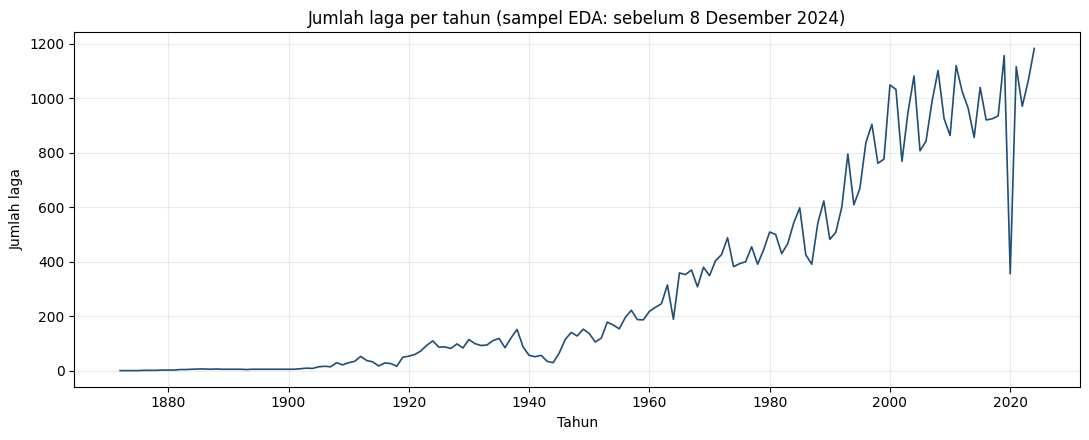

Rentang tahun: 1872-2024 | total laga: 48.093
Laga terbanyak: 1.182 (2024) | tersedikit: 1 (1872)

Jumlah laga per dekade (beserta proporsi terhadap df_eda):
              laga  proporsi_%
decade_label                  
1870-an         13        0.03
1880-an         55        0.11
1890-an         59        0.12
1900-an        138        0.29
1910-an        330        0.69
1920-an        831        1.73
1930-an       1079        2.24
1940-an        833        1.73
1950-an       1657        3.45
1960-an       2971        6.18
1970-an       4132        8.59
1980-an       5026       10.45
1990-an       6942       14.43
2000-an       9540       19.84
2010-an       9800       20.38
2020-an       4687        9.75

Tersimpan: ..\reports\figures\fig_01_jumlah_laga_per_tahun.png


In [35]:
per_year = df_eda.groupby("year").size()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(per_year.index, per_year.to_numpy(), color="#1f4e79", lw=1.2)
ax.set_title("Jumlah laga per tahun (sampel EDA: sebelum 8 Desember 2024)")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah laga")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_01_jumlah_laga_per_tahun.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Rentang tahun: {per_year.index.min()}-{per_year.index.max()} | total laga: {ribuan(per_year.sum())}")
print(f"Laga terbanyak: {ribuan(per_year.max())} ({per_year.idxmax()}) | "
      f"tersedikit: {per_year.min()} ({per_year.idxmin()})")

per_dekade_laga = df_eda.groupby("decade_label").size().to_frame("laga")
per_dekade_laga["proporsi_%"] = (per_dekade_laga["laga"] / len(df_eda) * 100).round(2)
print("\nJumlah laga per dekade (beserta proporsi terhadap df_eda):")
print(per_dekade_laga.to_string())
print(f"\nTersimpan: {FIG_DIR / 'fig_01_jumlah_laga_per_tahun.png'}")

**Insight:** Jumlah laga per tahun naik dari **1 laga (1872)** menjadi **1.182 laga (2024)**, dengan fluktuasi di antaranya. Dua dekade terakhir mendominasi: **2000-an 9.540 laga (19,84%)** dan **2010-an 9.800 laga (20,38%)**, sedangkan **1870-an hanya 13 laga (0,03%)** dan **1900-an 138 laga (0,29%)**. **2020-an berisi 4.687 laga (9,75%)** karena data berhenti 2024-11-19, jadi 2020-an bukan dekade penuh.

**Implikasi untuk model:** Distribusi waktu sangat tidak seimbang, sehingga split harus berbasis waktu (bukan acak) agar tidak ada era yang bocor dari train ke test. Dekade 1870-an–1900-an (13–138 laga) terlalu tipis untuk dijadikan dasar pola: pertimbangkan melatih pada era modern atau memberi bobot sampel per era. Tren 2020-an juga tidak boleh dibaca sebagai satu dekade penuh karena hanya mencakup sampai 2024-11-19.

#### 2) Rata-rata total gol per laga per dekade

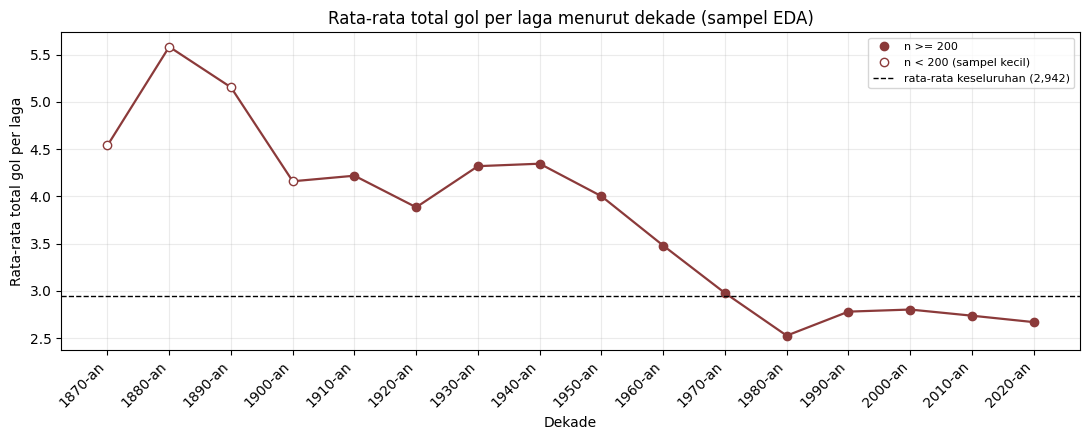

Rata-rata total gol per laga per dekade:
                 n  rata_rata  median
decade_label                         
1870-an         13      4.538     4.0
1880-an         55      5.582     5.0
1890-an         59      5.153     5.0
1900-an        138      4.159     4.0
1910-an        330      4.218     4.0
1920-an        831      3.884     4.0
1930-an       1079      4.319     4.0
1940-an        833      4.345     4.0
1950-an       1657      4.001     4.0
1960-an       2971      3.479     3.0
1970-an       4132      2.977     3.0
1980-an       5026      2.526     2.0
1990-an       6942      2.780     2.0
2000-an       9540      2.802     2.0
2010-an       9800      2.737     2.0
2020-an       4687      2.669     2.0

Rata-rata keseluruhan: 2,942 gol per laga
Tersimpan: ..\reports\figures\fig_02_rata_rata_gol_per_dekade.png


In [36]:
gol = df_eda.groupby("decade_label")["total_goals"].agg(
    n="size", rata_rata="mean", median="median")
gol["rata_rata"] = gol["rata_rata"].round(3)
rata_keseluruhan = df_eda["total_goals"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(gol))
cukup = (gol["n"] >= 200).to_numpy()
ax.plot(x, gol["rata_rata"], color="#8b3a3a", lw=1.6)
ax.plot(x[cukup], gol["rata_rata"].to_numpy()[cukup], "o", color="#8b3a3a", ms=6, label="n >= 200")
ax.plot(x[~cukup], gol["rata_rata"].to_numpy()[~cukup], "o", mfc="white", mec="#8b3a3a",
        ms=6, label="n < 200 (sampel kecil)")
ax.axhline(rata_keseluruhan, color="black", ls="--", lw=1,
           label=f"rata-rata keseluruhan ({fmt(rata_keseluruhan)})")
ax.set_xticks(x)
ax.set_xticklabels(gol.index, rotation=45, ha="right")
ax.set_title("Rata-rata total gol per laga menurut dekade (sampel EDA)")
ax.set_xlabel("Dekade")
ax.set_ylabel("Rata-rata total gol per laga")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_02_rata_rata_gol_per_dekade.png", dpi=150, bbox_inches="tight")
plt.show()

print("Rata-rata total gol per laga per dekade:")
print(gol.to_string())
print(f"\nRata-rata keseluruhan: {fmt(rata_keseluruhan)} gol per laga")
print(f"Tersimpan: {FIG_DIR / 'fig_02_rata_rata_gol_per_dekade.png'}")

**Insight:** Rata-rata total gol per laga tertinggi pada **1880-an (5,582 dengan n = 55)** dan **1890-an (5,153 dengan n = 59)**, lalu turun ke kisaran **3,9–4,3** pada 1900-an–1950-an dan terus menurun ke **1980-an (2,526 dengan n = 5.026)** — titik terendah. Setelah 1980-an nilainya berkisar **2,526–2,802**: **1990-an 2,780**, **2000-an 2,802**, **2010-an 2,737**, **2020-an 2,669**, dengan rata-rata keseluruhan **2,942**. Median total gol turun dari **5** (1880-an dan 1890-an) menjadi **2** (1980-an dan sesudahnya).

**Implikasi untuk model:** Laju gol tidak stasioner, sehingga model skor/Poisson dan simulasi Monte Carlo sebaiknya memakai laju gol era terbaru (atau fitur era), bukan rata-rata 1872–2024. Untuk laga ASEAN modern, kalibrasi distribusi gol pada 1990-an–2020-an lebih sesuai daripada memakai seluruh sejarah.

#### 3) Proporsi H/D/A per dekade, terpisah untuk `neutral=False` dan `neutral=True`

Proporsi H/D/A per dekade dan status netral (n = jumlah laga):
decade_label  neutral      H      D      A    n       sampel
     1870-an    False 0.6154 0.1538 0.2308   13 sampel kecil
     1880-an    False 0.4909 0.0909 0.4182   55 sampel kecil
     1890-an    False 0.5000 0.1552 0.3448   58 sampel kecil
     1890-an     True 1.0000 0.0000 0.0000    1 sampel kecil
     1900-an    False 0.4436 0.1805 0.3759  133 sampel kecil
     1900-an     True 0.6000 0.0000 0.4000    5 sampel kecil
     1910-an    False 0.5119 0.1763 0.3119  295        cukup
     1910-an     True 0.8286 0.0286 0.1429   35 sampel kecil
     1920-an    False 0.4966 0.1967 0.3067  727        cukup
     1920-an     True 0.7692 0.0577 0.1731  104 sampel kecil
     1930-an    False 0.5229 0.1704 0.3067  939        cukup
     1930-an     True 0.5357 0.0857 0.3786  140 sampel kecil
     1940-an    False 0.5441 0.1581 0.2979  658        cukup
     1940-an     True 0.4914 0.1371 0.3714  175 sampel kecil
     1950-an    False 

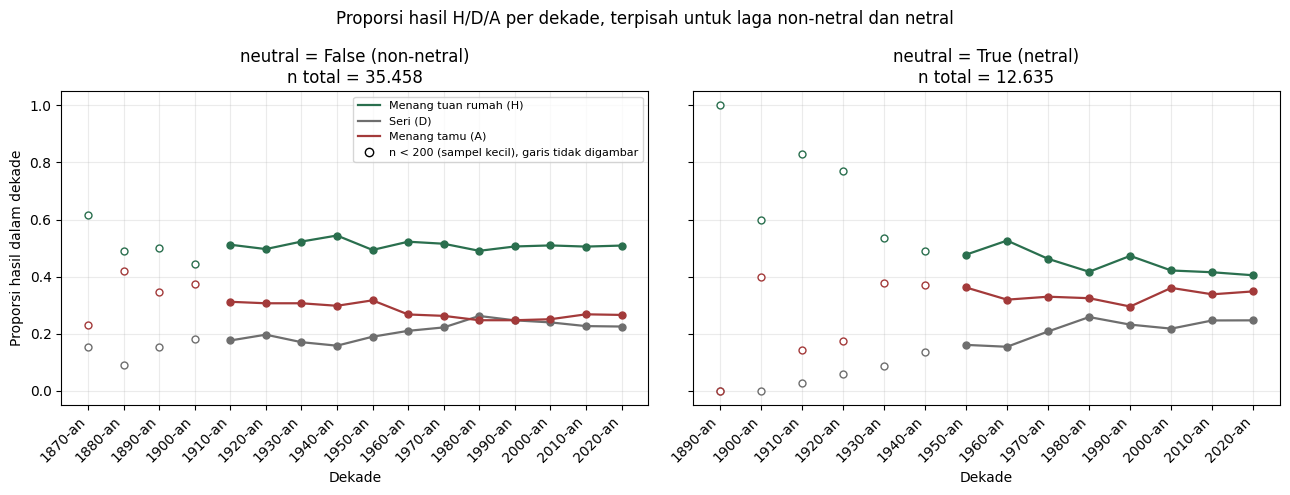


Tersimpan: ..\reports\figures\fig_03_proporsi_hda_per_dekade_neutral.png


In [37]:
hda = (df_eda.groupby(["decade_label", "neutral", "result"]).size()
       .unstack(fill_value=0)
       .reindex(columns=["H", "D", "A"], fill_value=0)
       .reset_index())
hda["n"] = hda[["H", "D", "A"]].sum(axis=1)
hda[["H", "D", "A"]] = hda[["H", "D", "A"]].div(hda["n"], axis=0).round(4)
hda["sampel"] = np.where(hda["n"] < 200, "sampel kecil", "cukup")

print("Proporsi H/D/A per dekade dan status netral (n = jumlah laga):")
print(hda.to_string(index=False))

warna = {"H": "#2a6f4e", "D": "#6e6e6e", "A": "#a33a3a"}
nama = {"H": "Menang tuan rumah (H)", "D": "Seri (D)", "A": "Menang tamu (A)"}

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, nilai_neutral, judul in zip(axes, [False, True],
                                    ["neutral = False (non-netral)", "neutral = True (netral)"]):
    sub = hda[hda["neutral"] == nilai_neutral].reset_index(drop=True)
    x = np.arange(len(sub))
    cukup = (sub["n"] >= 200).to_numpy()
    for k in ["H", "D", "A"]:
        y = sub[k].where(cukup)
        ax.plot(x, y, color=warna[k], lw=1.6)
        ax.plot(x[cukup], sub.loc[cukup, k], "o", color=warna[k], ms=5)
        ax.plot(x[~cukup], sub.loc[~cukup, k], "o", mfc="white", mec=warna[k], ms=5)
    ax.set_xticks(x)
    ax.set_xticklabels(sub["decade_label"], rotation=45, ha="right")
    ax.set_title(f"{judul}\nn total = {ribuan(sub['n'].sum())}")
    ax.set_xlabel("Dekade")
    ax.grid(alpha=0.25)

proxy = [plt.Line2D([], [], color=warna[k], lw=1.6, label=nama[k]) for k in ["H", "D", "A"]]
proxy.append(plt.Line2D([], [], color="black", marker="o", ls="none", mfc="white",
                        label="n < 200 (sampel kecil), garis tidak digambar"))
axes[0].legend(handles=proxy, fontsize=8, loc="best")
axes[0].set_ylabel("Proporsi hasil dalam dekade")
fig.suptitle("Proporsi hasil H/D/A per dekade, terpisah untuk laga non-netral dan netral")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_03_proporsi_hda_per_dekade_neutral.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"\nTersimpan: {FIG_DIR / 'fig_03_proporsi_hda_per_dekade_neutral.png'}")

**Insight:** Pada laga non-netral (`neutral=False`, n total **35.458**), proporsi H pada dekade dengan n ≥ 200 bergerak sempit antara **0,4905** dan **0,5441**; pada **2020-an H 0,5089, D 0,2252, A 0,2659** (n = 3.148). Pada laga netral (`neutral=True`, n total **12.635**), proporsi H pada dekade dengan n ≥ 200 berkisar **0,4048** (2020-an, n = 1.539) sampai **0,5264** (1960-an, n = 739) dan cenderung menurun setelah 1960-an; pada **2020-an H 0,4048, D 0,2469, A 0,3483**. Nilai **1910-an H 0,8286, D 0,0286, A 0,1429** hanya berasal dari **n = 35** (*sampel kecil*). Dekade bertanda *sampel kecil* (n < 200) adalah **1870-an–1900-an** pada panel `False` dan **1890-an–1940-an** pada panel `True`.

**Implikasi untuk model:** Pengaruh status netral terhadap hasil berubah menurut era (interaksi `neutral` × era), sehingga satu angka "keuntungan tuan rumah" untuk seluruh sejarah berisiko bias. Sertakan fitur era/dekade dan interaksinya dengan `neutral`, atau batasi pelatihan pada era modern. Pada laga netral modern, H (**0,4048**) dan A (**0,3483**) berjarak tipis, jadi fitur kekuatan tim tetap diperlukan — bukan hanya status tuan rumah.

#### 4) Tingkat seri per dekade

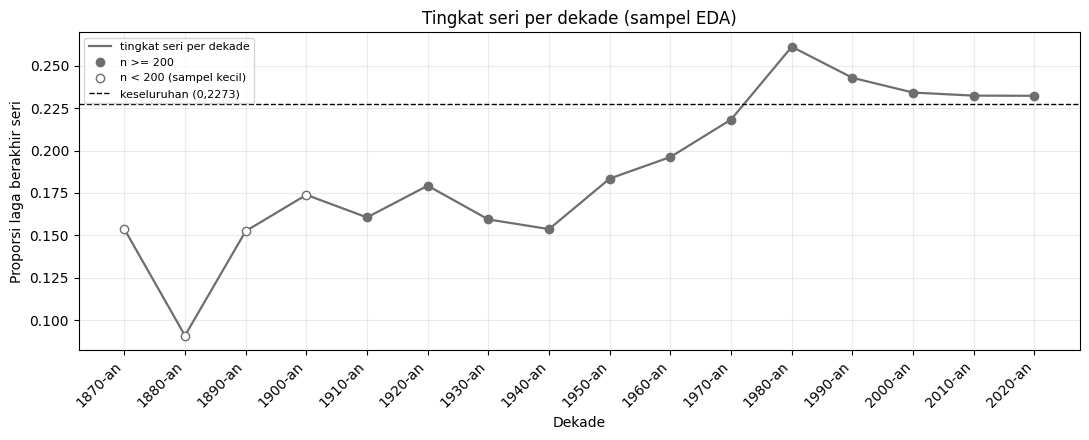

Tingkat seri per dekade (seri = jumlah laga D):
                 n  seri  tingkat_seri        sampel
decade_label                                        
1870-an         13     2        0.1538  sampel kecil
1880-an         55     5        0.0909  sampel kecil
1890-an         59     9        0.1525  sampel kecil
1900-an        138    24        0.1739  sampel kecil
1910-an        330    53        0.1606         cukup
1920-an        831   149        0.1793         cukup
1930-an       1079   172        0.1594         cukup
1940-an        833   128        0.1537         cukup
1950-an       1657   304        0.1835         cukup
1960-an       2971   583        0.1962         cukup
1970-an       4132   902        0.2183         cukup
1980-an       5026  1313        0.2612         cukup
1990-an       6942  1686        0.2429         cukup
2000-an       9540  2234        0.2342         cukup
2010-an       9800  2278        0.2324         cukup
2020-an       4687  1089        0.2323         cuku

In [38]:
seri = df_eda.groupby("decade_label").agg(
    n=("result", "size"), seri=("result", lambda s: (s == "D").sum()))
seri["tingkat_seri"] = (seri["seri"] / seri["n"]).round(4)
seri["sampel"] = np.where(seri["n"] < 200, "sampel kecil", "cukup")
tingkat_seri_total = (df_eda["result"] == "D").mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(seri))
cukup = (seri["n"] >= 200).to_numpy()
ax.plot(x, seri["tingkat_seri"], color="#6e6e6e", lw=1.6, label="tingkat seri per dekade")
ax.plot(x[cukup], seri["tingkat_seri"].to_numpy()[cukup], "o", color="#6e6e6e", ms=6,
        label="n >= 200")
ax.plot(x[~cukup], seri["tingkat_seri"].to_numpy()[~cukup], "o", mfc="white", mec="#6e6e6e",
        ms=6, label="n < 200 (sampel kecil)")
ax.axhline(tingkat_seri_total, color="black", ls="--", lw=1,
           label=f"keseluruhan ({fmt(tingkat_seri_total, 4)})")
ax.set_xticks(x)
ax.set_xticklabels(seri.index, rotation=45, ha="right")
ax.set_title("Tingkat seri per dekade (sampel EDA)")
ax.set_xlabel("Dekade")
ax.set_ylabel("Proporsi laga berakhir seri")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_04_tingkat_seri_per_dekade.png", dpi=150, bbox_inches="tight")
plt.show()

print("Tingkat seri per dekade (seri = jumlah laga D):")
print(seri.to_string())
print(f"\nTingkat seri keseluruhan: {fmt(tingkat_seri_total, 4)}")
print(f"Tersimpan: {FIG_DIR / 'fig_04_tingkat_seri_per_dekade.png'}")

**Insight:** Pada 1870-an–1900-an tingkat seri berkisar **0,0909–0,1739** (semua *sampel kecil*, n = 13–138), lalu meningkat ke puncak **0,2612 pada 1980-an (n = 5.026)**, dan sedikit menurun dan stabil sesudahnya: **1990-an 0,2429**, **2000-an 0,2342**, **2010-an 0,2324**, **2020-an 0,2323**. Rata-rata keseluruhan **0,2273**.

**Implikasi untuk model:** Prior kelas D tidak konstan — dari di bawah 10% pada 1880-an menjadi sekitar 26% pada 1980-an. Baseline "selalu seri" dan kalibrasi probabilitas harus dihitung per era; karena split berbasis waktu membuat proporsi D di train dan test berbeda, metrik sebaiknya dilaporkan per periode pula, bukan hanya agregat.

#### 5) Proporsi laga netral per dekade

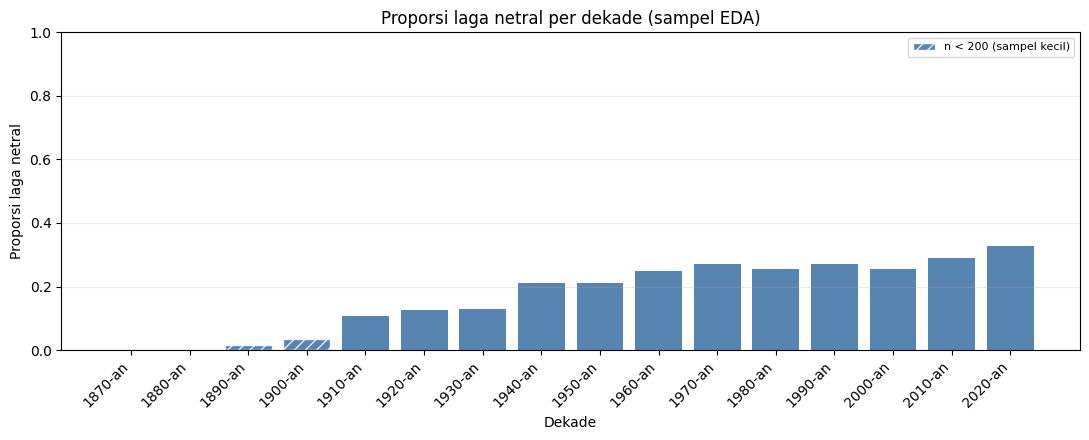

Proporsi laga netral per dekade:
                 n  netral  proporsi_netral        sampel
decade_label                                             
1870-an         13       0           0.0000  sampel kecil
1880-an         55       0           0.0000  sampel kecil
1890-an         59       1           0.0169  sampel kecil
1900-an        138       5           0.0362  sampel kecil
1910-an        330      35           0.1061         cukup
1920-an        831     104           0.1252         cukup
1930-an       1079     140           0.1297         cukup
1940-an        833     175           0.2101         cukup
1950-an       1657     348           0.2100         cukup
1960-an       2971     739           0.2487         cukup
1970-an       4132    1116           0.2701         cukup
1980-an       5026    1285           0.2557         cukup
1990-an       6942    1876           0.2702         cukup
2000-an       9540    2424           0.2541         cukup
2010-an       9800    2848           0.

In [39]:
netral = df_eda.groupby("decade_label").agg(
    n=("neutral", "size"), netral=("neutral", "sum"))
netral["proporsi_netral"] = (netral["netral"] / netral["n"]).round(4)
netral["sampel"] = np.where(netral["n"] < 200, "sampel kecil", "cukup")
proporsi_netral_total = df_eda["neutral"].mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(netral))
bars = ax.bar(x, netral["proporsi_netral"], color="#3b6ea5", alpha=0.85)
for bar, kecil in zip(bars, netral["n"] < 200):
    if kecil:
        bar.set_hatch("///")
        bar.set_edgecolor("white")
ax.set_xticks(x)
ax.set_xticklabels(netral.index, rotation=45, ha="right")
ax.set_title("Proporsi laga netral per dekade (sampel EDA)")
ax.set_xlabel("Dekade")
ax.set_ylabel("Proporsi laga netral")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.25)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, fc="#3b6ea5", alpha=0.85, hatch="///",
                                 ec="white", label="n < 200 (sampel kecil)")], fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_05_proporsi_laga_netral_per_dekade.png", dpi=150, bbox_inches="tight")
plt.show()

print("Proporsi laga netral per dekade:")
print(netral.to_string())
print(f"\nProporsi netral keseluruhan: {fmt(proporsi_netral_total, 4)}")
print(f"Tersimpan: {FIG_DIR / 'fig_05_proporsi_laga_netral_per_dekade.png'}")

**Insight:** Proporsi laga netral **0,0000 pada 1870-an (n = 13)** dan **1880-an (n = 55)**, lalu naik menjadi **0,1061 pada 1910-an**, **0,2701 pada 1970-an**, **0,2906 pada 2010-an**, dan **0,3284 pada 2020-an** — tertinggi. Rata-rata keseluruhan **0,2627**. Dekade 1870-an–1900-an bertanda *sampel kecil* dan batangnya diberi garis miring.

**Implikasi untuk model:** Komposisi laga berubah besar: makin banyak laga dimainkan di tempat netral, sehingga makna "tuan rumah" bergeser. Fitur `neutral` wajib ada dan sebaiknya berinteraksi dengan era. Saat mengevaluasi data modern, bandingkan dengan proporsi netral era itu (**2020-an 0,3284**), bukan rata-rata sejarah **0,2627**.

#### 6) Distribusi selisih gol dan skor besar per dekade

**6a) Distribusi selisih gol (home - away) keseluruhan**

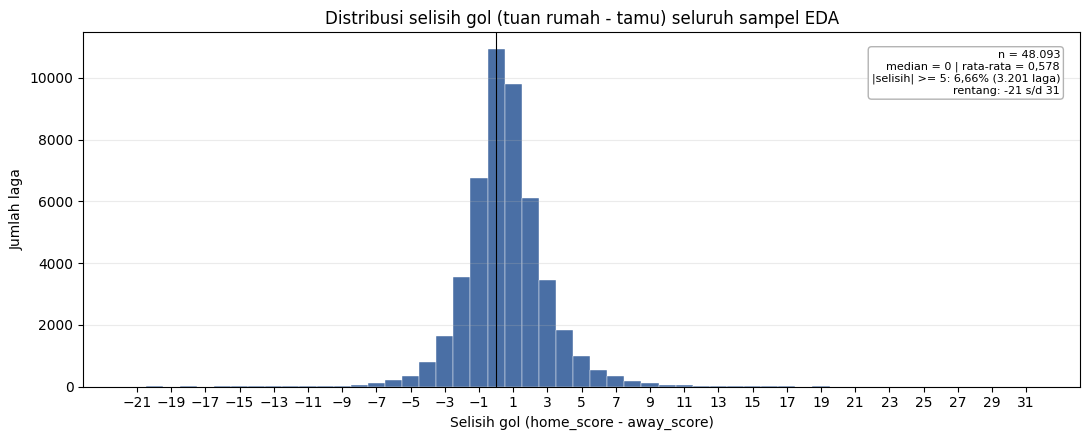

Rentang selisih gol: -21 s/d 31
Median: 0 | rata-rata: 0,578
Laga |selisih| >= 5: 3.201 dari 48.093 (6,66%)
Tersimpan: ..\reports\figures\fig_06_distribusi_selisih_gol.png


In [40]:
selisih = df_eda["goal_diff"]
besar_total = df_eda["abs_diff"] >= 5
bins = np.arange(selisih.min() - 0.5, selisih.max() + 1.5, 1)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(selisih, bins=bins, color="#4a6fa5", edgecolor="white", linewidth=0.3)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Distribusi selisih gol (tuan rumah - tamu) seluruh sampel EDA")
ax.set_xlabel("Selisih gol (home_score - away_score)")
ax.set_ylabel("Jumlah laga")
ax.set_xticks(range(int(selisih.min()), int(selisih.max()) + 1, 2))
ax.grid(axis="y", alpha=0.25)
ax.text(0.98, 0.95,
        f"n = {ribuan(len(df_eda))}\n"
        f"median = {fmt(selisih.median(), 0)} | rata-rata = {fmt(selisih.mean())}\n"
        f"|selisih| >= 5: {fmt(besar_total.mean() * 100, 2)}% ({ribuan(besar_total.sum())} laga)\n"
        f"rentang: {int(selisih.min())} s/d {int(selisih.max())}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8,
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_06_distribusi_selisih_gol.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Rentang selisih gol: {int(selisih.min())} s/d {int(selisih.max())}")
print(f"Median: {selisih.median():.0f} | rata-rata: {fmt(selisih.mean())}")
print(f"Laga |selisih| >= 5: {ribuan(besar_total.sum())} dari {ribuan(len(df_eda))} "
      f"({fmt(besar_total.mean() * 100, 2)}%)")
print(f"Tersimpan: {FIG_DIR / 'fig_06_distribusi_selisih_gol.png'}")

**Insight:** Selisih gol `home_score - away_score` berpusat di **0 (median 0)** dengan rata-rata **0,578**, artinya tuan rumah sedikit lebih sering menang. Sebarannya lebar, dari **-21 sampai 31**, tetapi ekornya tipis: laga dengan **|selisih| ≥ 5** hanya **6,66% (3.201 dari 48.093 laga)**. Puncak distribusi berada pada selisih **0** dan **+1**.

**Implikasi untuk model:** Karena selisih 0 adalah satu-satunya titik seri dan |selisih| ≥ 5 langka, akurasi agregat mudah didominasi kelas mayoritas; laporkan metrik per kelas dan kalibrasi, bukan hanya akurasi. Untuk fitur berbasis skor, clipping selisih gol (atau transformasi log(1 + gol)) meredam ekor ekstrem tanpa membuang laga.

**6b) Apakah skor besar (selisih >= 5) berubah menurut dekade?**

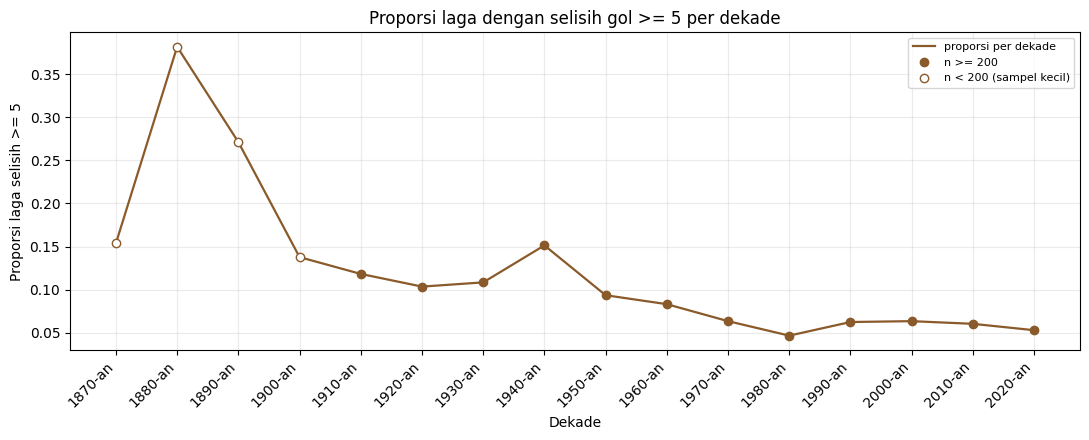

Proporsi laga |selisih| >= 5 per dekade:
                 n  besar  proporsi_besar        sampel
decade_label                                           
1870-an         13      2          0.1538  sampel kecil
1880-an         55     21          0.3818  sampel kecil
1890-an         59     16          0.2712  sampel kecil
1900-an        138     19          0.1377  sampel kecil
1910-an        330     39          0.1182         cukup
1920-an        831     86          0.1035         cukup
1930-an       1079    117          0.1084         cukup
1940-an        833    126          0.1513         cukup
1950-an       1657    155          0.0935         cukup
1960-an       2971    247          0.0831         cukup
1970-an       4132    262          0.0634         cukup
1980-an       5026    234          0.0466         cukup
1990-an       6942    433          0.0624         cukup
2000-an       9540    605          0.0634         cukup
2010-an       9800    591          0.0603         cukup
2020-an

In [41]:
besar = df_eda.groupby("decade_label").agg(
    n=("abs_diff", "size"), besar=("abs_diff", lambda s: (s >= 5).sum()))
besar["proporsi_besar"] = (besar["besar"] / besar["n"]).round(4)
besar["sampel"] = np.where(besar["n"] < 200, "sampel kecil", "cukup")

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(besar))
cukup = (besar["n"] >= 200).to_numpy()
ax.plot(x, besar["proporsi_besar"], color="#8a5a2b", lw=1.6, label="proporsi per dekade")
ax.plot(x[cukup], besar["proporsi_besar"].to_numpy()[cukup], "o", color="#8a5a2b", ms=6,
        label="n >= 200")
ax.plot(x[~cukup], besar["proporsi_besar"].to_numpy()[~cukup], "o", mfc="white", mec="#8a5a2b",
        ms=6, label="n < 200 (sampel kecil)")
ax.set_xticks(x)
ax.set_xticklabels(besar.index, rotation=45, ha="right")
ax.set_title("Proporsi laga dengan selisih gol >= 5 per dekade")
ax.set_xlabel("Dekade")
ax.set_ylabel("Proporsi laga selisih >= 5")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_07_proporsi_selisih_besar_per_dekade.png", dpi=150,
            bbox_inches="tight")
plt.show()

print("Proporsi laga |selisih| >= 5 per dekade:")
print(besar.to_string())
print(f"\nKeseluruhan: {fmt((df_eda['abs_diff'] >= 5).mean(), 4)} "
      f"({ribuan(int((df_eda['abs_diff'] >= 5).sum()))} laga)")
print(f"Tersimpan: {FIG_DIR / 'fig_07_proporsi_selisih_besar_per_dekade.png'}")

**Insight:** Proporsi laga dengan selisih ≥ 5 menurun menurut dekade: **0,3818 pada 1880-an (n = 55)** dan **0,2712 pada 1890-an (n = 59)** — keduanya *sampel kecil* — lalu **0,1513 pada 1940-an (n = 833)**, **0,0831 pada 1960-an**, dan **0,0466 pada 1980-an** sebagai terendah. Sesudah 1980-an nilainya stabil: **1990-an 0,0624**, **2000-an 0,0634**, **2010-an 0,0603**, **2020-an 0,0529**. Rata-rata keseluruhan **0,0666**.

**Implikasi untuk model:** Skor besar jauh lebih umum pada era awal, sehingga memasukkan seluruh sejarah tanpa fitur era membuat model skor/simulasi menghasilkan ekor yang terlalu gemuk untuk era modern. Pilihan yang konsisten dengan angka di atas: batasi sampel latih ke era modern atau tambahkan fitur era, dan tetap pakai clipping/robust loss agar sebagian kecil laga ekstrem tidak mendominasi.

### 4.2 Label Home di Laga Netral

Subbagian ini memakai `df_eda` yang sama seperti 4.1 (filter `date < 2024-12-08`) dan hanya baris `neutral=True`. Pertanyaannya: pada laga netral, apakah label `H`/`A` masih berarti "tuan rumah", atau hanya penanda urutan baris? Tidak ada pemodelan di subbagian ini.

**Aturan subset:** cell berikut mengulang assert `df_eda.date.max() < 2024-12-08`, mengambil subset `neutral=True`, lalu membuat dua penanda: `home_is_country` (`home_team == country`) dan `away_is_country` (`away_team == country`). Perbandingan memakai **kecocokan string persis**.

In [42]:
# --- Subset 4.2: laga netral dari df_eda ---
assert df_eda["date"].max() < CUTOFF, f"df_eda memuat tanggal >= {CUTOFF.date()}"

netral = df_eda[df_eda["neutral"]].copy()
assert len(netral) == int(df_eda["neutral"].sum())
assert bool(netral["neutral"].all())

netral["home_is_country"] = netral["home_team"] == netral["country"]
netral["away_is_country"] = netral["away_team"] == netral["country"]

print(f"Assert lolos: df_eda.date.max() = {df_eda['date'].max().date()} < {CUTOFF.date()}")
print(f"df_eda: {ribuan(len(df_eda))} baris | neutral=True: {ribuan(len(netral))} baris "
      f"({fmt(len(netral) / len(df_eda) * 100, 2)}% dari df_eda)")
print(f"home_team == country  : {ribuan(netral['home_is_country'].sum())} laga "
      f"({fmt(netral['home_is_country'].mean(), 4)})")
print(f"away_team == country  : {ribuan(netral['away_is_country'].sum())} laga "
      f"({fmt(netral['away_is_country'].mean(), 4)})")
print(f"keduanya == country   : {ribuan(int((netral['home_is_country'] & netral['away_is_country']).sum()))} laga")
print(f"keduanya bukan country: {ribuan(int((~netral['home_is_country'] & ~netral['away_is_country']).sum()))} laga")

Assert lolos: df_eda.date.max() = 2024-11-19 < 2024-12-08
df_eda: 48.093 baris | neutral=True: 12.635 baris (26,27% dari df_eda)
home_team == country  : 1 laga (0,0001)
away_team == country  : 0 laga (0,0000)
keduanya == country   : 0 laga
keduanya bukan country: 12.634 laga


**1) Kecocokan nama tim dengan `country` per dekade** (hanya dekade dengan n ≥ 200, plus total)

In [43]:
cocok = (netral.groupby("decade_label")
         .agg(laga=("result", "size"),
              home_is_country=("home_is_country", "mean"),
              away_is_country=("away_is_country", "mean")))
cocok_200 = cocok[cocok["laga"] >= 200]
total_cocok = pd.DataFrame([{"laga": len(netral),
                            "home_is_country": netral["home_is_country"].mean(),
                            "away_is_country": netral["away_is_country"].mean()}],
                           index=["Total (seluruh dekade)"])
tabel_cocok = pd.concat([cocok_200, total_cocok])
print("Proporsi laga netral dengan nama tim == country (dekade n >= 200, plus total):")
print(tabel_cocok.to_string(float_format=lambda x: fmt(x, 4)))

kecil = cocok[cocok["laga"] < 200]
print("\nDekade netral dengan n < 200 (sampel kecil, tidak ditampilkan di tabel):")
print("  " + ", ".join(f"{d} (n = {ribuan(v)})" for d, v in kecil["laga"].items()))
print("\nSatu laga netral yang home_team == country:")
print(netral[netral["home_is_country"]][["date", "home_team", "away_team", "country",
                                         "tournament", "result"]].to_string(index=False))

Proporsi laga netral dengan nama tim == country (dekade n >= 200, plus total):
                         laga  home_is_country  away_is_country
1950-an                   348           0,0000           0,0000
1960-an                   739           0,0000           0,0000
1970-an                  1116           0,0009           0,0000
1980-an                  1285           0,0000           0,0000
1990-an                  1876           0,0000           0,0000
2000-an                  2424           0,0000           0,0000
2010-an                  2848           0,0000           0,0000
2020-an                  1539           0,0000           0,0000
Total (seluruh dekade)  12635           0,0001           0,0000

Dekade netral dengan n < 200 (sampel kecil, tidak ditampilkan di tabel):
  1890-an (n = 1), 1900-an (n = 5), 1910-an (n = 35), 1920-an (n = 104), 1930-an (n = 140), 1940-an (n = 175)

Satu laga netral yang home_team == country:
      date home_team away_team   country            

**Insight:** Dari **12.635** laga netral (**26,27%** dari `df_eda`), hanya **1** laga (**0,0001**) yang `home_team == country` dan **0** laga (**0,0000**) yang `away_team == country`. Pada dekade dengan n ≥ 200, proporsi `home_team == country` adalah **0,0000** di semua dekade kecuali **1970-an (0,0009)** — satu laga, 1972-06-17 Indonesia vs Cambodia pada *Jakarta Anniversary Tournament* — dan proporsi `away_team == country` **0,0000** di semua dekade. Jadi pada laga `neutral=True`, kolom `country` (negara tempat laga dimainkan) hampir tidak pernah sama dengan nama salah satu tim.

**Batas pembacaan:** pencocokan memakai string persis dan nama negara/tim bisa berubah antar era (lihat `former_names.csv` di 2.2.2), sehingga angka ini adalah **batas bawah**. Meski begitu, batas bawah **1 dari 12.635** menunjukkan perbedaannya bukan soal penamaan: laga netral memang nyaris tidak memuat tim dari negara tempat laga digelar.

**Implikasi untuk fitur/model:** sinyal "bermain di kandang" **tidak bisa** diturunkan dari `country` pada laga netral, jadi fitur host berbasis pasangan (`team == country`) tidak berguna untuk subset ini — dan kalau dipakai, fitur itu praktis konstan nol. Informasi penyelenggara, bila dibutuhkan model, harus datang dari luar kolom ini.

**2) Proporsi H/D/A pada laga netral menurut kecocokan dengan `country`:** (a) `home_team == country`, (b) `away_team == country`, (c) keduanya bukan `country`.

In [44]:
def kategori_country(row):
    if row.home_is_country:
        return "(a) home_team == country"
    if row.away_is_country:
        return "(b) away_team == country"
    return "(c) keduanya bukan country"


netral["kategori_country"] = [kategori_country(r) for r in netral.itertuples()]
URUTAN_KAT = ["(a) home_team == country", "(b) away_team == country", "(c) keduanya bukan country"]

hitung_kat = (netral.groupby(["kategori_country", "result"]).size()
              .unstack(fill_value=0).reindex(index=URUTAN_KAT, columns=["H", "D", "A"], fill_value=0))
hitung_kat = hitung_kat[hitung_kat.sum(axis=1) > 0]
prop_kat = hitung_kat.div(hitung_kat.sum(axis=1), axis=0)
prop_kat.insert(0, "laga", hitung_kat.sum(axis=1))

print("Proporsi H/D/A pada laga netral menurut kecocokan nama tim dengan country:")
print(prop_kat.to_string(float_format=lambda x: fmt(x, 4)))
print(f"\nTotal laga pada tabel: {ribuan(int(prop_kat['laga'].sum()))} | netral: {ribuan(len(netral))}")
c_only = prop_kat.loc["(c) keduanya bukan country"]
print(f"Kategori (c): H {fmt(c_only['H'], 4)} vs A {fmt(c_only['A'], 4)} "
      f"(selisih H - A = {fmt(c_only['H'] - c_only['A'], 4)})")

Proporsi H/D/A pada laga netral menurut kecocokan nama tim dengan country:
result                       laga      H      D      A
kategori_country                                      
(a) home_team == country        1 1,0000 0,0000 0,0000
(c) keduanya bukan country  12634 0,4429 0,2234 0,3338

Total laga pada tabel: 12.635 | netral: 12.635
Kategori (c): H 0,4429 vs A 0,3338 (selisih H - A = 0,1091)


**Insight:** Kategori **(a) hanya 1 laga** (H = 1,0000), kategori **(b) 0 laga**, dan kategori **(c) 12.634 laga (99,99% laga netral)** dengan H **0,4429**, D **0,2234**, A **0,3338**. Karena (a) dan (b) kosong secara praktis, angka H/D/A laga netral di 4.1 pada dasarnya adalah perilaku kategori (c): laga yang dimainkan di negara ketiga, tanpa tim tuan rumah.

Pada kategori (c) selisih H − A = **0,1091**, jadi label `H` masih lebih sering berakhir dengan kemenangan tim "home" meski tidak ada tim yang bermain di negaranya sendiri.

**Implikasi untuk fitur/model:** fitur `neutral` tidak cukup dipakai sebagai on/off home advantage yang mematikan segalanya — pada laga netral prior H (**0,4429**) tetap jauh di atas 1/3 dan di atas prior A (**0,3338**). Baseline naif "tiga kelas seragam" akan *under-predict* H pada laga netral; prior kelas sebaiknya dihitung terpisah untuk `neutral=True` dan `neutral=False`, atau `neutral` masuk sebagai fitur dengan interaksi, bukan sekadar filter.

**3) Uji urutan nama:** proporsi laga netral dengan `home_team < away_team` secara alfabet, dibandingkan dengan **0,5** (bila urutan baris acak, nilainya sekitar 0,5), lalu proporsi H/D/A untuk `home < away` vs `home > away`.

Distribusi urutan alfabet pada laga netral:
urutan_alfabet
home < away    7977
home > away    4658

Proporsi home_team < away_team : 0,6313 (7.977 dari 12.635 laga)
Pembanding 0,5                : 0,5000
Selisih terhadap 0,5          : 0,1313

Proporsi H/D/A pada laga netral menurut urutan alfabet:
result          laga      H      D      A
urutan_alfabet                           
home < away     7977 0,4307 0,2246 0,3446
home > away     4658 0,4637 0,2211 0,3152
home < away: H 0,4307 | A 0,3446 | H - A = 0,0861
home > away: H 0,4637 | A 0,3152 | H - A = 0,1486


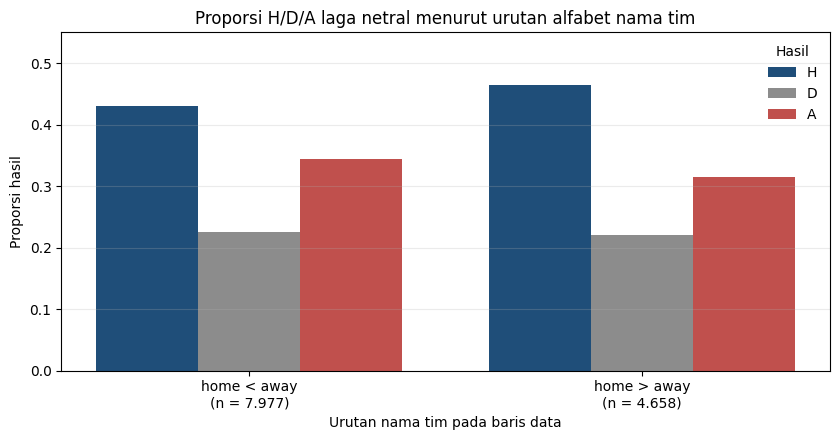

Tersimpan: ..\reports\figures\fig_08_hda_netral_urutan_alfabet.png


In [45]:
netral["urutan_alfabet"] = np.select(
    [netral["home_team"] < netral["away_team"], netral["home_team"] > netral["away_team"]],
    ["home < away", "home > away"], default="home == away")

print("Distribusi urutan alfabet pada laga netral:")
print(netral["urutan_alfabet"].value_counts().to_string())
share_alfabet = float((netral["home_team"] < netral["away_team"]).mean())
print(f"\nProporsi home_team < away_team : {fmt(share_alfabet, 4)} "
      f"({ribuan(int((netral['home_team'] < netral['away_team']).sum()))} dari {ribuan(len(netral))} laga)")
print(f"Pembanding 0,5                : 0,5000")
print(f"Selisih terhadap 0,5          : {fmt(share_alfabet - 0.5, 4)}")

hitung_urut = (netral.groupby(["urutan_alfabet", "result"]).size()
               .unstack(fill_value=0).reindex(columns=["H", "D", "A"], fill_value=0))
hitung_urut = hitung_urut[hitung_urut.sum(axis=1) > 0]
prop_urut = hitung_urut.div(hitung_urut.sum(axis=1), axis=0)
prop_urut.insert(0, "laga", hitung_urut.sum(axis=1))
print("\nProporsi H/D/A pada laga netral menurut urutan alfabet:")
print(prop_urut.to_string(float_format=lambda x: fmt(x, 4)))
for u in prop_urut.index:
    print(f"{u}: H {fmt(prop_urut.loc[u, 'H'], 4)} | A {fmt(prop_urut.loc[u, 'A'], 4)} | "
          f"H - A = {fmt(prop_urut.loc[u, 'H'] - prop_urut.loc[u, 'A'], 4)}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
x = np.arange(len(prop_urut))
w = 0.26
for i, (kol, warna) in enumerate(zip(["H", "D", "A"], ["#1f4e79", "#8c8c8c", "#c0504d"])):
    ax.bar(x + (i - 1) * w, prop_urut[kol], width=w, color=warna, label=kol)
ax.set_xticks(x)
ax.set_xticklabels([f"{u}\n(n = {ribuan(int(prop_urut.loc[u, 'laga']))})" for u in prop_urut.index])
ax.set_title("Proporsi H/D/A laga netral menurut urutan alfabet nama tim")
ax.set_xlabel("Urutan nama tim pada baris data")
ax.set_ylabel("Proporsi hasil")
ax.set_ylim(0, 0.55)
ax.legend(title="Hasil", frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_08_hda_netral_urutan_alfabet.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Tersimpan: {FIG_DIR / 'fig_08_hda_netral_urutan_alfabet.png'}")

**Insight:** Sebanyak **0,6313** laga netral punya `home_team < away_team` (**7.977** laga), jauh di atas pembanding **0,5** (selisih **0,1313**); hanya **0,3687** (**4.658** laga) yang sebaliknya, dan **0** laga dengan nama tim sama. Urutan baris pada laga netral karena itu **tidak acak** — cenderung mengikuti abjad — tetapi tidak konsisten penuh (kalau konsisten, proporsinya 1,0000). Artinya label `home`/`away` pada laga netral sebagian besar hanya penanda urutan penulisan.

Meski begitu, pada **kedua** urutan H tetap lebih tinggi dari A: `home < away` H **0,4307** vs A **0,3446** (selisih **0,0861**), dan `home > away` H **0,4637** vs A **0,3152** (selisih **0,1486**). Jadi "keunggulan Home" tidak hilang walaupun penentuannya alfabetis. **Dugaan** (belum terbukti dari data di sini): tim yang dicatat lebih dulu cenderung tim yang lebih kuat, penyelenggara, atau unggulan pot — data yang dipakai tidak memuat peringkat, pot, atau informasi penyelenggara, sehingga dugaan ini tidak bisa diuji pada subbagian ini.

**Implikasi untuk fitur/model:** (i) parameter home advantage sebaiknya **tidak** dipakai penuh pada laga netral; kalau model skor/simulasi memakai satu parameter home advantage global, laga netral akan bias ke H; (ii) karena label `home` berkorelasi dengan urutan penulisan yang tidak acak, status `neutral` perlu interaksi dengan `home`/era, bukan hanya pengurangan konstanta; (iii) sensitivitas terhadap urutan penulisan ini layak jadi uji ketahanan (mis. membalik `home_team`/`away_team` pada sebagian laga netral dan melihat perubahan prediksi).

**4) Ulangi langkah 2 hanya untuk periode ≥ 1990-an**, agar pola tidak didominasi era lama.

In [46]:
netral_90 = netral[netral["year"] >= 1990]
assert len(netral_90) > 0 and netral_90["date"].min() >= pd.Timestamp("1990-01-01")

hitung_kat90 = (netral_90.groupby(["kategori_country", "result"]).size()
                .unstack(fill_value=0).reindex(index=URUTAN_KAT, columns=["H", "D", "A"], fill_value=0))
hitung_kat90 = hitung_kat90[hitung_kat90.sum(axis=1) > 0]
prop_kat90 = hitung_kat90.div(hitung_kat90.sum(axis=1), axis=0)
prop_kat90.insert(0, "laga", hitung_kat90.sum(axis=1))

print(f"Laga netral periode >= 1990-an: {ribuan(len(netral_90))} "
      f"({fmt(len(netral_90) / len(netral) * 100, 2)}% dari seluruh laga netral)")
print("Proporsi H/D/A menurut kecocokan nama tim dengan country (>= 1990-an):")
print(prop_kat90.to_string(float_format=lambda x: fmt(x, 4)))
print(f"home_team == country: {ribuan(int(netral_90['home_is_country'].sum()))} laga | "
      f"away_team == country: {ribuan(int(netral_90['away_is_country'].sum()))} laga")
print(f"share home_team < away_team (>= 1990-an): "
      f"{fmt((netral_90['home_team'] < netral_90['away_team']).mean(), 4)}")

Laga netral periode >= 1990-an: 8.687 (68,75% dari seluruh laga netral)
Proporsi H/D/A menurut kecocokan nama tim dengan country (>= 1990-an):
result                      laga      H      D      A
kategori_country                                     
(c) keduanya bukan country  8687 0,4277 0,2354 0,3369
home_team == country: 0 laga | away_team == country: 0 laga
share home_team < away_team (>= 1990-an): 0,5636


**Insight:** Pada periode ≥ 1990-an, **8.687** laga netral (**68,75%** dari seluruh laga netral) **seluruhnya** masuk kategori (c): **0** laga dengan `home_team == country` dan **0** dengan `away_team == country`. Proporsinya H **0,4277**, D **0,2354**, A **0,3369** (selisih H − A **0,0908**), sedangkan `home_team < away_team` terjadi pada **0,5636** laga — lebih dekat ke 0,5 dibandingkan seluruh periode (**0,6313**), tetapi masih di atas 0,5.

Jadi pola era modern **bukan** dijelaskan oleh kandang: hampir tidak ada tim yang bermain di negaranya sendiri pada laga netral, sementara label H tetap sedikit lebih sering menang.

**Implikasi untuk fitur/model:** untuk data uji era modern, fitur host makin tidak relevan, tetapi efek "home" tidak nol (**0,0908**) sehingga menghapus seluruh efek home pada laga netral juga tidak tepat. Rekomendasi praktis: latih dengan `neutral` sebagai fitur, laporkan metrik terpisah untuk `neutral=True`/`False`, dan pakai model/parameter yang memungkinkan efek home mengecil pada laga netral modern (mis. interaksi `neutral × dekade`), bukan konstanta global.

### 4.3 Jenis Turnamen

Subbagian ini memetakan komposisi `tournament` pada `df_eda` dan menguji apakah hasil, gol, dan status netral berbeda menurut jenis turnamen. Tidak ada pemodelan.

**5) 20 turnamen dengan laga terbanyak** — nama turnamen, jumlah laga (n), dan proporsi laga netral.

In [47]:
turnamen = (df_eda.groupby("tournament")
            .agg(laga=("result", "size"), proporsi_netral=("neutral", "mean"))
            .sort_values("laga", ascending=False))
top20 = turnamen.head(20).copy()
top20["proporsi_%"] = top20["laga"] / len(df_eda) * 100

print("20 turnamen dengan laga terbanyak:")
print(top20.to_string(float_format=lambda x: fmt(x, 4)))
print(f"\nJumlah turnamen unik: {ribuan(len(turnamen))} | laga pada 20 teratas: "
      f"{fmt(top20['laga'].sum() / len(df_eda) * 100, 2)}% dari df_eda")
print(f"Turnamen dengan tepat 1 laga: {ribuan(int((turnamen['laga'] == 1).sum()))}")

20 turnamen dengan laga terbanyak:
                                       laga  proporsi_netral  proporsi_%
tournament                                                              
Friendly                              17775           0,1376     36,9596
FIFA World Cup qualification           8263           0,0846     17,1813
UEFA Euro qualification                2824           0,0188      5,8720
African Cup of Nations qualification   2327           0,0627      4,8385
FIFA World Cup                          964           0,8745      2,0044
Copa América                            869           0,6651      1,8069
African Cup of Nations                  793           0,7995      1,6489
AFC Asian Cup qualification             770           0,3429      1,6011
UEFA Nations League                     630           0,0476      1,3100
CECAFA Cup                              620           0,7129      1,2892
CFU Caribbean Cup qualification         606           0,3284      1,2601
Merdeka Tourname

**Insight:** Ada **211** turnamen unik di `df_eda`, dan **20** turnamen teratas menampung **83,84%** dari 48.093 laga; **13** turnamen hanya punya **1** laga. `Friendly` sendiri berisi **17.775** laga (**36,96%** dari `df_eda`).

Proporsi laga netral sangat berbeda antar turnamen: **British Home Championship 0,0038**, `FIFA World Cup qualification` **0,0846**, `Friendly` **0,1376**, `AFC Asian Cup qualification` **0,3429**, `Copa América` **0,6651**, `African Cup of Nations` **0,7995**, `Asian Games` **0,8451**, hingga `FIFA World Cup` **0,8745**.

**Implikasi untuk fitur/model:** `tournament` bukan metadata kosmetik — ia sangat menentukan apakah laga dimainkan netral. Kalau `neutral` dipakai sebagai fitur, informasi jenis turnamen sebagian sudah terwakili; memasukkan keduanya sekaligus berisiko redundan. Sebaliknya, kalau metrik digabung tanpa memandang turnamen, laga kualifikasi kandang (netral 0,0846) dan laga putaran final netral (0,8745) tercampur dalam satu angka — metrik per kelompok turnamen lebih informatif, dan pembagian train/validasi sebaiknya memastikan kelompok besar terwakili.

**6) Kelompokkan turnamen dengan aturan eksplisit**

Aturan diterapkan berurutan (aturan pertama yang cocok dipakai; tabel ini juga menjadi spesifikasi kode di cell berikutnya):

| Kelompok | Aturan | Catatan |
|---|---|---|
| `Friendly` | `tournament == 'Friendly'` | kecocokan persis |
| `Kualifikasi` | nama turnamen memuat `'qualification'` (case-sensitive, substring) | 17 turnamen, mis. `FIFA World Cup qualification`, `UEFA Euro qualification` |
| `FIFA World Cup` | `tournament == 'FIFA World Cup'` | kecocokan persis; tidak memuat `'qualification'`, jadi tidak bertabrakan dengan aturan di atas |
| `Lainnya` | semua yang tidak cocok dengan tiga aturan di atas | 192 turnamen berbeda |

Cell berikut menghitung jumlah baris tiap kelompok dan memastikan totalnya sama dengan jumlah baris `df_eda`.

In [48]:
TOURN = df_eda["tournament"]
df_eda["kelompok_turnamen"] = np.select(
    [TOURN == "Friendly",
     TOURN.str.contains("qualification", regex=False),
     TOURN == "FIFA World Cup"],
    ["Friendly", "Kualifikasi", "FIFA World Cup"],
    default="Lainnya")

URUTAN_KEL = ["Friendly", "Kualifikasi", "FIFA World Cup", "Lainnya"]
assert df_eda["kelompok_turnamen"].notna().all()
assert df_eda["kelompok_turnamen"].isin(URUTAN_KEL).all()

hitung_kel = (df_eda.groupby("kelompok_turnamen")
              .agg(laga=("result", "size"), turnamen_unik=("tournament", "nunique"))
              .reindex(URUTAN_KEL))
hitung_kel["proporsi_%"] = hitung_kel["laga"] / len(df_eda) * 100
print("Jumlah baris per kelompok turnamen:")
print(hitung_kel.to_string(float_format=lambda x: fmt(x, 2)))

assert int(hitung_kel["laga"].sum()) == len(df_eda), "jumlah baris per kelompok != len(df_eda)"
print(f"\nJumlah baris keempat kelompok: {ribuan(int(hitung_kel['laga'].sum()))} | "
      f"baris df_eda: {ribuan(len(df_eda))}")
print("Assert lolos: setiap baris masuk tepat satu kelompok (jumlah = len(df_eda))")

Jumlah baris per kelompok turnamen:
                    laga  turnamen_unik  proporsi_%
kelompok_turnamen                                  
Friendly           17775              1       36,96
Kualifikasi        15335             17       31,89
FIFA World Cup       964              1        2,00
Lainnya            14019            192       29,15

Jumlah baris keempat kelompok: 48.093 | baris df_eda: 48.093
Assert lolos: setiap baris masuk tepat satu kelompok (jumlah = len(df_eda))


**Insight:** Keempat kelompok menjumlah tepat **48.093** baris (`Friendly` **17.775**, `Kualifikasi` **15.335**, `Lainnya` **14.019**, `FIFA World Cup` **964**), sehingga aturan bersifat lengkap dan saling lepas — assert lolos dan tidak ada baris yang hilang atau terhitung dua kali. Proporsi dari `df_eda`: `Friendly` **36,96%**, `Kualifikasi` **31,89%**, `Lainnya` **29,15%**, `FIFA World Cup` **2,00%**.

Kelompok `Lainnya` menampung **192 turnamen** berbeda, sedangkan `Kualifikasi` **17** turnamen dan dua kelompok lain masing-masing hanya **1** nama.

**Implikasi untuk fitur/model:** karena `Lainnya` sangat heterogen (192 turnamen, 29,15% baris), rata-rata kelompok ini menyembunyikan variasi besar dan tidak layak dianggap satu kategori homogen. Untuk model, lebih aman memakai penanda biner (`Friendly`, `Kualifikasi`, `FIFA World Cup`) dengan `Lainnya` sebagai baseline, daripada satu fitur kategorikal 4 level yang level terbesarnya adalah campuran. `FIFA World Cup` (2,00%) terlalu kecil untuk dijadikan dasar evaluasi tersendiri.

**7) Statistik per kelompok** untuk seluruh periode dan periode ≥ 1990-an: n, proporsi H/D/A, rata-rata total gol, dan proporsi netral.

In [49]:
def stat_kelompok(d):
    t = (d.groupby("kelompok_turnamen")
         .agg(laga=("result", "size"),
              H=("result", lambda s: (s == "H").mean()),
              D=("result", lambda s: (s == "D").mean()),
              A=("result", lambda s: (s == "A").mean()),
              rata_total_gol=("total_goals", "mean"),
              proporsi_netral=("neutral", "mean"))
         .reindex(URUTAN_KEL))
    return t


for nama, data in [("SELURUH PERIODE", df_eda), ("PERIODE >= 1990-an", df_eda[df_eda["year"] >= 1990])]:
    t = stat_kelompok(data)
    print(f"=== {nama} (n = {ribuan(len(data))}) ===")
    print(t.to_string(float_format=lambda x: fmt(x, 4)))
    print(f"Total: H {fmt((data['result'] == 'H').mean(), 4)} | D {fmt((data['result'] == 'D').mean(), 4)} | "
          f"A {fmt((data['result'] == 'A').mean(), 4)} | rata-rata total gol {fmt(data['total_goals'].mean(), 4)} | "
          f"netral {fmt(data['neutral'].mean(), 4)}\n")

=== SELURUH PERIODE (n = 48.093) ===
                    laga      H      D      A  rata_total_gol  proporsi_netral
kelompok_turnamen                                                             
Friendly           17775 0,4726 0,2508 0,2766          2,8801           0,1376
Kualifikasi        15335 0,5156 0,2105 0,2739          2,8651           0,1014
FIFA World Cup       964 0,4554 0,2220 0,3226          2,8216           0,8745
Lainnya            14019 0,4877 0,2162 0,2961          3,1111           0,5558
Total: H 0,4904 | D 0,2273 | A 0,2823 | rata-rata total gol 2,9415 | netral 0,2627

=== PERIODE >= 1990-an (n = 30.969) ===
                    laga      H      D      A  rata_total_gol  proporsi_netral
kelompok_turnamen                                                             
Friendly           10270 0,4744 0,2721 0,2536          2,5404           0,1918
Kualifikasi        11916 0,5054 0,2088 0,2858          2,8563           0,1050
FIFA World Cup       552 0,4475 0,2355 0,3170    

**Insight (seluruh periode):** `Kualifikasi` punya proporsi H tertinggi (**0,5156**, D **0,2105**, A **0,2739**) sementara `FIFA World Cup` terendah (**0,4554**, D **0,2220**, A **0,3226**) — konsisten dengan proporsi netralnya yang ekstrem (**0,8745** vs **0,1014** untuk kualifikasi). Rata-rata total gol: `Lainnya` **3,1111**, `Friendly` **2,8801**, `Kualifikasi` **2,8651**, `FIFA World Cup` **2,8216**.

**Insight (≥ 1990-an):** urutan H tidak berubah — `Kualifikasi` **0,5054**, `Friendly` **0,4744**, `Lainnya` **0,4709**, `FIFA World Cup` **0,4475** — dan rata-rata gol turun di semua kelompok: `Friendly` **2,8801 → 2,5404**, `FIFA World Cup` **2,8216 → 2,5217**, `Kualifikasi` **2,8651 → 2,8563**, `Lainnya` **3,1111 → 2,8966**. Tingkat seri naik paling jelas pada `Friendly` (D **0,2508 → 0,2721**).

**Catatan pembacaan:** kolom H/D/A di tabel ini **mencampur** laga netral dan non-netral, sehingga selisih H − A **bukan** ukuran home advantage murni — bandingkan dengan `proporsi_netral` di baris yang sama sebelum menafsirkan. Contohnya `FIFA World Cup` terlihat "paling tidak home" semata karena 87,45% laganya netral.

**Implikasi untuk fitur/model:** (i) jenis turnamen mengubah prior kelas dan level gol, jadi prior/loss sebaiknya tidak dihitung dari satu angka global; (ii) selisih H − A antar kelompok tidak bisa dipakai sebagai bobot home advantage tanpa memisahkan `neutral`; (iii) `Friendly` (36,96% baris) menurunkan rata-rata gol dan menaikkan tingkat seri, jadi komposisinya di data latih ikut menentukan kalibrasi — kandidat kuat untuk pemberian bobot sampel atau setidaknya dilaporkan sebagai potongan evaluasi tersendiri.

**8) Proporsi laga `Friendly` per dekade** — apakah komposisinya berubah?

Proporsi laga Friendly per dekade:
              laga  proporsi_friendly
decade_label                         
1870-an         13             1,0000
1880-an         55             0,3455
1890-an         59             0,0000
1900-an        138             0,4058
1910-an        330             0,5879
1920-an        831             0,6330
1930-an       1079             0,5644
1940-an        833             0,5762
1950-an       1657             0,5413
1960-an       2971             0,4396
1970-an       4132             0,3635
1980-an       5026             0,3786
1990-an       6942             0,3388
2000-an       9540             0,3482
2010-an       9800             0,3512
2020-an       4687             0,2462


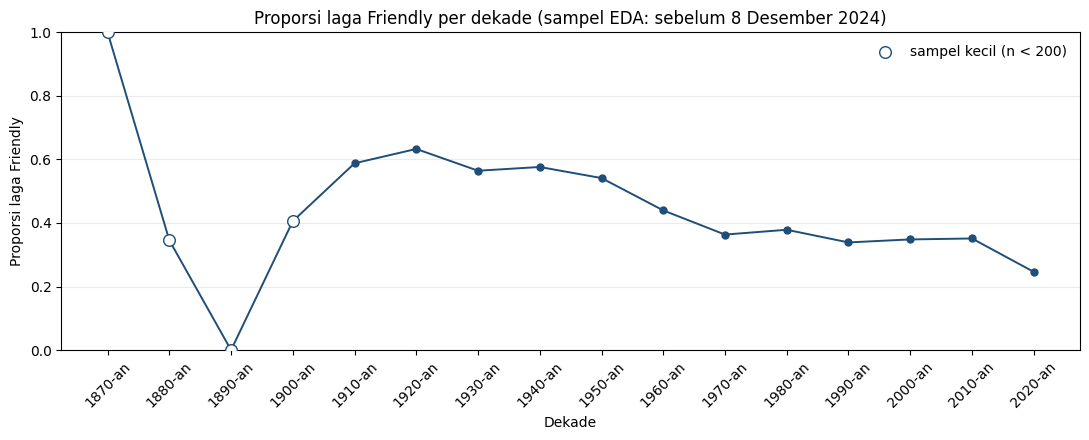

Proporsi Friendly sebelum 1990-an: 0,4383 (n = 17.124)
Proporsi Friendly 1990-an ke atas : 0,3316 (n = 30.969)
Tersimpan: ..\reports\figures\fig_09_proporsi_friendly_per_dekade.png


In [50]:
friendly_dekade = (df_eda.groupby("decade_label")
                   .agg(laga=("result", "size"),
                        proporsi_friendly=("kelompok_turnamen", lambda s: (s == "Friendly").mean())))
kecil_fr = friendly_dekade["laga"] < 200

print("Proporsi laga Friendly per dekade:")
print(friendly_dekade.to_string(float_format=lambda x: fmt(x, 4)))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(friendly_dekade.index, friendly_dekade["proporsi_friendly"], color="#1f4e79", lw=1.4, marker="o", ms=5)
ax.scatter(friendly_dekade.index[kecil_fr], friendly_dekade.loc[kecil_fr, "proporsi_friendly"],
           s=70, facecolors="white", edgecolors="#1f4e79", zorder=3, label="sampel kecil (n < 200)")
ax.set_title("Proporsi laga Friendly per dekade (sampel EDA: sebelum 8 Desember 2024)")
ax.set_xlabel("Dekade")
ax.set_ylabel("Proporsi laga Friendly")
ax.set_ylim(0, 1.0)
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_09_proporsi_friendly_per_dekade.png", dpi=150, bbox_inches="tight")
plt.show()

pra = df_eda[df_eda["year"] < 1990]
pasca = df_eda[df_eda["year"] >= 1990]
print(f"Proporsi Friendly sebelum 1990-an: {fmt((pra['kelompok_turnamen'] == 'Friendly').mean(), 4)} "
      f"(n = {ribuan(len(pra))})")
print(f"Proporsi Friendly 1990-an ke atas : {fmt((pasca['kelompok_turnamen'] == 'Friendly').mean(), 4)} "
      f"(n = {ribuan(len(pasca))})")
print(f"Tersimpan: {FIG_DIR / 'fig_09_proporsi_friendly_per_dekade.png'}")

**Insight:** Proporsi `Friendly` **berubah cukup besar** menurut dekade: **1,0000** pada 1870-an (n = 13, *sampel kecil*) dan **0,0000** pada 1890-an (n = 59, *sampel kecil*), memuncak di **0,6330** pada **1920-an** (n = 831), lalu menurun hingga **0,2462** pada **2020-an** (n = 4.687) — terendah di antara dekade dengan n ≥ 200. Secara agregat: sebelum 1990-an **0,4383** (n = 17.124) versus 1990-an ke atas **0,3316** (n = 30.969). Jadi era modern bukan hanya lebih banyak laganya, tetapi juga **lebih sedikit** porsi laga persahabatan — porsi kualifikasi dan turnamen resmi bertambah.

**Implikasi untuk fitur/model:** komposisi jenis turnamen bergeser menurut era, sehingga model yang dilatih pada seluruh sejarah akan belajar dari campuran turnamen yang berbeda dari periode uji — ini alasan tambahan (di luar volume laga di 4.1) untuk **split temporal** dan untuk **eksperimen ablasi sampel latih era modern** (bagian 6). Kalau bobot per jenis turnamen dipakai, bobot itu harus dihitung dari data latih per periode, bukan sekali untuk seluruh data; dan metrik evaluasi sebaiknya dilaporkan terpisah untuk `Friendly` versus turnamen resmi agar pergeseran komposisi tidak terbaca sebagai perubahan performa model.

## 5. Data Splitting & Feature Engineering

### 5.1 Protokol Split

Section 5 menetapkan **batas data** sebelum ada fitur atau model: baris mana yang boleh dipakai saat pengembangan, dan baris mana yang disimpan sampai evaluasi akhir. Subbagian ini tidak membangun fitur, tidak menyimpan kolom baru, dan tidak melatih model apa pun.

**Aturan pembagian.** `data/processed/matches_merged.csv` dibaca apa adanya, lalu dipecah menurut tanggal:

- `dev` = `date < 2024-12-08` — seluruh pengembangan: EDA lanjutan, pemilihan fitur, tuning, pemilihan threshold.
- `final_test` = `date >= 2024-12-08` — 1.852 baris terakhir, **hanya dihitung jumlah barisnya** pada subbagian ini.

Tanggal 2024-12-08 adalah laga pertama `ASEAN Championship` yang tercatat pada 3.4, sehingga garis ini sekaligus memisahkan turnamen fokus evaluasi dari riwayat yang boleh dipakai untuk belajar.

In [51]:
split_all = pd.read_csv(ROOT / "data" / "processed" / "matches_merged.csv", parse_dates=["date"])
CUTOFF_TEST = pd.Timestamp("2024-12-08")

dev = split_all[split_all["date"] < CUTOFF_TEST].copy()
final_test = split_all[split_all["date"] >= CUTOFF_TEST].copy()

assert len(dev) == 48093, f"dev harus 48.093 baris, ditemukan {len(dev)}"
assert len(final_test) == 1852, f"final_test harus 1.852 baris, ditemukan {len(final_test)}"
assert len(dev) + len(final_test) == len(split_all) == 49945
assert dev["date"].max() < final_test["date"].min()
assert dev.index.intersection(final_test.index).empty

print(f"Baris matches_merged.csv         : {ribuan(len(split_all))}")
print(f"dev       (date <  2024-12-08)   : {ribuan(len(dev))}")
print(f"final_test (date >= 2024-12-08)  : {ribuan(len(final_test))}")
print(f"dev + final_test                 : {ribuan(len(dev) + len(final_test))}")
print()
print(f"Rentang dev        : {dev['date'].min().date()} s/d {dev['date'].max().date()}")
print(f"Rentang final_test : {final_test['date'].min().date()} s/d {final_test['date'].max().date()}")
print(f"Pemisah tanggal    : {dev['date'].max().date()} < {final_test['date'].min().date()} "
      f"(jarak {(final_test['date'].min() - dev['date'].max()).days} hari)")
print(f"Porsi final_test   : {fmt(100 * len(final_test) / len(split_all), 2)}% dari seluruh baris")
print("Assert lolos: ukuran dev/final_test, penjumlahannya, urutan tanggal, dan index tidak beririsan.")

Baris matches_merged.csv         : 49.945
dev       (date <  2024-12-08)   : 48.093
final_test (date >= 2024-12-08)  : 1.852
dev + final_test                 : 49.945

Rentang dev        : 1872-11-30 s/d 2024-11-19
Rentang final_test : 2024-12-08 s/d 2026-10-06
Pemisah tanggal    : 2024-11-19 < 2024-12-08 (jarak 19 hari)
Porsi final_test   : 3,71% dari seluruh baris
Assert lolos: ukuran dev/final_test, penjumlahannya, urutan tanggal, dan index tidak beririsan.


**Cek batas:** `matches_merged.csv` **49.945** baris terbagi habis menjadi `dev` **48.093** dan `final_test` **1.852** (48.093 + 1.852 = 49.945). `dev` berakhir **2024-11-19** dan `final_test` mulai **2024-12-08**, berjarak **19 hari**, sehingga tidak ada tanggal yang masuk dua sisi dan assert `dev.date.max() < final_test.date.min()` lolos. Porsi yang disimpan untuk uji akhir hanya **3,71%** dari seluruh baris.

**Isi `final_test` — hanya jumlah baris.** Tabel berikut tidak memuat distribusi hasil (H/D/A), skor, maupun metrik apa pun: `final_test` hanya dihitung besar kelompoknya, supaya klaim "dibuka sekali" bisa diperiksa tanpa mengintip isinya. Baris konteks di bawah tabel adalah hitungan pada `dev`, bukan pada `final_test`.

In [52]:
ASEAN_NAMA = ["ASEAN Championship", "ASEAN Championship qualification", "FIFA ASEAN Cup"]

ft_counts = final_test["tournament"].value_counts()
tbl_ft = pd.DataFrame({
    "turnamen": ft_counts.index,
    "n_baris": ft_counts.values,
    "persen_final_test": [100 * n / len(final_test) for n in ft_counts.values],
})
tbl_ft["n_baris"] = tbl_ft["n_baris"].map(ribuan)
tbl_ft["persen_final_test"] = tbl_ft["persen_final_test"].map(lambda x: fmt(x, 2) + "%")

print(f"final_test: {ribuan(len(final_test))} baris | "
      f"{final_test['tournament'].nunique()} nama turnamen berbeda")
print("Kolom n_baris = jumlah baris (bukan distribusi hasil/skor/metrik).\n")
print(tbl_ft.to_string(index=False))
assert int(ft_counts.sum()) == len(final_test)

print("\nLima nama ASEAN di final_test (jumlah baris saja):")
for t in ASEAN_NAMA:
    n = int(ft_counts.get(t, 0))
    tanda = "  <- sesuai harapan 52" if (t == "ASEAN Championship" and n == 52) else ""
    print(f"  {t:34s}: {ribuan(n):>6s}{tanda}")

n_asean = int(sum(ft_counts.get(t, 0) for t in ASEAN_NAMA))
n_lain = len(final_test) - n_asean
print(f"  {'subtotal tiga nama ASEAN':34s}: {ribuan(n_asean):>6s} "
      f"({fmt(100 * n_asean / len(final_test), 2)}% final_test)")
print(f"  {'sisanya (35 nama turnamen lain)':34s}: {ribuan(n_lain):>6s} "
      f"({fmt(100 * n_lain / len(final_test), 2)}% final_test)")
assert n_asean + n_lain == len(final_test) == 1852

print("\nKonteks dev (hitungan pada dev, bukan final_test) - lima nama ASEAN:")
for t in ["AFF Championship", "AFF Championship qualification"] + ASEAN_NAMA:
    print(f"  {t:34s}: {ribuan(int((dev['tournament'] == t).sum())):>6s}")
print(f"  {'kualifikasi ASEAN di dev (62 + 2)':34s}: "
      f"{ribuan(int(dev['tournament'].isin(['AFF Championship qualification', 'ASEAN Championship qualification']).sum())):>6s}")

final_test: 1.852 baris | 38 nama turnamen berbeda
Kolom n_baris = jumlah baris (bukan distribusi hasil/skor/metrik).

                                         turnamen n_baris persen_final_test
                     FIFA World Cup qualification     508            27,43%
                                         Friendly     488            26,35%
                              UEFA Nations League     132             7,13%
                                   FIFA World Cup     104             5,62%
                          CONCACAF Nations League      77             4,16%
             African Cup of Nations qualification      60             3,24%
                      AFC Asian Cup qualification      59             3,19%
                               ASEAN Championship      52             2,81%
                           African Cup of Nations      52             2,81%
                                  CONCACAF Series      35             1,89%
                                      FIFA Se

**Isi `final_test` menurut turnamen: 38 nama.** Tiga nama ASEAN yang menjadi fokus berjumlah **66** baris (**3,56%**): `ASEAN Championship` **52** (sesuai harapan dokumen 01), `FIFA ASEAN Cup` **14**, dan `ASEAN Championship qualification` **0** — dua laga bernama itu bertanggal 2024-10-08 s/d 2024-10-15, jadi jatuh di `dev`. Sisanya **1.786** baris (**96,44%**) tersebar di 35 nama lain, terbesar `FIFA World Cup qualification` **508** (**27,43%**) dan `Friendly` **488** (**26,35%**).

Dua hal yang perlu dicatat sejak sekarang: `final_test` **bukan** kumpulan laga ASEAN — hanya **3,56%** isinya dari tiga nama ASEAN, sehingga metrik agregat di Section 8 akan didominasi turnamen lain dan evaluasi ASEAN harus dilaporkan sebagai subset terpisah. Di sisi `dev`, kualifikasi ASEAN berjumlah **64** laga (62 + 2) dan `FIFA ASEAN Cup` **0** laga; `ASEAN Championship` juga **0** karena seluruh laganya berlangsung 2024-12-08 ke atas.

#### Protokol Test Akhir

`final_test` **tidak boleh** dipakai untuk:

- memilih atau menyaring fitur,
- memilih keluarga model,
- tuning hyperparameter,
- memilih threshold keputusan (mis. ambang probabilitas kelas),
- memilih aturan kalibrasi atau jumlah iterasi simulasi,
- mengurutkan kandidat menurut performa.

`final_test` **dibuka satu kali** di **Section 8 (Evaluasi)**, setelah konfigurasi final dibekukan dari hasil validasi. Sampai saat itu satu-satunya angka yang boleh dihitung darinya adalah **jumlah baris per kelompok**, seperti pada tabel di atas — tanpa akurasi, log loss, kalibrasi, maupun distribusi hasil.

**Lapis validasi 1 — per tahun kalender.** Untuk setiap tahun `Y = 2010..2024`: `train` = `dev` dengan `date < Y-01-01`, `val` = `dev` dengan tahun == `Y`. Skema *expanding window*: `train` tumbuh tiap fold, `val` selalu satu tahun penuh, dan tidak ada baris `val` yang masuk `train`.

In [53]:
fold_rows = []
for Y in range(2010, 2025):
    tr = dev[dev["date"] < pd.Timestamp(f"{Y}-01-01")]
    va = dev[dev["date"].dt.year == Y]
    assert len(tr) > 0 and len(va) > 0, f"fold {Y} kosong"
    assert tr["date"].max() < va["date"].min(), f"fold {Y} bocor: train mencapai {tr['date'].max().date()}"
    assert set(tr["match_id"]).isdisjoint(set(va["match_id"])), f"fold {Y} berbagi laga"
    fold_rows.append({"Y": Y, "n_train": len(tr), "n_val": len(va),
                      "train_akhir": tr["date"].max().date(),
                      "val_awal": va["date"].min().date(),
                      "val_akhir": va["date"].max().date()})

fold_y = pd.DataFrame(fold_rows)
tampil_y = fold_y.copy()
tampil_y["n_train"] = tampil_y["n_train"].map(ribuan)
tampil_y["n_val"] = tampil_y["n_val"].map(ribuan)
print(f"{len(fold_y)} fold (Y = 2010..2024), expanding window:")
print(tampil_y.to_string(index=False))

imin_tr, imax_tr = fold_y["n_train"].idxmin(), fold_y["n_train"].idxmax()
imin_va, imax_va = fold_y["n_val"].idxmin(), fold_y["n_val"].idxmax()
print(f"\nn_train: {ribuan(fold_y.loc[imin_tr, 'n_train'])} (Y = {fold_y.loc[imin_tr, 'Y']}) "
      f"s/d {ribuan(fold_y.loc[imax_tr, 'n_train'])} (Y = {fold_y.loc[imax_tr, 'Y']})")
print(f"n_val  : {ribuan(fold_y.loc[imin_va, 'n_val'])} (Y = {fold_y.loc[imin_va, 'Y']}) "
      f"s/d {ribuan(fold_y.loc[imax_va, 'n_val'])} (Y = {fold_y.loc[imax_va, 'Y']})")

total_val = int(fold_y["n_val"].sum())
assert total_val == len(dev[dev["date"].dt.year >= 2010])
print(f"Total baris yang pernah menjadi val: {ribuan(total_val)} "
      f"({fmt(100 * total_val / len(dev), 2)}% dev)")
print("Val antar-fold saling lepas (tiap val satu tahun kalender yang berbeda).")
print("Assert lolos di seluruh fold: train.date.max() < val.date.min() dan match_id tidak beririsan.")

15 fold (Y = 2010..2024), expanding window:
   Y n_train n_val train_akhir   val_awal  val_akhir
2010  33.606   863  2009-12-31 2010-01-02 2010-12-31
2011  34.469 1.119  2010-12-31 2011-01-02 2011-12-30
2012  35.588 1.025  2011-12-30 2012-01-06 2012-12-30
2013  36.613   963  2012-12-30 2013-01-02 2013-12-31
2014  37.576   856  2013-12-31 2014-01-01 2014-12-31
2015  38.432 1.039  2014-12-31 2015-01-04 2015-12-31
2016  39.471   920  2015-12-31 2016-01-03 2016-12-30
2017  40.391   924  2016-12-30 2017-01-04 2017-12-29
2018  41.315   935  2017-12-29 2018-01-02 2018-12-31
2019  42.250 1.156  2018-12-31 2019-01-02 2019-12-29
2020  43.406   356  2019-12-29 2020-01-07 2020-12-09
2021  43.762 1.115  2020-12-09 2021-01-12 2021-12-31
2022  44.877   970  2021-12-31 2022-01-01 2022-12-30
2023  45.847 1.064  2022-12-30 2023-01-02 2023-12-16
2024  46.911 1.182  2023-12-16 2024-01-01 2024-11-19

n_train: 33.606 (Y = 2010) s/d 46.911 (Y = 2024)
n_val  : 356 (Y = 2020) s/d 1.182 (Y = 2024)
Total baris y

**Hasil lapis tahunan: 15 fold.** `n_train` naik dari **33.606** (Y = 2010) ke **46.911** (Y = 2024); `n_val` berkisar **356** (Y = 2020) sampai **1.182** (Y = 2024). Total baris yang pernah menjadi `val` = **14.487** (**30,12%** dari `dev`), dan tiap `val` adalah tahun kalender berbeda sehingga antar-fold saling lepas. Assert `train.date.max() < val.date.min()` dan larangan berbagi `match_id` lolos pada seluruh 15 fold.

Dua catatan yang terbaca langsung dari tabel: (a) `val` Y = 2020 hanya **356** baris, jauh di bawah tahun lain (**856–1.182**), sehingga metrik fold itu paling tidak stabil — penyebabnya tidak diuji di sini dan tidak diklaim; (b) fold 2024 memakai `train` yang berakhir **2023-12-16** dengan `val` sampai **2024-11-19**, jadi fold inilah yang paling menyerupai situasi `final_test`.

**Implikasi:** sebaran metrik lintas 15 fold lebih informatif daripada satu angka validasi, dan hasil fold 2020 sebaiknya dilaporkan terpisah, bukan ikut dirata-ratakan tanpa catatan.

**Lapis validasi 2 — per edisi AFF Championship.** Edisi direkonstruksi dengan aturan 3.4 (jeda antar laga > 180 hari) dan **hanya** memakai `tournament == 'AFF Championship'`. Untuk setiap edisi yang mulai **sejak 2010**: `train` = `dev` dengan `date < tanggal awal edisi`, `val` = seluruh laga edisi itu. `val` tidak memuat laga turnamen lain, sehingga metriknya menjawab pertanyaan yang berbeda: seberapa baik model pada satu edisi utuh.

In [54]:
aff = dev[dev["tournament"] == "AFF Championship"].sort_values("date").reset_index(drop=True)
aff["edisi"] = (aff["date"].diff().dt.days.fillna(0) > 180).cumsum() + 1
assert len(aff) == 291, f"laga AFF Championship di dev harus 291, ditemukan {len(aff)}"

edisi = (aff.groupby("edisi")
            .agg(awal=("date", "min"), akhir=("date", "max"), n_laga=("date", "size"))
            .reset_index())
assert len(edisi) == 14, f"edisi AFF Championship harus 14, ditemukan {len(edisi)}"

edisi_2010 = edisi[edisi["awal"] >= pd.Timestamp("2010-01-01")].reset_index(drop=True)
print(f"Edisi AFF Championship: {len(edisi)} total | mulai sejak 2010: {len(edisi_2010)}")
print("Edisi sebelum 2010 tidak dijadikan fold: rentangnya terlalu jauh dari periode evaluasi.\n")

af_rows = []
for _, e in edisi_2010.iterrows():
    tr = dev[dev["date"] < e["awal"]]
    va = dev[(dev["tournament"] == "AFF Championship") &
             (dev["date"] >= e["awal"]) & (dev["date"] <= e["akhir"])]
    assert len(va) == int(e["n_laga"]), f"edisi {int(e['edisi'])}: val {len(va)} != {int(e['n_laga'])}"
    assert tr["date"].max() < va["date"].min(), f"edisi {int(e['edisi'])} bocor"
    assert set(tr["match_id"]).isdisjoint(set(va["match_id"]))
    af_rows.append({"edisi": int(e["edisi"]), "awal": e["awal"].date(), "akhir": e["akhir"].date(),
                    "n_train": len(tr), "n_val": len(va)})

fold_a = pd.DataFrame(af_rows)
tampil_a = fold_a.copy()
tampil_a["n_train"] = tampil_a["n_train"].map(ribuan)
tampil_a["n_val"] = tampil_a["n_val"].map(ribuan)
print(tampil_a.to_string(index=False))

print(f"\nn_train: {ribuan(fold_a['n_train'].min())} (edisi {fold_a.loc[fold_a['n_train'].idxmin(), 'edisi']}) "
      f"s/d {ribuan(fold_a['n_train'].max())} (edisi {fold_a.loc[fold_a['n_train'].idxmax(), 'edisi']})")
print(f"n_val  : {ribuan(fold_a['n_val'].min())} s/d {ribuan(fold_a['n_val'].max())} "
      f"| total {ribuan(int(fold_a['n_val'].sum()))} laga")
print("Assert lolos di seluruh fold: val = tepat laga edisi itu, train.date.max() < val.date.min(), match_id tidak beririsan.")

print("\nEdisi yang melewati batas tahun kalender:")
for _, e in edisi.iterrows():
    blok = aff[(aff["date"] >= e["awal"]) & (aff["date"] <= e["akhir"])]
    per_tahun = blok["date"].dt.year.value_counts().sort_index()
    if len(per_tahun) > 1:
        rincian = ", ".join(f"{int(y)}: {int(n)} laga" for y, n in per_tahun.items())
        print(f"  edisi {int(e['edisi'])} ({e['awal'].date()} s/d {e['akhir'].date()}) -> {rincian}")

Edisi AFF Championship: 14 total | mulai sejak 2010: 7
Edisi sebelum 2010 tidak dijadikan fold: rentangnya terlalu jauh dari periode evaluasi.



 edisi       awal      akhir n_train n_val
     8 2010-12-01 2010-12-29  34.413    18
     9 2012-11-24 2012-12-22  36.507    18
    10 2014-11-22 2014-12-20  38.397    18
    11 2016-11-19 2016-12-17  40.365    18
    12 2018-11-08 2018-12-15  42.061    26
    13 2021-12-05 2022-01-01  44.829    26
    14 2022-12-20 2023-01-16  45.827    26

n_train: 34.413 (edisi 8) s/d 45.827 (edisi 14)
n_val  : 18 s/d 26 | total 150 laga
Assert lolos di seluruh fold: val = tepat laga edisi itu, train.date.max() < val.date.min(), match_id tidak beririsan.

Edisi yang melewati batas tahun kalender:
  edisi 5 (2004-12-07 s/d 2005-01-16) -> 2004: 22 laga, 2005: 5 laga
  edisi 13 (2021-12-05 s/d 2022-01-01) -> 2021: 25 laga, 2022: 1 laga
  edisi 14 (2022-12-20 s/d 2023-01-16) -> 2022: 16 laga, 2023: 10 laga


**Hasil lapis ASEAN: 7 fold dari 14 edisi.** Edisi yang mulai sejak 2010 adalah 2010, 2012, 2014, 2016, 2018, 2021, dan 2022. `n_val` = **18** pada empat edisi pertama dan **26** pada tiga edisi terakhir (total **150** laga `val`); `n_train` naik **34.413** (edisi 8) menjadi **45.827** (edisi 14). Assert lolos di semua fold: `val` tepat sama dengan laga edisi itu, `train.date.max() < val.date.min()`, dan tidak ada `match_id` yang dipakai di dua sisi.

Lapis ini menutup celah yang tidak tertangkap lapis tahunan: **edisi 2021** berlangsung **2021-12-05 s/d 2022-01-01**, jadi **25** laganya masuk `val` 2021 sementara **1** laga (2022-01-01) masuk `val` 2022 — satu edisi terbelah dua fold, dan sebagian laga edisi itu justru ikut menjadi `train` fold berikutnya. **Edisi 14** (2022-12-20 s/d 2023-01-16) juga melewati batas tahun dengan **16** laga di 2022 dan **10** laga di 2023, sehingga pada lapis tahunan ia pun terbelah antara `val` 2022 dan `val` 2023; hanya edisi 5 (2004–2005) yang terbelah di luar rentang fold, karena tidak dijadikan fold. Pada lapis ASEAN seluruh edisi diuji utuh.

**Implikasi:** dua lapis mengukur hal berbeda — lapis tahunan mengukur stabilitas pada 15 titik waktu dengan komposisi turnamen yang beragam, lapis ASEAN mengukur satu turnamen utuh dengan 11 tim khas Asia Tenggara. Keputusan model sebaiknya tidak bergantung pada satu lapis saja, dan selisih besar antara keduanya adalah informasi, bukan gangguan.

#### Keputusan yang mengikat Section 6–8

1. **Kualifikasi ASEAN → data latih saja.** **64** laga kualifikasi ada di `dev` (`AFF Championship qualification` 62 + `ASEAN Championship qualification` 2) dan **0** di `final_test`. Kualifikasi tetap dipakai sebagai baris `train` karena menambah riwayat pertemuan tim ASEAN, tetapi tidak pernah menjadi `val` ASEAN dan tidak pernah menjadi target evaluasi — komposisi pesertanya berbeda dari putaran final. Pada lapis ASEAN, `val` hanya `tournament == 'AFF Championship'`.
2. **`FIFA ASEAN Cup` tidak dipakai.** Nama turnamen ini tidak dipakai untuk latih, validasi, maupun evaluasi: peserta dan statusnya belum pasti (3.4, catatan `[perlu diverifikasi sumber luar]`), dan `dev` tidak memuat satu laganya. **14** laganya tetap berada di `final_test` dan hanya terhitung sebagai baris pada 5.1; di Section 8 baris tersebut dikeluarkan dari setiap metrik yang dilaporkan.
3. **Dua lapis validasi, bukan satu.** Lapis tahunan (2010–2024) mengukur stabilitas lintas waktu dan mencakup **14.487** baris `val`; lapis ASEAN mengukur satu edisi utuh tanpa terbelah batas tahun. Keduanya hanya memakai data sebelum periode uji sebagai `train`, sehingga tidak ada kebocoran waktu.
4. **Tidak ada baris yang dihapus.** Semua **48.093** baris `dev` tetap dipakai; pembatasan hanya berupa pemilihan `train`/`val` per fold, bukan penyaringan data.

**Definisi split disimpan** ke `data/processed/split_definition.json`: hanya tanggal batas dan rentang tiap fold, ditambah `n_train`/`n_val` sebagai ringkasan. **Tidak ada satu baris data pun** yang ditulis ke berkas itu, sehingga isinya tidak bisa dipakai untuk mengintip `final_test`.

In [55]:
import json

split_def = {
    "versi": 1,
    "sumber": "data/processed/matches_merged.csv",
    "cutoff_test": "2024-12-08",
    "aturan": {
        "dev": "date < 2024-12-08",
        "final_test": "date >= 2024-12-08",
        "pemakaian_final_test": "hanya jumlah baris pada 5.1; metrik dibuka sekali di Section 8",
        "fold_tahunan": "Y = 2010..2024; train = dev dengan date < Y-01-01; val = dev dengan tahun == Y",
        "fold_asean": "edisi AFF Championship (jeda > 180 hari) yang mulai >= 2010; train = dev dengan date < awal edisi; val = laga edisi",
        "fifa_asean_cup": "tidak dipakai untuk latih/validasi/evaluasi",
        "kualifikasi_asean": "data latih saja",
    },
    "dev": {
        "tanggal_awal": str(dev["date"].min().date()),
        "tanggal_akhir": str(dev["date"].max().date()),
        "n_baris": int(len(dev)),
    },
    "final_test": {
        "tanggal_awal": str(final_test["date"].min().date()),
        "tanggal_akhir": str(final_test["date"].max().date()),
        "n_baris": int(len(final_test)),
    },
    "fold_validasi_tahunan": [
        {"Y": int(r["Y"]),
         "train_tanggal_akhir": str(r["train_akhir"]),
         "val_tanggal_awal": str(r["val_awal"]),
         "val_tanggal_akhir": str(r["val_akhir"]),
         "n_train": int(r["n_train"]), "n_val": int(r["n_val"])}
        for r in fold_y.to_dict("records")
    ],
    "fold_validasi_asean": [
        {"edisi": int(r["edisi"]), "turnamen": "AFF Championship",
         "val_tanggal_awal": str(r["awal"]), "val_tanggal_akhir": str(r["akhir"]),
         "train_tanggal_akhir": str(dev.loc[dev["date"] < pd.Timestamp(r["awal"]), "date"].max().date()),
         "n_train": int(r["n_train"]), "n_val": int(r["n_val"])}
        for r in fold_a.to_dict("records")
    ],
}

SPLIT_JSON = ROOT / "data" / "processed" / "split_definition.json"
with open(SPLIT_JSON, "w", encoding="utf-8") as f:
    json.dump(split_def, f, indent=2, ensure_ascii=False)
    f.write("\n")

ulang = json.loads(SPLIT_JSON.read_text(encoding="utf-8"))
assert ulang == split_def
assert len(ulang["fold_validasi_tahunan"]) == 15 and len(ulang["fold_validasi_asean"]) == 7
assert ulang["dev"]["n_baris"] + ulang["final_test"]["n_baris"] == 49945

print(f"Tersimpan: {SPLIT_JSON} ({SPLIT_JSON.stat().st_size} byte)")
print("Kunci utama:", list(split_def.keys()))
print(f"fold_validasi_tahunan: {len(split_def['fold_validasi_tahunan'])} entri | "
      f"fold_validasi_asean: {len(split_def['fold_validasi_asean'])} entri")
print("\nContoh entri fold tahunan (pertama dan terakhir):")
print(json.dumps([split_def["fold_validasi_tahunan"][0],
                  split_def["fold_validasi_tahunan"][-1]], indent=2, ensure_ascii=False))
print("\nContoh entri fold ASEAN (pertama dan terakhir):")
print(json.dumps([split_def["fold_validasi_asean"][0],
                  split_def["fold_validasi_asean"][-1]], indent=2, ensure_ascii=False))
print("\nVerifikasi: berkas dibaca ulang, isinya identik dengan objek di memori, dan tidak memuat baris data.")

Tersimpan: ..\data\processed\split_definition.json (5738 byte)
Kunci utama: ['versi', 'sumber', 'cutoff_test', 'aturan', 'dev', 'final_test', 'fold_validasi_tahunan', 'fold_validasi_asean']
fold_validasi_tahunan: 15 entri | fold_validasi_asean: 7 entri

Contoh entri fold tahunan (pertama dan terakhir):
[
  {
    "Y": 2010,
    "train_tanggal_akhir": "2009-12-31",
    "val_tanggal_awal": "2010-01-02",
    "val_tanggal_akhir": "2010-12-31",
    "n_train": 33606,
    "n_val": 863
  },
  {
    "Y": 2024,
    "train_tanggal_akhir": "2023-12-16",
    "val_tanggal_awal": "2024-01-01",
    "val_tanggal_akhir": "2024-11-19",
    "n_train": 46911,
    "n_val": 1182
  }
]

Contoh entri fold ASEAN (pertama dan terakhir):
[
  {
    "edisi": 8,
    "turnamen": "AFF Championship",
    "val_tanggal_awal": "2010-12-01",
    "val_tanggal_akhir": "2010-12-29",
    "train_tanggal_akhir": "2010-11-30",
    "n_train": 34413,
    "n_val": 18
  },
  {
    "edisi": 14,
    "turnamen": "AFF Championship",
    "

**Berkas tersimpan:** `data/processed/split_definition.json` memuat `cutoff_test`, rentang `dev` dan `final_test`, **15** fold tahunan, dan **7** fold ASEAN, ditambah aturan pemakaian tiap kelompok. Section 6–8 sebaiknya membaca berkas ini (atau menghitung ulang dengan aturan yang sama) agar batas `train`/`val`/`final_test` tidak bergeser diam-diam antar sesi.

**Ringkasan 5.1.** Batas keras **2024-12-08** membagi **48.093** baris `dev` dan **1.852** baris `final_test`; `final_test` hanya dihitung jumlah barisnya di sini dan dibuka sekali di Section 8. Validasi memakai dua lapis: **15** fold tahunan (2010–2024, **14.487** baris `val`) dan **7** fold edisi AFF Championship sejak 2010 (**150** laga `val`). Kualifikasi ASEAN menjadi data latih saja, `FIFA ASEAN Cup` tidak dipakai, dan seluruh definisi tersimpan sebagai tanggal di `split_definition.json`.

### 5.2 Rating Elo

Subbagian ini membangun **fitur pra-laga berbasis Elo** untuk seluruh `dev` (**48.093** laga, `date < 2024-12-08`) lalu memeriksa apakah fitur itu membawa sinyal yang masuk akal. **`final_test` tidak dihitung dan tidak ditampilkan sama sekali** di sini — tidak ada satu angka pun yang berasal dari tanggal 2024-12-08 ke atas. Tidak ada model prediksi, tidak ada penyetelan parameter, dan parameter Elo masih nilai default.

**Kode dan aturan.** Implementasinya ada di `src/features/elo.py` (`build_elo`), diuji oleh `tests/test_elo.py`, dan parameternya dibaca dari `configs/config.yaml` (`k: 30`, `home_adv: 100`, `init: 1500`, `use_goal_mult: true` — default awal, belum disetel).

```
urutkan date lalu match_id; proses per kelompok tanggal
dr       = (R_home - R_away) + home_adv   (home_adv hanya bila neutral == False)
E_home   = 1 / (1 + 10 ** (-dr / 400))
S_home   = 1 (menang) | 0,5 (seri) | 0 (kalah)
G        = 1 (|selisih| <= 1) | 1,5 (2) | (11 + n) / 8 (n >= 3); G = 1 bila use_goal_mult = False
delta    = k * G * (S_home - E_home);  R_home += delta;  R_away -= delta
```

Dua konsekuensi aturan ini yang dipakai di bawah: (a) semua laga pada **tanggal yang sama** memakai rating sebelum tanggal itu, sehingga laga di hari yang sama tidak saling memengaruhi; (b) `n_prev_home` / `n_prev_away` adalah jumlah laga tim **sebelum tanggal laga**, jadi dua laga pada tanggal yang sama tidak menambah `n_prev` satu sama lain. `elo_diff = elo_home_pre - elo_away_pre`, **tanpa** `home_adv`, supaya kolom itu murni selisih kekuatan.

In [56]:
import sys

import yaml


def fmt_rating(x, d=1):
    """Format rating: pemisah ribuan titik, desimal koma (mis. 2.231,6)."""
    return f"{x:,.{d}f}".replace(",", "#").replace(".", ",").replace("#", ".")

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src" / "features" / "elo.py").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src" / "features" / "elo.py").exists(), "src/features/elo.py tidak ditemukan dari cwd"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.elo import build_elo

with open(PROJECT_ROOT / "configs" / "config.yaml", encoding="utf-8") as f:
    ELO_CFG = yaml.safe_load(f)["elo"]

KOLOM_ELO = ["match_id", "date", "home_team", "away_team", "home_score", "away_score", "neutral"]
BATAS_TEST = pd.Timestamp("2024-12-08")

assert len(dev) == 48093, f"dev harus 48.093 baris, ditemukan {len(dev)}"
assert dev["date"].max() < BATAS_TEST, f"dev memuat tanggal >= {BATAS_TEST.date()}"

elo_input = dev[KOLOM_ELO].copy()
assert elo_input["date"].max() < BATAS_TEST  # dicek tepat sebelum build_elo
print(f"Assert lolos sebelum build_elo: dev.date.max() = {elo_input['date'].max().date()} < {BATAS_TEST.date()}")
print(f"Parameter dari configs/config.yaml (bagian elo): {ELO_CFG}")

fitur_elo, rating_akhir = build_elo(
    elo_input,
    k=ELO_CFG["k"],
    home_adv=ELO_CFG["home_adv"],
    init=ELO_CFG["init"],
    use_goal_mult=ELO_CFG["use_goal_mult"],
)

assert len(fitur_elo) == len(elo_input) == 48093
assert fitur_elo["match_id"].is_unique
assert not fitur_elo.isna().any().any()
assert set(fitur_elo["match_id"]) == set(elo_input["match_id"])
assert abs(float(rating_akhir.sum()) - ELO_CFG["init"] * len(rating_akhir)) < 1e-6

OUT_ELO = PROJECT_ROOT / "data" / "processed" / "features_elo_dev.csv"
fitur_elo.to_csv(OUT_ELO, index=False)

elo_min = min(fitur_elo["elo_home_pre"].min(), fitur_elo["elo_away_pre"].min())
elo_maks = max(fitur_elo["elo_home_pre"].max(), fitur_elo["elo_away_pre"].max())
print(f"\nfitur   : {ribuan(len(fitur_elo))} baris | match_id unik | NaN {int(fitur_elo.isna().sum().sum())}")
print(f"tim     : {ribuan(len(rating_akhir))} nama pernah muncul | jumlah rating akhir "
      f"{ribuan(round(rating_akhir.sum()))} (= {ribuan(ELO_CFG['init'])} x {ribuan(len(rating_akhir))})")
print(f"rating  : {fmt_rating(elo_min)} s/d {fmt_rating(elo_maks)} (pra-laga, kedua sisi)")
print(f"n_prev  : maks {int(fitur_elo['n_prev_home'].max())} (home) dan "
      f"{int(fitur_elo['n_prev_away'].max())} (away)")
print(f"tersimpan: {OUT_ELO.name} ({OUT_ELO.stat().st_size:,} byte)".replace(",", "."))
print("\nTiga baris pertama:")
print(fitur_elo.head(3).to_string(index=False))

Assert lolos sebelum build_elo: dev.date.max() = 2024-11-19 < 2024-12-08
Parameter dari configs/config.yaml (bagian elo): {'k': 30, 'home_adv': 100, 'init': 1500, 'use_goal_mult': True}



fitur   : 48.093 baris | match_id unik | NaN 0
tim     : 335 nama pernah muncul | jumlah rating akhir 502.500 (= 1.500 x 335)
rating  : 821,5 s/d 2.231,6 (pra-laga, kedua sisi)
n_prev  : maks 1086 (home) dan 1084 (away)
tersimpan: features_elo_dev.csv (3.391.247 byte)

Tiga baris pertama:
 match_id  elo_home_pre  elo_away_pre   elo_diff  n_prev_home  n_prev_away
        0   1500.000000   1500.000000   0.000000            0            0
        1   1504.201950   1495.798050   8.403900            1            1
        2   1480.099033   1519.900967 -39.801933            2            2


**Build selesai pada `dev` saja.** Assert `date.max() < 2024-12-08` dipanggil tepat sebelum `build_elo`, dan hanya enam kolom input yang diserahkan. Hasilnya **48.093** baris (satu per laga), `match_id` unik, **0 NaN**, dan seluruh `match_id` `dev` terpakai. Ada **335** nama tim dengan jumlah rating akhir **502.500** = 1.500 × 335 — sesuai sifat zero-sum (setiap `delta` menambah satu tim dan mengurangi tim lain). Rentang rating pra-laga **821,5** sampai **2.231,6**. Fitur tersimpan di `data/processed/features_elo_dev.csv`.

**Ringkasan per dekade.** Untuk laga dengan `n_prev >= 10` pada **kedua** tim, tabel berikut memuat min/median/maks `elo_home_pre` dan `elo_away_pre`, ditambah jumlah laga *cold start* (salah satu tim `n_prev < 10`) per dekade. Statistik rating hanya dihitung pada laga yang sampelnya cukup; hitungan cold start memakai **seluruh** laga dekade itu.

In [57]:
df_elo = dev.merge(fitur_elo, on="match_id", how="left", validate="one_to_one")
assert len(df_elo) == len(dev) and df_elo["elo_home_pre"].notna().all()

df_elo["decade"] = (df_elo["date"].dt.year // 10) * 10
df_elo["decade_label"] = df_elo["decade"].astype(str) + "-an"
df_elo["n_prev_min"] = df_elo[["n_prev_home", "n_prev_away"]].min(axis=1)
df_elo["sampel_cukup"] = df_elo["n_prev_min"] >= 10

baris_dekade = []
for dekade, g in df_elo.groupby("decade_label", sort=True):
    cukup = g[g["sampel_cukup"]]
    cold = int((~g["sampel_cukup"]).sum())
    ada = len(cukup) > 0
    baris_dekade.append({
        "dekade": dekade,
        "n_laga": ribuan(len(g)),
        "n_cukup": ribuan(len(cukup)),
        "home_min": fmt_rating(cukup["elo_home_pre"].min()) if ada else "-",
        "home_median": fmt_rating(cukup["elo_home_pre"].median()) if ada else "-",
        "home_maks": fmt_rating(cukup["elo_home_pre"].max()) if ada else "-",
        "away_min": fmt_rating(cukup["elo_away_pre"].min()) if ada else "-",
        "away_median": fmt_rating(cukup["elo_away_pre"].median()) if ada else "-",
        "away_maks": fmt_rating(cukup["elo_away_pre"].max()) if ada else "-",
        "cold_start": ribuan(cold),
        "pct_cold": fmt(100 * cold / len(g), 1) + "%",
    })
tabel_dekade = pd.DataFrame(baris_dekade)

with pd.option_context("display.width", 260):
    print("Ringkasan Elo per dekade (statistik rating hanya pada laga dengan n_prev >= 10 kedua tim):")
    print(tabel_dekade.to_string(index=False))

n_cukup = int(df_elo["sampel_cukup"].sum())
n_cold = len(df_elo) - n_cukup
print(f"\nTotal: {ribuan(n_cukup)} laga memenuhi n_prev >= 10 kedua tim "
      f"({fmt(100 * n_cukup / len(df_elo), 2)}% dev) | cold start {ribuan(n_cold)} "
      f"({fmt(100 * n_cold / len(df_elo), 2)}% dev)")
print("Baris '-' berarti n_cukup = 0: tidak ada laga dekade itu dengan kedua tim n_prev >= 10.")
cold_awal = int((~df_elo.loc[df_elo["decade"] <= 1960, "sampel_cukup"]).sum())
print(f"cold start dari dekade <= 1960: {ribuan(cold_awal)} dari {ribuan(n_cold)} "
      f"({fmt(100 * cold_awal / n_cold, 1)}% dari seluruh cold start)")

Ringkasan Elo per dekade (statistik rating hanya pada laga dengan n_prev >= 10 kedua tim):
 dekade n_laga n_cukup home_min home_median home_maks away_min away_median away_maks cold_start pct_cold
1870-an     13       0        -           -         -        -           -         -         13   100,0%
1880-an     55      37  1.229,6     1.547,2   1.772,5  1.231,6     1.501,9   1.762,3         18    32,7%
1890-an     59      59  1.185,4     1.677,3   1.788,0  1.209,6     1.652,9   1.783,1          0     0,0%
1900-an    138      73  1.218,4     1.506,5   1.810,6  1.202,9     1.593,9   1.841,7         65    47,1%
1910-an    330     213  1.268,7     1.531,8   1.814,5  1.259,9     1.535,7   1.852,7        117    35,5%
1920-an    831     629  1.263,8     1.550,0   1.774,1  1.261,4     1.545,4   1.774,1        202    24,3%
1930-an  1.079     947  1.133,6     1.515,4   1.891,6  1.105,4     1.529,3   1.909,1        132    12,2%
1940-an    833     716  1.129,8     1.542,5   1.870,6  1.149,5     1.

**Pola per dekade.** Dekade **1880-an sampai 2010-an** punya median `elo_home_pre` di kisaran **1.506,5** (1900-an) sampai **1.677,3** (1890-an), sedangkan **2020-an** **1.611,9** — median relatif datar. Yang berubah adalah **sebaran**: nilai minimum turun dari **1.185,4** (1890-an) ke **828,8** (2020-an) dan maksimum naik dari **1.772,5** (1880-an) ke **2.227,2** (2020-an), dengan rentang gabungan kedua sisi **821,5 – 2.231,6**. *Cold start* paling sering pada **1900-an** (**65** dari **138** laga, **47,1%**) dan **1880-an** (**32,7%**), lalu menurun: **14,0%** (1940-an), **4,7%** (1990-an), **2,3%** (2000-an), **2,7%** (2010-an), dan **0,6%** (2020-an). Dekade **1870-an** tidak muncul di statistik rating karena **0** dari **13** laganya memenuhi `n_prev >= 10`.

**Implikasi untuk fitur/model:** filter `n_prev >= 10` membuang **2.407** laga (**5,00%** `dev`); **1.214** di antaranya (**50,4%**) berasal dari dekade **1870-an–1960-an**. Karena porsi cold start turun dari **47,1%** (1900-an) ke **0,6%** (2020-an), filter ini **tidak** setara antar-era — model yang memakainya efektif belajar dari data yang berbeda komposisinya di tiap dekade. Elo juga makin melebar antar-era, jadi skala `elo_diff` pada era lama tidak sebanding dengan era modern; bila fitur ini dipakai lintas era, interaksi dengan `decade`/`year` perlu dipertimbangkan. Sebaliknya, **95,00%** laga `dev` punya riwayat cukup, jadi Elo praktis tersedia untuk hampir semua baris.

**Cek kewajaran.** Dua daftar berikut hanya untuk memeriksa apakah urutan rating masuk akal secara deskriptif: **15 rating tertinggi** di akhir `dev`, dan rating **11 peserta `AFF Championship`**. Ini bukan dasar menyetel parameter, dan tidak ada kesimpulan yang memakai pengetahuan di luar angka yang tampil.

In [58]:
top15 = rating_akhir.head(15)
print(f"15 rating tertinggi di akhir dev (dari {ribuan(len(rating_akhir))} nama tim):")
for posisi, (tim, nilai) in enumerate(top15.items(), start=1):
    print(f"{posisi:2d}. {tim:14s} {fmt_rating(nilai):>8s}")

peserta_aff = sorted(set(dev.loc[dev["tournament"] == "AFF Championship", "home_team"]) |
                     set(dev.loc[dev["tournament"] == "AFF Championship", "away_team"]))
assert len(peserta_aff) == 11, f"peserta AFF Championship harus 11 tim, ditemukan {len(peserta_aff)}"
peringkat = {tim: i + 1 for i, tim in enumerate(rating_akhir.index)}

aff = rating_akhir.reindex(peserta_aff).sort_values(ascending=False)
print(f"\nRating 11 peserta AFF Championship di akhir dev (peringkat dari {ribuan(len(rating_akhir))} tim):")
for tim, nilai in aff.items():
    print(f"{tim:14s} {fmt_rating(nilai):>8s}   peringkat {peringkat[tim]:3d}")

print(f"\ntertinggi AFF: {aff.index[0]} {fmt_rating(aff.iloc[0])} (peringkat {peringkat[aff.index[0]]}) | "
      f"terendah: {aff.index[-1]} {fmt_rating(aff.iloc[-1])} (peringkat {peringkat[aff.index[-1]]})")
print(f"selisih tertinggi-terendah di antara peserta AFF: {fmt_rating(aff.iloc[0] - aff.iloc[-1])}")
print(f"peserta AFF di antara 15 teratas: {sum(t in set(peserta_aff) for t in top15.index)}")
print(f"rating terendah 15 teratas ({fmt_rating(top15.iloc[-1])}) vs tertinggi AFF ({fmt_rating(aff.iloc[0])})")
print(f"\nperingkat 1: {rating_akhir.index[0]} {fmt_rating(rating_akhir.iloc[0])} | "
      f"jarak tertinggi AFF ke peringkat 1: {fmt_rating(rating_akhir.iloc[0] - aff.iloc[0])}")
print(f"rentang elo_diff seluruh dev: {fmt_rating(fitur_elo['elo_diff'].min())} s/d "
      f"{fmt_rating(fitur_elo['elo_diff'].max())}")

15 rating tertinggi di akhir dev (dari 335 nama tim):
 1. Spain           2.175,3
 2. Argentina       2.159,9
 3. Brazil          2.075,5
 4. France          2.069,2
 5. Colombia        2.061,3
 6. England         2.033,4
 7. Portugal        2.030,6
 8. Uruguay         2.008,0
 9. Germany         1.999,3
10. Netherlands     1.992,4
11. Italy           1.985,9
12. Japan           1.978,8
13. Ecuador         1.958,8
14. Croatia         1.951,5
15. Iran            1.937,7

Rating 11 peserta AFF Championship di akhir dev (peringkat dari 335 tim):
Thailand        1.549,7   peringkat 122
Indonesia       1.501,7   peringkat 164
Malaysia        1.484,0   peringkat 182
Vietnam         1.411,1   peringkat 234
Singapore       1.272,5   peringkat 281
Philippines     1.260,9   peringkat 285
Myanmar         1.108,3   peringkat 309
Cambodia        1.048,5   peringkat 317
Brunei            934,1   peringkat 329
Laos              930,7   peringkat 332
Timor-Leste       925,5   peringkat 333

tertinggi 

**Hasil cek kewajaran.** 15 teratas diisi **Spain 2.175,3**, **Argentina 2.159,9**, **Brazil 2.075,5**, **France 2.069,2**, **Colombia 2.061,3**, lalu England, Portugal, Uruguay, Germany, Netherlands, Italy, Japan, Ecuador, Croatia, dan **Iran 1.937,7** sebagai batas bawah daftar. Di antara 11 peserta `AFF Championship`, urutannya **Thailand 1.549,7** (peringkat **122** dari **335**) → Indonesia 1.501,7 (164) → Malaysia 1.484,0 (182) → Vietnam 1.411,1 (234) → Singapore 1.272,5 (281) → Philippines 1.260,9 (285) → Myanmar 1.108,3 (309) → Cambodia 1.048,5 (317) → Brunei 934,1 (329) → Laos 930,7 (332) → **Timor-Leste 925,5 (333)**. **Tidak ada** peserta AFF di 15 teratas, dan rating terendah 15 teratas (**1.937,7**) masih di atas peserta AFF tertinggi (**1.549,7**).

**Makna untuk model:** rentang rating di antara peserta AFF (**624,2** poin, dari Thailand 1.549,7 ke Timor-Leste 925,5) jauh lebih sempit daripada rentang `elo_diff` seluruh `dev` (**-1.141,7** sampai **1.106,4**), dan hampir sama dengan jarak Thailand ke peringkat 1 (**625,6** poin ke Spain 2.175,3). Artinya `elo_diff` pada laga sesama ASEAN akan terkonsentrasi di rentang sempit, sehingga sinyal Elo untuk laga ASEAN kemungkinan lebih lemah daripada laga antarbenua, dan evaluasi pada subset ASEAN (Section 8) tidak boleh mengasumsikan kekuatan sinyal yang sama. Ini tetap hanya cek kewajaran: urutan di atas tidak membuktikan kualitas tim, hanya konsistensi rating dengan hasil yang tercatat.

**Sinyal: proporsi H/D/A per `elo_diff`.** Hanya laga dengan `n_prev >= 10` pada kedua tim yang dipakai (**45.686** laga), dibagi ke delapan bin `elo_diff` dengan batas kiri tertutup (`[-200, -100)` berarti -200 ≤ `elo_diff` < -100), terpisah untuk `neutral=False` dan `neutral=True`. Angka dan grafik di bawah hanya dari `dev`.

neutral = False (n = 33.957):


                  n    H_%    D_%    A_%
bin_elo                                 
< -200        5.892  17,3%  23,7%  59,0%
[-200, -100)  4.833  32,2%  28,8%  39,0%
[-100, -50)   2.814  41,5%  29,1%  29,4%
[-50, 0)      3.138  46,6%  29,6%  23,9%
[0, 50)       3.110  53,9%  26,0%  20,1%
[50, 100)     2.906  59,2%  25,2%  15,6%
[100, 200)    4.893  67,4%  21,1%  11,5%
>= 200        6.371  82,7%  12,3%   4,9%



neutral = True (n = 11.729):
                  n    H_%    D_%    A_%
bin_elo                                 
< -200        1.477  10,1%  16,2%  73,7%
[-200, -100)  1.582  22,4%  26,9%  50,6%
[-100, -50)   1.023  30,0%  24,8%  45,2%
[-50, 0)      1.106  34,6%  28,2%  37,2%
[0, 50)       1.187  42,8%  27,6%  29,6%
[50, 100)     1.230  50,1%  25,0%  25,0%
[100, 200)    1.984  57,3%  25,3%  17,5%
>= 200        2.140  76,4%  16,0%   7,6%



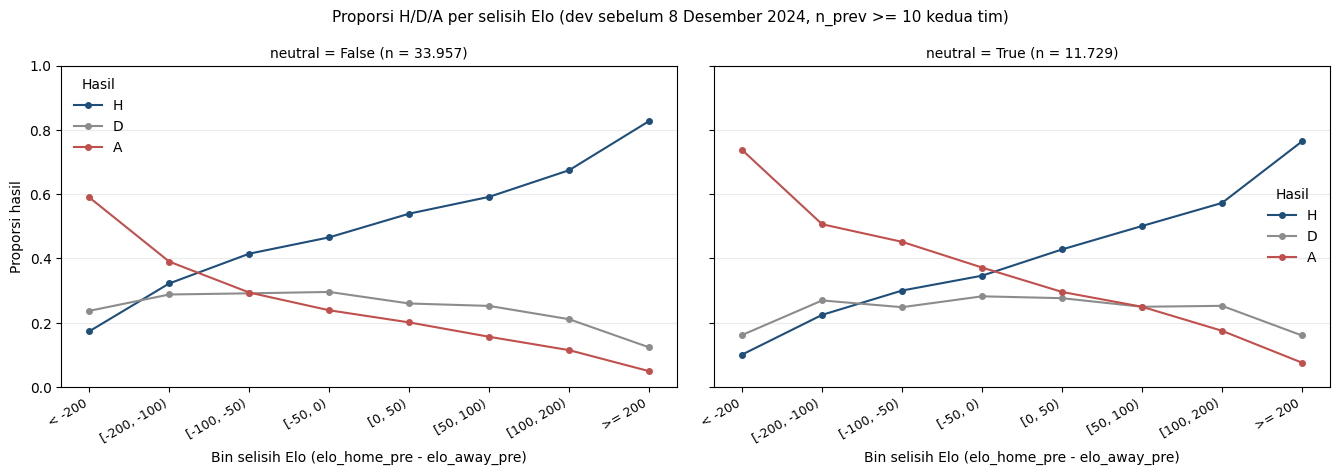

tersimpan: fig_10_proporsi_hda_per_bin_elo_diff.png


In [59]:
BIN_EDGES = [-np.inf, -200, -100, -50, 0, 50, 100, 200, np.inf]
BIN_LABELS = ["< -200", "[-200, -100)", "[-100, -50)", "[-50, 0)",
              "[0, 50)", "[50, 100)", "[100, 200)", ">= 200"]

sampel = df_elo[df_elo["sampel_cukup"]].copy()
sampel["bin_elo"] = pd.cut(sampel["elo_diff"], bins=BIN_EDGES, labels=BIN_LABELS, right=False)
assert sampel["bin_elo"].notna().all()
assert len(sampel) == 45686


def tabel_per_bin(sub):
    hitung = (sub.groupby("bin_elo", observed=False)["result"]
                 .value_counts().unstack(fill_value=0)
                 .reindex(index=BIN_LABELS, columns=["H", "D", "A"], fill_value=0))
    total = hitung.sum(axis=1)
    keluaran = pd.DataFrame({"n": [ribuan(v) for v in total]}, index=total.index)
    for kolom in ["H", "D", "A"]:
        keluaran[kolom + "_%"] = [fmt(100 * v / t, 1) + "%" if t else "-"
                                  for v, t in zip(hitung[kolom], total)]
    return keluaran


for nilai_neutral in [False, True]:
    sub = sampel[sampel["neutral"] == nilai_neutral]
    print(f"neutral = {nilai_neutral} (n = {ribuan(len(sub))}):")
    print(tabel_per_bin(sub).to_string())
    print()

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for ax, nilai_neutral in zip(axes, [False, True]):
    sub = sampel[sampel["neutral"] == nilai_neutral]
    for kolom, warna in [("H", "#1f4e79"), ("D", "#8c8c8c"), ("A", "#c0504d")]:
        proporsi = (sub.groupby("bin_elo", observed=False)["result"]
                       .apply(lambda s, k=kolom: (s == k).mean())
                       .reindex(BIN_LABELS))
        ax.plot(range(len(BIN_LABELS)), proporsi.values, marker="o", ms=4, lw=1.5,
                color=warna, label=kolom)
    ax.set_title(f"neutral = {nilai_neutral} (n = {ribuan(len(sub))})", fontsize=10)
    ax.set_xticks(range(len(BIN_LABELS)))
    ax.set_xticklabels(BIN_LABELS, rotation=30, ha="right", fontsize=9)
    ax.set_xlabel("Bin selisih Elo (elo_home_pre - elo_away_pre)")
    ax.set_ylim(0, 1.0)
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, title="Hasil")
axes[0].set_ylabel("Proporsi hasil")
fig.suptitle("Proporsi H/D/A per selisih Elo (dev sebelum 8 Desember 2024, n_prev >= 10 kedua tim)",
             fontsize=11)
fig.tight_layout()
FIG_ELO = FIG_DIR / "fig_10_proporsi_hda_per_bin_elo_diff.png"
fig.savefig(FIG_ELO, dpi=150, bbox_inches="tight")
plt.show()
print(f"tersimpan: {FIG_ELO.name}")

**Sinyal terlihat kuat dan monoton.** Pada `neutral=False`, proporsi H naik dari **17,3%** (`elo_diff` < -200, n = 5.892) ke **82,7%** (`elo_diff` ≥ 200, n = 6.371), sementara A turun dari **59,0%** ke **4,9%** dan D dari **23,7%** ke **12,3%**. Pada `neutral=True` arahnya sama tetapi lebih landai: H **10,1%** → **76,4%**, A **73,7%** → **7,6%**. Bin terbesar berisi **6.371** laga dan terkecil **1.023** laga, jadi tidak ada bin yang terlalu tipis untuk dibaca pada tingkat agregat ini. Perbedaan antarpanel paling mencolok justru di sekitar `elo_diff` = 0: pada bin `[-50, 0)` H **46,6%** (`neutral=False`) versus **34,6%** (`neutral=True`), dan pada bin `[0, 50)` H **53,9%** versus **42,8%**.

**Implikasi untuk fitur/model:** `elo_diff` adalah kandidat fitur terkuat yang tersedia sejauh ini, dan hubungannya dengan hasil tidak linier sempurna — gradasi terbesar terjadi di ekor (`< -200` dan `≥ 200`), jadi model berbasis pohon lebih cocok menangkapnya daripada model linier tanpa transformasi. Karena kemiringan kedua panel berbeda, `neutral` harus berinteraksi dengan `elo_diff` (bukan hanya aditif). Baseline prior kelas (Section 6) tidak memakai informasi ini, sehingga selisih performa terhadapnya akan besar — dan itu wajar, bukan tanda kebocoran.

**Uji label home di laga netral.** Kalau selisih H − A pada laga netral hanya disebabkan perbedaan kekuatan tim, maka setelah `elo_diff` dibatasi ke rentang sempit (**-50 ≤ `elo_diff` < 50**) selisih itu seharusnya mengecil mendekati nol. Uji ini memakai `neutral=True` dengan `n_prev >= 10` pada kedua tim, untuk seluruh periode dan untuk periode **≥ 1990**.

In [60]:
netral = sampel[sampel["neutral"]].copy()
assert len(netral) == 11729


def ringkas(sub):
    n = len(sub)
    h = (sub["result"] == "H").mean()
    a = (sub["result"] == "A").mean()
    return n, h, a


baris_uji = []
for nama_periode, sub_periode in [("seluruh periode", netral),
                                  ("1990 ke atas", netral[netral["date"].dt.year >= 1990])]:
    band = sub_periode[(sub_periode["elo_diff"] >= -50) & (sub_periode["elo_diff"] < 50)]
    for nama_cakupan, sub in [("semua laga netral", sub_periode), ("bin [-50, 50)", band)]:
        n, h, a = ringkas(sub)
        baris_uji.append({"periode": nama_periode, "cakupan": nama_cakupan, "n": ribuan(n),
                          "H": fmt(h, 4), "A": fmt(a, 4),
                          "H-A (pp)": f"{100 * (h - a):+.2f}".replace(".", ",")})

print("Laga netral (neutral=True, n_prev >= 10 kedua tim):")
print(pd.DataFrame(baris_uji).to_string(index=False))

print("\nPenyusutan selisih H-A setelah elo_diff dibatasi:")
for nama_periode, sub_periode in [("seluruh periode", netral),
                                  ("1990 ke atas", netral[netral["date"].dt.year >= 1990])]:
    band = sub_periode[(sub_periode["elo_diff"] >= -50) & (sub_periode["elo_diff"] < 50)]
    n_semua, h_semua, a_semua = ringkas(sub_periode)
    n_band, h_band, a_band = ringkas(band)
    gap_semua = 100 * (h_semua - a_semua)
    gap_band = 100 * (h_band - a_band)
    print(f"{nama_periode:15s}: H-A {fmt(gap_semua, 2)} pp (n = {ribuan(n_semua)}) -> "
          f"{fmt(gap_band, 2)} pp (n = {ribuan(n_band)}) | turun {fmt(gap_semua - gap_band, 2)} pp")

Laga netral (neutral=True, n_prev >= 10 kedua tim):
        periode           cakupan      n      H      A H-A (pp)
seluruh periode semua laga netral 11.729 0,4339 0,3351    +9,88
seluruh periode     bin [-50, 50)  2.293 0,3886 0,3323    +5,63
   1990 ke atas semua laga netral  8.260 0,4237 0,3357    +8,80
   1990 ke atas     bin [-50, 50)  1.595 0,3749 0,3273    +4,76

Penyusutan selisih H-A setelah elo_diff dibatasi:
seluruh periode: H-A 9,88 pp (n = 11.729) -> 5,63 pp (n = 2.293) | turun 4,26 pp
1990 ke atas   : H-A 8,80 pp (n = 8.260) -> 4,76 pp (n = 1.595) | turun 4,04 pp


**Hasil uji.** Seluruh periode: pada semua laga netral H **0,4339** vs A **0,3351**, selisih **+9,88 pp** (n = **11.729**); setelah `elo_diff` dibatasi ke **[-50, 50)** menjadi H **0,3886** vs A **0,3323**, selisih **+5,63 pp** (n = **2.293**) — turun **4,26 pp**. Periode **≥ 1990**: **+8,80 pp** (n = **8.260**) menjadi **+4,76 pp** (n = **1.595**) — turun **4,04 pp**.

**Kesimpulan:** selisih H − A pada laga netral **menyusut tetapi tidak menghilang** setelah mengontrol `elo_diff` — sekitar **57%** dari selisih awal tetap ada (5,63 dari 9,88 pp). Karena n pada bin sempit masih **2.293** (dan **1.595** untuk ≥ 1990), hasil ini **bukan** artefak sampel kecil, jadi bukan "belum pasti". Yang **belum pasti** adalah penyebabnya: sisa selisih itu bisa berasal dari faktor yang tidak terukur di data ini (mis. status "home" yang tidak benar-benar netral, kelelahan perjalanan, atau perbedaan kualitas skuad di luar rata-rata Elo) — dugaan, bukan temuan.

**Implikasi untuk model:** `neutral` tetap perlu fitur tersendiri meskipun `elo_diff` sudah ada, dan `elo_diff` tidak boleh dianggap sudah "menyerap" efek label home. Sebaliknya, kehadiran sisa selisih ini juga berarti akurasi pada laga netral tidak bisa dinaikkan hanya dengan rating kekuatan; kalau nanti model memakai `neutral` dan `elo_diff` sekaligus, keduanya perlu diuji dengan dan tanpa interaksi.

**Ringkasan 5.2.** Elo dibangun **hanya pada `dev`** (**48.093** laga; `final_test` tidak disentuh), dengan parameter default dari `configs/config.yaml`, dan tersimpan di `data/processed/features_elo_dev.csv` (`match_id`, `elo_home_pre`, `elo_away_pre`, `elo_diff`, `n_prev_home`, `n_prev_away`). Cakupan sampel `n_prev >= 10` mencakup **45.686** laga (**95,00%**), dengan cold start terkonsentrasi di era awal. Cek kewajaran menunjukkan 15 teratas berisi tim dengan rating **≥ 1.937,7**, sedangkan peserta AFF tertinggi (**Thailand 1.549,7**) berada di peringkat **122** dari **335** — jarak antar-peserta AFF hanya **624,2** poin. `elo_diff` memisahkan hasil secara monoton di kedua panel `neutral`, dan pada laga netral selisih H − A menyusut dari **9,88 pp** menjadi **5,63 pp** ketika `elo_diff` dibatasi **[-50, 50)**, tetapi tidak hilang.

**Batasan yang perlu dibawa ke Section 6:** (a) rating dihitung per **string nama tim**, jadi tim yang berganti nama antar-era terhitung sebagai entitas berbeda dan `n_prev`-nya terpecah; (b) parameter belum disetel sama sekali; (c) tidak ada pembobotan jenis turnamen maupun recency pada pembaruan Elo.

### 5.3 Fitur Tambahan

Subbagian ini melengkapi fitur pra-laga di luar Elo: **form** (bentuk beberapa laga terakhir), **head-to-head**, dan **konteks** (netral, tuan rumah sebenarnya, jenis turnamen). Semua fitur dihitung **hanya pada `dev`** (**48.093** laga, `date < 2024-12-08`); `final_test` tidak dihitung dan tidak ditampilkan. Aturan kausalitasnya sama dengan 5.2: fitur laga bertanggal *t* hanya memakai laga bertanggal **< t**, sehingga semua laga pada tanggal yang sama memakai kondisi sebelum tanggal itu. Tidak ada nilai kosong yang diisi — `NaN` dibiarkan apa adanya dan imputasi dilakukan nanti di pipeline.

**Sumber fitur dan aturannya.**

| Fitur | Berkas | Aturan |
|---|---|---|
| `form_pts_*`, `form_gf_*`, `form_ga_*` | `src/features/form.py` | Rata-rata poin per laga (3/1/0), rata-rata gol cetak, dan rata-rata gol kebobolan atas hingga **`n_form` = 5** laga terakhir tim itu (sebagai home **atau** away). `NaN` bila belum ada laga. |
| `n_form_*` | sama | Jumlah laga yang benar-benar dipakai (**0–5**). |
| `rest_days_*` | sama | Hari sejak laga sebelumnya, dibatasi **`rest_cap` = 365**; `NaN` bila belum ada laga. |
| `n_h2h`, `h2h_score_home` | `src/features/h2h.py` | `n_h2h` = jumlah pertemuan sebelumnya tanpa membedakan tuan rumah; `h2h_score_home` = (menang + 0,5 × seri) / `n_h2h` dari sisi `home_team`; `NaN` bila `n_h2h` = 0. |
| `neutral`, `home_is_host`, `away_is_host` | `src/features/context.py` | `neutral` 0/1; `home_is_host` 1 bila `home_team` **sama persis** dengan `country`; idem untuk away. |
| `tournament_group` | sama | `Friendly` (persis), nama memuat `qualification` → `Kualifikasi`, `FIFA World Cup` (persis), sisanya `Lainnya` — aturan sama dengan 4.3. |

`src/features/build_features.py` (`build_all`) menggabungkan Elo 5.2 + form + head-to-head + konteks berdasarkan `match_id`, dengan `result` sebagai target. Parameter dibaca dari `configs/config.yaml`: `elo` (`k` 30, `home_adv` 100, `init` 1500, `use_goal_mult` true) dan `form` (`n_form` 5, `rest_cap` 365) — semuanya default awal, belum disetel.

In [61]:
import sys

import numpy as np
import yaml

PROJECT_ROOT = Path.cwd()
while (not (PROJECT_ROOT / "src" / "features" / "build_features.py").exists()
       and PROJECT_ROOT != PROJECT_ROOT.parent):
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src" / "features" / "build_features.py").exists(), "src/features tidak ditemukan"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features.build_features import KOLOM_FITUR, build_all

with open(PROJECT_ROOT / "configs" / "config.yaml", encoding="utf-8") as f:
    CFG = yaml.safe_load(f)

assert len(dev) == 48093, f"dev harus 48.093 baris, ditemukan {len(dev)}"
assert dev["date"].max() < BATAS_TEST

fitur_dev = build_all(
    dev,
    CFG["elo"],
    n_form=CFG["form"]["n_form"],
    rest_cap=CFG["form"]["rest_cap"],
)

assert list(fitur_dev.columns) == list(KOLOM_FITUR)
assert len(fitur_dev) == 48093
assert fitur_dev["match_id"].is_unique
assert set(fitur_dev["match_id"]) == set(dev["match_id"])
assert fitur_dev["neutral"].isin([0, 1]).all()
assert fitur_dev["home_is_host"].isin([0, 1]).all()
assert fitur_dev["away_is_host"].isin([0, 1]).all()
assert fitur_dev["n_form_home"].between(0, CFG["form"]["n_form"]).all()
assert fitur_dev["n_form_away"].between(0, CFG["form"]["n_form"]).all()
assert fitur_dev["rest_days_home"].dropna().between(0, CFG["form"]["rest_cap"]).all()
assert fitur_dev["rest_days_away"].dropna().between(0, CFG["form"]["rest_cap"]).all()
assert fitur_dev["h2h_score_home"].dropna().between(0, 1).all()
assert fitur_dev["n_h2h"].ge(0).all()
assert set(fitur_dev["tournament_group"]) == {"Friendly", "Kualifikasi", "FIFA World Cup", "Lainnya"}
assert fitur_dev["elo_home_pre"].notna().all() and fitur_dev["elo_diff"].notna().all()

OUT_FITUR = PROJECT_ROOT / "data" / "processed" / "features_dev.csv"
fitur_dev.to_csv(OUT_FITUR, index=False)

print(f"tabel fitur: {ribuan(len(fitur_dev))} baris x {fitur_dev.shape[1]} kolom")
print("kolom:", list(fitur_dev.columns))
print(f"match_id unik | total nilai kosong: {ribuan(int(fitur_dev.isna().sum().sum()))} "
      f"(dibiarkan, tidak diisi)")
print(f"tersimpan: {OUT_FITUR.name} ({ribuan(len(fitur_dev))} baris, "
      f"{ribuan(OUT_FITUR.stat().st_size)} byte)")
print("\nTiga baris pertama (kolom pilihan):")
print(fitur_dev[["match_id", "date", "home_team", "away_team", "result", "elo_diff",
                 "form_pts_home", "n_form_home", "n_h2h", "neutral", "tournament_group"]]
      .head(3).to_string(index=False))

tabel fitur: 48.093 baris x 26 kolom
kolom: ['match_id', 'date', 'home_team', 'away_team', 'result', 'elo_home_pre', 'elo_away_pre', 'elo_diff', 'n_prev_home', 'n_prev_away', 'form_pts_home', 'form_gf_home', 'form_ga_home', 'n_form_home', 'rest_days_home', 'form_pts_away', 'form_gf_away', 'form_ga_away', 'n_form_away', 'rest_days_away', 'n_h2h', 'h2h_score_home', 'neutral', 'home_is_host', 'away_is_host', 'tournament_group']
match_id unik | total nilai kosong: 8.702 (dibiarkan, tidak diisi)
tersimpan: features_dev.csv (48.093 baris, 8.012.718 byte)

Tiga baris pertama (kolom pilihan):
 match_id       date home_team away_team result   elo_diff  form_pts_home  n_form_home  n_h2h  neutral tournament_group
        0 1872-11-30  Scotland   England      D   0.000000            NaN            0      0        0         Friendly
        1 1873-03-08   England  Scotland      H   8.403900            1.0            1      1        0         Friendly
        2 1874-03-07  Scotland   England      H 

**Tabel fitur terbentuk.** `data/processed/features_dev.csv` berisi **48.093** baris × **26** kolom, `match_id` unik, dan himpunan `match_id`-nya sama dengan `dev`. Seluruh domain nilai lolos assert: `neutral`/`home_is_host`/`away_is_host` hanya 0 atau 1, `n_form` 0–5, `rest_days` 0–365, `h2h_score_home` 0–1, `tournament_group` hanya empat label, dan Elo tidak pernah kosong. Total **8.702** nilai kosong dibiarkan apa adanya (tidak diisi) — rinciannya di tabel berikut.

**Nilai kosong per fitur.** Tabel pertama menghitung `NaN` per kolom pada seluruh `dev`; tabel kedua memecahnya per dekade untuk dua fitur yang paling sering kosong, `form_pts_home` dan `h2h_score_home`.

In [62]:
ringkasan_nan = pd.DataFrame({
    "fitur": fitur_dev.columns,
    "n_nan": [int(fitur_dev[kolom].isna().sum()) for kolom in fitur_dev.columns],
})
ringkasan_nan["persen"] = [100 * n / len(fitur_dev) for n in ringkasan_nan["n_nan"]]
ringkasan_nan["n_nan"] = ringkasan_nan["n_nan"].map(ribuan)
ringkasan_nan["persen"] = ringkasan_nan["persen"].map(lambda x: fmt(x, 2) + "%")
print("Nilai kosong per fitur (dev):")
print(ringkasan_nan.to_string(index=False))

df53 = fitur_dev.copy()
df53["decade"] = (df53["date"].dt.year // 10) * 10
df53["decade_label"] = df53["decade"].astype(str) + "-an"

nan_dekade = df53.groupby("decade_label").agg(
    n_laga=("match_id", "size"),
    nan_form=("form_pts_home", lambda s: 100 * s.isna().mean()),
    nan_h2h=("h2h_score_home", lambda s: 100 * s.isna().mean()),
)
tampil_nan = pd.DataFrame({
    "dekade": nan_dekade.index,
    "n_laga": [ribuan(int(v)) for v in nan_dekade["n_laga"]],
    "NaN form_pts_home": [fmt(v, 1) + "%" for v in nan_dekade["nan_form"]],
    "NaN h2h_score_home": [fmt(v, 1) + "%" for v in nan_dekade["nan_h2h"]],
})
print("\nNilai kosong per dekade:")
print(tampil_nan.to_string(index=False))

Nilai kosong per fitur (dev):
           fitur n_nan persen
        match_id     0  0,00%
            date     0  0,00%
       home_team     0  0,00%
       away_team     0  0,00%
          result     0  0,00%
    elo_home_pre     0  0,00%
    elo_away_pre     0  0,00%
        elo_diff     0  0,00%
     n_prev_home     0  0,00%
     n_prev_away     0  0,00%
   form_pts_home   140  0,29%
    form_gf_home   140  0,29%
    form_ga_home   140  0,29%
     n_form_home     0  0,00%
  rest_days_home   140  0,29%
   form_pts_away   195  0,41%
    form_gf_away   195  0,41%
    form_ga_away   195  0,41%
     n_form_away     0  0,00%
  rest_days_away   195  0,41%
           n_h2h     0  0,00%
  h2h_score_home 7.362 15,31%
         neutral     0  0,00%
    home_is_host     0  0,00%
    away_is_host     0  0,00%
tournament_group     0  0,00%



Nilai kosong per dekade:
 dekade n_laga NaN form_pts_home NaN h2h_score_home
1870-an     13              7,7%              23,1%
1880-an     55              3,6%               9,1%
1890-an     59              0,0%               0,0%
1900-an    138              5,1%              15,9%
1910-an    330              2,4%              17,0%
1920-an    831              2,3%              19,9%
1930-an  1.079              0,8%              15,8%
1940-an    833              1,3%              12,8%
1950-an  1.657              1,0%              17,3%
1960-an  2.971              0,3%              19,7%
1970-an  4.132              0,2%              15,3%
1980-an  5.026              0,2%              14,0%
1990-an  6.942              0,1%              19,5%
2000-an  9.540              0,1%              15,6%
2010-an  9.800              0,2%              13,6%
2020-an  4.687              0,1%               9,8%


**Pola nilai kosong.** `h2h_score_home` kosong pada **7.362** laga (**15,31%**) — selalu karena pasangan itu belum pernah bertemu, dan angkanya bertahan **9,8%–23,1%** di semua dekade. `form_pts_home` kosong pada **140** laga (**0,29%**) dan `form_pts_away` pada **195** laga (**0,41%**); keduanya terkonsentrasi di era awal (1870-an **7,7%**, 1900-an **5,1%**) dan tinggal **0,3%** atau kurang sejak 1960-an. Kolom lain bersih: `n_form`, `n_h2h`, Elo, dan seluruh fitur konteks tidak punya `NaN`.

**Implikasi:** `h2h_score_home` tidak boleh diimputasi dengan angka netral (mis. 0,5) tanpa penanda, karena 15,31% barisnya berarti "belum pernah bertemu" — informasi yang berbeda dari "pernah bertemu dan imbang". Karena itu `n_h2h` disimpan berdampingan dan `NaN` dibiarkan sampai tahap pipeline, tempat imputasi bisa memakai statistik data latih saja.

**Cek ulang konteks pada laga netral (`neutral=True`).** Tiga hal: (a) proporsi laga netral dengan `home_is_host = 1` dan `away_is_host = 1`, (b) proporsi H/D/A pada tiga kasus itu, (c) persentase `tournament_group == 'Friendly'` keseluruhan dan per dekade. Sebagai bahan alasan fitur, di akhir cell ditambahkan perbandingan yang sama untuk laga **non-netral**.

In [63]:
netral = fitur_dev[fitur_dev["neutral"] == 1].copy()

print(f"neutral=True: {ribuan(len(netral))} laga dari {ribuan(len(fitur_dev))} "
      f"({fmt(100 * len(netral) / len(fitur_dev), 2)}% dev)")
print(f"home_is_host = 1: {ribuan(int(netral['home_is_host'].sum()))} laga "
      f"({fmt(100 * netral['home_is_host'].mean(), 2)}%)")
print(f"away_is_host = 1: {ribuan(int(netral['away_is_host'].sum()))} laga "
      f"({fmt(100 * netral['away_is_host'].mean(), 2)}%)")

satu_host = netral[netral["home_is_host"] == 1].merge(
    dev[["match_id", "country"]], on="match_id", how="left")
print("\nLaga netral yang tetap memenuhi home_is_host = 1:")
print(satu_host[["match_id", "date", "home_team", "away_team", "country", "result"]].to_string(index=False))


def ringkas(sub):
    n = len(sub)
    if n == 0:
        return {"n": "0", "H": "-", "D": "-", "A": "-", "H-A (pp)": "-"}
    h = (sub["result"] == "H").mean()
    d = (sub["result"] == "D").mean()
    a = (sub["result"] == "A").mean()
    return {"n": ribuan(n), "H": fmt(h, 4), "D": fmt(d, 4), "A": fmt(a, 4),
            "H-A (pp)": f"{100 * (h - a):+.2f}".replace(".", ",")}


kasus = {
    "home_is_host = 1": netral[netral["home_is_host"] == 1],
    "away_is_host = 1": netral[netral["away_is_host"] == 1],
    "keduanya bukan": netral[(netral["home_is_host"] == 0) & (netral["away_is_host"] == 0)],
}
print("\nProporsi H/D/A pada laga netral per kasus:")
print(pd.DataFrame([{"kasus": nama, **ringkas(sub)} for nama, sub in kasus.items()]).to_string(index=False))
assert sum(len(sub) for sub in kasus.values()) == len(netral)

print("\ntournament_group pada seluruh dev:")
grup = fitur_dev["tournament_group"].value_counts().reindex(["Friendly", "Kualifikasi", "FIFA World Cup", "Lainnya"])
for nama, n in grup.items():
    print(f"  {nama:14s}: {ribuan(int(n)):>6s} ({fmt(100 * n / len(fitur_dev), 2)}%)")

friendly_dekade = df53.groupby("decade_label").agg(
    n_laga=("match_id", "size"),
    prop=("tournament_group", lambda s: 100 * (s == "Friendly").mean()),
)
print("\nPersentase laga Friendly per dekade:")
print(pd.DataFrame({"dekade": friendly_dekade.index,
                    "n_laga": [ribuan(int(v)) for v in friendly_dekade["n_laga"]],
                    "Friendly": [fmt(v, 1) + "%" for v in friendly_dekade["prop"]]}).to_string(index=False))

print("\nKonteks non-netral (bahan alasan fitur), hanya pada neutral = 0:")
non_netral = fitur_dev[fitur_dev["neutral"] == 0]
for nama, sub in [("home_is_host = 1", non_netral[non_netral["home_is_host"] == 1]),
                  ("home_is_host = 0", non_netral[non_netral["home_is_host"] == 0])]:
    r = ringkas(sub)
    print(f"  {nama:16s}: n {r['n']:>6s} | H {r['H']} | D {r['D']} | A {r['A']} | H-A {r['H-A (pp)']} pp")


neutral=True: 12.635 laga dari 48.093 (26,27% dev)
home_is_host = 1: 1 laga (0,01%)
away_is_host = 1: 0 laga (0,00%)

Laga netral yang tetap memenuhi home_is_host = 1:
 match_id       date home_team away_team   country result
     8900 1972-06-17 Indonesia  Cambodia Indonesia      H

Proporsi H/D/A pada laga netral per kasus:
           kasus      n      H      D      A H-A (pp)
home_is_host = 1      1 1,0000 0,0000 0,0000  +100,00
away_is_host = 1      0      -      -      -        -
  keduanya bukan 12.634 0,4429 0,2234 0,3338   +10,91

tournament_group pada seluruh dev:
  Friendly      : 17.775 (36,96%)
  Kualifikasi   : 15.335 (31,89%)
  FIFA World Cup:    964 (2,00%)
  Lainnya       : 14.019 (29,15%)



Persentase laga Friendly per dekade:
 dekade n_laga Friendly
1870-an     13   100,0%
1880-an     55    34,5%
1890-an     59     0,0%
1900-an    138    40,6%
1910-an    330    58,8%
1920-an    831    63,3%
1930-an  1.079    56,4%
1940-an    833    57,6%
1950-an  1.657    54,1%
1960-an  2.971    44,0%
1970-an  4.132    36,4%
1980-an  5.026    37,9%
1990-an  6.942    33,9%
2000-an  9.540    34,8%
2010-an  9.800    35,1%
2020-an  4.687    24,6%

Konteks non-netral (bahan alasan fitur), hanya pada neutral = 0:


  home_is_host = 1: n 34.478 | H 0,5079 | D 0,2294 | A 0,2627 | H-A +24,52 pp
  home_is_host = 0: n    980 | H 0,4857 | D 0,2031 | A 0,3112 | H-A +17,45 pp


**Hasil cek konteks.** Pada **12.635** laga netral, `home_is_host = 1` hanya **1** laga (**0,01%**) dan `away_is_host = 1` **0** laga (**0,00%**). Satu-satunya pengecualian adalah **Indonesia vs Cambodia, 1972-06-17**, yang bertanda netral meski dimainkan di Indonesia. Praktisnya, di data ini **`neutral=True` berarti tidak ada tim yang bermain di negaranya sendiri**; kedua kolom host hampir saling meniadakan dengan `neutral`. Proporsi H/D/A pada **12.634** laga "keduanya bukan" adalah H **0,4429** / D **0,2234** / A **0,3338**. (Angka H/D/A di sini memakai **semua** laga netral, bukan subset `n_prev >= 10` seperti 5.2, jadi tidak sebanding langsung dengan 0,4339/0,3351 di sana.)

`tournament_group` pada seluruh `dev`: `Friendly` **17.775** (**36,96%**), `Kualifikasi` **15.335** (**31,89%**), `Lainnya` **14.019** (**29,15%**), `FIFA World Cup` **964** (**2,00%**). Porsi `Friendly` per dekade bergerak dari **100,0%** (1870-an, n = 13) dan **63,3%** (1920-an) turun ke **24,6%** (2020-an), dengan lembah **0,0%** pada 1890-an (n = 59).

**Catatan batas bawah:** `home_is_host` dan `away_is_host` memakai **kecocokan string persis** dengan kolom `country`. Tim yang berganti nama antar-era (mis. Ireland Utara yang tercatat sebagai `Northern Ireland` sementara `country` = `Ireland`) tidak terhitung sebagai tuan rumah, sehingga kedua kolom ini adalah **batas bawah**. Pada laga **non-netral** sendiri, **980** dari **35.458** laga (**2,76%**) punya `home_is_host = 0`; di kelompok itu H **0,4857** dan H−A **+17,45 pp**, sedangkan kelompok `home_is_host = 1` (**34.478** laga) H **0,5079** dan H−A **+24,52 pp**. Jadi `home_is_host` bukan sekadar salinan `neutral`: ia memisahkan laga kandang "benar" dari laga non-netral yang tetap tanpa tuan rumah asli.

**Uji dugaan host pada sisa selisih 5.2.** Pada 5.2, subset `neutral=True` dengan `n_prev >= 10` dan `elo_diff` ∈ [-50, 50) masih menyisakan H − A **+5,63 pp**. Kalau sisa itu berasal dari keuntungan bermain di rumah, selisihnya seharusnya terkonsentrasi pada laga dengan `home_is_host`/`away_is_host` = 1. Kolom host diuji pada subset yang sama persis.

In [64]:
sub_host = netral[(netral["n_prev_home"] >= 10) & (netral["n_prev_away"] >= 10) &
                  (netral["elo_diff"] >= -50) & (netral["elo_diff"] < 50)]
print(f"Subset (neutral=True, n_prev >= 10 kedua tim, -50 <= elo_diff < 50): "
      f"{ribuan(len(sub_host))} laga")

kasus_host = {
    "home_is_host = 1": sub_host[sub_host["home_is_host"] == 1],
    "away_is_host = 1": sub_host[sub_host["away_is_host"] == 1],
    "keduanya bukan": sub_host[(sub_host["home_is_host"] == 0) & (sub_host["away_is_host"] == 0)],
}
tabel_host = pd.DataFrame([{"kasus": nama, **ringkas(sub)} for nama, sub in kasus_host.items()])
print(tabel_host.to_string(index=False))
assert sum(len(sub) for sub in kasus_host.values()) == len(sub_host)

h = (sub_host["result"] == "H").mean()
a = (sub_host["result"] == "A").mean()
print(f"\nSeluruh subset: H {fmt(h, 4)} | A {fmt(a, 4)} | H-A {fmt(100 * (h - a), 2)} pp "
      f"(angka 5.2: +5,63 pp)")
print(f"laga berhost di subset: {ribuan(int(sub_host['home_is_host'].sum() + sub_host['away_is_host'].sum()))}")

Subset (neutral=True, n_prev >= 10 kedua tim, -50 <= elo_diff < 50): 2.293 laga
           kasus     n      H      D      A H-A (pp)
home_is_host = 1     0      -      -      -        -
away_is_host = 1     0      -      -      -        -
  keduanya bukan 2.293 0,3886 0,2791 0,3323    +5,63

Seluruh subset: H 0,3886 | A 0,3323 | H-A 5,63 pp (angka 5.2: +5,63 pp)
laga berhost di subset: 0


**Hasil uji host.** Subset yang sama dengan 5.2 berisi **2.293** laga, dan **tidak satu pun** di antaranya berhost: `home_is_host = 1` **0** laga, `away_is_host = 1` **0** laga. Seluruh 2.293 laga masuk "keduanya bukan" dengan H **0,3886** / D **0,2791** / A **0,3323** — H − A **+5,63 pp**, identik dengan angka 5.2.

**Kesimpulan:** sisa selisih H − A itu **tidak dapat dijelaskan oleh host**, karena pada subset ini host tidak pernah muncul. Ini bukan kasus "sampel kecil" (n = 2.293), melainkan kasus **tidak ada variasi**: kolom host tidak bisa membedakan apa pun di antara laga netral. Karena itu klaim bahwa host menjelaskan sisa selisih **belum pasti** dan tidak dapat diuji dengan data ini; penjelasan lain (mis. urutan penulisan tim, kelelahan perjalanan, kualitas skuad di luar rata-rata Elo) juga belum diuji. Yang bisa dikatakan: `home_is_host` **tidak** membawa informasi tambahan di dalam subset netral, tetapi **tetap berguna** pada laga non-netral (0,4857 vs 0,5079 H pada kelompok 980 vs 34.478 laga).

**Apakah form menambah informasi di luar Elo?** Diambil laga dengan **|`elo_diff`| < 100** dan **`n_form` = 5** pada kedua tim, lalu selisih `form_pts_home - form_pts_away` dibagi menjadi tiga kelompok **sama besar** berdasarkan urutan peringkat (tercile). Karena nilainya banyak yang kembar, batas tercile bisa memotong nilai yang sama; itu sebabnya batas bawah/atas tiap kelompok ditampilkan.

In [65]:
sub_form = df53[(df53["elo_diff"].abs() < 100) &
                (df53["n_form_home"] == CFG["form"]["n_form"]) &
                (df53["n_form_away"] == CFG["form"]["n_form"])].copy()
sub_form["selisih_form"] = sub_form["form_pts_home"] - sub_form["form_pts_away"]
print(f"Subset (|elo_diff| < 100, n_form = 5 kedua tim): {ribuan(len(sub_form))} laga")
print(f"selisih form: min {fmt(sub_form['selisih_form'].min(), 1)} | "
      f"median {fmt(sub_form['selisih_form'].median(), 1)} | "
      f"maks {fmt(sub_form['selisih_form'].max(), 1)}")

urut = sub_form.sort_values(["selisih_form", "match_id"], kind="mergesort").reset_index(drop=True)
bagian = np.array_split(urut.index.to_numpy(), 3)
label = ["T1 (form home lebih buruk)", "T2 (tengah)", "T3 (form home lebih baik)"]

baris_tercile = []
for nama, idx in zip(label, bagian):
    s = urut.loc[idx]
    baris_tercile.append({
        "tercile": nama,
        "n": ribuan(len(s)),
        "selisih min": fmt(s["selisih_form"].min(), 1),
        "selisih maks": fmt(s["selisih_form"].max(), 1),
        **ringkas(s),
    })
tabel_tercile = pd.DataFrame(baris_tercile)
print("\nProporsi H/D/A per tercile selisih form:")
print(tabel_tercile.to_string(index=False))
assert sum(len(idx) for idx in bagian) == len(urut)

h_t1 = (urut.loc[bagian[0], "result"] == "H").mean()
h_t2 = (urut.loc[bagian[1], "result"] == "H").mean()
h_t3 = (urut.loc[bagian[2], "result"] == "H").mean()
print(f"\nH: T1 {fmt(h_t1, 4)} | T2 {fmt(h_t2, 4)} | T3 {fmt(h_t3, 4)}")
print(f"T3 - T1 = {fmt(100 * (h_t3 - h_t1), 2)} pp | T3 - T2 = {fmt(100 * (h_t3 - h_t2), 2)} pp")

Subset (|elo_diff| < 100, n_form = 5 kedua tim): 17.076 laga
selisih form: min -2,8 | median 0,0 | maks 2,8



Proporsi H/D/A per tercile selisih form:
                   tercile     n selisih min selisih maks      H      D      A H-A (pp)
T1 (form home lebih buruk) 5.692        -2,8         -0,4 0,4654 0,2642 0,2704   +19,50
               T2 (tengah) 5.692        -0,4          0,4 0,4826 0,2714 0,2460   +23,66
 T3 (form home lebih baik) 5.692         0,4          2,8 0,4819 0,2681 0,2500   +23,19

H: T1 0,4654 | T2 0,4826 | T3 0,4819
T3 - T1 = 1,65 pp | T3 - T2 = -0,07 pp


**Hasil tercile form.** Subset berisi **17.076** laga; selisih form merentang **-2,8** sampai **+2,8** dengan median **0,0**. Proporsi H: T1 **0,4654**, T2 **0,4826**, T3 **0,4819**; H − A masing-masing **+19,50 pp**, **+23,66 pp**, dan **+23,19 pp**.

**Kesimpulan (hanya dari angka):** tidak ada gradasi yang jelas. T1 memang paling rendah, tetapi T2 dan T3 praktis sama — T3 hanya **0,07 pp** di bawah T2 dan **1,65 pp** di atas T1, sementara selisih H−A T3−T1 hanya **3,69 pp** pada 5.692 laga per kelompok. Jadi pada rentang `|elo_diff| < 100`, form **tidak menunjukkan tambahan pemisahan yang berarti** di atas Elo. Ini **bukan** bukti bahwa form tidak berguna: uji ini hanya membandingkan proporsi hasil mentah tanpa mengontrol kekuatan lawan secara penuh, dan form bisa tetap membantu setelah interaksi dengan Elo diuji di model (Section 7).

**Daftar akhir fitur dan alasannya.**

| Fitur | Alasan dipertahankan |
|---|---|
| `match_id`, `date`, `home_team`, `away_team` | Identitas laga; dipakai untuk split temporal dan penggabungan, bukan sebagai fitur model. |
| `result` | **Target** H/D/A. |
| `elo_home_pre`, `elo_away_pre` | Kekuatan tim sebelum laga; dipakai untuk membentuk `elo_diff` dan sebagai pembanding. |
| `elo_diff` | Pemisah hasil terkuat yang terlihat di EDA: H **17,3%** → **82,7%** dari bin terendah ke tertinggi (5.2). |
| `n_prev_home`, `n_prev_away` | Panjang riwayat tiap tim; menandai seberapa bisa dipercaya Elo-nya (cold start **5,00%** laga, 5.2). |
| `form_pts_*`, `form_gf_*`, `form_ga_*` | Bentuk jangka pendek (poin, gol cetak, gol kebobolan 5 laga terakhir). Uji 5.3 menunjukkan tambahan kecil setelah Elo dikontrol (T1 vs T3 **1,65 pp**) — disimpan untuk diuji dengan model, bukan dibuang berdasar uji tanpa model. |
| `n_form_*` | Membedakan form yang dihitung dari 5 laga versus 1–2 laga; tanpa kolom ini `form_pts` dari 1 laga tampak setara dengan dari 5 laga. |
| `rest_days_*` | Jeda istirahat (maks 365); satu-satunya fitur yang membawa informasi jadwal, tidak tercakup Elo/form/h2h. |
| `n_h2h` | Banyaknya pertemuan sebelumnya; wajib mendampingi `h2h_score_home` karena **15,31%** barisnya `NaN` (belum pernah bertemu). |
| `h2h_score_home` | Riwayat pertemuan dari sisi tuan rumah; menangkap pola pasangan yang tidak terlihat dari rating agregat. |
| `neutral` | Konteks venue; pada laga netral proporsi H lebih rendah daripada non-netral (5.2 dan 7 di atas). |
| `home_is_host`, `away_is_host` | Membedakan "tuan rumah di negaranya" dari "tuan rumah di luar negeri" — kelompok 34.478 vs 980 laga non-netral punya H **0,5079** vs **0,4857**. Batas bawah, karena berbasis kecocokan string. |
| `tournament_group` | Komposisi jenis laga (`Friendly` **36,96%** dev, turun ke **24,6%** pada 2020-an); dipakai untuk bobot atau pelaporan metrik terpisah, bukan untuk menyaring baris. |

**Imputasi ditunda.** Tabel ini sengaja menyimpan **8.702** nilai kosong tanpa diisi: `NaN` pada form/`rest_days` berarti tim belum punya riwayat, dan `NaN` pada `h2h_score_home` berarti pasangan belum pernah bertemu. Imputasi dilakukan **nanti di pipeline**, setelah split, dan hanya memakai statistik dari data latih tiap fold — supaya nilai pengganti tidak membocorkan informasi periode uji. Kolom `n_form_*` dan `n_h2h` disimpan justru agar model (atau pipeline) bisa membedakan "kosong karena belum ada riwayat" dari "kosong karena diimputasi".

## 6. Baseline Models

Section ini menetapkan tiga baseline sebelum model dikembangkan dan disetel di Section 7. Baseline berfungsi sebagai pembanding minimum: model akhir harus lebih baik dari prior kelas, dan sebaiknya juga lebih baik dari Elo murni serta Logistic Regression.

- **Prior kelas**: memprediksi frekuensi H/D/A dari data latih, sama untuk semua laga.
- **Elo murni (Davidson)**: hanya memakai rating Elo pra-laga dan status netral; `beta` dan `nu` diestimasi pada data latih.
- **Logistic Regression**: memakai fitur Elo, form, head-to-head, dan konteks yang sudah dibangun di Section 5, dengan imputasi dan standardisasi di dalam pipeline.

Semua evaluasi di Section 6 hanya memakai `dev` (`date < 2024-12-08`). `final_test` tidak dipakai dan tidak dibuka sampai Section 8.

### 6.1 Protokol evaluasi baseline

Baseline dinilai pada dua tingkat:

1. **Validasi tahunan (15 fold, 2010–2024).** Setiap fold melatih model pada seluruh laga dev sebelum 1 Januari tahun validasi, lalu mengevaluasi laga pada tahun tersebut. Ini mengukur stabilitas model di banyak tahun.
2. **Validasi edisi ASEAN (7 edisi AFF Championship, 2010–2022; 150 laga).** Setiap fold melatih model pada laga sebelum edisi dimulai, lalu mengevaluasi seluruh laga edisi tersebut. Ini adalah evaluasi yang paling relevan dengan target aplikasi.

Aturan yang dipakai:

- Tidak ada penyetelan hyperparameter pada Section 6; nilai dari `configs/config.yaml` dipakai apa adanya.
- Imputasi, standardisasi, one-hot encoding, dan parameter model hanya di-fit pada data latih setiap fold.
- Metrik utama adalah **log loss**; Brier score, RPS, akurasi, macro-F1, dan kalibrasi dilaporkan sebagai pelengkap.
- Interval kepercayaan memakai bootstrap 2.000 resample. Untuk evaluasi ASEAN, resampling dilakukan **per edisi** (cluster bootstrap), karena laga dalam satu edisi tidak independen.
- Baseline prior adalah lantai: model yang tidak mengalahkan prior belum memberi nilai tambah.

In [66]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

PROJECT_ROOT = Path.cwd()
while (not (PROJECT_ROOT / "src" / "evaluation" / "validation.py").exists()
       and PROJECT_ROOT != PROJECT_ROOT.parent):
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src" / "evaluation" / "validation.py").exists(), "src/evaluation tidak ditemukan"
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.metrics import (
    classwise_ece,
    encode_labels,
    expected_calibration_error,
    reliability_table,
)
from src.evaluation.validation import (
    CUTOFF_TEST,
    annual_folds,
    asean_folds,
    bootstrap_metrics_table,
    load_dev_features,
    load_split_definition,
    metrics_by_group,
    paired_delta_table,
    pooled_metrics,
    run_folds,
)
from src.models.baselines import (
    EloDavidson,
    LOGISTIC_CATEGORICAL_COLUMNS,
    LOGISTIC_NUMERIC_COLUMNS,
    PriorBaseline,
    build_logistic_baseline,
)

if "ribuan" not in globals():
    def ribuan(n):
        return f"{int(n):,}".replace(",", ".")

if "fmt" not in globals():
    def fmt(x, d=3):
        return f"{x:.{d}f}".replace(".", ",")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

with open(PROJECT_ROOT / "configs" / "config.yaml", encoding="utf-8") as f:
    CFG6 = yaml.safe_load(f)

BASE_CFG = CFG6["baseline"]
EVAL_CFG = CFG6["evaluation"]
BINS_TAHUNAN = EVAL_CFG["calibration_bins_tahunan"]
BINS_ASEAN = EVAL_CFG["calibration_bins_asean"]

WARNA = {
    "Prior kelas": "#7f7f7f",
    "Elo murni (Davidson)": "#1f77b4",
    "Logistic Regression": "#d62728",
}

fitur6 = load_dev_features(PROJECT_ROOT)
split_def = load_split_definition(PROJECT_ROOT)
folds_tahunan = annual_folds(fitur6, split_def)
folds_asean = asean_folds(fitur6, split_def)

assert len(fitur6) == 48093
assert fitur6["date"].max() < CUTOFF_TEST
assert len(folds_tahunan) == 15
assert len(folds_asean) == 7
assert sum(int(f["val_idx"].sum()) for f in folds_asean) == 150
assert "tournament" in fitur6.columns


def latih_prior(train, val):
    model = PriorBaseline().fit(None, encode_labels(train["result"]))
    return model.predict_proba(val)


def latih_elo(train, val):
    cfg = BASE_CFG["elo"]
    model = EloDavidson(
        home_adv=cfg["home_adv"],
        beta_init=cfg["beta_init"],
        nu_init=cfg["nu_init"],
        beta_bounds=tuple(cfg["beta_bounds"]),
        nu_bounds=tuple(cfg["nu_bounds"]),
    ).fit(train, encode_labels(train["result"]))
    return model.predict_proba(val)


def latih_logistic(train, val):
    cfg = BASE_CFG["logistic"]
    model = build_logistic_baseline(C=cfg["C"], max_iter=cfg["max_iter"])
    model.fit(train, encode_labels(train["result"]))
    return model.predict_proba(val)


BASELINES = {
    "Prior kelas": latih_prior,
    "Elo murni (Davidson)": latih_elo,
    "Logistic Regression": latih_logistic,
}
NAMA_BASELINE = list(BASELINES)


def tampil_metrik(tabel, kolom=("log_loss", "brier", "rps", "accuracy", "macro_f1", "ece_top", "ece_classwise")):
    out = tabel.copy()
    for k in kolom:
        if k in out.columns:
            out[k] = out[k].map(lambda v: fmt(v, 4))
    if "n" in out.columns:
        out["n"] = out["n"].map(ribuan)
    return out


def tampil_interval(tabel, kolom=("estimate", "ci_low", "ci_high")):
    out = tabel.copy()
    for k in kolom:
        if k in out.columns:
            out[k] = out[k].map(lambda v: fmt(v, 4))
    if "proporsi_positif" in out.columns:
        out["proporsi_positif"] = out["proporsi_positif"].map(lambda v: fmt(100 * v, 1) + "%")
    return out


print(f"dev: {ribuan(len(fitur6))} laga | {fitur6['date'].min().date()} s/d {fitur6['date'].max().date()}")
print(f"fitur: {fitur6.shape[1]} kolom | turnamen: {fitur6['tournament'].nunique()} nama")
print(f"fold tahunan: {len(folds_tahunan)} | fold ASEAN: {len(folds_asean)} "
      f"({ribuan(sum(int(f['val_idx'].sum()) for f in folds_asean))} laga validasi)")
print(f"final_test: TIDAK dipakai (batas {CUTOFF_TEST.date()})")

tabel_fold = pd.DataFrame([
    {
        "fold": f["name"],
        "n_train": ribuan(int(f["train_idx"].sum())),
        "n_val": ribuan(int(f["val_idx"].sum())),
        "val_awal": fitur6.loc[f["val_idx"], "date"].min().date(),
        "val_akhir": fitur6.loc[f["val_idx"], "date"].max().date(),
    }
    for f in folds_asean
])
print("\nFold validasi ASEAN:")
print(tabel_fold.to_string(index=False))

dev: 48.093 laga | 1872-11-30 s/d 2024-11-19
fitur: 28 kolom | turnamen: 211 nama
fold tahunan: 15 | fold ASEAN: 7 (150 laga validasi)
final_test: TIDAK dipakai (batas 2024-12-08)

Fold validasi ASEAN:
    fold n_train n_val   val_awal  val_akhir
 ASEAN-8  34.413    18 2010-12-01 2010-12-29
 ASEAN-9  36.507    18 2012-11-24 2012-12-22
ASEAN-10  38.397    18 2014-11-22 2014-12-20
ASEAN-11  40.365    18 2016-11-19 2016-12-17
ASEAN-12  42.061    26 2018-11-08 2018-12-15
ASEAN-13  44.829    26 2021-12-05 2022-01-01
ASEAN-14  45.827    26 2022-12-20 2023-01-16


**Cek protokol.** Setup di atas memuat 48.093 laga dev, 15 fold tahunan, dan 7 fold ASEAN dengan total 150 laga validasi. Rentang tanggal berakhir sebelum 2024-12-08, sehingga tidak ada baris `final_test` yang masuk ke evaluasi. Fold ASEAN memakai nama edisi 8–14 sesuai `split_definition.json`.

### 6.2 Baseline prior kelas

Prior kelas adalah baseline paling sederhana: probabilitas setiap kelas sama dengan frekuensi kelas di data latih fold tersebut. Baseline ini tidak melihat tim, Elo, form, atau konteks laga. Jika model lain tidak mengalahkan prior, fitur yang dipakai belum memberi informasi yang cukup.

In [67]:
pred_prior_t, met_prior_t = run_folds(
    fitur6, folds_tahunan, latih_prior, n_bins=BINS_TAHUNAN
)
pred_prior_a, met_prior_a = run_folds(
    fitur6, folds_asean, latih_prior, n_bins=BINS_ASEAN
)

pool_prior_t = pooled_metrics(pred_prior_t, n_bins=BINS_TAHUNAN)
pool_prior_a = pooled_metrics(pred_prior_a, n_bins=BINS_ASEAN)

print("Metrik per fold tahunan (prior):")
print(tampil_metrik(
    met_prior_t[["fold", "n_val", "log_loss", "brier", "rps", "accuracy", "macro_f1"]]
).to_string(index=False))

tabel_prior = pd.DataFrame([
    {"validasi": "Tahunan (15 fold)", "n": len(pred_prior_t), **pool_prior_t},
    {"validasi": "ASEAN (7 edisi)", "n": len(pred_prior_a), **pool_prior_a},
])
print("\nMetrik gabungan (prior):")
print(tampil_metrik(tabel_prior).to_string(index=False))

print("\nRata-rata probabilitas prior pada fold ASEAN:")
print(pred_prior_a[["p_H", "p_D", "p_A"]].mean().rename("rata-rata").to_frame().T.round(4).to_string(index=False))

Metrik per fold tahunan (prior):
 fold  n_val log_loss  brier    rps accuracy macro_f1
Y2010    863   1,0683 0,6460 0,2298   0,4542   0,2082
Y2011   1119   1,0433 0,6281 0,2253   0,4915   0,2197
Y2012   1025   1,0380 0,6248 0,2275   0,4956   0,2209
Y2013    963   1,0498 0,6321 0,2231   0,4860   0,2180
Y2014    856   1,0599 0,6400 0,2285   0,4661   0,2120
Y2015   1039   1,0465 0,6317 0,2333   0,4774   0,2154
Y2016    920   1,0400 0,6258 0,2254   0,4957   0,2209
Y2017    924   1,0681 0,6451 0,2259   0,4589   0,2097
Y2018    935   1,0625 0,6414 0,2263   0,4652   0,2117
Y2019   1156   1,0391 0,6259 0,2298   0,4913   0,2196
Y2020    356   1,0841 0,6568 0,2298   0,4326   0,2013
Y2021   1115   1,0447 0,6293 0,2275   0,4870   0,2183
Y2022    970   1,0389 0,6249 0,2248   0,4979   0,2216
Y2023   1064   1,0529 0,6361 0,2338   0,4680   0,2125
Y2024   1182   1,0634 0,6422 0,2272   0,4628   0,2109

Metrik gabungan (prior):
         validasi      n log_loss  brier    rps accuracy macro_f1 ece_top ece

**Interpretasi prior.** Baseline ini menghasilkan probabilitas yang sama untuk setiap laga dalam satu fold. Pada data ASEAN, prior condong ke H dengan rata-rata probabilitas H 0,4929, D 0,2265, dan A 0,2806. Log loss gabungannya **0,9979** (tahunan **1,0515**), akurasi **56,00%** (tahunan **47,77%**), dan macro-F1 **0,2393**. Angka ini menjadi lantai yang harus dilampaui baseline berikutnya; pada data ASEAN, prior menebak H pada semua laga sehingga akurasinya hanya sedikit di atas proporsi H aktual.

### 6.3 Baseline Elo murni (Davidson)

Model ini hanya memakai tiga fitur: `elo_home_pre`, `elo_away_pre`, dan `neutral`. Kekuatan home dan away diubah menjadi skala exponensial, lalu probabilitas H/D/A dibentuk dengan model Davidson:

- `p_H ∝ exp(beta * (elo_home + home_adv * (1 - neutral)))`
- `p_A ∝ exp(beta * elo_away)`
- `p_D ∝ nu * sqrt(p_H_tanpa_normalisasi * p_A_tanpa_normalisasi)`

`beta` mengatur seberapa tajam perbedaan Elo memengaruhi probabilitas, sedangkan `nu` mengatur kecenderungan hasil seri. Keduanya diestimasi dengan maximum likelihood pada data latih setiap fold; `home_adv` tetap 100 dari config agar baseline tetap sederhana.

In [68]:
pred_elo_t, met_elo_t = run_folds(
    fitur6, folds_tahunan, latih_elo, n_bins=BINS_TAHUNAN
)
pred_elo_a, met_elo_a = run_folds(
    fitur6, folds_asean, latih_elo, n_bins=BINS_ASEAN
)

pool_elo_t = pooled_metrics(pred_elo_t, n_bins=BINS_TAHUNAN)
pool_elo_a = pooled_metrics(pred_elo_a, n_bins=BINS_ASEAN)

print("Metrik per fold tahunan (Elo):")
print(tampil_metrik(
    met_elo_t[["fold", "n_val", "log_loss", "brier", "rps", "accuracy", "macro_f1"]]
).to_string(index=False))

tabel_elo = pd.DataFrame([
    {"validasi": "Tahunan (15 fold)", "n": len(pred_elo_t), **pool_elo_t},
    {"validasi": "ASEAN (7 edisi)", "n": len(pred_elo_a), **pool_elo_a},
])
print("\nMetrik gabungan (Elo):")
print(tampil_metrik(tabel_elo).to_string(index=False))

param_elo = []
for fold in folds_asean:
    train = fitur6.loc[fold["train_idx"]]
    cfg = BASE_CFG["elo"]
    model = EloDavidson(
        home_adv=cfg["home_adv"],
        beta_init=cfg["beta_init"],
        nu_init=cfg["nu_init"],
        beta_bounds=tuple(cfg["beta_bounds"]),
        nu_bounds=tuple(cfg["nu_bounds"]),
    ).fit(train, encode_labels(train["result"]))
    param_elo.append({
        "fold": fold["name"],
        "beta": fmt(model.beta_, 6),
        "nu": fmt(model.nu_, 4),
        "n_iter": model.n_iter_,
        "nll": fmt(model.nll_, 4),
    })

print("\nParameter Elo per edisi ASEAN:")
print(pd.DataFrame(param_elo).to_string(index=False))

Metrik per fold tahunan (Elo):
 fold  n_val log_loss  brier    rps accuracy macro_f1
Y2010    863   0,9461 0,5617 0,1893   0,5492   0,4068
Y2011   1119   0,8665 0,5080 0,1682   0,6041   0,4439
Y2012   1025   0,9198 0,5439 0,1889   0,5610   0,4027
Y2013    963   0,8981 0,5334 0,1746   0,5929   0,4340
Y2014    856   0,9414 0,5552 0,1877   0,5678   0,4173
Y2015   1039   0,8663 0,5076 0,1738   0,6102   0,4453
Y2016    920   0,8768 0,5145 0,1717   0,6054   0,4383
Y2017    924   0,9238 0,5447 0,1789   0,5660   0,4236
Y2018    935   0,9298 0,5510 0,1828   0,5594   0,4153
Y2019   1156   0,8391 0,4898 0,1651   0,6237   0,4569
Y2020    356   0,9694 0,5786 0,1921   0,5337   0,3921
Y2021   1115   0,7992 0,4667 0,1492   0,6439   0,4728
Y2022    970   0,9089 0,5335 0,1812   0,5866   0,4248
Y2023   1064   0,8601 0,5052 0,1710   0,6147   0,4500
Y2024   1182   0,8967 0,5296 0,1728   0,5905   0,4389

Metrik gabungan (Elo):
         validasi      n log_loss  brier    rps accuracy macro_f1 ece_top ece_cla


Parameter Elo per edisi ASEAN:
    fold     beta     nu  n_iter    nll
 ASEAN-8 0,007100 0,7321       6 0,9195
 ASEAN-9 0,007119 0,7345       6 0,9181
ASEAN-10 0,007106 0,7382       6 0,9180
ASEAN-11 0,007115 0,7387       6 0,9158
ASEAN-12 0,007109 0,7440       6 0,9164
ASEAN-13 0,007157 0,7500       6 0,9119
ASEAN-14 0,007154 0,7499       6 0,9119


**Interpretasi Elo.** Elo murni mengalahkan prior dengan jelas: log loss ASEAN turun dari 0,9979 menjadi **0,7449** (perbaikan **25,35%**), Brier turun dari 0,5954 menjadi **0,4262**, dan akurasi naik dari 56,00% menjadi **68,67%**. Pada validasi tahunan, log loss turun dari 1,0515 menjadi **0,8899**. Parameter `beta` sangat stabil antar edisi ASEAN (0,007100-0,007157) dan `nu` bergerak sempit (0,7321-0,7500), sehingga hubungan Elo-probabilitas dan kecenderungan seri konsisten. Model ini tetap sederhana karena tidak memakai form, head-to-head, host, atau konteks turnamen.

### 6.4 Baseline Logistic Regression

Logistic Regression memakai fitur yang sudah dibangun di Section 5:

- numerik: Elo, selisih Elo, status netral, host, form, jumlah laga form, rest days, dan head-to-head;
- kategorikal: `tournament_group` (Friendly, Kualifikasi, FIFA World Cup, Lainnya).

Pipeline melakukan median imputation dan standardisasi untuk fitur numerik, serta most-frequent imputation dan one-hot encoding untuk `tournament_group`. Semua langkah di-fit pada data latih fold, lalu model L2 dengan `C=1.0` dilatih. Tidak ada penyetelan `C` di Section 6.

In [69]:
pred_log_t, met_log_t = run_folds(
    fitur6, folds_tahunan, latih_logistic, n_bins=BINS_TAHUNAN
)
pred_log_a, met_log_a = run_folds(
    fitur6, folds_asean, latih_logistic, n_bins=BINS_ASEAN
)

pool_log_t = pooled_metrics(pred_log_t, n_bins=BINS_TAHUNAN)
pool_log_a = pooled_metrics(pred_log_a, n_bins=BINS_ASEAN)

print("Metrik per fold tahunan (logistic):")
print(tampil_metrik(
    met_log_t[["fold", "n_val", "log_loss", "brier", "rps", "accuracy", "macro_f1"]]
).to_string(index=False))

tabel_log = pd.DataFrame([
    {"validasi": "Tahunan (15 fold)", "n": len(pred_log_t), **pool_log_t},
    {"validasi": "ASEAN (7 edisi)", "n": len(pred_log_a), **pool_log_a},
])
print("\nMetrik gabungan (logistic):")
print(tampil_metrik(tabel_log).to_string(index=False))

print(f"\nFitur numerik: {len(LOGISTIC_NUMERIC_COLUMNS)}")
print(f"Fitur kategorikal: {list(LOGISTIC_CATEGORICAL_COLUMNS)}")
print(f"Regularisasi C: {BASE_CFG['logistic']['C']} | max_iter: {BASE_CFG['logistic']['max_iter']}")

Metrik per fold tahunan (logistic):
 fold  n_val log_loss  brier    rps accuracy macro_f1
Y2010    863   0,9462 0,5594 0,1869   0,5597   0,4211
Y2011   1119   0,8525 0,4999 0,1654   0,6032   0,4501
Y2012   1025   0,9037 0,5331 0,1844   0,5678   0,4048
Y2013    963   0,8953 0,5305 0,1748   0,5877   0,4327
Y2014    856   0,9388 0,5541 0,1870   0,5643   0,4126
Y2015   1039   0,8615 0,5047 0,1732   0,6064   0,4444
Y2016    920   0,8629 0,5065 0,1692   0,6163   0,4504
Y2017    924   0,9167 0,5404 0,1777   0,5758   0,4388
Y2018    935   0,9239 0,5489 0,1826   0,5508   0,4103
Y2019   1156   0,8324 0,4863 0,1642   0,6211   0,4649
Y2020    356   0,9708 0,5798 0,1929   0,5506   0,4066
Y2021   1115   0,7947 0,4639 0,1488   0,6395   0,4739
Y2022    970   0,9082 0,5324 0,1802   0,5845   0,4225
Y2023   1064   0,8485 0,4977 0,1681   0,6241   0,4690
Y2024   1182   0,8901 0,5250 0,1717   0,5931   0,4446

Metrik gabungan (logistic):
         validasi      n log_loss  brier    rps accuracy macro_f1 ece_t

**Interpretasi logistic.** Logistic Regression memberi log loss ASEAN **0,7337**, perbaikan **26,48%** terhadap prior, dengan Brier **0,4197**, RPS **0,1338**, dan akurasi **68,67%**. Pada validasi tahunan, log loss **0,8830** sedikit lebih baik dari Elo (**0,8899**). Namun keunggulan logistic atas Elo sangat kecil: selisih log loss ASEAN -0,0113 dengan 95% CI [-0,0242; 0,0054] dan hanya 9,2% bootstrap yang menghasilkan selisih positif. Artinya, fitur form, head-to-head, dan konteks belum memberi keunggulan yang stabil di luar Elo pada level edisi. Ini menjadi batas realistis yang harus dilampaui model Section 7.

### 6.5 Perbandingan baseline

#### 6.5.1 Validasi tahunan

Tabel berikut menggabungkan seluruh 15 fold tahunan. Kolom `log_loss_fold_mean` dan `log_loss_fold_sd` menunjukkan rata-rata dan simpangan baku log loss antar fold, sehingga stabilitas baseline terlihat, bukan hanya performa gabungan.

In [70]:
pred_tahunan = {
    "Prior kelas": pred_prior_t,
    "Elo murni (Davidson)": pred_elo_t,
    "Logistic Regression": pred_log_t,
}
met_tahunan = {
    "Prior kelas": met_prior_t,
    "Elo murni (Davidson)": met_elo_t,
    "Logistic Regression": met_log_t,
}
pred_asean = {
    "Prior kelas": pred_prior_a,
    "Elo murni (Davidson)": pred_elo_a,
    "Logistic Regression": pred_log_a,
}
met_asean = {
    "Prior kelas": met_prior_a,
    "Elo murni (Davidson)": met_elo_a,
    "Logistic Regression": met_log_a,
}

baris_t = []
for nama in NAMA_BASELINE:
    pool = pooled_metrics(pred_tahunan[nama], n_bins=BINS_TAHUNAN)
    baris_t.append({
        "baseline": nama,
        "n": len(pred_tahunan[nama]),
        **pool,
        "log_loss_fold_mean": met_tahunan[nama]["log_loss"].mean(),
        "log_loss_fold_sd": met_tahunan[nama]["log_loss"].std(),
    })
tabel_t = pd.DataFrame(baris_t)

print("Perbandingan baseline pada validasi tahunan:")
print(tampil_metrik(
    tabel_t,
    kolom=("log_loss", "brier", "rps", "accuracy", "macro_f1",
           "ece_top", "ece_classwise", "log_loss_fold_mean", "log_loss_fold_sd"),
).to_string(index=False))

Perbandingan baseline pada validasi tahunan:
            baseline      n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise log_loss_fold_mean log_loss_fold_sd
         Prior kelas 14.487   1,0515 0,6341 0,2278   0,4777   0,2155  0,0154        0,0103             1,0533           0,0138
Elo murni (Davidson) 14.487   0,8899 0,5241 0,1751   0,5915   0,4342  0,0162        0,0150             0,8961           0,0452
 Logistic Regression 14.487   0,8830 0,5197 0,1736   0,5931   0,4395  0,0101        0,0170             0,8897           0,0475


**Interpretasi validasi tahunan.** Pada 14.487 laga validasi tahunan, urutan baseline konsisten: prior (log loss **1,0515**), Elo (**0,8899**), lalu logistic (**0,8830**). Rata-rata log loss antar fold juga menurun (1,0533 -> 0,8961 -> 0,8897), tetapi simpangan baku Elo dan logistic jauh lebih besar daripada prior (0,0452 dan 0,0475 vs 0,0138). Keunggulan logistic atas Elo hanya **0,0068** log loss dan tidak seragam antar tahun; stabilitas ini perlu diperhatikan saat memilih model untuk simulasi.

#### 6.5.2 Validasi edisi ASEAN

Untuk target aplikasi, 150 laga ASEAN adalah evaluasi yang paling penting. Tabel pertama menggabungkan seluruh edisi; tabel kedua memberi interval bootstrap per edisi (cluster bootstrap); tabel ketiga memecah log loss per edisi.

In [71]:
baris_a = []
for nama in NAMA_BASELINE:
    pool = pooled_metrics(pred_asean[nama], n_bins=BINS_ASEAN)
    baris_a.append({"baseline": nama, "n": len(pred_asean[nama]), **pool})
tabel_a = pd.DataFrame(baris_a)

print("Perbandingan baseline pada 150 laga ASEAN:")
print(tampil_metrik(tabel_a).to_string(index=False))

ci_a = pd.concat([
    bootstrap_metrics_table(
        pred_asean[nama],
        n_boot=EVAL_CFG["n_bootstrap"],
        seed=EVAL_CFG["seed"],
        alpha=EVAL_CFG["alpha"],
        cluster_col="edition",
    ).assign(baseline=nama)
    for nama in NAMA_BASELINE
], ignore_index=True)

print("\nCI bootstrap (resampling per edisi) untuk log loss dan Brier:")
print(tampil_interval(
    ci_a[ci_a["metrik"].isin(["log_loss", "brier"])]
).to_string(index=False))

per_edisi = pd.concat([
    metrics_by_group(pred_asean[nama], group_col="edition", n_bins=BINS_ASEAN).assign(baseline=nama)
    for nama in NAMA_BASELINE
], ignore_index=True)
pivot_edisi = per_edisi.pivot(index="edition", columns="baseline", values="log_loss")
pivot_edisi.columns.name = None
pivot_edisi.index.name = "edisi"
print("\nLog loss per edisi ASEAN:")
print(pivot_edisi.map(lambda v: fmt(v, 4)).to_string())

pasangan = [
    ("Elo murni (Davidson)", "Prior kelas"),
    ("Logistic Regression", "Prior kelas"),
    ("Logistic Regression", "Elo murni (Davidson)"),
]
delta_rows = []
for a, b in pasangan:
    tabel = paired_delta_table(
        pred_asean[a], pred_asean[b],
        n_boot=EVAL_CFG["n_bootstrap"],
        seed=EVAL_CFG["seed"],
        alpha=EVAL_CFG["alpha"],
        cluster_col="edition",
    )
    tabel["pasangan"] = f"{a} - {b}"
    delta_rows.append(tabel)
delta_a = pd.concat(delta_rows, ignore_index=True)

print("\nSelisih metrik berpasangan (A - B; negatif = A lebih baik untuk log loss/Brier):")
print(tampil_interval(
    delta_a[delta_a["metrik"].isin(["log_loss", "brier"])]
).to_string(index=False))

Perbandingan baseline pada 150 laga ASEAN:
            baseline   n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise
         Prior kelas 150   0,9979 0,5954 0,2173   0,5600   0,2393  0,0671        0,0447
Elo murni (Davidson) 150   0,7449 0,4262 0,1367   0,6867   0,4903  0,0774        0,0599
 Logistic Regression 150   0,7337 0,4197 0,1338   0,6867   0,4865  0,0653        0,0513



CI bootstrap (resampling per edisi) untuk log loss dan Brier:
  metrik estimate ci_low ci_high  n_boot             baseline
log_loss   0,9979 0,9676  1,0351    2000          Prior kelas
   brier   0,5954 0,5716  0,6244    2000          Prior kelas
log_loss   0,7449 0,6533  0,8702    2000 Elo murni (Davidson)
   brier   0,4262 0,3650  0,5097    2000 Elo murni (Davidson)
log_loss   0,7337 0,6321  0,8689    2000  Logistic Regression
   brier   0,4197 0,3548  0,5054    2000  Logistic Regression



Log loss per edisi ASEAN:
      Elo murni (Davidson) Logistic Regression Prior kelas
edisi                                                     
8                   1,0143              0,9994      0,9536
9                   0,8582              0,8734      0,9417
10                  0,8883              0,8925      0,9934
11                  0,7469              0,7647      0,9933
12                  0,6310              0,5973      0,9954
13                  0,6257              0,5974      1,0864
14                  0,6126              0,5941      0,9875



Selisih metrik berpasangan (A - B; negatif = A lebih baik untuk log loss/Brier):
  metrik estimate  ci_low ci_high proporsi_positif  n_boot                                   pasangan
log_loss  -0,2529 -0,3688 -0,1018             0,0%    2000         Elo murni (Davidson) - Prior kelas
   brier  -0,1692 -0,2492 -0,0655             0,0%    2000         Elo murni (Davidson) - Prior kelas
log_loss  -0,2642 -0,3887 -0,1071             0,0%    2000          Logistic Regression - Prior kelas
   brier  -0,1757 -0,2597 -0,0676             0,0%    2000          Logistic Regression - Prior kelas
log_loss  -0,0113 -0,0242  0,0054             9,2%    2000 Logistic Regression - Elo murni (Davidson)
   brier  -0,0065 -0,0147  0,0041            11,5%    2000 Logistic Regression - Elo murni (Davidson)


**Interpretasi ASEAN.** Elo dan logistic sama-sama mengalahkan prior secara kuat: selisih log loss Elo - prior **-0,2529** (95% CI [-0,3688; -0,1018]) dan logistic - prior **-0,2642** (95% CI [-0,3887; -0,1071]); `proporsi_positif` keduanya **0,0%**. Sebaliknya, keunggulan logistic atas Elo belum stabil: selisih **-0,0113** dengan 95% CI [-0,0242; 0,0054] dan `proporsi_positif` **9,2%**. Per edisi, prior lebih baik pada edisi 8 (0,9536 vs 0,9994-1,0143), sedangkan logistic lebih baik pada edisi 12-14. Pola ini menunjukkan bahwa informasi non-Elo mulai berguna pada edisi yang lebih baru, tetapi buktinya belum cukup kuat untuk mengklaim logistic sebagai model final.

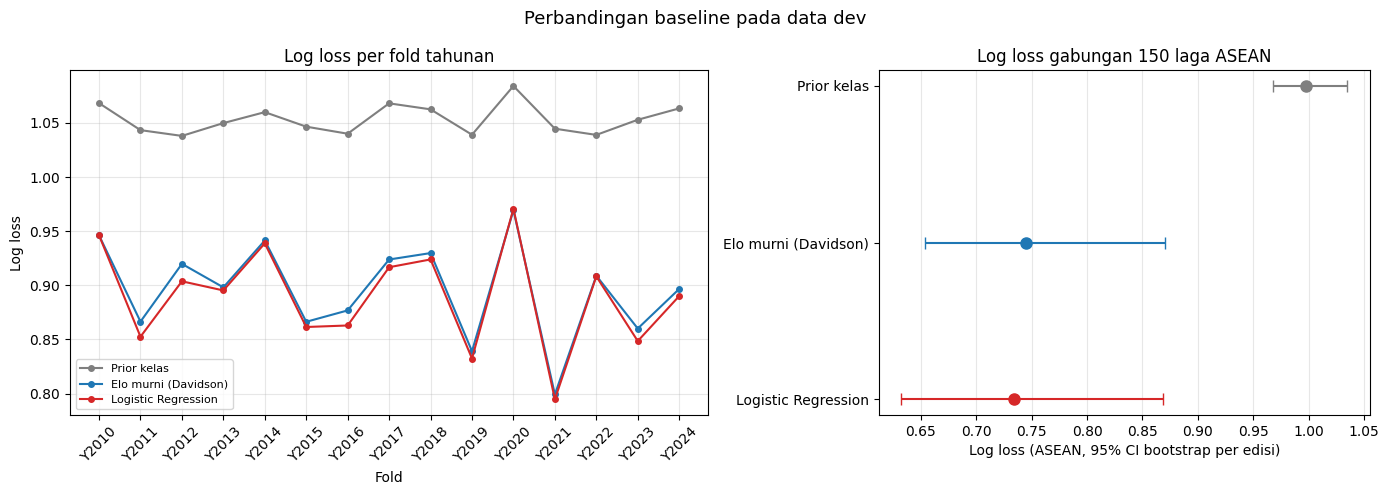

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})

for nama in NAMA_BASELINE:
    axes[0].plot(
        met_tahunan[nama]["fold"],
        met_tahunan[nama]["log_loss"],
        marker="o", ms=4, lw=1.5, label=nama, color=WARNA[nama],
    )
axes[0].set_title("Log loss per fold tahunan")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Log loss")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

nilai = []
for nama in NAMA_BASELINE:
    ci = ci_a[(ci_a["baseline"] == nama) & (ci_a["metrik"] == "log_loss")].iloc[0]
    nilai.append({
        "baseline": nama,
        "estimate": ci["estimate"],
        "ci_low": ci["ci_low"],
        "ci_high": ci["ci_high"],
    })
tabel_plot = pd.DataFrame(nilai)

for i, row in tabel_plot.iterrows():
    axes[1].errorbar(
        row["estimate"], i,
        xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
        fmt="o", color=WARNA[row["baseline"]], capsize=4, ms=8,
    )
axes[1].set_yticks(np.arange(len(tabel_plot)))
axes[1].set_yticklabels(tabel_plot["baseline"])
axes[1].invert_yaxis()
axes[1].set_xlabel("Log loss (ASEAN, 95% CI bootstrap per edisi)")
axes[1].set_title("Log loss gabungan 150 laga ASEAN")
axes[1].grid(axis="x", alpha=0.3)

fig.suptitle("Perbandingan baseline pada data dev", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_11_perbandingan_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

**Bacaan gambar.** Panel kiri menunjukkan apakah keunggulan baseline konsisten antar tahun. Panel kanan menunjukkan log loss gabungan ASEAN beserta ketidakpastian antar edisi. Model yang titik estimasinya rendah tetapi intervalnya lebar belum tentu lebih baik secara praktis.

### 6.6 Kalibrasi baseline pada laga ASEAN

Log loss sudah memberi insentif kalibrasi, tetapi kalibrasi perlu dilihat langsung. Tabel berikut melaporkan ECE top-label dan ECE classwise. Grafik reliabilitas membandingkan probabilitas prediksi dengan frekuensi observasi pada 5 bin; makin dekat ke diagonal, makin terkalibrasi.

ECE pada 150 laga ASEAN:
            baseline ece_top ece_classwise
         Prior kelas  0,0671        0,0447
Elo murni (Davidson)  0,0774        0,0599
 Logistic Regression  0,0653        0,0513


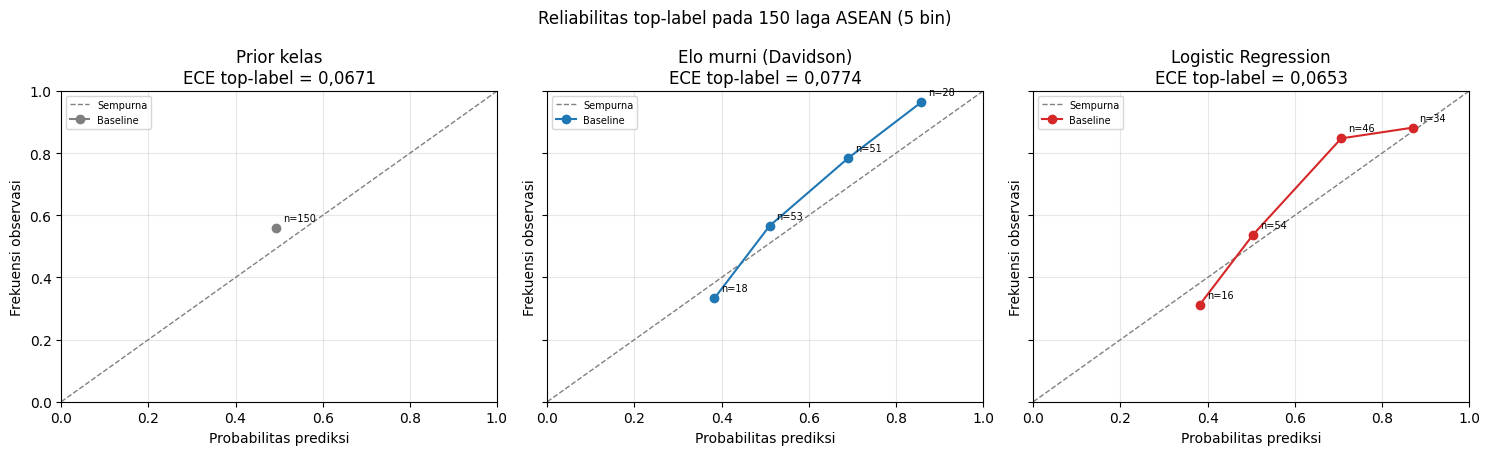

In [73]:
tabel_kal = pd.DataFrame([
    {
        "baseline": nama,
        "ece_top": expected_calibration_error(
            pred_asean[nama]["y"],
            pred_asean[nama][["p_H", "p_D", "p_A"]].to_numpy(),
            n_bins=BINS_ASEAN,
        ),
        "ece_classwise": classwise_ece(
            pred_asean[nama]["y"],
            pred_asean[nama][["p_H", "p_D", "p_A"]].to_numpy(),
            n_bins=BINS_ASEAN,
        ),
    }
    for nama in NAMA_BASELINE
])
print("ECE pada 150 laga ASEAN:")
print(tampil_metrik(tabel_kal, kolom=("ece_top", "ece_classwise")).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, nama in zip(axes, NAMA_BASELINE):
    pred = pred_asean[nama]
    tabel = reliability_table(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Sempurna")
    ax.plot(
        tabel["prediksi_rata"], tabel["observasi"],
        marker="o", lw=1.5, color=WARNA[nama], label="Baseline",
    )
    for _, row in tabel.iterrows():
        ax.annotate(
            f"n={int(row['n'])}", (row["prediksi_rata"], row["observasi"]),
            textcoords="offset points", xytext=(5, 5), fontsize=7,
        )
    ece = expected_calibration_error(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.set_title(f"{nama}\nECE top-label = {fmt(ece, 4)}")
    ax.set_xlabel("Probabilitas prediksi")
    ax.set_ylabel("Frekuensi observasi")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle(
    f"Reliabilitas top-label pada {len(pred_asean[NAMA_BASELINE[0]])} laga ASEAN ({BINS_ASEAN} bin)",
    fontsize=12,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_12_kalibrasi_baseline_asean.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi kalibrasi.** Pada 150 laga ASEAN, ECE top-label adalah **0,0671** untuk prior, **0,0774** untuk Elo, dan **0,0653** untuk logistic; ECE classwise **0,0447**, **0,0599**, dan **0,0513**. Logistic paling terkalibrasi pada top-label, tetapi prior justru paling rendah pada classwise. Urutan ini tidak identik dengan urutan log loss, sehingga kalibrasi perlu dibaca bersama log loss dan Brier. Prior hanya menghasilkan satu titik keyakinan, sehingga kurvanya tidak informatif; Elo dan logistic memberi sebaran keyakinan yang lebih lebar.

### 6.7 Ringkasan Section 6

Cell berikut merangkum baseline pada 150 laga ASEAN, menghitung perbaikan log loss relatif terhadap prior, dan memastikan tidak ada prediksi yang menyentuh `final_test`.

In [74]:
ringkasan6 = tabel_a.copy()
prior_ll = tabel_a.loc[tabel_a["baseline"] == "Prior kelas", "log_loss"].iloc[0]
ringkasan6["perbaikan_log_loss_vs_prior"] = (
    (prior_ll - ringkasan6["log_loss"]) / prior_ll * 100
)
ringkasan6["perbaikan_log_loss_vs_prior"] = ringkasan6["perbaikan_log_loss_vs_prior"].map(
    lambda v: fmt(v, 2) + "%"
)

print("Ringkasan baseline pada 150 laga ASEAN:")
print(tampil_metrik(ringkasan6).to_string(index=False))

print("\nBaseline terbaik per metrik:")
for kolom, arah in [("log_loss", "min"), ("brier", "min"), ("rps", "min"),
                    ("accuracy", "max"), ("macro_f1", "max"), ("ece_top", "min")]:
    if arah == "min":
        idx = tabel_a[kolom].idxmin()
    else:
        idx = tabel_a[kolom].idxmax()
    print(f"  {kolom:12s}: {tabel_a.loc[idx, 'baseline']} ({fmt(tabel_a.loc[idx, kolom], 4)})")

print("\nCek anti-leakage:")
for nama in NAMA_BASELINE:
    assert pred_tahunan[nama]["date"].max() < CUTOFF_TEST
    assert pred_asean[nama]["date"].max() < CUTOFF_TEST
print(f"  Semua prediksi validasi berakhir sebelum {CUTOFF_TEST.date()}; final_test tidak dibuka.")

Ringkasan baseline pada 150 laga ASEAN:
            baseline   n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise perbaikan_log_loss_vs_prior
         Prior kelas 150   0,9979 0,5954 0,2173   0,5600   0,2393  0,0671        0,0447                       0,00%
Elo murni (Davidson) 150   0,7449 0,4262 0,1367   0,6867   0,4903  0,0774        0,0599                      25,35%
 Logistic Regression 150   0,7337 0,4197 0,1338   0,6867   0,4865  0,0653        0,0513                      26,48%

Baseline terbaik per metrik:
  log_loss    : Logistic Regression (0,7337)
  brier       : Logistic Regression (0,4197)
  rps         : Logistic Regression (0,1338)
  accuracy    : Elo murni (Davidson) (0,6867)
  macro_f1    : Elo murni (Davidson) (0,4903)
  ece_top     : Logistic Regression (0,0653)

Cek anti-leakage:
  Semua prediksi validasi berakhir sebelum 2024-12-08; final_test tidak dibuka.


**Kesimpulan Section 6.** Pada 150 laga ASEAN, ketiga baseline memberi urutan log loss: prior **0,9979**, Elo **0,7449**, logistic **0,7337**. Elo dan logistic memperbaiki log loss relatif terhadap prior sebesar **25,35%** dan **26,48%**; keduanya juga menaikkan akurasi dari **56,00%** menjadi **68,67%**. Baseline terbaik per metrik: logistic untuk log loss, Brier, RPS, dan ECE top-label; Elo untuk akurasi dan macro-F1 (akurasi seri dengan logistic, macro-F1 sedikit lebih tinggi); prior untuk ECE classwise.

Keunggulan logistic atas Elo tipis dan belum stabil: selisih log loss **-0,0113** dengan 95% CI **[-0,0242; 0,0054]**, sehingga interval melewati nol. Di level edisi, tidak ada bukti kuat bahwa fitur non-Elo menambah informasi di luar Elo. Karena itu, Section 7 perlu menguji model non-linear dan interaksi fitur, tetapi harus tetap dibandingkan dengan Elo murni sebagai baseline yang kuat.

Semua evaluasi Section 6 hanya memakai `dev`; `final_test` belum dibuka. Section 7 akan memakai protokol fold yang sama untuk tuning, dan Section 8 baru akan membuka `final_test` satu kali.

## 7. Model Development & Tuning

Section ini mengembangkan kandidat model di atas baseline Section 6. Fokusnya bukan menambah kompleksitas sebanyak mungkin, tetapi menguji apakah fitur tambahan, model non-linear, atau ensemble memberi perbaikan yang stabil pada data validasi.

Aturan utama:

- Penyetelan hyperparameter hanya memakai **15 fold tahunan**.
- Fold ASEAN tidak dipakai untuk memilih konfigurasi. Fold ini dipakai sekali setelah konfigurasi dibekukan, sebagai evaluasi yang lebih dekat ke target aplikasi.
- `final_test` tetap tidak dibuka sampai Section 8.
- Metrik utama tetap **log loss**; Brier, RPS, akurasi, macro-F1, dan kalibrasi dilaporkan sebagai pelengkap.

### 7.1 Kandidat dan ruang pencarian

Empat kelompok fitur diuji:

| Kelompok | Isi | Tujuan |
|---|---|---|
| `elo` | `elo_diff`, status netral, status tuan rumah | Memeriksa seberapa jauh Elo saja bisa dibawa model probabilistik |
| `elo_form` | Elo + form dan masa istirahat | Menguji nilai form di atas Elo |
| `full` | seluruh fitur Section 5 (Elo, form, H2H, konteks) | Kandidat utama |
| `full_interaksi` | `full` + interaksi Elo/form/tuan rumah/H2H | Menguji apakah hubungan non-linear sederhana membantu |

Dua keluarga model:

1. **Logistic Regression L2** dengan `C` divariasikan. `C` kecil berarti regularisasi kuat; `C` besar berarti regularisasi lemah.
2. **HistGradientBoostingClassifier (HGB)** dengan pohon dangkal. HGB tidak memerlukan standardisasi, tetapi tetap memakai imputasi median dan one-hot untuk konteks turnamen.

Ensemble linear dari logistic dan HGB diuji setelah masing-masing keluarga disetel. Bobot ensemble hanya dipilih pada fold tahunan.

In [75]:
from src.evaluation.validation import fold_metrics_from_predictions
from src.models.candidates import (
    FEATURE_SETS,
    build_hgb_candidate,
    build_logistic_candidate,
)
from src.models.tuning import blend_predictions, tune_blend_weights, tune_grid

assert "fitur6" in globals()
assert "folds_tahunan" in globals()
assert "folds_asean" in globals()
assert len(folds_tahunan) == 15 and len(folds_asean) == 7
assert fitur6["date"].max() < CUTOFF_TEST

WARNA7 = {
    "Logistic (full)": "#7f7f7f",
    "Logistic + interaksi": "#d62728",
    "HGB + interaksi": "#2ca02c",
    "Ensemble": "#9467bd",
}
NAMA7 = list(WARNA7)

PILIHAN_LOGISTIC = {
    "feature_set": ["elo", "elo_form", "full"],
    "C": [0.03, 0.1, 1.0],
}
PILIHAN_HGB = {
    "learning_rate": [0.05, 0.1],
    "max_leaf_nodes": [15, 31],
}

tabel_fitur7 = pd.DataFrame([
    {
        "kelompok": nama,
        "numerik": len(spesifikasi["numeric"]),
        "kategorikal": len(spesifikasi["categorical"]),
        "interaksi": nama.endswith("interaksi"),
    }
    for nama, spesifikasi in FEATURE_SETS.items()
])
print("Kelompok fitur:")
print(tabel_fitur7.to_string(index=False))
print(f"\nLogistic: {len(PILIHAN_LOGISTIC['feature_set']) * len(PILIHAN_LOGISTIC['C'])} konfigurasi")
print(f"HGB: {len(PILIHAN_HGB['learning_rate']) * len(PILIHAN_HGB['max_leaf_nodes'])} konfigurasi")
print("Penyetelan hanya pada fold tahunan; fold ASEAN disimpan untuk evaluasi akhir.")

Kelompok fitur:
      kelompok  numerik  kategorikal  interaksi
           elo        4            0      False
      elo_form       10            0      False
          full       18            1      False
full_interaksi       31            1       True

Logistic: 9 konfigurasi
HGB: 4 konfigurasi
Penyetelan hanya pada fold tahunan; fold ASEAN disimpan untuk evaluasi akhir.


**Cek ruang pencarian.** Ada 9 konfigurasi logistic dan 4 konfigurasi HGB. Semua kombinasi dilatih ulang dari awal pada setiap fold, sehingga tidak ada informasi validasi yang bocor ke proses fitting. `full_interaksi` tidak dimasukkan ke grid awal karena hanya berbeda pada fitur turunan; kelompok ini diuji terpisah setelah kelompok `full` terbukti paling baik.

### 7.2 Tuning Logistic Regression

Grid logistic memakai tiga kelompok fitur dan tiga nilai `C`. Setiap konfigurasi dilatih ulang pada setiap fold; imputasi, standardisasi, dan one-hot hanya di-fit pada data latih fold tersebut.

Waktu tuning logistic: 71.2 detik
feature_set    C  log_loss_mean  log_loss_sd  log_loss_pooled  brier_pooled  accuracy_mean  macro_f1_mean
       full 1.00         0.8897       0.0475           0.8830        0.5197         0.5896         0.4365
       full 0.03         0.8898       0.0474           0.8830        0.5197         0.5895         0.4363
       full 0.10         0.8898       0.0475           0.8830        0.5197         0.5898         0.4366
   elo_form 1.00         0.8965       0.0467           0.8899        0.5238         0.5885         0.4292
   elo_form 0.10         0.8966       0.0466           0.8899        0.5238         0.5886         0.4293
   elo_form 0.03         0.8966       0.0466           0.8899        0.5239         0.5886         0.4293
        elo 1.00         0.8979       0.0452           0.8915        0.5249         0.5885         0.4290
        elo 0.10         0.8979       0.0452           0.8915        0.5249         0.5885         0.4290
        elo 

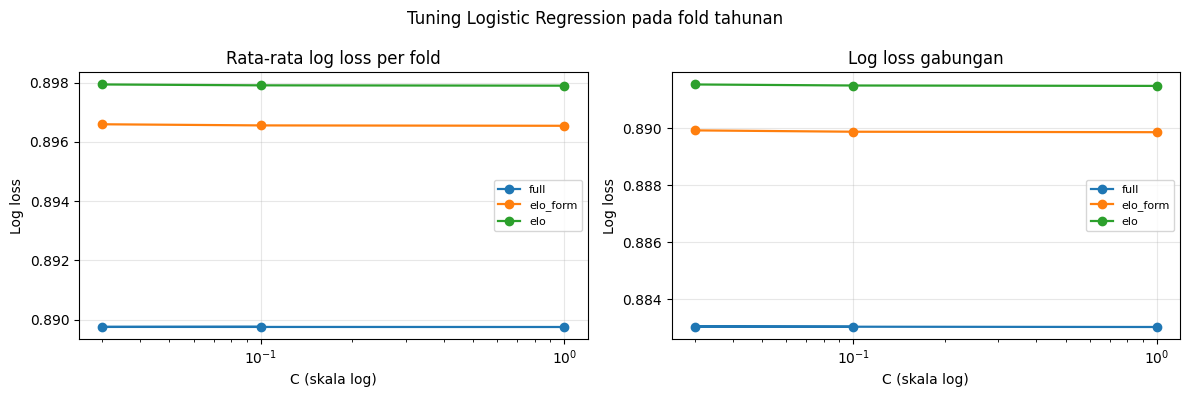

In [76]:
import time

t0 = time.time()
grid_log = tune_grid(
    fitur6,
    folds_tahunan,
    build_logistic_candidate,
    PILIHAN_LOGISTIC,
    n_bins=BINS_TAHUNAN,
    verbose=False,
)
waktu_log = time.time() - t0

kolom_log = [
    "feature_set", "C", "log_loss_mean", "log_loss_sd",
    "log_loss_pooled", "brier_pooled", "accuracy_mean", "macro_f1_mean",
]
print(f"Waktu tuning logistic: {waktu_log:.1f} detik")
print(grid_log[kolom_log].round(4).to_string(index=False))

best_log = grid_log.iloc[0]
print(f"\nKonfigurasi logistic terbaik: feature_set={best_log['feature_set']}, "
      f"C={best_log['C']:.2f}")
print(f"Log loss mean={fmt(best_log['log_loss_mean'], 4)} | "
      f"pooled={fmt(best_log['log_loss_pooled'], 4)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nama_fitur, bagian in grid_log.groupby("feature_set", sort=False):
    axes[0].plot(bagian["C"], bagian["log_loss_mean"], marker="o", lw=1.6, label=nama_fitur)
    axes[1].plot(bagian["C"], bagian["log_loss_pooled"], marker="o", lw=1.6, label=nama_fitur)
for ax, judul in zip(axes, ["Rata-rata log loss per fold", "Log loss gabungan"]):
    ax.set_xscale("log")
    ax.set_xlabel("C (skala log)")
    ax.set_ylabel("Log loss")
    ax.set_title(judul)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.suptitle("Tuning Logistic Regression pada fold tahunan", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_13_tuning_logistic.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi tuning logistic.** Kelompok `full` konsisten paling rendah, sedangkan `elo` dan `elo_form` tertinggal sekitar 0,007-0,008 log loss. Nilai `C` hampir tidak mengubah hasil: selisih antarnilai `C` pada kelompok `full` kurang dari 0,00001. Artinya, regularisasi bukan faktor pembatas pada ukuran data ini; informasi fitur yang menentukan. Konfigurasi terbaik adalah `full` dengan `C=1,0`, dengan log loss tahunan mean **0,8897** dan pooled **0,8830**.

### 7.3 Uji fitur interaksi

Fitur interaksi menambahkan selisih form, selisih masa istirahat, Elo kuadrat, interaksi status tuan rumah dengan Elo, dan interaksi H2H dengan Elo. Tujuannya menguji apakah model linear membutuhkan suku interaksi eksplisit sebelum beralih ke model non-linear.

In [77]:
t0 = time.time()
grid_log_i = tune_grid(
    fitur6,
    folds_tahunan,
    build_logistic_candidate,
    {"feature_set": ["full_interaksi"], "C": [0.1, 1.0]},
    n_bins=BINS_TAHUNAN,
    verbose=False,
)
waktu_log_i = time.time() - t0

print(f"Waktu tuning logistic interaksi: {waktu_log_i:.1f} detik")
print(grid_log_i[kolom_log].round(4).to_string(index=False))

best_log_i = grid_log_i.iloc[0]
baris_banding = []
for label, baris in [
    ("full, C=1.0", grid_log[(grid_log["feature_set"] == "full") & (grid_log["C"] == 1.0)].iloc[0]),
    ("full_interaksi, C=1.0", best_log_i),
]:
    baris_banding.append({
        "konfigurasi": label,
        "log_loss_mean": baris["log_loss_mean"],
        "log_loss_pooled": baris["log_loss_pooled"],
        "brier_pooled": baris["brier_pooled"],
        "macro_f1_mean": baris["macro_f1_mean"],
    })
tabel_banding_log = pd.DataFrame(baris_banding)
print("\nPerbandingan full vs full_interaksi:")
print(tabel_banding_log.round(4).to_string(index=False))

Waktu tuning logistic interaksi: 44.9 detik
   feature_set   C  log_loss_mean  log_loss_sd  log_loss_pooled  brier_pooled  accuracy_mean  macro_f1_mean
full_interaksi 0.1          0.889       0.0478           0.8822        0.5194         0.5882         0.4384
full_interaksi 1.0          0.889       0.0478           0.8822        0.5194         0.5882         0.4387

Perbandingan full vs full_interaksi:
          konfigurasi  log_loss_mean  log_loss_pooled  brier_pooled  macro_f1_mean
          full, C=1.0         0.8897           0.8830        0.5197         0.4365
full_interaksi, C=1.0         0.8890           0.8822        0.5194         0.4384


**Interpretasi interaksi.** `full_interaksi` menurunkan log loss tahunan menjadi mean **0,8890** dan pooled **0,8822**, lebih baik sekitar 0,0008 dibanding `full` tanpa interaksi. Perbaikannya kecil, tetapi konsisten dan tidak bergantung pada `C` (0,1 dan 1,0 hampir identik). Konfigurasi yang dipilih untuk evaluasi akhir adalah **`full_interaksi`, C=1,0**.

### 7.4 Tuning HistGradientBoosting

HGB diuji dengan empat kombinasi learning rate dan jumlah daun. Model memakai fitur `full` tanpa interaksi eksplisit, `max_iter=100`, `min_samples_leaf=20`, dan tanpa early stopping agar hasil antar fold sebanding. HGB lebih mahal secara komputasi, jadi grid sengaja dibuat kecil.

Waktu tuning HGB: 242.7 detik
 learning_rate  max_leaf_nodes  log_loss_mean  log_loss_sd  log_loss_pooled  brier_pooled  accuracy_mean  macro_f1_mean
          0.05              15         0.8933       0.0490           0.8862        0.5216         0.5888         0.4352
          0.05              31         0.8941       0.0487           0.8872        0.5220         0.5886         0.4438
          0.10              15         0.8964       0.0496           0.8892        0.5236         0.5847         0.4417
          0.10              31         0.8980       0.0483           0.8911        0.5247         0.5829         0.4519

Konfigurasi HGB terbaik: learning_rate=0.05, max_leaf_nodes=15
Log loss mean=0,8933 | pooled=0,8862


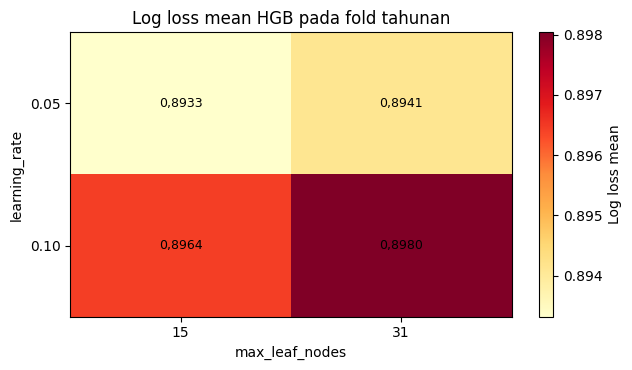

In [78]:
t0 = time.time()
grid_hgb = tune_grid(
    fitur6,
    folds_tahunan,
    build_hgb_candidate,
    PILIHAN_HGB,
    n_bins=BINS_TAHUNAN,
    verbose=False,
)
waktu_hgb = time.time() - t0

kolom_hgb = [
    "learning_rate", "max_leaf_nodes", "log_loss_mean", "log_loss_sd",
    "log_loss_pooled", "brier_pooled", "accuracy_mean", "macro_f1_mean",
]
print(f"Waktu tuning HGB: {waktu_hgb:.1f} detik")
print(grid_hgb[kolom_hgb].round(4).to_string(index=False))

best_hgb = grid_hgb.iloc[0]
print(f"\nKonfigurasi HGB terbaik: learning_rate={best_hgb['learning_rate']:.2f}, "
      f"max_leaf_nodes={int(best_hgb['max_leaf_nodes'])}")
print(f"Log loss mean={fmt(best_hgb['log_loss_mean'], 4)} | "
      f"pooled={fmt(best_hgb['log_loss_pooled'], 4)}")

pivot_hgb = grid_hgb.pivot(
    index="learning_rate", columns="max_leaf_nodes", values="log_loss_mean"
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
im = ax.imshow(pivot_hgb.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(np.arange(len(pivot_hgb.columns)))
ax.set_xticklabels([int(v) for v in pivot_hgb.columns])
ax.set_yticks(np.arange(len(pivot_hgb.index)))
ax.set_yticklabels([f"{v:.2f}" for v in pivot_hgb.index])
ax.set_xlabel("max_leaf_nodes")
ax.set_ylabel("learning_rate")
ax.set_title("Log loss mean HGB pada fold tahunan")
for i in range(pivot_hgb.shape[0]):
    for j in range(pivot_hgb.shape[1]):
        ax.text(j, i, fmt(pivot_hgb.values[i, j], 4), ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="Log loss mean")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_14_tuning_hgb.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi tuning HGB.** Konfigurasi terbaik adalah learning rate **0,05** dengan **15 daun**, menghasilkan log loss tahunan mean **0,8933** dan pooled **0,8862**. Learning rate 0,1 atau 31 daun justru lebih buruk. Semua konfigurasi HGB masih di atas logistic `full_interaksi` (0,8890/0,8822). HGB juga jauh lebih lambat, sehingga belum memberi alasan untuk dipilih.

### 7.5 HGB dengan interaksi

Sebagai pemeriksaan terakhir, HGB terbaik diuji dengan fitur interaksi eksplisit. Jika HGB tetap tidak mengalahkan logistic, kompleksitas tambahan tidak dibenarkan.

In [79]:
t0 = time.time()
grid_hgb_i = tune_grid(
    fitur6,
    folds_tahunan,
    build_hgb_candidate,
    {"learning_rate": [0.05], "max_leaf_nodes": [15], "add_interactions": [True]},
    n_bins=BINS_TAHUNAN,
    verbose=False,
)
waktu_hgb_i = time.time() - t0

print(f"Waktu HGB interaksi: {waktu_hgb_i:.1f} detik")
print(grid_hgb_i[kolom_hgb].round(4).to_string(index=False))
best_hgb_i = grid_hgb_i.iloc[0]
print(f"Log loss mean={fmt(best_hgb_i['log_loss_mean'], 4)} | "
      f"pooled={fmt(best_hgb_i['log_loss_pooled'], 4)}")

Waktu HGB interaksi: 68.1 detik
 learning_rate  max_leaf_nodes  log_loss_mean  log_loss_sd  log_loss_pooled  brier_pooled  accuracy_mean  macro_f1_mean
          0.05              15         0.8924       0.0494           0.8852        0.5209         0.5905         0.4352
Log loss mean=0,8924 | pooled=0,8852


**Interpretasi HGB interaksi.** Interaksi eksplisit menurunkan log loss HGB menjadi mean **0,8924** dan pooled **0,8852**, tetapi tetap lebih tinggi daripada logistic `full_interaksi` (0,8890/0,8822). Akurasi HGB sedikit lebih tinggi, namun log loss, Brier, dan kalibrasinya lebih buruk; untuk model probabilistik, kualitas probabilitas tetap menjadi prioritas. HGB tidak dipilih.

### 7.6 Evaluasi kandidat pada fold tahunan

Tiga kandidat dibawa ke evaluasi tahunan penuh: logistic `full`, logistic `full_interaksi`, dan HGB `full_interaksi`. Ketiganya memakai konfigurasi yang sudah dipilih dari grid di atas. Tabel berikut memisahkan rata-rata metrik per fold dari metrik gabungan, karena keduanya menjawab pertanyaan yang berbeda.

In [80]:
def latih_log_full(train, val):
    model = build_logistic_candidate(feature_set="full", C=1.0)
    model.fit(train, encode_labels(train["result"]))
    return model.predict_proba(val)


def latih_log_interaksi(train, val):
    model = build_logistic_candidate(feature_set="full_interaksi", C=1.0)
    model.fit(train, encode_labels(train["result"]))
    return model.predict_proba(val)


def latih_hgb_interaksi(train, val):
    model = build_hgb_candidate(
        learning_rate=0.05, max_leaf_nodes=15, max_iter=100,
        add_interactions=True,
    )
    model.fit(train, encode_labels(train["result"]))
    return model.predict_proba(val)


def ringkas_kandidat(nama, pred, met, n_bins):
    pool = pooled_metrics(pred, n_bins=n_bins)
    return {
        "kandidat": nama,
        "n": len(pred),
        "log_loss_mean": met["log_loss"].mean(),
        "log_loss_pooled": pool["log_loss"],
        "brier_mean": met["brier"].mean(),
        "brier_pooled": pool["brier"],
        "rps_mean": met["rps"].mean(),
        "accuracy_pooled": pool["accuracy"],
        "macro_f1_pooled": pool["macro_f1"],
        "ece_top_pooled": pool["ece_top"],
        "ece_classwise_pooled": pool["ece_classwise"],
    }


pred_gabung = [
    ("Logistic (full)", latih_log_full),
    ("Logistic + interaksi", latih_log_interaksi),
    ("HGB + interaksi", latih_hgb_interaksi),
]
pred_tahunan7 = {}
met_tahunan7 = {}
for nama, fungsi in pred_gabung:
    pred_tahunan7[nama], met_tahunan7[nama] = run_folds(
        fitur6, folds_tahunan, fungsi, n_bins=BINS_TAHUNAN
    )

tabel_t7 = pd.DataFrame([
    ringkas_kandidat(nama, pred_tahunan7[nama], met_tahunan7[nama], BINS_TAHUNAN)
    for nama in pred_tahunan7
])
kolom_t7 = [
    "kandidat", "log_loss_mean", "log_loss_pooled", "brier_mean",
    "brier_pooled", "rps_mean", "accuracy_pooled", "macro_f1_pooled",
    "ece_top_pooled",
]
print("Ringkasan kandidat pada 15 fold tahunan:")
print(tabel_t7[kolom_t7].round(4).to_string(index=False))

Ringkasan kandidat pada 15 fold tahunan:
            kandidat  log_loss_mean  log_loss_pooled  brier_mean  brier_pooled  rps_mean  accuracy_pooled  macro_f1_pooled  ece_top_pooled
     Logistic (full)         0.8897           0.8830      0.5242        0.5197    0.1751           0.5931           0.4395          0.0101
Logistic + interaksi         0.8890           0.8822      0.5239        0.5194    0.1751           0.5914           0.4414          0.0118
     HGB + interaksi         0.8924           0.8852      0.5257        0.5209    0.1756           0.5941           0.4384          0.0111


**Interpretasi fold tahunan.** Logistic `full_interaksi` memberi log loss mean **0,8890** dan pooled **0,8822**, paling rendah di antara tiga kandidat. Logistic `full` berada di **0,8897/0,8830**, sedangkan HGB di **0,8924/0,8852**. Selisih logistic interaksi vs logistic full kecil; uji berpasangan di Subsection 7.9 menentukan apakah selisih itu stabil. HGB tidak mengungguli logistic pada metrik probabilitas, meskipun akurasinya sedikit lebih tinggi.

### 7.7 Ensemble logistic dan HGB

Ensemble diuji sebagai rata-rata berbobot: bobot 0 berarti hanya logistic, bobot 1 berarti hanya HGB. Bobot dipilih dengan meminimalkan rata-rata log loss pada 15 fold tahunan, dengan grid 0,00 sampai 1,00 langkah 0,05.

In [81]:
grid_bobot = tune_blend_weights(
    pred_tahunan7["Logistic + interaksi"],
    pred_tahunan7["HGB + interaksi"],
    np.arange(0, 1.0001, 0.05),
    n_bins=BINS_TAHUNAN,
)
print("Bobot ensemble pada fold tahunan (10 teratas):")
print(grid_bobot.head(10).round(4).to_string(index=False))

bobot_ens = float(grid_bobot.iloc[0]["weight_b"])
pred_ens_t = blend_predictions(
    pred_tahunan7["Logistic + interaksi"],
    pred_tahunan7["HGB + interaksi"],
    bobot_ens,
)
met_ens_t = fold_metrics_from_predictions(pred_ens_t, n_bins=BINS_TAHUNAN)
pred_tahunan7["Ensemble"] = pred_ens_t
met_tahunan7["Ensemble"] = met_ens_t

tabel_t7 = pd.concat([
    tabel_t7,
    pd.DataFrame([ringkas_kandidat("Ensemble", pred_ens_t, met_ens_t, BINS_TAHUNAN)]),
], ignore_index=True)
print(f"\nBobot HGB terpilih: {bobot_ens:.2f}")
print("Ringkasan kandidat pada fold tahunan (termasuk ensemble):")
print(tabel_t7[kolom_t7].round(4).to_string(index=False))

Bobot ensemble pada fold tahunan (10 teratas):
 weight_b  log_loss_mean  log_loss_sd  log_loss_pooled  brier_mean  brier_pooled  accuracy_pooled  macro_f1_pooled
     0.25         0.8886       0.0481           0.8817      0.5237        0.5191           0.5924           0.4391
     0.20         0.8886       0.0480           0.8817      0.5237        0.5191           0.5925           0.4401
     0.30         0.8886       0.0481           0.8817      0.5237        0.5191           0.5932           0.4391
     0.15         0.8886       0.0480           0.8818      0.5237        0.5191           0.5923           0.4401
     0.35         0.8887       0.0482           0.8818      0.5237        0.5191           0.5933           0.4386
     0.10         0.8887       0.0479           0.8819      0.5237        0.5192           0.5922           0.4407
     0.40         0.8888       0.0483           0.8818      0.5237        0.5191           0.5938           0.4387
     0.05         0.8888       0.


Bobot HGB terpilih: 0.25
Ringkasan kandidat pada fold tahunan (termasuk ensemble):
            kandidat  log_loss_mean  log_loss_pooled  brier_mean  brier_pooled  rps_mean  accuracy_pooled  macro_f1_pooled  ece_top_pooled
     Logistic (full)         0.8897           0.8830      0.5242        0.5197    0.1751           0.5931           0.4395          0.0101
Logistic + interaksi         0.8890           0.8822      0.5239        0.5194    0.1751           0.5914           0.4414          0.0118
     HGB + interaksi         0.8924           0.8852      0.5257        0.5209    0.1756           0.5941           0.4384          0.0111
            Ensemble         0.8886           0.8817      0.5237        0.5191    0.1750           0.5924           0.4391          0.0092


**Interpretasi ensemble.** Bobot terbaik adalah **0,25** untuk HGB, dengan log loss tahunan mean **0,8886** dan pooled **0,8817**. Perbaikan terhadap logistic interaksi hanya sekitar **0,0003-0,0005**, dan bobot 0,50 justru lebih buruk. Ensemble memberi sinyal bahwa HGB membawa sedikit informasi tambahan, tetapi besarannya terlalu kecil untuk dianggap penting sebelum diuji pada fold ASEAN.

### 7.8 Evaluasi pada fold ASEAN

Konfigurasi sudah dibekukan dari fold tahunan. Sekarang tiga kandidat dan ensemble dievaluasi pada 7 fold ASEAN (150 laga). Fold ini tidak dipakai untuk memilih hyperparameter atau bobot; ia berfungsi sebagai uji generalisasi yang lebih dekat ke target aplikasi.

Perbandingan kandidat pada 150 laga ASEAN:
            kandidat   n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise
     Logistic (full) 150   0,7337 0,4197 0,1338   0,6867   0,4865  0,0653        0,0513
Logistic + interaksi 150   0,7278 0,4170 0,1330   0,6867   0,4865  0,0604        0,0480
     HGB + interaksi 150   0,7417 0,4236 0,1350   0,6933   0,4947  0,0861        0,0559
            Ensemble 150   0,7306 0,4180 0,1333   0,6933   0,4957  0,0807        0,0566



Log loss per edisi ASEAN:
      Ensemble HGB + interaksi Logistic (full) Logistic + interaksi
edisi                                                              
8       0,9862          0,9741          0,9994               0,9910
9       0,8696          0,8773          0,8734               0,8685
10      0,8853          0,8863          0,8925               0,8859
11      0,7700          0,7763          0,7647               0,7690
12      0,5978          0,6182          0,5973               0,5925
13      0,5983          0,6257          0,5974               0,5896
14      0,5881          0,6023          0,5941               0,5837



CI bootstrap log loss (resampling per edisi):
  metrik estimate ci_low ci_high  n_boot             kandidat
log_loss   0,7337 0,6321  0,8689    2000      Logistic (full)
   brier   0,4197 0,3548  0,5054    2000      Logistic (full)
log_loss   0,7278 0,6262  0,8651    2000 Logistic + interaksi
   brier   0,4170 0,3524  0,5047    2000 Logistic + interaksi
log_loss   0,7417 0,6487  0,8666    2000      HGB + interaksi
   brier   0,4236 0,3632  0,5033    2000      HGB + interaksi
log_loss   0,7306 0,6307  0,8646    2000             Ensemble
   brier   0,4180 0,3540  0,5040    2000             Ensemble


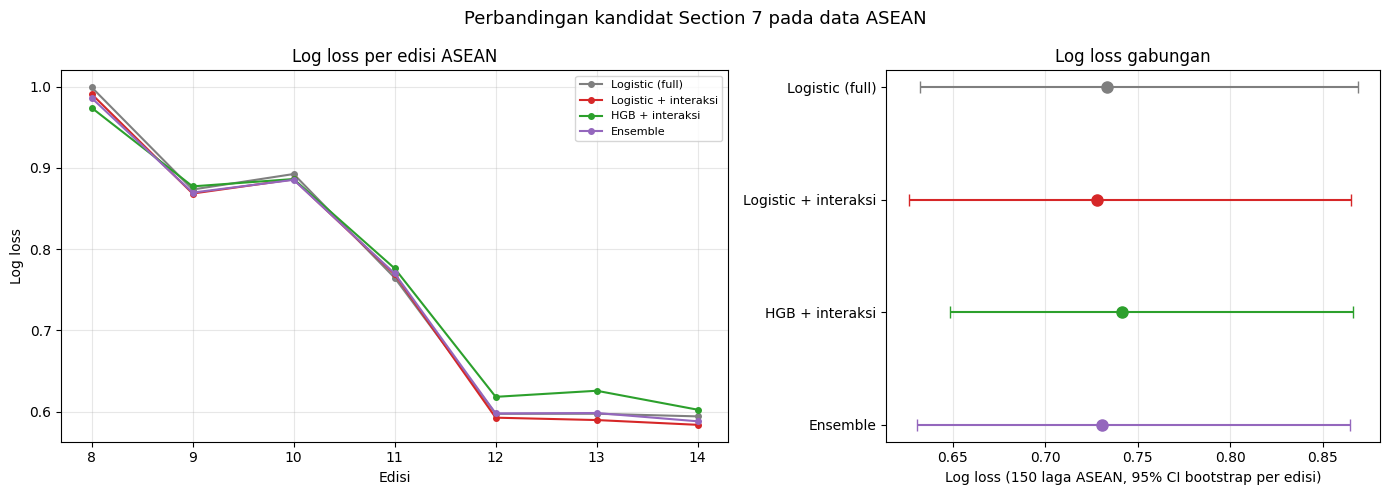

In [82]:
pred_asean7 = {}
met_asean7 = {}
for nama, fungsi in pred_gabung:
    pred_asean7[nama], met_asean7[nama] = run_folds(
        fitur6, folds_asean, fungsi, n_bins=BINS_ASEAN
    )

pred_ens_a = blend_predictions(
    pred_asean7["Logistic + interaksi"],
    pred_asean7["HGB + interaksi"],
    bobot_ens,
)
met_ens_a = fold_metrics_from_predictions(pred_ens_a, n_bins=BINS_ASEAN)
pred_asean7["Ensemble"] = pred_ens_a
met_asean7["Ensemble"] = met_ens_a

tabel_a7 = pd.DataFrame([
    {"kandidat": nama, "n": len(pred_asean7[nama]), **pooled_metrics(pred_asean7[nama], BINS_ASEAN)}
    for nama in NAMA7
])
kolom_a7 = ["kandidat", "n", "log_loss", "brier", "rps", "accuracy", "macro_f1", "ece_top", "ece_classwise"]
print("Perbandingan kandidat pada 150 laga ASEAN:")
print(tampil_metrik(tabel_a7[kolom_a7]).to_string(index=False))

per_edisi7 = pd.concat([
    metrics_by_group(pred_asean7[nama], group_col="edition", n_bins=BINS_ASEAN).assign(kandidat=nama)
    for nama in NAMA7
], ignore_index=True)
pivot_edisi7 = per_edisi7.pivot(index="edition", columns="kandidat", values="log_loss")
pivot_edisi7.columns.name = None
pivot_edisi7.index.name = "edisi"
print("\nLog loss per edisi ASEAN:")
print(pivot_edisi7.map(lambda v: fmt(v, 4)).to_string())

ci_a7 = pd.concat([
    bootstrap_metrics_table(
        pred_asean7[nama], n_boot=EVAL_CFG["n_bootstrap"],
        seed=EVAL_CFG["seed"], alpha=EVAL_CFG["alpha"], cluster_col="edition",
    ).assign(kandidat=nama)
    for nama in NAMA7
], ignore_index=True)
print("\nCI bootstrap log loss (resampling per edisi):")
print(tampil_interval(
    ci_a7[ci_a7["metrik"].isin(["log_loss", "brier"])]
).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.35, 1]})
for nama in NAMA7:
    bagian = per_edisi7[per_edisi7["kandidat"] == nama]
    axes[0].plot(
        bagian["edition"], bagian["log_loss"], marker="o", ms=4, lw=1.5,
        label=nama, color=WARNA7[nama],
    )
axes[0].set_title("Log loss per edisi ASEAN")
axes[0].set_xlabel("Edisi")
axes[0].set_ylabel("Log loss")
axes[0].set_xticks(sorted(per_edisi7["edition"].unique()))
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

for i, nama in enumerate(NAMA7):
    row = ci_a7[(ci_a7["kandidat"] == nama) & (ci_a7["metrik"] == "log_loss")].iloc[0]
    axes[1].errorbar(
        row["estimate"], i,
        xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
        fmt="o", color=WARNA7[nama], capsize=4, ms=8,
    )
axes[1].set_yticks(np.arange(len(NAMA7)))
axes[1].set_yticklabels(NAMA7)
axes[1].invert_yaxis()
axes[1].set_xlabel("Log loss (150 laga ASEAN, 95% CI bootstrap per edisi)")
axes[1].set_title("Log loss gabungan")
axes[1].grid(axis="x", alpha=0.3)

fig.suptitle("Perbandingan kandidat Section 7 pada data ASEAN", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_15_perbandingan_kandidat_asean.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi ASEAN.** Logistic `full_interaksi` tetap yang terbaik dengan log loss **0,7278** dan Brier **0,4170**. Logistic `full` (baseline Section 6) berada di **0,7337/0,4197**, HGB di **0,7417/0,4236**, dan ensemble di **0,7306/0,4180**. Ensemble memperbaiki logistic pada fold tahunan, tetapi **tidak** memperbaiki logistic interaksi pada fold ASEAN. HGB juga tidak lebih baik. Karena itu, ensemble dan HGB tidak dipilih.

Per edisi, logistic interaksi lebih baik dari logistic full pada edisi 8, 9, 10, 12, 13, dan 14; satu-satunya edisi yang sedikit lebih buruk adalah edisi 11. Akurasi dan macro-F1 HGB/ensemble memang sedikit lebih tinggi, tetapi keunggulan itu tidak diikuti log loss, Brier, RPS, atau kalibrasi yang lebih baik.

### 7.9 Stabilitas dan perbandingan berpasangan

Karena semua kandidat dievaluasi pada laga yang sama, selisih metrik diuji dengan **paired bootstrap**. Untuk fold tahunan, resampling dilakukan per fold; untuk ASEAN, per edisi. Tanda negatif berarti kandidat A lebih baik (log loss/Brier lebih rendah).

In [83]:
delta_t7 = paired_delta_table(
    pred_tahunan7["Logistic + interaksi"],
    pred_tahunan7["Logistic (full)"],
    n_boot=EVAL_CFG["n_bootstrap"], seed=EVAL_CFG["seed"],
    alpha=EVAL_CFG["alpha"], cluster_col="fold",
)
delta_t7["pasangan"] = "Logistic + interaksi - Logistic (full)"
print("Selisih berpasangan pada fold tahunan:")
print(tampil_interval(
    delta_t7[delta_t7["metrik"].isin(["log_loss", "brier", "accuracy", "macro_f1"])]
).to_string(index=False))

pasangan_asean = [
    ("Logistic + interaksi", "Logistic (full)"),
    ("Ensemble", "Logistic + interaksi"),
    ("HGB + interaksi", "Logistic + interaksi"),
]
baris_delta = []
for a, b in pasangan_asean:
    tabel = paired_delta_table(
        pred_asean7[a], pred_asean7[b],
        n_boot=EVAL_CFG["n_bootstrap"], seed=EVAL_CFG["seed"],
        alpha=EVAL_CFG["alpha"], cluster_col="edition",
    )
    tabel["pasangan"] = f"{a} - {b}"
    baris_delta.append(tabel)
delta_a7 = pd.concat(baris_delta, ignore_index=True)
print("\nSelisih berpasangan pada 150 laga ASEAN:")
print(tampil_interval(
    delta_a7[delta_a7["metrik"].isin(["log_loss", "brier"])]
).to_string(index=False))

log_i_edisi = per_edisi7[per_edisi7["kandidat"] == "Logistic + interaksi"].set_index("edition")["log_loss"]
log_f_edisi = per_edisi7[per_edisi7["kandidat"] == "Logistic (full)"].set_index("edition")["log_loss"]
tabel_delta_edisi = pd.DataFrame({
    "logistic_interaksi": log_i_edisi,
    "logistic_full": log_f_edisi,
    "selisih": log_i_edisi - log_f_edisi,
})
print("\nSelisih log loss per edisi (interaksi - full):")
print(tabel_delta_edisi.round(4).to_string())

Selisih berpasangan pada fold tahunan:
  metrik estimate  ci_low ci_high proporsi_positif  n_boot                               pasangan
log_loss  -0,0009 -0,0016 -0,0001             1,1%    2000 Logistic + interaksi - Logistic (full)
   brier  -0,0003 -0,0008  0,0001             8,1%    2000 Logistic + interaksi - Logistic (full)
accuracy  -0,0017 -0,0027 -0,0007             0,0%    2000 Logistic + interaksi - Logistic (full)
macro_f1   0,0020  0,0006  0,0034            99,8%    2000 Logistic + interaksi - Logistic (full)



Selisih berpasangan pada 150 laga ASEAN:
  metrik estimate  ci_low ci_high proporsi_positif  n_boot                               pasangan
log_loss  -0,0059 -0,0084 -0,0022             0,2%    2000 Logistic + interaksi - Logistic (full)
   brier  -0,0026 -0,0038 -0,0009             0,3%    2000 Logistic + interaksi - Logistic (full)
log_loss   0,0028 -0,0007  0,0056            94,5%    2000        Ensemble - Logistic + interaksi
   brier   0,0010 -0,0008  0,0026            85,2%    2000        Ensemble - Logistic + interaksi
log_loss   0,0139  0,0002  0,0249            97,9%    2000 HGB + interaksi - Logistic + interaksi
   brier   0,0065 -0,0010  0,0133            95,3%    2000 HGB + interaksi - Logistic + interaksi

Selisih log loss per edisi (interaksi - full):
         logistic_interaksi  logistic_full  selisih
edition                                            
8                    0.9910         0.9994  -0.0084
9                    0.8685         0.8734  -0.0050
10              

**Interpretasi stabilitas.** Pada fold tahunan, selisih log loss logistic interaksi vs logistic full adalah **-0,0009** dengan 95% CI **[-0,0016; -0,0001]**; arah perbaikan terjadi pada 10 dari 15 fold. Pada ASEAN, selisihnya **-0,0059** dengan 95% CI **[-0,0084; -0,0022]**, dan perbaikan terjadi di 6 dari 7 edisi. CI tidak memuat nol, jadi perbaikan kecil ini cukup stabil untuk dipertahankan.

Sebaliknya, ensemble vs logistic interaksi memberi selisih **+0,0028** (CI **[-0,0007; +0,0056]**), yaitu arah yang salah dan tidak stabil; HGB vs logistic interaksi memberi **+0,0139** (CI **[+0,0002; +0,0249]**), lebih buruk secara konsisten. Ensemble dan HGB tidak dipilih.

### 7.10 Kalibrasi kandidat

Log loss dan Brier sudah memberi sinyal kalibrasi, tetapi ECE dan reliability diagram membantu melihat arah kesalahan. ECE top-label mengukur selisih rata-rata antara keyakinan prediksi teratas dan frekuensi benar; ECE classwise menghitung rata-rata per kelas.

ECE pada 150 laga ASEAN:
            kandidat ece_top ece_classwise
     Logistic (full)  0,0653        0,0513
Logistic + interaksi  0,0604        0,0480
     HGB + interaksi  0,0861        0,0559
            Ensemble  0,0807        0,0566


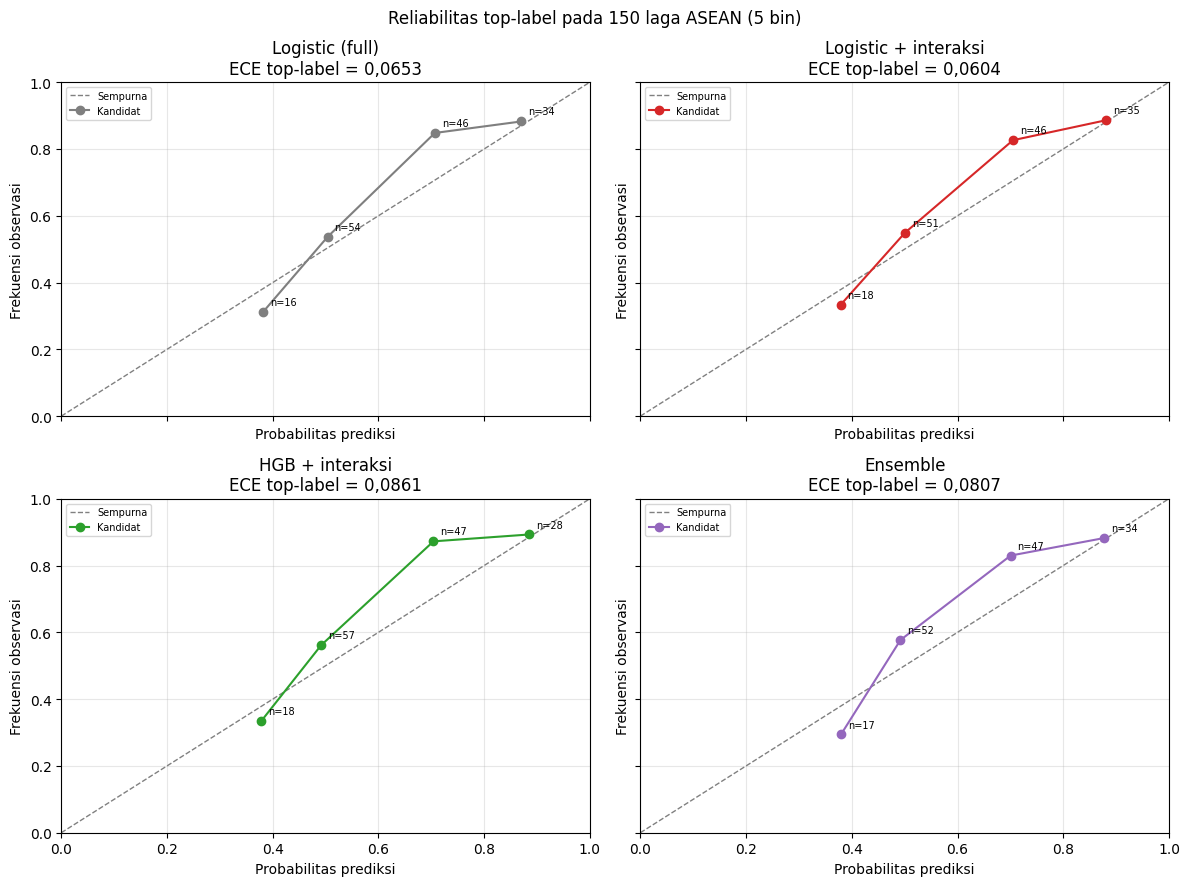

In [84]:
tabel_kal7 = pd.DataFrame([
    {
        "kandidat": nama,
        "ece_top": expected_calibration_error(
            pred_asean7[nama]["y"],
            pred_asean7[nama][["p_H", "p_D", "p_A"]].to_numpy(),
            n_bins=BINS_ASEAN,
        ),
        "ece_classwise": classwise_ece(
            pred_asean7[nama]["y"],
            pred_asean7[nama][["p_H", "p_D", "p_A"]].to_numpy(),
            n_bins=BINS_ASEAN,
        ),
    }
    for nama in NAMA7
])
print("ECE pada 150 laga ASEAN:")
print(tampil_metrik(tabel_kal7, kolom=("ece_top", "ece_classwise")).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, nama in zip(axes.ravel(), NAMA7):
    pred = pred_asean7[nama]
    tabel = reliability_table(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Sempurna")
    ax.plot(
        tabel["prediksi_rata"], tabel["observasi"],
        marker="o", lw=1.5, color=WARNA7[nama], label="Kandidat",
    )
    for _, row in tabel.iterrows():
        ax.annotate(
            f"n={int(row['n'])}", (row["prediksi_rata"], row["observasi"]),
            textcoords="offset points", xytext=(5, 5), fontsize=7,
        )
    ece = expected_calibration_error(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.set_title(f"{nama}\nECE top-label = {fmt(ece, 4)}")
    ax.set_xlabel("Probabilitas prediksi")
    ax.set_ylabel("Frekuensi observasi")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle(
    f"Reliabilitas top-label pada {len(pred_asean7[NAMA7[0]])} laga ASEAN ({BINS_ASEAN} bin)",
    fontsize=12,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_16_kalibrasi_kandidat_asean.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi kalibrasi.** Logistic interaksi memiliki ECE top-label **0,0604** dan ECE classwise **0,0480**, lebih baik daripada logistic full (**0,0653/0,0513**), HGB (**0,0861/0,0559**), dan ensemble (**0,0807/0,0566**). HGB dan ensemble memang sedikit lebih berani pada prediksi kelas minoritas, tetapi keyakinannya kurang terkalibrasi. Untuk aplikasi yang memakai probabilitas sebagai input simulasi, logistic interaksi lebih aman.

### 7.11 Ringkasan Section 7

Section 7 membandingkan empat kandidat pada protokol yang sama. Ringkasan berikut memakai 150 laga ASEAN sebagai evaluasi akhir, tetapi pemilihan konfigurasi tetap dilakukan pada fold tahunan.

In [85]:
ringkasan7 = tabel_a7.copy()
ringkasan7["perbaikan_log_loss_vs_full"] = (
    (tabel_a7.loc[tabel_a7["kandidat"] == "Logistic (full)", "log_loss"].iloc[0]
     - ringkasan7["log_loss"]) / tabel_a7.loc[tabel_a7["kandidat"] == "Logistic (full)", "log_loss"].iloc[0] * 100
)
ringkasan7["perbaikan_log_loss_vs_full"] = ringkasan7["perbaikan_log_loss_vs_full"].map(
    lambda v: fmt(v, 2) + "%"
)

print("Ringkasan kandidat Section 7 pada 150 laga ASEAN:")
print(tampil_metrik(
    ringkasan7[["kandidat", "n", "log_loss", "brier", "rps", "accuracy", "macro_f1", "ece_top", "perbaikan_log_loss_vs_full"]]
).to_string(index=False))

print("\nKandidat terbaik per metrik:")
for kolom, arah in [("log_loss", "min"), ("brier", "min"), ("rps", "min"),
                    ("accuracy", "max"), ("macro_f1", "max"), ("ece_top", "min")]:
    idx = tabel_a7[kolom].idxmin() if arah == "min" else tabel_a7[kolom].idxmax()
    print(f"  {kolom:12s}: {tabel_a7.loc[idx, 'kandidat']} ({fmt(tabel_a7.loc[idx, kolom], 4)})")

print("\nCek anti-leakage:")
for nama in NAMA7:
    assert pred_tahunan7[nama]["date"].max() < CUTOFF_TEST
    assert pred_asean7[nama]["date"].max() < CUTOFF_TEST
print(f"  Semua prediksi berakhir sebelum {CUTOFF_TEST.date()}; final_test tidak dibuka.")

Ringkasan kandidat Section 7 pada 150 laga ASEAN:
            kandidat   n log_loss  brier    rps accuracy macro_f1 ece_top perbaikan_log_loss_vs_full
     Logistic (full) 150   0,7337 0,4197 0,1338   0,6867   0,4865  0,0653                      0,00%
Logistic + interaksi 150   0,7278 0,4170 0,1330   0,6867   0,4865  0,0604                      0,80%
     HGB + interaksi 150   0,7417 0,4236 0,1350   0,6933   0,4947  0,0861                     -1,09%
            Ensemble 150   0,7306 0,4180 0,1333   0,6933   0,4957  0,0807                      0,42%

Kandidat terbaik per metrik:
  log_loss    : Logistic + interaksi (0,7278)
  brier       : Logistic + interaksi (0,4170)
  rps         : Logistic + interaksi (0,1330)
  accuracy    : HGB + interaksi (0,6933)
  macro_f1    : Ensemble (0,4957)
  ece_top     : Logistic + interaksi (0,0604)

Cek anti-leakage:
  Semua prediksi berakhir sebelum 2024-12-08; final_test tidak dibuka.


**Kesimpulan Section 7.** Model yang dipilih adalah **Logistic Regression dengan fitur `full_interaksi` dan `C=1,0`**. Pada fold tahunan model ini memberi log loss mean **0,8890** dan pooled **0,8822**; pada 150 laga ASEAN memberi log loss **0,7278**, Brier **0,4170**, RPS **0,1330**, akurasi **68,67%**, macro-F1 **0,4865**, dan ECE top-label **0,0604**. Perbaikan terhadap baseline logistic Section 6 memang kecil, tetapi arahnya stabil: selisih ASEAN **-0,0059** dengan 95% CI **[-0,0084; -0,0022]** dan perbaikan di 6 dari 7 edisi.

HGB dan ensemble tidak dipilih. HGB memberi log loss ASEAN **0,7417**, sedangkan ensemble **0,7306**; keduanya lebih buruk daripada logistic interaksi pada metrik probabilitas utama. Ensemble hanya unggul tipis pada fold tahunan (0,8886 vs 0,8890) dan keunggulan itu tidak terbawa ke ASEAN. Dengan demikian, Section 8 akan memakai **logistic `full_interaksi`, C=1,0** sebagai model final, tanpa membuka `final_test` sebelum protokol Section 8 dijalankan.

## 8. Evaluasi

Section ini membuka `final_test` satu kali setelah konfigurasi model dibekukan di Section 7. Tujuannya bukan mencari model baru, tetapi mengukur apakah model final dan baseline tetap berperilaku wajar pada periode yang sama sekali belum dipakai.

Cakupan evaluasi:

- **Final test mentah**: 1.852 baris (`date >= 2024-12-08`).
- **FIFA ASEAN Cup**: 14 baris dikeluarkan dari feature history dan dari semua metrik, sesuai keputusan Section 5.
- **Final test yang dievaluasi**: 1.838 baris.
- **Fokus utama**: 52 laga `ASEAN Championship` (dua edisi: 2024 dan 2026, masing-masing 26 laga).
- **Pembanding**: 1.786 laga internasional lain pada periode uji yang sama.

Model final yang dibekukan adalah **Logistic Regression `full_interaksi`, C=1,0**. Baseline prior, Elo murni, dan logistic baseline dilatih ulang hanya pada `dev` (48.093 laga); tidak ada satu baris `final_test` yang masuk ke proses fitting atau pemilihan konfigurasi.

### 8.1 Protokol dan cakupan

`final_test` dipakai untuk tiga hal saja: menghitung metrik, memeriksa kalibrasi, dan membandingkan model final dengan baseline. Tidak ada hyperparameter, threshold, atau aturan kalibrasi yang diubah setelah hasil ini terlihat. Bila model final tidak lebih baik dari baseline, hasilnya dilaporkan apa adanya.

In [86]:
from src.evaluation.final_test import TURNAMEN_ASEAN, load_final_test
from src.evaluation.validation import load_dev_features

assert "PROJECT_ROOT" in globals()
final_mentah, fitur_final = load_final_test(PROJECT_ROOT)
fitur_dev8 = load_dev_features(PROJECT_ROOT)

ASEAN8 = fitur_final.loc[fitur_final["tournament"] == TURNAMEN_ASEAN].copy()
ASEAN8["edisi"] = np.where(ASEAN8["date"] < pd.Timestamp("2026-01-01"), "2024", "2026")
LAIN8 = fitur_final.loc[fitur_final["tournament"] != TURNAMEN_ASEAN].copy()
LAIN8["edisi"] = np.nan
ALL8 = pd.concat([ASEAN8, LAIN8], ignore_index=True)

WARNA8 = {
    "Prior kelas": "#7f7f7f",
    "Elo murni": "#1f77b4",
    "Logistic baseline": "#ff7f0e",
    "Logistic + interaksi (final)": "#d62728",
}
NAMA8 = list(WARNA8)

tabel_cakupan8 = pd.DataFrame([
    {"cakupan": "Final test mentah", "n": len(final_mentah), "keterangan": "date >= 2024-12-08"},
    {"cakupan": "FIFA ASEAN Cup", "n": int((final_mentah["tournament"] == "FIFA ASEAN Cup").sum()), "keterangan": "dikeluarkan dari fitur dan metrik"},
    {"cakupan": "Final test dievaluasi", "n": len(fitur_final), "keterangan": "1.852 - 14"},
    {"cakupan": "ASEAN Championship", "n": len(ASEAN8), "keterangan": "2 edisi x 26 laga"},
    {"cakupan": "Internasional lain", "n": len(LAIN8), "keterangan": "periode uji yang sama"},
])
tabel_cakupan8["n"] = tabel_cakupan8["n"].map(ribuan)

print("Cakupan final test:")
print(tabel_cakupan8.to_string(index=False))
print(f"\nRentang fitur final: {fitur_final['date'].min().date()} s/d {fitur_final['date'].max().date()}")
print(f"FIFA ASEAN Cup di fitur final: {int((fitur_final['tournament'] == 'FIFA ASEAN Cup').sum())}")
print("Jumlah per edisi ASEAN:")
print(ASEAN8["edisi"].value_counts().sort_index().to_string())

assert len(final_mentah) == 1852
assert len(fitur_final) == 1838
assert len(ASEAN8) == 52
assert len(LAIN8) == 1786
assert len(ALL8) == 1838
assert fitur_dev8["date"].max() < CUTOFF_TEST
assert fitur_final["date"].min() >= CUTOFF_TEST
assert (fitur_final["tournament"] == "FIFA ASEAN Cup").sum() == 0

Cakupan final test:
              cakupan     n                        keterangan
    Final test mentah 1.852                date >= 2024-12-08
       FIFA ASEAN Cup    14 dikeluarkan dari fitur dan metrik
Final test dievaluasi 1.838                        1.852 - 14
   ASEAN Championship    52                 2 edisi x 26 laga
   Internasional lain 1.786             periode uji yang sama

Rentang fitur final: 2024-12-08 s/d 2026-10-06
FIFA ASEAN Cup di fitur final: 0
Jumlah per edisi ASEAN:
edisi
2024    26
2026    26


**Cek cakupan.** Final test mentah berisi 1.852 baris; 14 di antaranya `FIFA ASEAN Cup` dan dikeluarkan, sehingga 1.838 baris dievaluasi. Dari jumlah itu, 52 adalah `ASEAN Championship` dan 1.786 adalah laga internasional lain. Dua edisi ASEAN terbagi rata, 26 laga per edisi. Semua baris fitur final berasal dari tanggal cutoff atau sesudahnya, dan tidak ada `FIFA ASEAN Cup` yang masuk ke fitur.

### 8.2 Model final dan baseline

Semua model dilatih pada `dev` saja. Model final memakai konfigurasi yang sudah dibekukan di Section 7: logistic `full_interaksi`, `C=1,0`, `max_iter=2000`. Elo murni memakai parameter `beta` dan `nu` yang diestimasi pada `dev`, bukan pada final test.

In [87]:
import yaml

from src.models.baselines import EloDavidson, PriorBaseline, build_logistic_baseline
from src.models.candidates import build_logistic_candidate

with open(PROJECT_ROOT / "configs" / "config.yaml", encoding="utf-8") as f:
    CFG8 = yaml.safe_load(f)
BASE8 = CFG8["baseline"]
EVAL8 = CFG8["evaluation"]

y_dev8 = encode_labels(fitur_dev8["result"])
model_prior8 = PriorBaseline().fit(None, y_dev8)
model_elo8 = EloDavidson(
    home_adv=BASE8["elo"]["home_adv"],
    beta_init=BASE8["elo"]["beta_init"],
    nu_init=BASE8["elo"]["nu_init"],
    beta_bounds=tuple(BASE8["elo"]["beta_bounds"]),
    nu_bounds=tuple(BASE8["elo"]["nu_bounds"]),
).fit(fitur_dev8, y_dev8)
model_log8 = build_logistic_baseline(
    C=BASE8["logistic"]["C"], max_iter=BASE8["logistic"]["max_iter"]
).fit(fitur_dev8, y_dev8)
model_final8 = build_logistic_candidate(
    feature_set="full_interaksi", C=1.0, max_iter=BASE8["logistic"]["max_iter"]
).fit(fitur_dev8, y_dev8)

MODEL8 = {
    "Prior kelas": model_prior8,
    "Elo murni": model_elo8,
    "Logistic baseline": model_log8,
    "Logistic + interaksi (final)": model_final8,
}
print(f"Data latih: {ribuan(len(fitur_dev8))} laga dev")
print("Prior dev (H, D, A):", np.round(model_prior8.proba_, 4))
print(f"Elo: beta={model_elo8.beta_:.6f}, nu={model_elo8.nu_:.4f}")
print("Model final: logistic full_interaksi, C=1.0")

Data latih: 48.093 laga dev
Prior dev (H, D, A): [0.4904 0.2273 0.2823]
Elo: beta=0.007138, nu=0.7534
Model final: logistic full_interaksi, C=1.0


**Cek fitting.** Empat model memakai data latih yang sama, yaitu 48.093 laga `dev`. Tidak ada baris final test yang dipakai untuk mengestimasi prior, `beta`/`nu` Elo, koefisien logistic, imputasi, standardisasi, atau one-hot encoding. Model final tetap konfigurasi Section 7; tidak ada penyetelan ulang setelah final test dibuka.

### 8.3 Metrik pada final test

Tiga cakupan dilaporkan terpisah: **ASEAN Championship** (52 laga, fokus utama), **internasional lain** (1.786 laga, pembanding), dan **gabungan** (1.838 laga). Pemisahan ini penting karena final test didominasi laga non-ASEAN; metrik gabungan tidak boleh dipakai sebagai pengganti evaluasi ASEAN.

In [88]:
def buat_prediksi8(nama, model, data):
    proba = np.asarray(model.predict_proba(data), dtype=float)
    if proba.shape != (len(data), 3):
        raise ValueError(f"proba {nama} berukuran {proba.shape}, bukan {(len(data), 3)}")
    if not np.allclose(proba.sum(axis=1), 1.0, atol=1e-8):
        raise ValueError(f"proba {nama} tidak berjumlah 1")
    return pd.DataFrame({
        "model": nama,
        "fold": "final",
        "match_id": data["match_id"].to_numpy(),
        "date": data["date"].to_numpy(),
        "home_team": data["home_team"].to_numpy(),
        "away_team": data["away_team"].to_numpy(),
        "tournament": data["tournament"].to_numpy(),
        "edisi": data["edisi"].to_numpy(),
        "y": data["result"].to_numpy(),
        "p_H": proba[:, 0],
        "p_D": proba[:, 1],
        "p_A": proba[:, 2],
    })


pred_asean8 = {nama: buat_prediksi8(nama, model, ASEAN8) for nama, model in MODEL8.items()}
pred_lain8 = {nama: buat_prediksi8(nama, model, LAIN8) for nama, model in MODEL8.items()}
pred_all8 = {nama: buat_prediksi8(nama, model, ALL8) for nama, model in MODEL8.items()}


def tabel_metrik8(pred, n_bins):
    return pd.DataFrame([
        {"model": nama, "n": len(pred[nama]), **pooled_metrics(pred[nama], n_bins=n_bins)}
        for nama in NAMA8
    ])


tabel_asean8 = tabel_metrik8(pred_asean8, BINS_ASEAN)
tabel_lain8 = tabel_metrik8(pred_lain8, BINS_TAHUNAN)
tabel_all8 = tabel_metrik8(pred_all8, BINS_TAHUNAN)

kolom8 = ["model", "n", "log_loss", "brier", "rps", "accuracy", "macro_f1", "ece_top", "ece_classwise"]
print("ASEAN Championship (52 laga):")
print(tampil_metrik(tabel_asean8[kolom8]).to_string(index=False))
print("\nInternasional lain (1.786 laga):")
print(tampil_metrik(tabel_lain8[kolom8]).to_string(index=False))
print("\nGabungan (1.838 laga):")
print(tampil_metrik(tabel_all8[kolom8]).to_string(index=False))

ASEAN Championship (52 laga):
                       model  n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise
                 Prior kelas 52   1,0686 0,6502 0,2521   0,4231   0,1982  0,0673        0,0810
                   Elo murni 52   0,8340 0,4792 0,1686   0,6731   0,4879  0,0859        0,0725
           Logistic baseline 52   0,8219 0,4708 0,1658   0,6731   0,4879  0,0661        0,0816
Logistic + interaksi (final) 52   0,8198 0,4704 0,1655   0,6731   0,4879  0,0704        0,0927

Internasional lain (1.786 laga):
                       model     n log_loss  brier    rps accuracy macro_f1 ece_top ece_classwise
                 Prior kelas 1.786   1,0472 0,6314 0,2291   0,4815   0,2167  0,0088        0,0089
                   Elo murni 1.786   0,8514 0,5005 0,1662   0,6120   0,4480  0,0210        0,0188
           Logistic baseline 1.786   0,8488 0,4994 0,1661   0,6125   0,4575  0,0164        0,0242
Logistic + interaksi (final) 1.786   0,8481 0,4990 0,1660   0,6114   

**Interpretasi metrik.** Pada 52 laga ASEAN, model final memberi log loss **0,8198**, Brier **0,4704**, RPS **0,1655**, akurasi **67,31%**, macro-F1 **48,79%**, dan ECE top-label **0,0704**. Baseline logistic berada di **0,8219/0,4708/0,1658**, dengan akurasi dan macro-F1 yang sama; Elo murni di **0,8340/0,4792/0,1686**; prior di **1,0686/0,6502/0,2521**. Model final unggul tipis pada log loss, Brier, dan RPS, tetapi belum tentu stabil secara statistik.

Pada 1.786 laga internasional lain, urutannya tetap: model final **0,8481**, logistic baseline **0,8488**, Elo **0,8514**, prior **1,0472**. Akurasi model final **61,14%**, sedikit di bawah logistic baseline **61,25%**. Pada gabungan 1.838 laga, model final **0,8473**, logistic baseline **0,8481**, Elo **0,8510**, prior **1,0478**. Pola utamanya: model final dan logistic baseline hampir setara; keduanya jelas di atas prior dan sedikit di atas Elo pada log loss.

### 8.4 Stabilitas per edisi dan perbandingan berpasangan

Karena semua model memprediksi laga yang sama, selisih metrik diuji dengan paired bootstrap per laga. Untuk cakupan gabungan, resampling dilakukan per turnamen agar korelasi laga dalam satu turnamen tidak diabaikan. Tanda negatif berarti model final lebih baik (log loss/Brier lebih rendah).

Log loss per edisi ASEAN:
      Elo murni Logistic + interaksi (final) Logistic baseline Prior kelas
edisi                                                                     
2024     0,9096                       0,8955            0,8880      1,0599
2026     0,7584                       0,7442            0,7558      1,0773



CI bootstrap per laga (ASEAN):
  metrik estimate ci_low ci_high  n_boot                        model
log_loss   1,0686 0,9795  1,1554    2000                  Prior kelas
   brier   0,6502 0,5857  0,7109    2000                  Prior kelas
accuracy   0,4231 0,2885  0,5577    2000                  Prior kelas
macro_f1   0,1982 0,1493  0,2387    2000                  Prior kelas
log_loss   0,8340 0,6339  1,0507    2000                    Elo murni
   brier   0,4792 0,3446  0,6233    2000                    Elo murni
accuracy   0,6731 0,5385  0,8077    2000                    Elo murni
macro_f1   0,4879 0,4013  0,5640    2000                    Elo murni
log_loss   0,8219 0,6157  1,0457    2000            Logistic baseline
   brier   0,4708 0,3380  0,6111    2000            Logistic baseline
accuracy   0,6731 0,5385  0,8077    2000            Logistic baseline
macro_f1   0,4879 0,4013  0,5640    2000            Logistic baseline
log_loss   0,8198 0,6097  1,0426    2000 Logistic + intera


Selisih berpasangan pada 52 laga ASEAN:
  metrik estimate  ci_low ci_high proporsi_positif  n_boot                                         pasangan
log_loss  -0,0021 -0,0171  0,0155            36,9%    2000 Logistic + interaksi (final) - Logistic baseline
   brier  -0,0004 -0,0046  0,0043            41,5%    2000 Logistic + interaksi (final) - Logistic baseline
accuracy   0,0000  0,0000  0,0000             0,0%    2000 Logistic + interaksi (final) - Logistic baseline
macro_f1   0,0000  0,0000  0,0000             0,0%    2000 Logistic + interaksi (final) - Logistic baseline
log_loss  -0,0142 -0,0431  0,0178            18,4%    2000         Logistic + interaksi (final) - Elo murni
   brier  -0,0088 -0,0248  0,0081            14,9%    2000         Logistic + interaksi (final) - Elo murni
accuracy   0,0000  0,0000  0,0000             0,0%    2000         Logistic + interaksi (final) - Elo murni
macro_f1   0,0000  0,0000  0,0000             0,0%    2000         Logistic + interaksi (final)


Selisih berpasangan pada 1.838 laga gabungan (cluster turnamen):
  metrik estimate  ci_low ci_high proporsi_positif  n_boot                                         pasangan
log_loss  -0,0007 -0,0023  0,0019            24,5%    2000 Logistic + interaksi (final) - Logistic baseline
   brier  -0,0004 -0,0013  0,0008            23,4%    2000 Logistic + interaksi (final) - Logistic baseline
log_loss  -0,0036 -0,0116  0,0033            13,9%    2000         Logistic + interaksi (final) - Elo murni
   brier  -0,0017 -0,0059  0,0029            20,8%    2000         Logistic + interaksi (final) - Elo murni
log_loss  -0,2004 -0,2452 -0,1459             0,0%    2000       Logistic + interaksi (final) - Prior kelas
   brier  -0,1337 -0,1626 -0,0995             0,0%    2000       Logistic + interaksi (final) - Prior kelas

Selisih log loss per edisi (final - logistic baseline):
edisi  final  logistic_baseline  selisih
 2024 0.8955             0.8880   0.0074
 2026 0.7442             0.7558  -0.011

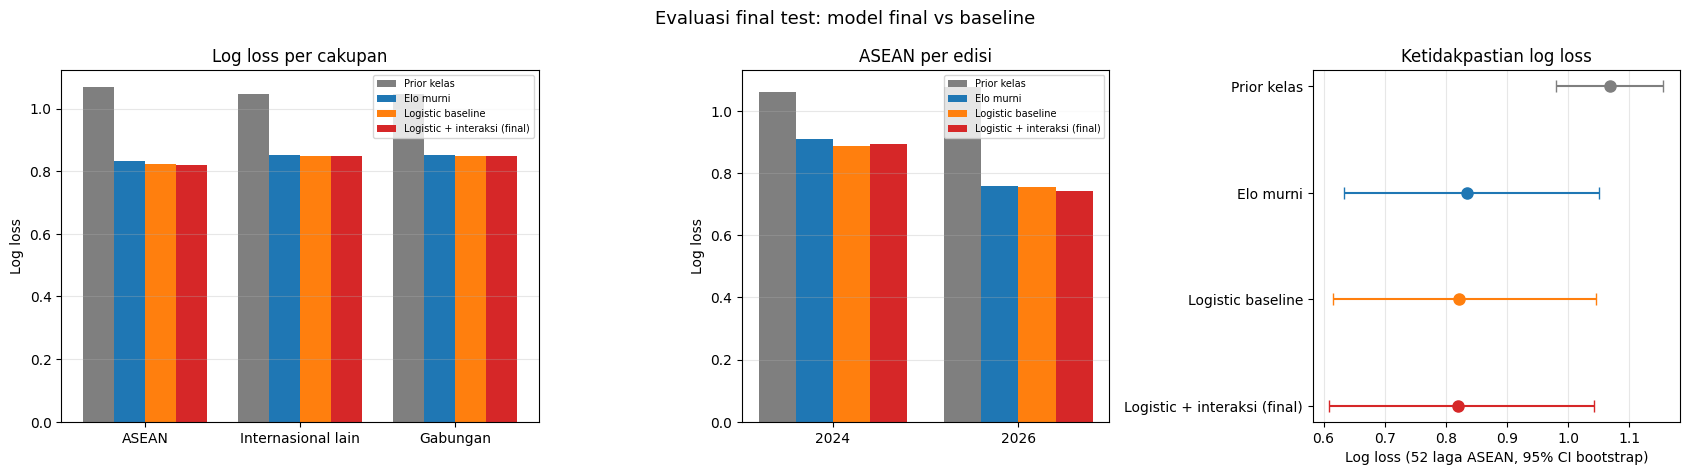

In [89]:
per_edisi8 = pd.concat([
    metrics_by_group(pred_asean8[nama], group_col="edisi", n_bins=BINS_ASEAN).assign(model=nama)
    for nama in NAMA8
], ignore_index=True)
pivot_edisi8 = per_edisi8.pivot(index="edisi", columns="model", values="log_loss")
pivot_edisi8.columns.name = None
print("Log loss per edisi ASEAN:")
print(pivot_edisi8.map(lambda v: fmt(v, 4)).to_string())

ci_asean8 = pd.concat([
    bootstrap_metrics_table(
        pred_asean8[nama],
        n_boot=EVAL8["n_bootstrap"],
        seed=EVAL8["seed"],
        alpha=EVAL8["alpha"],
        cluster_col=None,
    ).assign(model=nama)
    for nama in NAMA8
], ignore_index=True)
print("\nCI bootstrap per laga (ASEAN):")
print(tampil_interval(
    ci_asean8[ci_asean8["metrik"].isin(["log_loss", "brier", "accuracy", "macro_f1"])]
).to_string(index=False))

pasangan_asean8 = [
    ("Logistic + interaksi (final)", "Logistic baseline"),
    ("Logistic + interaksi (final)", "Elo murni"),
    ("Logistic + interaksi (final)", "Prior kelas"),
]
baris_delta = []
for a, b in pasangan_asean8:
    tabel = paired_delta_table(
        pred_asean8[a], pred_asean8[b],
        n_boot=EVAL8["n_bootstrap"], seed=EVAL8["seed"],
        alpha=EVAL8["alpha"], cluster_col=None,
    )
    tabel["pasangan"] = f"{a} - {b}"
    baris_delta.append(tabel)
delta_asean8 = pd.concat(baris_delta, ignore_index=True)
print("\nSelisih berpasangan pada 52 laga ASEAN:")
print(tampil_interval(
    delta_asean8[delta_asean8["metrik"].isin(["log_loss", "brier", "accuracy", "macro_f1"])]
).to_string(index=False))

pasangan_all8 = [
    ("Logistic + interaksi (final)", "Logistic baseline"),
    ("Logistic + interaksi (final)", "Elo murni"),
    ("Logistic + interaksi (final)", "Prior kelas"),
]
baris_delta = []
for a, b in pasangan_all8:
    tabel = paired_delta_table(
        pred_all8[a], pred_all8[b],
        n_boot=EVAL8["n_bootstrap"], seed=EVAL8["seed"],
        alpha=EVAL8["alpha"], cluster_col="tournament",
    )
    tabel["pasangan"] = f"{a} - {b}"
    baris_delta.append(tabel)
delta_all8 = pd.concat(baris_delta, ignore_index=True)
print("\nSelisih berpasangan pada 1.838 laga gabungan (cluster turnamen):")
print(tampil_interval(
    delta_all8[delta_all8["metrik"].isin(["log_loss", "brier"])]
).to_string(index=False))

tabel_delta_edisi8 = pd.DataFrame({
    "edisi": ["2024", "2026"],
    "final": [
        pivot_edisi8.loc["2024", "Logistic + interaksi (final)"],
        pivot_edisi8.loc["2026", "Logistic + interaksi (final)"],
    ],
    "logistic_baseline": [
        pivot_edisi8.loc["2024", "Logistic baseline"],
        pivot_edisi8.loc["2026", "Logistic baseline"],
    ],
})
tabel_delta_edisi8["selisih"] = tabel_delta_edisi8["final"] - tabel_delta_edisi8["logistic_baseline"]
print("\nSelisih log loss per edisi (final - logistic baseline):")
print(tabel_delta_edisi8.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
cakupan = [("ASEAN", tabel_asean8), ("Internasional lain", tabel_lain8), ("Gabungan", tabel_all8)]
x = np.arange(len(cakupan))
lebar = 0.2
for i, nama in enumerate(NAMA8):
    nilai = [tabel.loc[tabel["model"] == nama, "log_loss"].iloc[0] for _, tabel in cakupan]
    axes[0].bar(x + (i - 1.5) * lebar, nilai, lebar, label=nama, color=WARNA8[nama])
axes[0].set_xticks(x)
axes[0].set_xticklabels([nama for nama, _ in cakupan])
axes[0].set_ylabel("Log loss")
axes[0].set_title("Log loss per cakupan")
axes[0].grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=7)

edisi_plot = ["2024", "2026"]
x = np.arange(len(edisi_plot))
for i, nama in enumerate(NAMA8):
    nilai = [pivot_edisi8.loc[e, nama] for e in edisi_plot]
    axes[1].bar(x + (i - 1.5) * lebar, nilai, lebar, label=nama, color=WARNA8[nama])
axes[1].set_xticks(x)
axes[1].set_xticklabels(edisi_plot)
axes[1].set_ylabel("Log loss")
axes[1].set_title("ASEAN per edisi")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(fontsize=7)

for i, nama in enumerate(NAMA8):
    row = ci_asean8[(ci_asean8["model"] == nama) & (ci_asean8["metrik"] == "log_loss")].iloc[0]
    axes[2].errorbar(
        row["estimate"], i,
        xerr=[[row["estimate"] - row["ci_low"]], [row["ci_high"] - row["estimate"]]],
        fmt="o", color=WARNA8[nama], capsize=4, ms=8,
    )
axes[2].set_yticks(np.arange(len(NAMA8)))
axes[2].set_yticklabels(NAMA8)
axes[2].invert_yaxis()
axes[2].set_xlabel("Log loss (52 laga ASEAN, 95% CI bootstrap)")
axes[2].set_title("Ketidakpastian log loss")
axes[2].grid(axis="x", alpha=0.3)

fig.suptitle("Evaluasi final test: model final vs baseline", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_17_evaluasi_final_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi stabilitas.** Pada 52 laga ASEAN, selisih log loss model final vs prior adalah **-0,2488** dengan 95% CI **[-0,4315; -0,0667]**, jadi keunggulan atas prior jelas. Selisih vs Elo **-0,0142** dengan CI **[-0,0431; +0,0178]**, dan vs logistic baseline **-0,0021** dengan CI **[-0,0171; +0,0155]**. Kedua interval melewati nol: model final belum terbukti lebih baik dari Elo maupun logistic baseline pada level ASEAN.

Pada gabungan 1.838 laga, selisih vs prior **-0,2004** (CI **[-0,2452; -0,1459]**), vs Elo **-0,0036** (CI **[-0,0116; +0,0033]**), dan vs logistic baseline **-0,0007** (CI **[-0,0023; +0,0019]**). Lagi-lagi hanya keunggulan atas prior yang stabil. Secara per edisi, model final lebih baik pada edisi 2026 (**0,7442** vs **0,7558**) tetapi lebih buruk pada edisi 2024 (**0,8955** vs **0,8880**); perbaikan agregat berasal dari satu edisi, bukan pola yang konsisten.

### 8.5 Kalibrasi final test

ECE dan reliability diagram diperiksa pada 52 laga ASEAN. Pembanding internasional lain dilaporkan sebagai tabel, tetapi diagram reliabilitas difokuskan pada ASEAN agar tidak didominasi 1.786 laga non-ASEAN.

ECE final test:
           cakupan                        model ece_top ece_classwise
             ASEAN                  Prior kelas  0,0673        0,0810
             ASEAN                    Elo murni  0,0859        0,0725
             ASEAN            Logistic baseline  0,0661        0,0816
             ASEAN Logistic + interaksi (final)  0,0704        0,0927
Internasional lain                  Prior kelas  0,0088        0,0089
Internasional lain                    Elo murni  0,0210        0,0188
Internasional lain            Logistic baseline  0,0164        0,0242
Internasional lain Logistic + interaksi (final)  0,0172        0,0275


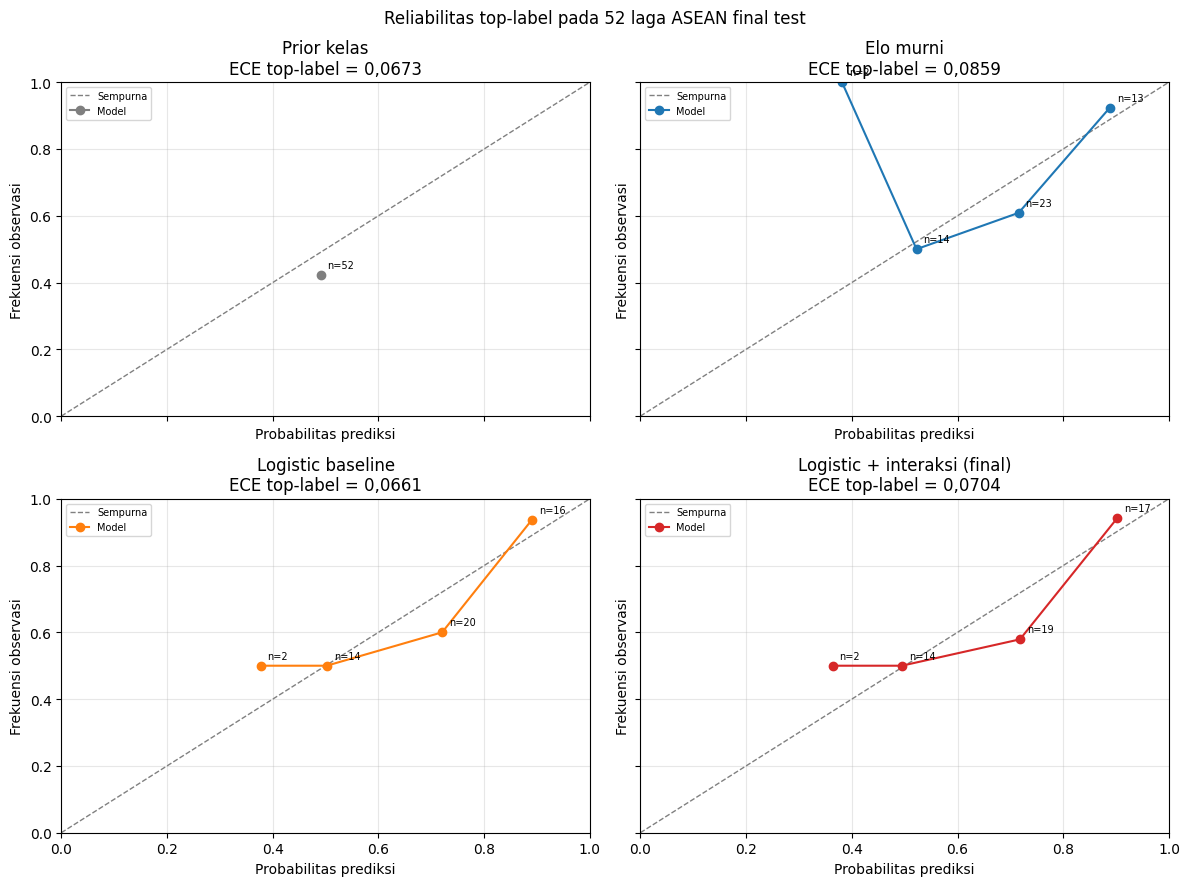

In [90]:
tabel_kal8 = pd.DataFrame([
    {
        "cakupan": cakupan,
        "model": nama,
        "ece_top": expected_calibration_error(
            kumpulan[nama]["y"], kumpulan[nama][["p_H", "p_D", "p_A"]].to_numpy(), n_bins=bins
        ),
        "ece_classwise": classwise_ece(
            kumpulan[nama]["y"], kumpulan[nama][["p_H", "p_D", "p_A"]].to_numpy(), n_bins=bins
        ),
    }
    for cakupan, kumpulan, bins in [
        ("ASEAN", pred_asean8, BINS_ASEAN),
        ("Internasional lain", pred_lain8, BINS_TAHUNAN),
    ]
    for nama in NAMA8
])
print("ECE final test:")
print(tampil_metrik(tabel_kal8, kolom=("ece_top", "ece_classwise")).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, nama in zip(axes.ravel(), NAMA8):
    pred = pred_asean8[nama]
    tabel = reliability_table(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Sempurna")
    ax.plot(
        tabel["prediksi_rata"], tabel["observasi"],
        marker="o", lw=1.5, color=WARNA8[nama], label="Model",
    )
    for _, row in tabel.iterrows():
        ax.annotate(
            f"n={int(row['n'])}", (row["prediksi_rata"], row["observasi"]),
            textcoords="offset points", xytext=(5, 5), fontsize=7,
        )
    ece = expected_calibration_error(
        pred["y"], pred[["p_H", "p_D", "p_A"]].to_numpy(), n_bins=BINS_ASEAN
    )
    ax.set_title(f"{nama}\nECE top-label = {fmt(ece, 4)}")
    ax.set_xlabel("Probabilitas prediksi")
    ax.set_ylabel("Frekuensi observasi")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)

fig.suptitle("Reliabilitas top-label pada 52 laga ASEAN final test", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_18_kalibrasi_final_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi kalibrasi.** Pada 52 laga ASEAN, ECE top-label adalah **0,0704** untuk model final, **0,0661** untuk logistic baseline, **0,0859** untuk Elo, dan **0,0673** untuk prior. ECE classwise model final **0,0927**, lebih tinggi dari logistic baseline **0,0816**, Elo **0,0725**, dan prior **0,0810**. Jadi model final tidak unggul pada kalibrasi final test, meskipun log loss-nya sedikit lebih rendah; dengan 52 laga, selisih ECE sebesar ini mudah berubah.

Pada 1.786 laga internasional lain, ECE top-label model final **0,0172**, logistic baseline **0,0164**, Elo **0,0210**, dan prior **0,0088**. Prior paling rendah karena probabilitasnya hampir konstan dan sampelnya besar. Model final dan logistic baseline sama-sama cukup terkalibrasi pada cakupan ini, dengan selisih yang sangat kecil.

### 8.6 Ringkasan Section 8

Ringkasan berikut memakai 52 laga ASEAN sebagai fokus utama, dengan cakupan gabungan sebagai pembanding. Kriteria sukses mengikuti dokumen problem framing: mengalahkan prior dengan jelas, setidaknya menyamai Elo, dan melaporkan hasil negatif apa adanya.

In [91]:
ringkasan8 = tabel_asean8.copy()
prior_ll8 = tabel_asean8.loc[tabel_asean8["model"] == "Prior kelas", "log_loss"].iloc[0]
ringkasan8["perbaikan_log_loss_vs_prior"] = (
    (prior_ll8 - ringkasan8["log_loss"]) / prior_ll8 * 100
)
ringkasan8["perbaikan_log_loss_vs_prior"] = ringkasan8["perbaikan_log_loss_vs_prior"].map(
    lambda v: fmt(v, 2) + "%"
)

print("Ringkasan model pada 52 laga ASEAN:")
print(tampil_metrik(
    ringkasan8[["model", "n", "log_loss", "brier", "rps", "accuracy", "macro_f1", "ece_top", "perbaikan_log_loss_vs_prior"]]
).to_string(index=False))

print("\nModel terbaik per metrik (ASEAN):")
for kolom, arah in [("log_loss", "min"), ("brier", "min"), ("rps", "min"),
                    ("accuracy", "max"), ("macro_f1", "max"), ("ece_top", "min")]:
    idx = tabel_asean8[kolom].idxmin() if arah == "min" else tabel_asean8[kolom].idxmax()
    print(f"  {kolom:12s}: {tabel_asean8.loc[idx, 'model']} ({fmt(tabel_asean8.loc[idx, kolom], 4)})")

print("\nKriteria sukses (log loss, final - baseline):")
for baseline in ["Prior kelas", "Elo murni", "Logistic baseline"]:
    row = delta_asean8[
        (delta_asean8["pasangan"] == f"Logistic + interaksi (final) - {baseline}")
        & (delta_asean8["metrik"] == "log_loss")
    ].iloc[0]
    status = "CI seluruhnya < 0" if row["ci_high"] < 0 else "CI melewati 0"
    print(f"  vs {baseline:18s}: {fmt(row['estimate'], 4)} "
          f"[{fmt(row['ci_low'], 4)}; {fmt(row['ci_high'], 4)}] -> {status}")

print("\nCek anti-leakage:")
assert fitur_dev8["date"].max() < CUTOFF_TEST
assert fitur_final["date"].min() >= CUTOFF_TEST
assert (fitur_final["tournament"] == "FIFA ASEAN Cup").sum() == 0
for nama in NAMA8:
    assert pred_asean8[nama]["date"].min() >= CUTOFF_TEST
    assert pred_all8[nama]["date"].min() >= CUTOFF_TEST
print(f"  dev berakhir {fitur_dev8['date'].max().date()}; final test mulai {fitur_final['date'].min().date()}")
print("  FIFA ASEAN Cup tidak masuk fitur maupun metrik; final test dibuka satu kali di Section 8.")

Ringkasan model pada 52 laga ASEAN:
                       model  n log_loss  brier    rps accuracy macro_f1 ece_top perbaikan_log_loss_vs_prior
                 Prior kelas 52   1,0686 0,6502 0,2521   0,4231   0,1982  0,0673                       0,00%
                   Elo murni 52   0,8340 0,4792 0,1686   0,6731   0,4879  0,0859                      21,96%
           Logistic baseline 52   0,8219 0,4708 0,1658   0,6731   0,4879  0,0661                      23,09%
Logistic + interaksi (final) 52   0,8198 0,4704 0,1655   0,6731   0,4879  0,0704                      23,28%

Model terbaik per metrik (ASEAN):
  log_loss    : Logistic + interaksi (final) (0,8198)
  brier       : Logistic + interaksi (final) (0,4704)
  rps         : Logistic + interaksi (final) (0,1655)
  accuracy    : Elo murni (0,6731)
  macro_f1    : Elo murni (0,4879)
  ece_top     : Logistic baseline (0,0661)

Kriteria sukses (log loss, final - baseline):
  vs Prior kelas       : -0,2488 [-0,4315; -0,0667] -> CI selu

**Kesimpulan Section 8.** Model final **Logistic Regression `full_interaksi`, C=1,0** memenuhi kriteria pertama dengan jelas: pada 52 laga ASEAN log loss **0,8198** vs prior **1,0686**, selisih **-0,2488** dengan 95% CI **[-0,4315; -0,0667]**. Model juga sedikit lebih baik dari Elo (**0,8340**) dan logistic baseline (**0,8219**) pada titik estimasi, tetapi selisihnya tidak stabil: CI vs Elo **[-0,0431; +0,0178]** dan vs logistic baseline **[-0,0171; +0,0155]** sama-sama melewati nol. Pada 1.838 laga gabungan, polanya sama: final **0,8473**, logistic baseline **0,8481**, Elo **0,8510**, prior **1,0478**.

Kalibrasi final test melemahkan klaim keunggulan: ECE top-label model final **0,0704**, sedikit lebih tinggi dari logistic baseline **0,0661**; ECE classwise **0,0927**, lebih tinggi dari ketiga pembanding. Secara per edisi, model final lebih baik di edisi 2026 tetapi lebih buruk di edisi 2024. Dengan demikian, hasil Section 8 adalah **menang jelas atas prior, setara dengan Elo dan logistic baseline, tanpa bukti keunggulan yang stabil**. Ini bukan kegagalan yang disembunyikan: model tetap dipakai di Section 9 karena merupakan kandidat terpilih dengan log loss titik terendah, tetapi ketidakpastian dan kalibrasi yang lemah harus dibawa sebagai batasan simulasi.

## 9. Simulasi Monte Carlo

### 9.1 Tujuan, cakupan, dan aturan simulasi

Section ini menjawab pertanyaan kedua project: bila probabilitas H/D/A tiap laga dipakai sebagai undian, seberapa besar peluang tiap tim menjadi juara? Simulasi dijalankan untuk lima edisi yang formatnya lengkap di data: **2018, 2021, 2022, 2024, dan 2026**. Setiap edisi disimulasikan **10.000 kali**.

Aturan yang dipakai:

- **Peserta dan format:** 10 tim, dua grup berisi lima tim, round-robin satu kali (20 laga), dua tim teratas tiap grup lolos.
- **Knockout:** semifinal dan final dua leg. Pemenang dua leg ditentukan dari jumlah kemenangan leg; bila imbang, adu penalti adil 50/50. Model H/D/A tidak menghasilkan skor, sehingga agregat gol tidak dipakai.
- **Tiebreak grup:** poin, lalu poin head-to-head di antara tim yang seri, lalu undian acak.
- **Probabilitas laga:** model logistic final Section 7 (`full_interaksi`, `C=1,0`) dilatih ulang pada seluruh laga sebelum tanggal mulai edisi (walk-forward). Fitur laga turnamen dibekukan pada kondisi pra-turnamen.
- **Monte Carlo error** yang dilaporkan hanya galat sampling proporsi juara, bukan ketidakpastian model.

`FIFA ASEAN Cup` tetap dikeluarkan dari fitur dan tidak dipakai sebagai data latih edisi mana pun.

In [92]:
import time

from src.simulation.monte_carlo import EDITIONS, actual_champion, build_edition_fixtures, run_editions

N_SIM9 = 10_000
SEED9 = 42
matches9 = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "matches_merged.csv", parse_dates=["date"])

assert "fitur_dev8" in globals() and "fitur_final" in globals()
fitur_semua9 = pd.concat([fitur_dev8, fitur_final], ignore_index=True)
assert len(fitur_semua9) == 49_931
assert fitur_semua9["match_id"].is_unique
assert (fitur_semua9["tournament"] == "FIFA ASEAN Cup").sum() == 0

print(f"Fitur kausal tersedia: {ribuan(len(fitur_semua9))} laga non-FIFA")
print(f"Simulasi: {ribuan(N_SIM9)} per edisi, seed={SEED9}")

Fitur kausal tersedia: 49.931 laga non-FIFA
Simulasi: 10.000 per edisi, seed=42


In [93]:
baris_edisi9 = []
for tahun, spec in sorted(EDITIONS.items()):
    grup, knockout = build_edition_fixtures(matches9, spec)
    baris_edisi9.append({
        "edisi": tahun,
        "turnamen": spec.tournament,
        "mulai": grup["date"].min().date(),
        "selesai": knockout["date"].max().date(),
        "laga": len(grup) + len(knockout),
        "grup": len(grup),
        "knockout": len(knockout),
        "juara_aktual": actual_champion(matches9, spec),
    })

tabel_edisi9 = pd.DataFrame(baris_edisi9)
print("Cakupan simulasi:")
print(tabel_edisi9.to_string(index=False))

assert len(tabel_edisi9) == 5
assert (tabel_edisi9["laga"] == 26).all()
assert (tabel_edisi9["grup"] == 20).all()
assert (tabel_edisi9["knockout"] == 6).all()

Cakupan simulasi:
 edisi           turnamen      mulai    selesai  laga  grup  knockout juara_aktual
  2018   AFF Championship 2018-11-08 2018-12-15    26    20         6      Vietnam
  2021   AFF Championship 2021-12-05 2022-01-01    26    20         6     Thailand
  2022   AFF Championship 2022-12-20 2023-01-16    26    20         6     Thailand
  2024 ASEAN Championship 2024-12-08 2025-01-05    26    20         6      Vietnam
  2026 ASEAN Championship 2026-07-24 2026-08-26    26    20         6      Vietnam


### 9.2 Model, data latih, dan probabilitas laga

Model yang dipakai adalah konfigurasi final Section 7: **Logistic Regression `full_interaksi`, C=1,0, max_iter=2000**. Tidak ada hyperparameter baru yang dicari di Section 9. Untuk setiap edisi, model dilatih ulang hanya pada laga sebelum tanggal mulai edisi; edisi yang sedang disimulasikan tidak pernah masuk data latih.

Fitur laga turnamen dihitung dari kondisi **pra-turnamen**: Elo, form, dan head-to-head tidak diperbarui oleh hasil simulasi. `rest_days` memakai tanggal fixture aktual. Ini simplifikasi yang disengaja karena model tidak menghasilkan skor; akibatnya simulasi tidak menangkap momentum atau kelelahan di dalam turnamen.

In [94]:
t0 = time.time()
hasil9 = run_editions(
    matches9,
    n_sims=N_SIM9,
    seed=SEED9,
    features_all=fitur_semua9,
)
print(f"Simulasi selesai dalam {time.time() - t0:.1f} detik")

tabel_latih9 = pd.DataFrame([
    {"edisi": tahun, "n_train": data["n_train"], "juara_aktual": data["actual_champion"]}
    for tahun, data in sorted(hasil9.items())
])
tabel_latih9["n_train"] = tabel_latih9["n_train"].map(ribuan)
print("\nData latih per edisi:")
print(tabel_latih9.to_string(index=False))

assert set(hasil9) == set(EDITIONS)

Simulasi selesai dalam 26.0 detik

Data latih per edisi:
 edisi n_train juara_aktual
  2018  42.061      Vietnam
  2021  44.829     Thailand
  2022  45.827     Thailand
  2024  48.093      Vietnam
  2026  49.580      Vietnam


In [95]:
grup26 = hasil9[2026]["group"].copy()
kolom_grup26 = ["grup", "home_team", "away_team", "p_H", "p_D", "p_A"]
print("Probabilitas laga grup 2026 (kondisi pra-turnamen):")
print(
    grup26[kolom_grup26]
    .sort_values(["grup", "home_team", "away_team"])
    .round(4)
    .to_string(index=False)
)

assert np.allclose(grup26[["p_H", "p_D", "p_A"]].sum(axis=1), 1.0)
assert ((grup26[["p_H", "p_D", "p_A"]] >= 0) & (grup26[["p_H", "p_D", "p_A"]] <= 1)).all().all()

Probabilitas laga grup 2026 (kondisi pra-turnamen):
grup   home_team   away_team    p_H    p_D    p_A
   A    Cambodia   Singapore 0.3306 0.2598 0.4097
   A    Cambodia Timor-Leste 0.8216 0.1191 0.0593
   A   Indonesia    Cambodia 0.8810 0.0900 0.0290
   A   Indonesia     Vietnam 0.5379 0.2756 0.1865
   A   Singapore   Indonesia 0.2404 0.2907 0.4689
   A   Singapore Timor-Leste 0.9110 0.0627 0.0263
   A Timor-Leste   Indonesia 0.0107 0.0359 0.9534
   A Timor-Leste     Vietnam 0.0180 0.0440 0.9380
   A     Vietnam    Cambodia 0.8798 0.0880 0.0322
   A     Vietnam   Singapore 0.7598 0.1619 0.0784
   B        Laos Philippines 0.1335 0.1544 0.7120
   B        Laos    Thailand 0.0238 0.0591 0.9171
   B    Malaysia        Laos 0.9563 0.0318 0.0119
   B    Malaysia Philippines 0.7178 0.1728 0.1093
   B     Myanmar        Laos 0.8345 0.0967 0.0688
   B     Myanmar    Malaysia 0.1632 0.2030 0.6337
   B Philippines     Myanmar 0.8032 0.1141 0.0827
   B Philippines    Thailand 0.2715 0.2384 0.490

### 9.3 Probabilitas juara 2026

Tabel berikut adalah keluaran utama simulasi: probabilitas juara, interval Wilson 95% untuk galat Monte Carlo, serta peluang mencapai final dan semifinal. Tanda `juara_aktual` menandai hasil sebenarnya di data.

In [96]:
tabel26 = hasil9[2026]["tabel"].copy().reset_index(drop=True)
tabel26["juara_aktual"] = tabel26["tim"] == hasil9[2026]["actual_champion"]
tabel26["rank"] = np.arange(1, len(tabel26) + 1)
tabel26["p_juara_pct"] = (tabel26["p_juara"] * 100).map(lambda v: fmt(v, 2) + "%")
tabel26["ci_95"] = tabel26.apply(
    lambda r: f"[{fmt(r['ci_low'] * 100, 2)}; {fmt(r['ci_high'] * 100, 2)}]",
    axis=1,
)
kolom_tampil26 = [
    "rank", "tim", "grup", "juara", "p_juara_pct", "ci_95",
    "finalis", "semifinalis", "juara_aktual",
]
print("Probabilitas juara 2026 (10.000 simulasi):")
print(tabel26[kolom_tampil26].to_string(index=False))

assert np.isclose(tabel26["p_juara"].sum(), 1.0)
assert tabel26["juara"].sum() == N_SIM9

Probabilitas juara 2026 (10.000 simulasi):
 rank         tim grup  juara p_juara_pct          ci_95  finalis  semifinalis  juara_aktual
    1    Thailand    B   3097      30,97% [30,07; 31,88]     5242         8401         False
    2   Indonesia    A   2734      27,34% [26,48; 28,22]     4982         8508         False
    3     Vietnam    A   2173      21,73% [20,93; 22,55]     4490         8565          True
    4    Malaysia    B   1540      15,40% [14,71; 16,12]     3477         7329         False
    5 Philippines    B    271       2,71%   [2,41; 3,05]     1009         3490         False
    6   Singapore    A    174       1,74%   [1,50; 2,02]      643         2328         False
    7     Myanmar    B      6       0,06%   [0,03; 0,13]       82          729         False
    8    Cambodia    A      5       0,05%   [0,02; 0,12]       72          583         False
    9        Laos    B      0       0,00%   [0,00; 0,04]        1           51         False
   10 Timor-Leste    A     

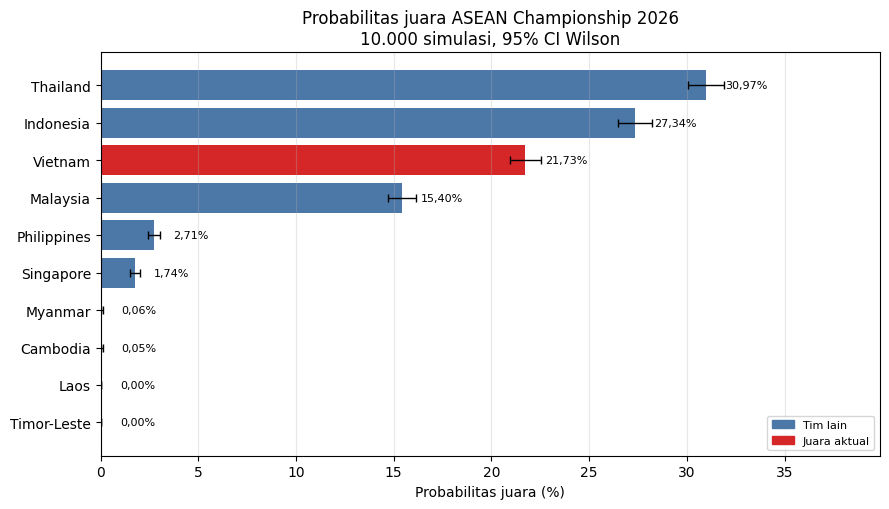

In [97]:
from matplotlib.patches import Patch

data19 = tabel26.sort_values("p_juara").reset_index(drop=True)
warna19 = [
    "#d62728" if tim == hasil9[2026]["actual_champion"] else "#4c78a8"
    for tim in data19["tim"]
]

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(data19["tim"], data19["p_juara"] * 100, color=warna19)
ax.errorbar(
    data19["p_juara"] * 100,
    data19["tim"],
    xerr=[
        (data19["p_juara"] - data19["ci_low"]) * 100,
        (data19["ci_high"] - data19["p_juara"]) * 100,
    ],
    fmt="none", ecolor="black", capsize=3, lw=1,
)
for i, row in data19.iterrows():
    ax.text(
        row["p_juara"] * 100 + 1.0, i,
        f"{fmt(row['p_juara'] * 100, 2)}%",
        va="center", fontsize=8,
    )
ax.set_xlabel("Probabilitas juara (%)")
ax.set_title("Probabilitas juara ASEAN Championship 2026\n10.000 simulasi, 95% CI Wilson")
ax.grid(axis="x", alpha=0.3)
ax.set_xlim(0, data19["ci_high"].max() * 100 + 8)
ax.legend(
    handles=[
        Patch(color="#4c78a8", label="Tim lain"),
        Patch(color="#d62728", label="Juara aktual"),
    ],
    loc="lower right", fontsize=8,
)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_19_probabilitas_juara_2026.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi 2026.** Model memberi peluang terbesar kepada **Thailand 30,97%**, lalu **Indonesia 27,34%**, **Vietnam 21,73%**, dan **Malaysia 15,40%**. Keempat tim itu menyerap sekitar **95,4%** massa probabilitas. Vietnam memang juara aktual 2026, tetapi simulasi menempatkannya di **peringkat ketiga** dengan interval Wilson **[20,93%; 22,55%]**. Jadi simulasi tidak “memprediksi” juara secara tepat; ia memberi skenario peluang yang masih cukup terbuka.

Lebar interval di tabel (sekitar 1–2 poin persentase) hanya mengukur galat Monte Carlo dari 10.000 undian. Ketidakpastian model, keterbatasan 52 laga ASEAN di final test, dan asumsi fitur statis jauh lebih besar daripada lebar interval itu.

### 9.4 Backtest lima edisi

Backtest membandingkan probabilitas simulasi dengan juara aktual tiap edisi. Yang dilaporkan adalah peluang yang diberikan model kepada juara aktual, peringkatnya, dan tim yang menjadi pilihan teratas simulasi. Ini bukan klaim kalibrasi sempurna; dengan lima edisi, satu kali salah tebak sudah mengubah rata-rata cukup besar.

In [98]:
baris_bt9 = []
for tahun, data in sorted(hasil9.items()):
    tabel = data["tabel"].copy().reset_index(drop=True)
    tabel["rank"] = np.arange(1, len(tabel) + 1)
    aktual = tabel.loc[tabel["tim"] == data["actual_champion"]].iloc[0]
    top = tabel.iloc[0]
    y_juara = (tabel["tim"] == data["actual_champion"]).astype(float)
    brier = float(((tabel["p_juara"] - y_juara) ** 2).sum())
    baris_bt9.append({
        "edisi": tahun,
        "juara_aktual": data["actual_champion"],
        "p_aktual": aktual["p_juara"],
        "rank_aktual": int(aktual["rank"]),
        "prediksi_top": top["tim"],
        "p_top": top["p_juara"],
        "top3": ", ".join(
            f"{r.tim} ({fmt(r.p_juara * 100, 1)}%)" for r in tabel.head(3).itertuples()
        ),
        "brier_juara": brier,
    })

tabel_bt9 = pd.DataFrame(baris_bt9)
tabel_bt9["p_aktual_pct"] = (tabel_bt9["p_aktual"] * 100).map(lambda v: fmt(v, 2) + "%")
tabel_bt9["p_top_pct"] = (tabel_bt9["p_top"] * 100).map(lambda v: fmt(v, 2) + "%")
print("Backtest probabilitas juara:")
print(
    tabel_bt9[[
        "edisi", "juara_aktual", "p_aktual_pct", "rank_aktual",
        "prediksi_top", "p_top_pct", "top3", "brier_juara",
    ]].to_string(index=False)
)

rata_p_aktual = float(tabel_bt9["p_aktual"].mean())
top_benar = int((tabel_bt9["rank_aktual"] == 1).sum())
top3_benar = int((tabel_bt9["rank_aktual"] <= 3).sum())
print(f"\nRata-rata peluang untuk juara aktual: {fmt(rata_p_aktual * 100, 2)}%")
print(f"Pilihan teratas tepat: {top_benar}/5 edisi; juara aktual di top-3: {top3_benar}/5 edisi")
assert len(tabel_bt9) == 5

Backtest probabilitas juara:
 edisi juara_aktual p_aktual_pct  rank_aktual prediksi_top p_top_pct                                                  top3  brier_juara
  2018      Vietnam       28,11%            2     Thailand    44,90% Thailand (44,9%), Vietnam (28,1%), Philippines (9,3%)     0.736176
  2021     Thailand       27,00%            2      Vietnam    33,95%  Vietnam (34,0%), Thailand (27,0%), Singapore (25,2%)     0.717969
  2022     Thailand       38,32%            1     Thailand    38,32%  Thailand (38,3%), Vietnam (32,5%), Indonesia (13,3%)     0.517780
  2024      Vietnam       10,94%            4     Thailand    38,33% Thailand (38,3%), Indonesia (27,5%), Malaysia (19,8%)     1.055508
  2026      Vietnam       21,73%            3     Thailand    30,97%  Thailand (31,0%), Indonesia (27,3%), Vietnam (21,7%)     0.808035

Rata-rata peluang untuk juara aktual: 25,22%
Pilihan teratas tepat: 1/5 edisi; juara aktual di top-3: 4/5 edisi


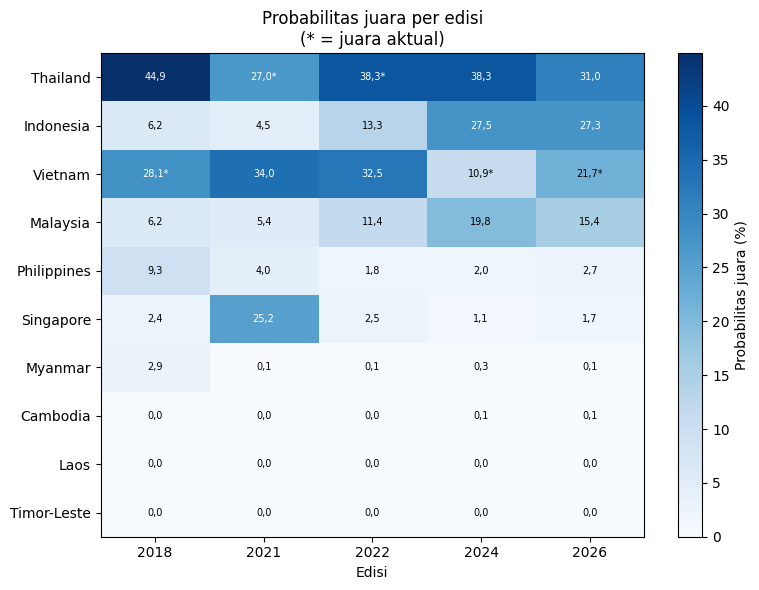

In [99]:
pivot9 = (
    pd.concat([
        data["tabel"].assign(edisi=tahun)[["edisi", "tim", "p_juara"]]
        for tahun, data in sorted(hasil9.items())
    ], ignore_index=True)
    .pivot(index="tim", columns="edisi", values="p_juara")
    .fillna(0.0)
    .reindex([t for t in tabel26["tim"]])
)

fig, ax = plt.subplots(figsize=(8, 6))
nilai9 = pivot9.to_numpy() * 100
im = ax.imshow(nilai9, aspect="auto", cmap="Blues", vmin=0, vmax=float(nilai9.max()))
for i, tim in enumerate(pivot9.index):
    for j, tahun in enumerate(pivot9.columns):
        nilai = float(nilai9[i, j])
        tanda = "*" if tim == hasil9[int(tahun)]["actual_champion"] else ""
        ax.text(
            j, i, f"{fmt(nilai, 1)}{tanda}",
            ha="center", va="center", fontsize=7,
            color="white" if nilai > float(nilai9.max()) * 0.55 else "black",
        )
ax.set_xticks(np.arange(len(pivot9.columns)))
ax.set_xticklabels([str(int(t)) for t in pivot9.columns])
ax.set_yticks(np.arange(len(pivot9.index)))
ax.set_yticklabels(pivot9.index)
ax.set_xlabel("Edisi")
ax.set_title("Probabilitas juara per edisi\n(* = juara aktual)")
fig.colorbar(im, ax=ax, label="Probabilitas juara (%)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig_20_probabilitas_juara_per_edisi.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretasi backtest.** Peluang yang diberikan kepada juara aktual adalah **28,11%** (2018, peringkat 2), **27,00%** (2021, peringkat 2), **38,32%** (2022, peringkat 1), **10,94%** (2024, peringkat 4), dan **21,73%** (2026, peringkat 3). Rata-ratanya **25,22%**, dibanding **10%** bila semua tim diberi peluang seragam. Pilihan teratas simulasi tepat pada **1 dari 5** edisi; juara aktual masuk tiga besar pada **4 dari 5** edisi.

Pola ini menunjukkan probabilitas simulasi **informatif tetapi tidak dominan**. Kegagalan terbesar ada di 2024: Vietnam hanya diberi **10,94%** dan berada di peringkat 4, meskipun akhirnya juara. Model pra-turnamen lebih menyukai Thailand, Indonesia, dan Malaysia. Sebaliknya, 2022 berhasil menempatkan Thailand di puncak. Dengan hanya lima edisi, satu hasil seperti 2024 cukup untuk membuat rata-rata dan klaim kalibrasi goyah.

### 9.5 Kesimpulan dan batasan

Simulasi Monte Carlo sudah berjalan untuk lima edisi dan menghasilkan distribusi juara yang konsisten secara aritmetika: peluang tiap edisi berjumlah 1, jumlah juara sama dengan jumlah simulasi, dan semua tim memperoleh peluang yang valid.

Temuan utama:

- Pada 2026, Thailand, Indonesia, Vietnam, dan Malaysia mendominasi peluang; Vietnam (juara aktual) hanya peringkat tiga.
- Backtest lima edisi memberi rata-rata **25,22%** kepada juara aktual, di atas uniform **10%**, tetapi pilihan teratas hanya tepat **1 dari 5** kali.
- Model lebih baik dalam memberi peluang kepada juara daripada dalam menunjuk juara tunggal.

Batasan yang harus dibaca bersama hasil:

- Fitur laga turnamen **statis** pada kondisi pra-turnamen; hasil simulasi tidak memperbarui Elo/form/head-to-head.
- Tidak ada model skor. Agregat dua leg didekati dengan jumlah kemenangan leg, bukan selisih gol; adu penalti memakai 50/50.
- Tiebreak grup memakai poin, head-to-head, lalu undian acak; selisih gol tidak tersedia.
- Kalibrasi model final pada final test hanya cukup, dan ECE classwise-nya lebih tinggi dari baseline (Section 8). Probabilitas juara mewarisi ketidakpastian itu.
- Hanya lima edisi dan 26 laga per edisi; hasil sangat sensitif terhadap satu edisi.
- Galat Monte Carlo 10.000 simulasi kecil, tetapi bukan ukuran ketidakpastian model atau kesalahan spesifikasi format.

In [100]:
semua_tabel9 = []
for tahun, data in sorted(hasil9.items()):
    tabel = data["tabel"].copy()
    tabel.insert(0, "edisi", tahun)
    semua_tabel9.append(tabel)
tabel_sim9 = pd.concat(semua_tabel9, ignore_index=True)
tabel_sim9.to_csv(PROJECT_ROOT / "data" / "processed" / "simulation_results.csv", index=False)

for tahun, data in hasil9.items():
    tabel = data["tabel"]
    assert data["n_sims"] == N_SIM9
    assert len(tabel) == 10
    assert tabel["juara"].sum() == N_SIM9
    assert np.isclose(tabel["p_juara"].sum(), 1.0)
    assert tabel["p_juara"].between(0, 1).all()
    assert len(data["group"]) == 20
    assert len(data["knockout"]) == 540

print(f"Tersimpan: data/processed/simulation_results.csv ({ribuan(len(tabel_sim9))} baris)")
print("Semua cek konsistensi simulasi lolos.")

Tersimpan: data/processed/simulation_results.csv (50 baris)
Semua cek konsistensi simulasi lolos.


**Kesimpulan Section 9.** Simulasi Monte Carlo memberi jawaban kuantitatif untuk pertanyaan “siapa berpeluang juara”, tetapi hasilnya harus dibaca sebagai **skenario bersyarat model**, bukan ramalan. Pada 2026, Vietnam adalah juara aktual namun hanya peringkat tiga simulasi; pada backtest lima edisi, model memberi peluang lebih tinggi daripada uniform kepada juara aktual, tetapi hanya sekali menempatkannya sebagai pilihan utama. Keterbatasan fitur statis, ketiadaan model skor, dan kalibrasi yang belum kuat harus dibawa ke kesimpulan akhir project.

## 10. Kesimpulan & Keterbatasan

### 10.1 Jawaban pertanyaan project

Project ini menguji dua hal: apakah model H/D/A dapat memberi probabilitas yang lebih baik daripada baseline, dan apakah probabilitas itu cukup berguna saat dipakai untuk mensimulasikan juara turnamen.

**Pertanyaan pertama: kualitas probabilitas H/D/A.** Pada 52 laga ASEAN di final test, model final (Logistic Regression `full_interaksi`, C=1,0) mencapai log loss **0,8198**, Brier **0,4704**, RPS **0,1655**, akurasi **67,31%**, dan macro-F1 **48,79%**. Model ini **jelas lebih baik daripada prior kelas** (log loss **1,0686**); selisih **-0,2488** dengan 95% CI **[-0,4315; -0,0667]** seluruhnya di bawah nol. Namun terhadap Elo murni (**0,8340**) dan logistic baseline (**0,8219**), keunggulannya hanya tipis dan tidak stabil: CI vs Elo **[-0,0431; +0,0178]** dan CI vs logistic baseline **[-0,0171; +0,0155]** sama-sama melewati nol. Pada 1.838 laga gabungan, polanya konsisten: final **0,8473**, logistic baseline **0,8481**, Elo **0,8510**, prior **1,0478**.

**Pertanyaan kedua: kegunaan simulasi.** Simulasi 10.000 kali memberi Thailand peluang juara 2026 sebesar **30,97%**, Indonesia **27,34%**, Vietnam **21,73%**, dan Malaysia **15,40%**. Keempat tim menyerap sekitar **95,4%** massa probabilitas. Vietnam adalah juara aktual 2026, tetapi hanya berada di peringkat tiga simulasi. Pada backtest lima edisi, peluang yang diberikan kepada juara aktual rata-rata **25,22%**, jauh di atas **10%** bila semua tim uniform; tetapi pilihan teratas hanya tepat **1 dari 5** edisi dan juara aktual masuk top-3 pada **4 dari 5** edisi. Kegagalan terbesar ada di 2024: Vietnam hanya diberi **10,94%** dan peringkat empat.

**Kesimpulan yang jujur:** model final layak dipakai sebagai **pemberi probabilitas dan penyusun skenario**, bukan sebagai **penunjuk juara tunggal**. Model mengalahkan prior dengan jelas, tetapi belum terbukti mengalahkan Elo atau logistic baseline. Kalibrasinya juga belum unggul: ECE top-label **0,0704** dan ECE classwise **0,0927**, lebih tinggi dari logistic baseline pada classwise. Kontribusi project ini adalah pipeline anti-leakage, evaluasi out-of-sample yang transparan, dan simulasi yang menghubungkan probabilitas laga ke format turnamen, bukan klaim model superior.

### 10.2 Keterbatasan

**Data dan label.**

- Label H/D/A berasal dari skor akhir, termasuk perpanjangan waktu bila ada, tetapi **tidak termasuk adu penalti**. Hasil 90 menit tidak tersedia, sehingga laga yang berakhir imbang lalu diselesaikan lewat penalti tetap berlabel `D`.
- Cakupan ASEAN kecil: hanya **52 laga** di final test dan **26 laga per edisi** simulasi. Perubahan satu hasil dapat menggeser metrik dan probabilitas juara cukup besar.
- Data internasional tidak seimbang antarwilayah, era, dan turnamen. Tim dengan sedikit laga historis memiliki fitur Elo/form yang lebih tidak stabil.
- `FIFA ASEAN Cup` dikeluarkan dari fitur, data latih, dan metrik. Ini keputusan lingkup yang konsisten, tetapi berarti model tidak belajar dari kompetisi tersebut.

**Model dan evaluasi.**

- Model final adalah logistic linear dengan interaksi terbatas. Hubungan non-linear yang lebih rumit, efek pemain, dan perubahan rezim taktik tidak tertangkap.
- Kelas seri sulit diprediksi; akurasi dan macro-F1 pada 52 laga tidak cukup untuk klaim kinerja umum.
- Kalibrasi classwise lebih lemah dari baseline. Tidak dilakukan recalibration karena akan membutuhkan data kalibrasi tambahan yang dipisahkan dari data uji.
- Bootstrap yang dipakai beroperasi pada level laga. Korelasi antar-laga dalam satu turnamen, ketergantungan jadwal, dan cluster tim tidak dimodelkan, sehingga interval kepercayaan dapat terlalu sempit.
- Final test hanya dibuka sekali, tetapi ukurannya kecil dan bukan uji prospektif sepenuhnya. Tidak ada validasi eksternal pada konfederasi atau turnamen lain.

**Simulasi.**

- Tidak ada model skor. Pemenang dua leg didekati dengan **jumlah kemenangan leg**, bukan agregat gol; bila satu leg dimenangkan masing-masing tim, adu penalti dimodelkan **50/50**.
- Tiebreak grup memakai poin, lalu head-to-head, lalu undian acak. **Selisih gol tidak tersedia** karena model tidak menghasilkan skor.
- Fitur laga turnamen **dibekukan pada kondisi pra-turnamen**: Elo, form, dan head-to-head tidak diperbarui selama simulasi. Momentum, kelelahan, cedera, rotasi, dan perubahan taktik di dalam turnamen tidak tertangkap.
- Hasil tiap laga diasumsikan independen setelah conditioning pada fitur. Korelasi antar-laga dan efek turnamen tidak dimodelkan.
- Interval Wilson 95% hanya mengukur **galat sampling Monte Carlo** dari 10.000 undian. Ia tidak mencakup ketidakpastian model, kesalahan spesifikasi format, atau pergeseran distribusi.
- Hanya lima edisi yang formatnya lengkap dan dapat direkonstruksi. Aturan tuan rumah/netral, jadwal, dan bracket disederhanakan mengikuti format yang tersedia di data.

**Klaim.** Semua angka adalah estimasi pada data historis, bukan jaminan untuk turnamen berikutnya. Output simulasi tidak boleh dibaca sebagai alat taruhan atau kepastian juara.

### 10.3 Rekomendasi dan pekerjaan lanjutan

1. **Kalibrasi probabilitas.** Lakukan recalibration (Platt/isotonic) dengan data validasi yang terpisah dari final test, lalu evaluasi ulang ECE top-label dan classwise. Fokuskan pada laga ASEAN dan kelas seri, karena di situ kalibrasi paling lemah.
2. **Propagasikan ketidakpastian model.** Ulangi simulasi dengan beberapa model/seed hasil bootstrap atau ensemble, bukan hanya satu model titik. Laporkan distribusi probabilitas juara, bukan satu angka saja.
3. **Perbaiki evaluasi ketidakpastian.** Gunakan cluster bootstrap per turnamen/tim dan, bila memungkinkan, validasi prospektif pada edisi berikutnya. Jangan memakai final test yang sama untuk memilih model dan mengklaim kinerja.
4. **Tambah fitur yang relevan.** Kualitas skuad, ketersediaan pemain, cedera, travel, jeda istirahat, venue, motivasi, dan konteks turnamen dapat menambah sinyal. Fitur harus tetap dihitung sebelum laga dan diperbarui secara walk-forward.
5. **Bangun model skor.** Model Poisson/Dixon-Coles atau model gol dapat menghasilkan distribusi skor, sehingga agregat dua leg, selisih gol, dan tiebreak grup dapat dimodelkan lebih realistis. Model penalti juga dapat memakai data shootout yang lebih luas, bukan asumsi 50/50.
6. **Perluas validasi.** Uji pada turnamen lain, konfederasi lain, dan periode yang benar-benar belum terlihat. Bandingkan dengan baseline yang lebih kuat dan gunakan metrik keputusan yang sesuai, bukan hanya akurasi juara.
7. **Sajikan sebagai skenario.** Untuk penggunaan praktis, tampilkan interval, beberapa skenario, dan asumsi format secara eksplisit. Hindari komunikasi yang menyiratkan prediksi tunggal yang pasti.

### 10.4 Reproducibility dan artefak

- Lingkungan: Python 3.10.11, `scikit-learn==1.7.2`, `scipy==1.15.3`, `pandas`, `numpy`, `matplotlib`, dan `jupyter`; daftar lengkap ada di `requirements.txt`.
- Konfigurasi Elo, logistic, dan evaluasi ada di `configs/config.yaml`. Split dan cutoff ada di `data/processed/split_definition.json`.
- Seluruh notebook dijalankan ulang dari awal dengan `jupyter nbconvert --execute`; seed simulasi **42**, jumlah simulasi **10.000 per edisi**, dan model final tidak diubah setelah final test dibuka.
- Uji otomatis: `python -m pytest -q` menghasilkan **45 passed**.
- Artefak utama: `data/processed/simulation_results.csv`, `reports/figures/fig_01` sampai `fig_20`, serta tabel dan output di notebook ini.
- Final test hanya dibuka satu kali di Section 8. Section 9 memakai model walk-forward yang dilatih ulang per edisi dan tidak memakai hasil edisi yang sedang disimulasikan.

Secara keseluruhan, project ini menunjukkan cara membangun dan mengevaluasi model probabilitas sepak bola secara jujur. Hasilnya cukup informatif untuk menyusun skenario, tetapi belum cukup untuk prediksi juara tunggal yang dapat diandalkan; keterbatasan data, kalibrasi, dan asumsi simulasi harus dibawa ke setiap penggunaan.